# SK Hynix four-leg book, re-hedged by rule: long `xyz:SKHY` / short `xyz:SKHX`, each hedged by its own stock

## S0 · Summary

**Research question.** Can the SKHY / SKHX funding book be made neutral to the basis by re-hedging its stock legs by rule, and does the funding then beat a T-bill? How much does each hedge leak? How much can we make?

| Trade set-up | |
|---|---|
| What is the trade | Short the Seoul perp `xyz:SKHX` against long Seoul shares `000660`, and long the New York perp `xyz:SKHY` against short Nasdaq ADS. Four legs of equal USD, to collect the net funding differential |
| Venue | Hyperliquid (xyz) for the two perps, Interactive Brokers for the two stocks |
| Type of risk | Basis, once per hedge: basis A (SKHX perp against 000660) and basis B (SKHY perp against the ADS). Together they are the spread between the two premia. The rule below hedges that spread: the book is neutral to a basis move of the length the hedge ratio is read on, and not beyond it |
| Rules | Each perp goes on the hour its own stock can fill, held through every funding print, all four legs exit at the end of the window. No early exit is simulated. Rule-based hedge: the stock legs are held at a ratio of the perp legs read on the trailing history, and both are re-struck to it whenever the held ratio drifts past a band. The perp legs are never touched. The static hold, the stock legs matched one for one, is the comparator in Test 4 and the book of the sibling study `2026-10-04-xasset-skhynix-four-leg-static-hold` |
| Base test | Does the re-hedged book's funding, net of the stock carry and the re-hedging, beat the T-bill at 1x? (S3) |
| Test 1 | Is it real: out of sample, statistically significant, after costs? (S4) |
| Test 2 | What if we exit on a rule: hold only while the trailing 7-day differential is above the bar, or above zero? (S4) |
| Test 3 | How much of the result is the entry hour? (S4) |
| Test 4 | What does the rule add over the static hold, which ratio would have been neutral at each horizon, and how sensitive is it to its own settings? (S4) |

**One result, not three.** `2026-09-22-equities-skhynix-perp-pair`, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` (this study) and `2026-10-04-xasset-skhynix-four-leg-static-hold` read the same pinned window and the same legs (`xyz:SKHX`, `xyz:SKHY`, `000660`, the SKHY ADS). They agree because they share the hours, the regime and the engine, not because the finding was replicated: together they are ONE result (`app/library/law/how-we-know.md#a-shared-window-is-one-result`), and a re-run on this window is a determinism check. S7 repeats this with the window's numbers.

## S1 · Setup

### S1.1 · Assumptions

| Assumption | Value | From |
|---|---|---|
| **Equity** | USD 1,000,000 across two accounts: the stock legs' cash and margin at IBKR, the rest as the perp pool's collateral at Hyperliquid | custom |
| Base book | 1x = four legs of USD 250,000 | custom |
| Reserve | 0 | custom |
| Entry | staggered: each perp goes on when its own stock fills (000660 at the KRX close, the ADS at the US close) | custom |
| Stock sizing | at entry matched units (one share or ADS per perp unit), then scaled by the hedge ratio held | custom |
| Perp slippage | 2 bp per fill; 10 bp on unwind; liquidation fee 7.5 bp | custom |
| Stock funding | both stock legs are paid for with cash held at IBKR, no margin loan: the long 000660 costs what that cash would have earned, the T-bill 4.11% a year; the short ADS pays a 3% borrow, no credit on its proceeds, on the marked value | custom [U] |
| Broker margin | 25% of the short ADS's notional, netted against the long 000660 inside the one IBKR account with a 5% currency buffer (above the worst 5-day USD/KRW move of the window); S6 also shows no netting and 50% | custom [U] |
| **Premium stop** | 10 premium points of room | custom |
| Drawdown limit | 15% of equity | custom |
| T-bill hurdle | 4.11% a year | custom choice (US Treasury [V]) |
| Test settings | split 2026-08-20 · 2,000 shuffles · 5-day blocks · entry sweep every hour · rolling carry window 14 days | custom |
| **Basis hedge (the rule)** | stock legs at a ratio of the perp legs read on the trailing 14 days of 24-hour moves of the fair-value marks, clipped to 0 to 1, both re-struck when the held ratio is 0.10 off, 5 bp stock slippage a trade; 1.00 until the history is long enough | custom [U] |
| Perp taker fee | 0.9 bp per fill (growth tier); 9 bp standard tier | Hyperliquid [V] |
| Maintenance margin, max leverage | 5% flat; 10x | Hyperliquid [V] |
| Funding | hourly, as published, on oracle notional | Hyperliquid [V] |
| Liquidation | equity below maintenance, on the mark | Hyperliquid [V] |
| KRX costs | 1.4 bp commission per side, 20 bp sell tax on the sale | KRX [V] |
| Won conversion | 5 bp per side | Interactive Brokers [V] |
| US stock costs | USD 0.005 a share, minimum USD 1, capped at 1% of the trade | Interactive Brokers [V] |
| Dividend | 000660 ex 2026-08-28, KRW 375; 22% withholding on the long leg | exchange [V] |
| ADS ratio | 10 SKHY = 1 Korean share | fact [V] |

### S1.2 · Data

| Source | Data | Period |
|---|---|---|
| Hyperliquid | funding (hourly, settled), 1h candles, published premium, for `xyz:SKHX` and `xyz:SKHY` | 2026-07-15 to 2026-10-03 |
| EODHD | daily bars for 000660, SKHY ADS and USD/KRW: every fill and every close mark | 2026-07-06 to 2026-10-02 |
| IBKR (Gateway, delayed) | HOURLY bars, extended hours, for 000660 (KRW), the SKHY ADS and USD/KRW: every cash-line chart and the fair-value mark; pulled once and cached; a shut exchange keeps its last price | from 2026-07-08 |
| Hyperliquid (live) | margin table, max leverage and the order book | NIL |

### S1.3 · Code

In [1]:
# ---- S1.1 parameters: every knob that is OURS (owner-set, study-set or [U]); never a venue number ----
RUN_ID = "research-005"                             # the ledger run of the EARLIER 1,801 h window (lab/research results-log.md): read only, to count its lines; this build's own cells go under TRIAL_RUN in S6
EQUITY, LEV, RESERVE = 1_000_000.0, 1.0, 0.0       # owner 2026-09-22: USD 1M of equity, the base book 1x, no reserve
COIN_A, COIN_B, VENUE, DAYS = "xyz:SKHX", "xyz:SKHY", "Hyperliquid", 120
START_DATE, START_HOUR, SPLIT_DATE = "2026-07-15", 7, "2026-08-20"
ENTRY_MODE, ADS_FILL = "staggered", "close"          # owner 2026-09-27: STAGGERED is the registered entry (each perp with its own hedge)
STOCK_SIZING, SIZING_BESIDE = "units", "usd"         # research-005: each stock leg at its perp's own units (B-0246); USD sizing run beside it
CASH_HOURLY = {"A": ("000660.KS", "krx"), "B": ("SKHY", "us")}   # the in-session hourly prints the fair-value mark reads (B-0244)
LEVS, RESV = (1, 2, 3), (0.0,)                    # the rungs the capital can fund, no reserve: S6 shows the larger rungs as not fitting
RUNGS_ALL = (1, 2, 3, 4, 6, 10, 20)               # the margin table's rungs (20x = a perp collateral split of 10x, the venue's cap)
STOP_PTS, DD_LIMIT_PCT = 10.0, 15.0                  # [U] pre-registered desk stop (premium points of room) and drawdown limit
MIN_HOLD_SHARE = 0.25                                # a rule that almost never trades is not a rule
NSHUF, SEED = 2000, 7
BOOT_BLOCK_D = 5                                     # [U] stationary-bootstrap mean block length, days
MC_PATHS, MC_HOLD_D = 2000, 30                       # [U] premium paths simulated, and the hold they cover, days
SWEEP_STEP_H, SWEEP_MIN_D, EXIT_STEP_H = 1, 14, 3    # entry sweep every hour, each kept >= 14 d; exit sweep every 3 h
VOL_WIN_H, VOL_WIN_D = 168, 10                       # realized-vol windows: 7 d of hourly perp closes, 10 daily cash closes
OUTLIER_PCT = 5.0                                    # an hour whose perp close moves more than this is listed
FIN_PAIRS = ((0.02, 0.02), (0.02, 0.03), (0.03, 0.03), (0.02, 0.05), (0.03, 0.05), (0.05, 0.05))   # [U] (borrow, margin) pairs
BORROW_BASE, BORROW_REBATE = 0.03, 0.0               # [U] F9: the short stock leg's borrow fee and the rebate on its proceeds (B-0248)
BORROW_SWEEP = (0.005, 0.01, 0.03, 0.05, 0.10, 0.20, 0.30)   # [U] F9: the fees the borrow sweep prices
XFER_RUNGS, XFER_DELAYS_H = (6, 10, 20), (24, 48, 72)  # [U] F10: rungs and KRW -> USDC transfer delays stressed
STOCK_FUNDING = "cash"      # custom: the stock legs are paid for with cash held at IBKR, not a margin loan
IB_MARGIN = 0.25            # custom [U]: IBKR margin on the short ADS leg, as a fraction of its notional
NETTING = True              # custom [U]: the long and the short stock leg net inside the one IBKR account; S6 also shows no netting
FX_BUF = 0.05               # custom [U]: the currency buffer on the netted legs, above the worst 5-day USD/KRW move of this window (asserted below)
KRW_LOAN = 0.07705          # custom [1]: IBKR's KRW margin loan, BM + 3.5% on 2026-09-27 (fact card margin.loan.krw): the long leg's cost if it were financed instead of paid in cash
END_UTC, WINDOW_HOURS = "2026-10-03 09:00", 1923       # custom: window end and its hours, pinned so the study reads the same hours as 2026-09-22-equities-skhynix-perp-pair
SYS_W_D, SYS_H_H, SYS_BAND, SYS_CLIP = 14, 24, 0.10, (0.0, 1.0)   # [U] Test 4, registered before the run: trailing days, hours of a move, rebalance band (stock legs per perp legs), ratio clip
SYS_SLIP_BPS = 5.0                                     # [U] Test 4: slippage on each stock trade of a rebalance, bp
SYS_HORIZONS = (1, 4, 12, 24, 48, 72, 120, 168)       # Test 4: the hours of a move the swing is read at
ROLL_D = 14                                           # [U] the rolling window of the carry chart (Test 1a, beside the split), days

In [2]:
import datetime as dt, json, textwrap, time
from dataclasses import replace
import matplotlib.pyplot as plt, matplotlib.dates as mdates, matplotlib.colors as mcolors
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap, to_hex
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, summary_card
from fundplat.quant.core import refdata
from fundplat.quant.crypto.backtest import hip3_pair as HP
from fundplat.quant.crypto.backtest.carry import hip3_four as F
from fundplat.quant.core import stats as ST
import fundplat.data as DATA
from fundplat.data.tradfi import intraday as INTRA
from fundplat.quant.core import report as REPORT

# ---- S1.2 + S1.3: the configuration the parameters imply, the assumptions held to the code (PROSE), the data ----
MMR = 0.05                                    # the venue's maintenance margin, asserted against refdata below
HOUR = 3_600_000
START = int((dt.datetime.fromisoformat(START_DATE).replace(tzinfo=dt.timezone.utc) + dt.timedelta(hours=START_HOUR)).timestamp() * 1000)
SPLIT = int(dt.datetime.fromisoformat(SPLIT_DATE).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
FEE_SWEEP = ((refdata.XYZ_TAKER_BPS, 2.0), (refdata.XYZ_TAKER_BPS, 5.0), (refdata.XYZ_TAKER_BPS, 10.0),
             (refdata.XYZ_STANDARD_TAKER_BPS, 2.0), (refdata.XYZ_STANDARD_TAKER_BPS, 10.0))
# [U] stock financing per year, each leg at its OWN rate since B-0248: the short leg pays the borrow b
# (`short_borrow_ann`), the long leg its margin loan m (`stock_fin_ann`). The cost sweep runs every
# (b, m) pair in FIN_PAIRS through the engine.
BOOK, CTRL = "the book", "the control"
DIRS = (BOOK,)
# the engine EXPORTS which direction is which; this notebook passes the key EXPLICITLY in every run
# rather than relying on `FourParams.direction`'s default, and labels its columns off `res["role"]`.
DKEY = {BOOK: F.BOOK_DIRECTION, CTRL: F.CONTROL_DIRECTION}
ROLE = {BOOK: "book", CTRL: "control"}
assert (F.BOOK_DIRECTION, F.CONTROL_DIRECTION) == ("short_a", "long_a")
OTHER = {BOOK: CTRL, CTRL: BOOK}
SIDE = {BOOK: -1.0, CTRL: 1.0}               # the SKHX perp's side: -1 = SHORT it, so LONG the premium
NSIGN = {BOOK: 1.0, CTRL: -1.0}              # sign of the net funding differential against the BOOK's own reading
CARRY = "funding net of all stock carry"     # ONE name for the metric every gate in steps 1 to 3 is read on


def ib_cash(N, netting=None, frac=None):
    """Cash the IBKR account holds for the two stock legs, USD: the long leg is PAID in cash (N); the short leg adds its broker margin, on its whole notional
    when the legs do not net, or on the currency buffer alone when they do (two equal-notional legs net to zero, the won leg keeps its currency risk)."""
    netting = NETTING if netting is None else netting
    frac = IB_MARGIN if frac is None else frac
    return N + frac * (FX_BUF * N if netting else N)


def fp(L=LEV, R=RESERVE, d=BOOK, netting=None, frac=None, **kw):
    """One rung, one direction. gross of the FOUR legs = equity x L; the stock legs and their margin sit at IBKR in cash, the rest of the
    equity is the perp pool's collateral at Hyperliquid (the pool's leverage setting is its gross over that collateral)."""
    assert R == 0.0
    N = L * EQUITY / 4.0
    pool = EQUITY - ib_cash(N, netting, frac)
    assert pool > 0, f"{L}x does not fit USD {EQUITY:,.0f}: the IBKR account alone needs USD {ib_cash(N, netting, frac):,.0f}"
    netting = NETTING if netting is None else netting
    frac = IB_MARGIN if frac is None else frac
    kw.setdefault("entry_mode", ENTRY_MODE); kw.setdefault("ads_fill", ADS_FILL)
    kw.setdefault("stock_sizing", STOCK_SIZING)
    kw.setdefault("stock_fin_ann", refdata.HURDLE_ANN if STOCK_FUNDING == "cash" else KRW_LOAN)       # cash that buys the stock would have earned the T-bill
    kw.setdefault("short_borrow_ann", BORROW_BASE); kw.setdefault("short_rebate_ann", BORROW_REBATE)
    return F.FourParams(notional_usd=N, direction=DKEY[d], leverage=2.0 * N / pool, reserve_mult=0.0,
                        margin_mode="cross", equity_usd=EQUITY, stock_margin_frac=frac * (FX_BUF if netting else 1.0), **kw)


PAR = {lab: fp(d=lab) for lab in DIRS}
p1 = PAR[BOOK]
assert p1.equity_usd == EQUITY and p1.notional_usd == EQUITY / 4 and abs(p1.leverage * (EQUITY - ib_cash(p1.notional_usd)) - 2 * p1.notional_usd) < 1e-6
assert p1.reserve_mult == RESERVE == 0.0 and p1.margin_mode == "cross" and abs(p1.stock_margin_frac - IB_MARGIN * FX_BUF) < 1e-12
assert p1.direction == F.BOOK_DIRECTION and not p1.regime
assert p1.stock_fin_ann == refdata.HURDLE_ANN and p1.stock_capital_frac == 1.0
assert (p1.stock_sizing, p1.short_borrow_ann, p1.short_rebate_ann) == (STOCK_SIZING, BORROW_BASE, BORROW_REBATE)
assert (p1.stock_fill, p1.fin_basis, p1.dividend_mode) == ("after_decision", "marked", "exdate")   # B-0247, the engine defaults
assert F.UNITS_PER_PERP == {"A": 1.0, "B": 1.0}
assert p1.krx_close_utc_h == 6.5                    # 15:30 KST, no DST in Korea, a fixed UTC hour all year
US_PER_DATE = p1.us_close_utc_h is None            # None = the engine derives 16:00 America/New_York per date
assert US_PER_DATE or p1.us_close_utc_h == 20.0
assert (p1.krx_commission_bps, p1.krx_sell_tax_bps, p1.fx_spread_bps) == (
    refdata.KRX_COMMISSION_BPS, refdata.KRX_SELL_TAX_BPS, refdata.FX_SPREAD_BPS)
assert (p1.us_per_share, p1.us_min_usd, p1.us_max_pct) == (
    refdata.IBKR_US_FIXED_USD_PER_SHARE, refdata.IBKR_US_FIXED_MIN_USD, refdata.IBKR_US_FIXED_MAX_PCT)
assert p1.dividend_yield_ann == F.H.SKHX_DIVIDEND_YIELD_ANN == 0.00155
assert p1.dividend_withholding == F.H.DIVIDEND_WITHHOLDING == 0.22
assert p1.hold_days_for_amortisation == 30.0        # the engine's ANALYTIC carry amortises one round trip over this
assert p1.hurdle_ann == refdata.HURDLE_ANN
_pp = HP.pair_params_simple(1_000_000.0, p1.leverage, p1.reserve_mult, "cross", "equal_usd", DKEY[BOOK],
                            gross_usd=2.0 * p1.notional_usd)
assert _pp.fee_taker_bps == refdata.XYZ_TAKER_BPS == 0.9 and _pp.exec_slippage_bps == 2.0 and not _pp.maker
assert _pp.wick_mode == "joint_adverse" and _pp.liq_fee_bps == 7.5

# ---- the venue's own margin spec: max leverage is the SETTING cap, not the desk's split ----
SPEC_A, SPEC_B = refdata.spec_for(VENUE, COIN_A, EQUITY), refdata.spec_for(VENUE, COIN_B, EQUITY)
assert SPEC_A[0] == SPEC_B[0] == MMR
MAXLEV = int(min(SPEC_A[1], SPEC_B[1]))
ENTRY_BPS = _pp.fee_taker_bps + _pp.exec_slippage_bps

# ---- the numbers the two opening tables STATE, held to the code. A table that parts from the run goes red
# ---- here. It cannot catch a table edited on its own: the right-hand values are the tables' own words.
PROSE = {"equity USD 1,000,000": (EQUITY, 1_000_000.0), "1x = four legs of USD 250,000": (p1.notional_usd, 250_000.0),
         "reserve 0": (p1.reserve_mult, 0.0), "taker 0.9 bp, growth tier": (refdata.XYZ_TAKER_BPS, 0.9),
         "standard tier 9 bp": (refdata.XYZ_STANDARD_TAKER_BPS, 9.0), "slippage 2 bp": (_pp.exec_slippage_bps, 2.0),
         "round trip 11.6 bp": (round(4 * ENTRY_BPS, 1), 11.6), "unwind 10 bp": (_pp.unwind_slippage_bps, 10.0),
         "liquidation fee 7.5 bp": (_pp.liq_fee_bps, 7.5), "KRX commission 1.4 bp": (refdata.KRX_COMMISSION_BPS, 1.4),
         "KRX sell tax 20 bp": (refdata.KRX_SELL_TAX_BPS, 20.0), "FX 5 bp per side": (refdata.FX_SPREAD_BPS, 5.0),
         "IBKR USD 0.005 / share, min USD 1, cap 1%": ((refdata.IBKR_US_FIXED_USD_PER_SHARE, refdata.IBKR_US_FIXED_MIN_USD,
                                                      refdata.IBKR_US_FIXED_MAX_PCT), (0.005, 1.0, 1.0)),
         "the long leg costs the T-bill 4.11%": (p1.stock_fin_ann, 0.0411), "broker margin 25% netted with a 5% currency buffer": (round(p1.stock_margin_frac, 6), 0.0125), "stock legs paid in cash": (STOCK_FUNDING, "cash"),
         "borrow 3% less a rebate of 0%": ((p1.short_borrow_ann, p1.short_rebate_ann), (0.03, 0.0)),
         "financing on the MARKED value": (p1.fin_basis, "marked"),
         "ex-date 2026-08-28 at KRW 375": (tuple(tuple(e_) for e_ in p1.dividend_events_krw), (("2026-08-28", 375.0),)),
         "dividend lands at the ex-date": (p1.dividend_mode, "exdate"), "withholding 22%": (p1.dividend_withholding, 0.22),
         "a stock order fills AFTER its decision": (p1.stock_fill, "after_decision"),
         "matched units, one share / one ADS per perp unit": ((p1.stock_sizing, F.UNITS_PER_PERP["A"], F.UNITS_PER_PERP["B"]), ("units", 1.0, 1.0)),
         "maintain trigger 10%": (_pp.maintain_trigger_pct, 10.0), "maintenance 5%": (MMR, 0.05), "max leverage 10x": (MAXLEV, 10),
         "hurdle 4.11%": (refdata.HURDLE_ANN, 0.0411), "stop 10 pts": (STOP_PTS, 10.0), "drawdown limit 15%": (DD_LIMIT_PCT, 15.0),
         "split 2026-08-20": (SPLIT, int(dt.datetime(2026, 8, 20, tzinfo=dt.timezone.utc).timestamp() * 1000)),
         "2,000 sign shuffles": (NSHUF, 2000),
         "fee/slip 0.9/2 0.9/5 0.9/10 9.0/2 9.0/10": (FEE_SWEEP, ((0.9, 2.0), (0.9, 5.0), (0.9, 10.0), (9.0, 2.0), (9.0, 10.0))),
         "(borrow, margin) pairs 2/2, 2/3, 3/3, 2/5, 3/5, 5/5%": (tuple((round(b_ * 100, 2), round(m_ * 100, 2)) for b_, m_ in FIN_PAIRS),
                                                                  ((2.0, 2.0), (2.0, 3.0), (3.0, 3.0), (2.0, 5.0), (3.0, 5.0), (5.0, 5.0))),
         "leverage 1 2 3 in the runs, 1 2 3 4 6 10 20 in the margin table": ((LEVS, RUNGS_ALL), ((1, 2, 3), (1, 2, 3, 4, 6, 10, 20))), "no reserve": (RESV, (0.0,)),
         "168 h warm-up": (p1.regime_warmup_h, 168), "24 h minimum hold": (p1.min_hold_h, 24),
         "block bootstrap, mean block 5 d": (BOOT_BLOCK_D, 5), "2,000 premium paths over 30 d": ((MC_PATHS, MC_HOLD_D), (2000, 30)),
         "entry sweep every hour, at least 14 d; exit sweep every 3 h": ((SWEEP_STEP_H, SWEEP_MIN_D, EXIT_STEP_H), (1, 14, 3)),
         "entry staggered, ADS at the close": ((p1.entry_mode, p1.ads_fill), ("staggered", "close")),
         "borrow base 3%, rebate 0, swept 0.5-30%": ((BORROW_BASE, BORROW_REBATE, BORROW_SWEEP[0], BORROW_SWEEP[-1]), (0.03, 0.0, 0.005, 0.30)),
         "transfer delays 24 / 48 / 72 h at 6x / 10x / 20x": ((XFER_DELAYS_H, XFER_RUNGS), ((24, 48, 72), (6, 10, 20))),
         "outlier hours above 5%": (OUTLIER_PCT, 5.0),
         "basis hedge rule: 14 days, 24-hour moves, band 0.10, clip 0 to 1, 5 bp": ((SYS_W_D, SYS_H_H, SYS_BAND, SYS_CLIP, SYS_SLIP_BPS), (14, 24, 0.10, (0.0, 1.0), 5.0)),
         "rolling carry window 14 days": (ROLL_D, 14),
         "vol windows 168 h and 10 closes": ((VOL_WIN_H, VOL_WIN_D), (168, 10))}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the opening tables no longer describe this run: {BAD}"

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3, S4, S5, S7 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GOOD, CRIT = "#0ca30c", "#d03b3b"
C_A, C_B, C_NET, C_BAS, C_FX, C_COST = S4, S1, S7, S5, "#8a6bbf", MUTED   # FX is signed both ways: never green
C_DIR = {BOOK: INK, CTRL: S2}                # DIRECTION by hue
C_HL, C_IB = "#22185f", "#c07a00"            # ACCOUNT by hue: Hyperliquid pool, IBKR broker
RAMP = LinearSegmentedColormap.from_list("lev", ["#8d82d6", "#5a49bd", "#1b1350"])
C_LEV = {L: to_hex(RAMP(i / (len(LEVS) - 1))) for i, L in enumerate(LEVS)}
LEG = dict(frameon=True, facecolor=SURF, edgecolor="none", framealpha=0.9)
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "font.size": 9.5, "axes.axisbelow": True, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED,
                     "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
ANN, A_PCT = 8760 * 100, 100.0 / EQUITY
num = lambda s: pd.to_numeric(s, errors="coerce")
fmt = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

# ---- ONE money format: full digits in tables, USD 1.5M style in chart text ----
usd = lambda v: f"USD {v:,.0f}"
kusd = lambda v: f"{v:,.0f}"


def usdm(v):
    unit, d = ("B", v / 1e9) if abs(v) >= 1e9 else ("M", v / 1e6)
    s = f"{d:,.2f}"
    return "USD " + (s.rstrip("0").rstrip(".") if "." in s else s) + unit


def cell_ink(cmap, v, vmin, vmax):
    """White or black text, decided by the LUMINANCE of the cell colour it sits on."""
    t = 0.5 if vmax == vmin else (v - vmin) / (vmax - vmin)
    return _ink_at(cmap, t)


def cell_ink_n(cmap, v, nrm):
    """The same, for a colour map driven by a Normalize (a diverging split off zero)."""
    return _ink_at(cmap, float(nrm(v)))


def _ink_at(cmap, t):
    r_, g_, b_, _ = plt.get_cmap(cmap)(min(max(float(t), 0.0), 1.0))
    return "#ffffff" if (0.299 * r_ + 0.587 * g_ + 0.114 * b_) < 0.5 else INK


def mdt(d, name="", note=""):
    """Every results table renders as Markdown: pandas wraps a wide frame into blocks,
    Markdown does not, and a row label is never truncated."""
    D = d.reset_index()
    cols = [" ".join(str(x) for x in c) if isinstance(c, tuple) else str(c) for c in D.columns]
    if name:
        cols[0] = name
    cell = lambda v_: ("" if v_ is None or (isinstance(v_, float) and v_ != v_) else str(v_).replace("|", "/"))
    body = [chr(124) + " " + " | ".join(cell(v_) for v_ in r_) + " |" for r_ in D.astype(object).values]
    display(Markdown(chr(10).join([chr(124) + " " + " | ".join(cols) + " |", chr(124) + "---|" * len(cols)]
                                  + body + ([""] + [note] if note else []))))


# ---- room in premium points: the ENGINE's exact conversion, never a notebook formula ----
# `hip3_pair.premium_room_pts` is the pure helper `run_four` itself calls for
# `room_premium_pts_exact`. Both perp legs adverse by the same fraction x move a premium P by
# (1 + P) 2x/(1 + x) for THE BOOK - short SKHX / long SKHY, so the adverse co-move NARROWS
# the premium and this book is LONG it, its liquidation level sitting BELOW the premium
# standing - and by (1 + P) 2x/(1 - x) for THE CONTROL, which is SHORT the premium and is
# liquidated above it. A room whose liquidating level would need a premium below -100%
# (a negative price) or above +200% is UNREACHABLE: no co-move inside a possible premium
# liquidates that rung.
PREM_LO, PREM_HI = -100.0, 200.0


def room_and_level(lab, dist_pct, P_pct):
    """(room in premium points, the premium level that liquidates) or (None, None)."""
    r_ = None if dist_pct is None else HP.premium_room_pts(DKEY[lab], float(dist_pct), float(P_pct))
    if r_ is None or not np.isfinite(r_):
        return None, None
    lvl = P_pct + r_ if SIDE[lab] > 0 else P_pct - r_       # LONG the premium -> the level is BELOW it
    return (None, None) if (lvl <= PREM_LO or lvl > PREM_HI) else (r_, lvl)


# The pool's posted collateral and its gross BOTH scale by 1/(1 + R), so the distance is the
# rung's alone: the off-venue reserve is not account equity and is never credited as posted.
# Verified against the engine: dist_book_pct at the first held hour is the same at every reserve.
x_liq = lambda L, R=0.0, netting=None, frac=None: (2.0 * (EQUITY - ib_cash(L * EQUITY / 4.0, netting, frac)) / (L * EQUITY) - MMR) * 100.0      # % the perp pool can lose at rung L: its collateral over its gross
fpt = lambda v: "unreachable" if v is None else f"{v:,.1f}"
flvl = lambda v: "unreachable" if v is None else f"{v:+.1f}"


def _wrap(sub, w):
    return chr(10).join(textwrap.wrap(sub, w)) if len(sub) > w else sub


def ask(ax, q, sub, w=150):
    t_ = _wrap(sub, w)
    ax.set_title(q, pad=13 + 12 * (t_.count(chr(10)) + 1))
    ax.text(0.0, 1.012, t_, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def fig_ask(fig, q, sub, top, w=165):
    fig.suptitle(q, x=0.06, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
    fig.text(0.06, top + (0.985 - top) * 0.42, _wrap(sub, w), color=MUTED, fontsize=8.5, ha="left", va="center")


def frame(r_):
    d = pd.DataFrame(r_["series"])
    d["ts"] = pd.to_datetime(d["time"], unit="ms", utc=True)
    return d.set_index("ts")


def asof(marks, t):
    """The last published close at or before `t`, from the engine's own mark list. No lookahead."""
    v = None
    for s_, px in marks:
        if s_ <= t:
            v = px
        else:
            break
    return v


def daily(d_):
    """Daily deltas of the non-overlapping decomposition. FX is a SUB-component of the
    net basis and is carried alongside, never added twice."""
    cum = pd.DataFrame({"funding": num(d_["cum_funding_net"]), "hedged": num(d_["cum_hedged_basis"]),
                        "unhedged": num(d_["cum_unhedged"]), "fx": num(d_["cum_fx"]),
                        "financing": -num(d_["cum_financing"]), "dividends": num(d_["cum_dividends"]),
                        "costs": -(num(d_["cum_stock_costs"]) + num(d_["cum_perp_fees"])),
                        "total": num(d_["total_pnl"]), "premium_pct": num(d_["implied_premium_pct"]),
                        "net_basis_pct": num(d_["net_basis_pct"])})
    eod = cum.resample("1D").last().ffill()
    day = eod.diff()
    first = {k: 0.0 for k in cum.columns}
    first["premium_pct"], first["net_basis_pct"] = cum["premium_pct"].iloc[0], cum["net_basis_pct"].iloc[0]
    day.iloc[0] = eod.iloc[0] - pd.Series(first)
    day["basis"] = day["hedged"] + day["unhedged"]
    day["premium_level"] = eod["premium_pct"]
    day["net_basis_level"] = eod["net_basis_pct"]
    day["funding_net_carry"] = day["funding"] + day["financing"] + day["costs"] + day["dividends"]
    return day


# ---- carry = funding NET OF ALL stock carry and fees: the metric every gate is read on ----
carry_usd = lambda r_: r_["funding_net"] - r_["financing"] - r_["stock_costs"] - r_["perp_fees"] - r_["perp_liq_fees"] + r_["dividends"]
carry_ann = lambda r_: carry_usd(r_) / EQUITY * 100.0 / r_["days"] * 365.0
eq_ann = lambda r_: r_["total_pnl_fv"] / EQUITY * 100.0 / r_["days"] * 365.0       # the book's return: the FAIR-VALUE mark, the clock-consistent one (the engine's own ann_pct_equity is close-marked)
eq_ann_close = lambda r_: r_["ann_pct_equity"]                                    # the close-marked return: two clocks, named as such wherever it is quoted


# ---- verification: EVERY check the engine returns, on EVERY book, or the notebook stops ----
ENGINE_OPEN = set()          # no check is exempt; a failure is an error, never a footnote


def vfour(r_, rw, tag):
    c_ = F.verify_four(r_, rw)
    f_ = {k: v[1] for k, v in c_.items() if not v[0]}
    assert not (set(f_) - ENGINE_OPEN), (tag, f_)
    return c_


# The pool's distance to liquidation AT the hour's adverse wick, the hour it was measured on,
# its exact conversion into premium points and the same slack in DOLLARS are all engine output
# (`hip3_four` 2026-09-22). `dist_book_pct` is the same distance on the CLOSES and is always the
# roomier of the two; the whole-book `margin_headroom` is a different quantity again.
wick_series = lambda r_: r_["series"]["dist_wick_pct"]
min_wick = lambda r_: r_["min_dist_wick_pct"]
wick_time = lambda r_: r_["min_dist_wick_time"]
wick_k = lambda r_: r_["series"]["time"].index(r_["min_dist_wick_time"])


def wick_room(r_, lab):
    """The ENGINE's own exact room at the binding wick, and the premium level that liquidates."""
    at_ = r_["room_premium_pts_exact_at"] or {}
    rm, P_ = r_["room_premium_pts_exact"], at_.get("implied_premium_pct")
    if rm is None or P_ is None:
        return None, None, P_
    lvl = P_ + rm if SIDE[lab] > 0 else P_ - rm
    return (None, None, P_) if (lvl <= PREM_LO or lvl > PREM_HI) else (rm, lvl, P_)


rows, krx, ads, fx = F.load_four(start=START_DATE, start_hour_utc=START_HOUR)
# the in-session hourly cash prints (B-0244, store-first through fundplat.data): the fair-value mark re-strikes each leg's
# basis at every one of them; they never fill a leg. From a week before the entry, as load_four's daily bars.
H_FROM = (dt.date.fromisoformat(START_DATE) - dt.timedelta(days=7)).isoformat()
# the cash prices are IBKR's HOURLY bars (extended hours), pulled once from the Gateway and cached: handle.pull tops the store up, then reads it
import asyncio, concurrent.futures
from fundplat.data import handle as HND


def _gateway(fn):
    """The Gateway client runs its own event loop; a notebook kernel already has one, so the read runs in a worker thread with a fresh loop."""
    def run():
        asyncio.set_event_loop(asyncio.new_event_loop())
        return fn()
    with concurrent.futures.ThreadPoolExecutor(1) as ex:
        return ex.submit(run).result()


IB_SERIES = {"A": (17382246, "TRADES"), "B": (899700992, "TRADES"), "FX": (36363302, "MIDPOINT")}   # 000660 (KRX, KRW), SKHY (Nasdaq ADS, USD), USD/KRW (IDEALPRO mid)


def _ib_rows(conid, what):
    h_ = HND.pull("contract_bars", "ibkr", symbol=str(conid), interval="1h", start=H_FROM, end=END_UTC, what=what)
    return HND.rows(h_.id)


IBH = _gateway(lambda: {k_: _ib_rows(c_, w_) for k_, (c_, w_) in IB_SERIES.items()})
# an hourly bar is stamped at its START and its close is known at its END; a shut exchange prints nothing, so asof() keeps its last price constant
hmarks = lambda rows_: sorted((int(b_["t"]) + HOUR, float(b_["c"])) for b_ in rows_ if b_.get("c") is not None and b_["c"] > 0 and b_.get("closed") is not False)
MKH, MAH, MFH = hmarks(IBH["A"]), hmarks(IBH["B"]), hmarks(IBH["FX"])
CH = {"A": MKH, "B": MAH}                      # the fair-value mark re-strikes each leg on every one of these prints
assert all(len(v_) > 500 for v_ in (MKH, MAH, MFH)), {k_: len(v_) for k_, v_ in IBH.items()}
# the currency buffer sits above the worst 5-day USD/KRW move of this window (IBKR hourly mids); a netted pair is only as safe as its currency leg
_fxs = pd.Series({pd.Timestamp(t_, unit="ms", tz="UTC"): px_ for t_, px_ in MFH})
FX_MOVE5 = float(_fxs.rolling("5D").apply(lambda x: abs(x.iloc[-1] / x.iloc[0] - 1)).max())
assert FX_BUF >= FX_MOVE5, (FX_BUF, FX_MOVE5)


def run4(rw, p):
    """THE engine call of this notebook: `hip3_four.run_four` on the daily cash bars, with the in-session hourly prints."""
    return F.run_four(rw, krx, ads, fx, p, cash_hourly=CH)


assert rows[0]["time"] == START, fmt(rows[0]["time"])
assert {float(r.get("interval_h", 1.0)) for r in rows} == {1.0}    # the cadence is READ, never assumed
P_ENTRY = rows[0]["B_perp"] * 10 / rows[0]["A_perp"] * 100 - 100

globals().update(figstyle.NAMES)                      # ONE palette (figstyle); the notebook's own colour names above are overwritten by it
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")   # the picture is the figure, not a tight crop of it
END_MS = int(dt.datetime.fromisoformat(END_UTC).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
rows = [r for r in rows if r["time"] <= END_MS]           # the pair study's window end, so the studies read the same hours
FIGURES = []                  # every cell that draws lists itself here through figstyle.show; the manifest reads it

In [3]:
# ---- THE STRATEGY: the four-leg book with the basis hedged by rule ----
# Registered before any run [U]: the stock legs are held at a ratio rho of the perp legs' units (1.00 = matched, the static book). Each hour the target ratio is the one the trailing
# SYS_W_D days of SYS_H_H-hour moves pick (minus the slope of the perp price P&L on the stock legs' fair-value P&L, clipped to SYS_CLIP); when the held ratio is more than SYS_BAND away
# BOTH stock legs are re-struck to it, at the published commission, sell tax and won conversion plus SYS_SLIP_BPS of slippage [U]. The perp legs, their funding and their fees are never touched.
# The rule is `fundplat.quant.crypto.backtest.carry.hip3_four_hedge` (B-0476): `rehedge` scales every stock-side increment of the engine's result (fair-value mark with FX, dividends,
# financing, entry and exit costs) by the ratio held over that hour, `hedge_target` is the trailing slope, `verify_rehedge` re-derives the result. The registered values go to every call.
# Every number below the base test is this strategy's; the static book is kept as STATIC for comparison. Until the history is long enough the ratio stays at 1.00.
from fundplat.quant.crypto.backtest.carry import hip3_four_hedge as HDG
from fundplat.quant.crypto.backtest.util import all_pass, check_status
SYS_W_H = SYS_W_D * 24
HK = dict(band=SYS_BAND, slip_bps=SYS_SLIP_BPS, window_h=SYS_W_H, horizon_h=SYS_H_H, clip=SYS_CLIP)     # the registered rule, passed to every call
rehedge = lambda r_, **kw: HDG.rehedge(r_, **{**HK, **kw})
ENG = run4                                              # the engine call: the matched-units, static book
STATIC = ENG(rows, PAR[BOOK])                           # the full window, static: the history the target ratio is read on
_S0 = STATIC["series"]
_idx0 = pd.to_datetime(_S0["time"], unit="ms", utc=True)
_PRICE0 = pd.Series(np.asarray(_S0["cum_perp_price"], float), _idx0); _STOCK0 = pd.Series(np.asarray(_S0["cum_stock_A_fv"], float) + np.asarray(_S0["cum_stock_B_fv"], float), _idx0)
TGT_T = dict(zip(_S0["time"], HDG.hedge_target(_PRICE0, _STOCK0, SYS_W_H, SYS_H_H, SYS_CLIP).to_numpy()))     # ms -> target ratio, NaN until the history is long enough
# A book other than the static one (a walk-forward slice, a cost cell, a grid cell) is hedged with the ratio the STATIC book's history picked at each hour: a mapping target, which the module
# cannot test for look-ahead (its no_lookahead check reads SKIPPED). The registered book itself and every arm that can be one pass the rule as a callable or None, which is tested.


def run4(rw, p, **kw):
    """THE call of this notebook from here on: the engine run, then the strategy on top of it."""
    return rehedge(ENG(rw, p), **{"target": TGT_T, **kw})


def vfour(r_, rw, tag):
    """Every engine check on the engine's own run, then the strategy's: `verify_rehedge`, every check that can run (a mapping target leaves no_lookahead SKIPPED)."""
    c_ = F.verify_four(r_["_eng"] if "_eng" in r_ else r_, rw)
    f_ = {k: v[1] for k, v in c_.items() if not v[0]}
    assert not (set(f_) - ENGINE_OPEN), (tag, f_)
    if "_eng" in r_:
        h_ = HDG.verify_rehedge(r_)
        bad_ = {k: v[1] for k, v in h_.items() if check_status(v) == "fail"}
        assert not bad_, (tag, bad_)
    return c_


# ---- the strategy's own checks, each with what it prints if the property is false ----
_BASE = rehedge(STATIC)                                 # the registered book as the notebook builds it: the trailing target, tested for look-ahead
SYS_C = HDG.verify_rehedge(_BASE)
assert all_pass(SYS_C), {k_: v_[1] for k_, v_ in SYS_C.items() if check_status(v_) != "pass"}
SYS_NCHK = len(SYS_C)
_peek = lambda pr_, st_: (-(pr_.diff(SYS_H_H).rolling(SYS_W_H, min_periods=SYS_W_H, center=True).cov(st_.diff(SYS_H_H))) / st_.diff(SYS_H_H).rolling(SYS_W_H, min_periods=SYS_W_H, center=True).var()).clip(*SYS_CLIP).to_numpy()
def _refused(fn_):
    try:
        rehedge(STATIC, target=fn_)
    except ValueError:
        return True
    return False
SYS_BROKEN = {"a centred window passes the no-lookahead test": not _refused(_peek),
              "a ratio of 0.99 passes the identity": float(np.abs(np.asarray(rehedge(STATIC, fixed=0.99, band=0.0)["series"]["total_pnl_fv"]) - np.asarray(STATIC["series"]["total_pnl_fv"])).max()) <= 1e-6,
              "a mapping target reads no_lookahead as passed": check_status(HDG.verify_rehedge(rehedge(STATIC, target=TGT_T))["no_lookahead"]) == "pass"}
assert not any(SYS_BROKEN.values()), SYS_BROKEN
SYS_PRE = (f"Registered [U]: ratio = slope of the perp price P&L on the stock legs' fair-value P&L, {SYS_H_H}-hour moves, trailing {SYS_W_D} days, clipped to {SYS_CLIP[0]:g} to {SYS_CLIP[1]:g}; "
           f"re-strike both stock legs when the held ratio is more than {SYS_BAND:g} off; stock slippage {SYS_SLIP_BPS:g} bp per trade [U]; the ratio stays 1.00 until the history is long enough.")
print(SYS_PRE)
print(f"Strategy checks {SYS_NCHK}/{SYS_NCHK} pass (verify_rehedge); the {len(SYS_BROKEN)} broken on purpose all fail as they should.")

Registered [U]: ratio = slope of the perp price P&L on the stock legs' fair-value P&L, 24-hour moves, trailing 14 days, clipped to 0 to 1; re-strike both stock legs when the held ratio is more than 0.1 off; stock slippage 5 bp per trade [U]; the ratio stays 1.00 until the history is long enough.
Strategy checks 8/8 pass (verify_rehedge); the 3 broken on purpose all fail as they should.


In [4]:
# ---- the falsifier, printed before the grid and the tests below run [U] ----
P_CUT, CI_LEVEL = 0.10, 0.95                          # [U] the p a luck test must beat; the level of every interval below
FALSIFIER = [
    f"The book fails as a carry trade if funding net of every stock cost (the gate metric) ends at or below the T-bill, {refdata.HURDLE_ANN * 100:.2f}% a year [V], at 1x (Base test).",
    f"... or is at or below it on the data after {SPLIT_DATE} (Test 1a).",
    f"... or the excess over the T-bill has a one-sided p of {P_CUT:.2f} or more on the sign shuffle or on the {BOOT_BLOCK_D}-day block bootstrap, {NSHUF:,} draws each (Test 1b).",
    "... or any cell of the cost sweep turns the gate metric negative (Test 1c).",
    f"The hedge rule fails if the {CI_LEVEL * 100:.0f}% block-bootstrap interval of its daily saving over the static hold includes zero, or its fair-value drawdown is not smaller (Test 4).",
    f"No size is chosen unless every one of those holds. The stop ({STOP_PTS:g} premium points) and the drawdown limit ({DD_LIMIT_PCT:g}%) are in the parameters cell, tagged [U].",
]
print("FALSIFIER, stated before the grid below runs [U]:")
for line_ in FALSIFIER:
    print("  " + line_)
print("Status: PRINTED, NOT GIT-REGISTERED. Most of these hours were read on 2026-09-28 under research-005, and app/loop/tools/preregister.py refuses a run that already has a result, "
      "so it cannot register this window. The lines above are the falsifier written into this generator on 2026-10-04 and the one a forward run is held to.")

FALSIFIER, stated before the grid below runs [U]:
  The book fails as a carry trade if funding net of every stock cost (the gate metric) ends at or below the T-bill, 4.11% a year [V], at 1x (Base test).
  ... or is at or below it on the data after 2026-08-20 (Test 1a).
  ... or the excess over the T-bill has a one-sided p of 0.10 or more on the sign shuffle or on the 5-day block bootstrap, 2,000 draws each (Test 1b).
  ... or any cell of the cost sweep turns the gate metric negative (Test 1c).
  The hedge rule fails if the 95% block-bootstrap interval of its daily saving over the static hold includes zero, or its fair-value drawdown is not smaller (Test 4).
  No size is chosen unless every one of those holds. The stop (10 premium points) and the drawdown limit (15%) are in the parameters cell, tagged [U].
Status: PRINTED, NOT GIT-REGISTERED. Most of these hours were read on 2026-09-28 under research-005, and app/loop/tools/preregister.py refuses a run that already has a result, so it c

In [5]:
RUNS, NCHK = {}, None
for lab in DIRS:
    r_ = run4(rows, PAR[lab], target=None)               # the trailing target on the book's own history: tested for look-ahead by verify_rehedge
    c_ = vfour(r_, rows, f"base {lab}")
    NCHK = len(c_) if NCHK is None else NCHK
    assert len(c_) == NCHK >= 13, (lab, len(c_), NCHK)
    # the LABEL comes from the run, not from this notebook: the engine stamps its own role
    assert r_["direction"] == DKEY[lab] and r_["role"] == ROLE[lab], (lab, r_["direction"], r_["role"])
    assert r_["stock_sizing"] == STOCK_SIZING and r_["cash_hourly"] == sorted(CASH_HOURLY), (r_["stock_sizing"], r_["cash_hourly"])
    RUNS[lab] = r_
res = RUNS[BOOK]
df = frame(res)
DF = {BOOK: df}
MK, MA, MF = res["_marks"]              # the engine's OWN daily cash marks; step 0 re-derives and asserts them
assert abs(res["perp_capital"] - (EQUITY - ib_cash(res["notional_usd"]))) < 1e-6 and res["reserve_usd"] == 0.0
assert abs(4 * res["notional_usd"] - LEV * EQUITY) < 1e-6
assert res["series"]["dist_wick_pct"] == res["perp"]["series"]["dist_wick_pct"]
assert res["min_dist_wick_pct"] == res["perp"]["min_dist_wick_pct"] and res["min_dist_wick_time"] is not None
assert res["venue_feasible"]["venue_initial_margin_usd"] == res["venue_feasible"]["gross_usd"] / MAXLEV
# the POOL's own slack in USD is the quantity the venue tests, and its reported minimum IS the series minimum
for lab in DIRS:
    ph_ = [v for v in RUNS[lab]["series"]["pool_headroom_wick_usd"] if v is not None]
    assert abs(min(ph_) - RUNS[lab]["min_pool_headroom_wick_usd"]) < 1e-6, lab
prem = num(df["implied_premium_pct"])
P0 = prem.iloc[0]
DAY = daily(df)
DAYS_ = {BOOK: DAY}
# ---- the SAME P&L cut two ways, both asserted EVERY HOUR ----
# by BASIS: basis A = the SKHX perp price + the 000660 leg + the won · basis B = the SKHY perp
#           price + the ADS leg. The book is SHORT A and LONG B, and A + B is the engine's net basis.
# by ACCOUNT: the HYPERLIQUID pool = the two perps' funding, price and fees (the engine's own
#           `perp_total`) · the IBKR broker = both stock legs, the won, dividends, financing and the
#           stock round trips. The two accounts sum to the book.
BA, BB, HLP, IBP = {}, {}, {}, {}
for lab in DIRS:
    d_ = DF[lab]
    BA[lab] = num(d_["cum_price_A"]) + num(d_["cum_stock_A"]) + num(d_["cum_fx"])
    BB[lab] = num(d_["cum_price_B"]) + num(d_["cum_stock_B"])
    HLP[lab] = num(d_["perp_total"])
    IBP[lab] = (num(d_["cum_stock_A"]) + num(d_["cum_stock_B"]) + num(d_["cum_fx"])
                + num(d_["cum_dividends"]) - num(d_["cum_financing"]) - num(d_["cum_stock_costs"]))
    tot_ = num(d_["total_pnl"])
    nbp_ = num(d_["net_basis_pnl"])
    assert float((BA[lab] + BB[lab] - nbp_).abs().max()) < 1e-6, lab
    assert float((HLP[lab] + IBP[lab] - tot_).abs().max()) < 1e-6, lab
    assert abs(float((BA[lab] + BB[lab]).iloc[-1]) - RUNS[lab]["net_basis_pnl"]) < 1e-6, lab
ACC = {lab: {"hyperliquid": float(HLP[lab].iloc[-1]), "ibkr": float(IBP[lab].iloc[-1])} for lab in DIRS}
BAS = {lab: {"A": float(BA[lab].iloc[-1]), "B": float(BB[lab].iloc[-1])} for lab in DIRS}


def daily_cum(s_):
    """Daily deltas of a cumulative series, on the same convention as `daily()`."""
    eod = s_.resample("1D").last().ffill()
    d_ = eod.diff()
    d_.iloc[0] = eod.iloc[0]
    return d_


DBAS = {}
for lab in DIRS:
    DBAS[lab] = pd.DataFrame({"basis_A": daily_cum(BA[lab]), "basis_B": daily_cum(BB[lab])})
    DAYS_[lab]["carry"] = DAYS_[lab]["financing"] + DAYS_[lab]["costs"] + DAYS_[lab]["dividends"]
    assert float((DBAS[lab].sum(axis=1) - DAYS_[lab]["basis"]).abs().max()) < 1e-6, lab
    assert float((DAYS_[lab]["funding"] + DAYS_[lab]["basis"] + DAYS_[lab]["carry"]
                 - DAYS_[lab]["total"]).abs().max()) < 1e-6, lab
for lab in DIRS:
    assert abs(DAYS_[lab]["total"].sum() - RUNS[lab]["total_pnl"]) < 1e-6
    S_ = RUNS[lab]["series"]
    w_ = max(abs(S_["cum_funding_net"][i] + S_["cum_hedged_basis"][i] + S_["cum_unhedged"][i] - S_["cum_financing"][i]
                 - S_["cum_stock_costs"][i] - S_["cum_perp_fees"][i] + S_["cum_dividends"][i] - S_["total_pnl"][i])
             for i in range(RUNS[lab]["n_hours"]))
    assert w_ < 1e-6, (lab, w_)
FS = res["perp"]["funding_stats"]
assert FS["direction"] == DKEY[BOOK]          # the engine signs `net` in the direction it was run
D7, DMEAN = FS["net"]["last7d_mean_ann_pct"], FS["net"]["mean_ann_pct"]   # THE BOOK's own net: positive = receives
W = (f"{df.index[0]:%Y-%m-%d %H:%M} -> {df.index[-1]:%Y-%m-%d %H:%M} UTC · {res['n_hours']:,} h ({res['days']:.1f} d) · "
     f"equity {usd(EQUITY)} · 1x = four legs of {usd(res['notional_usd'])} · cross · reserve 0 · costs on")
WS = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {res['n_hours']:,}h · 1x · cross · reserve 0 · costs on"
HURDLE_PCT = p1.hurdle_ann * 100
# TWO carry conventions, labelled: the engine's ANALYTIC forward run rate (one round trip
# amortised over hold_days_for_amortisation = 30 d), and what this window REALLY paid.
STOCK_CARRY_PCT = res["stock_carry_ann_pct"]
# the REALIZED carry is everything the gate metric nets off the funding, per leg notional: the stock legs'
# financing, round trips and dividends PLUS the perp fees. ONE number, used by every line that says
# "realized carry" (the breakeven in S5.6 included); its two parts are printed beside it.
carry_stock = lambda r_: ((r_["financing"] + r_["stock_costs"] - r_["dividends"])
                          / r_["notional_usd"] * 100.0 / r_["days"] * 365.0)
carry_perp = lambda r_: ((r_["perp_fees"] + r_["perp_liq_fees"]) / r_["notional_usd"] * 100.0 / r_["days"] * 365.0)
carry_real = lambda r_: carry_stock(r_) + carry_perp(r_)
STOCK_CARRY_REAL = {lab: carry_real(r_) for lab, r_ in RUNS.items()}
for lab, r_ in RUNS.items():        # the realized carry IS the gate metric's cost side: funding - carry = the gate metric
    assert abs(r_["funding_net"] / r_["notional_usd"] * 100.0 / r_["days"] * 365.0 - carry_real(r_)
               - carry_ann(r_) * EQUITY / r_["notional_usd"]) < 1e-9, lab
DRIFT = (res["funding_net"] / res["days"] * 365.0) / (res["notional_usd"] * DMEAN / 100.0)


def book(L, R=0.0, d=BOOK):
    """One rung's arithmetic in the engine's own conventions. The funding rows are
    ANALYTIC (rate x entry notional); the engine booked DRIFT x of them."""
    N_ = L * EQUITY / 4.0 / (1.0 + R)
    rm_, lvl_ = room_and_level(d, x_liq(L, R), P0)
    d7_, dm_ = NSIGN[d] * D7, NSIGN[d] * DMEAN
    fr_ = F.stock_fin_rates(p1)
    fin_ = (fr_["long"] + fr_["short_net"]) * N_
    return {"rung": f"{L}x", "per leg USD (each of the four)": kusd(N_),
            "perp pool collateral USD": kusd(EQUITY / (1.0 + R)), "reserve USD": kusd(EQUITY * R / (1.0 + R)),
            "perp collateral split": f"{L/2:g}x", "venue initial margin (gross/10) USD": kusd(2 * N_ / MAXLEV),
            "maintenance (5% x perp gross) USD": kusd(MMR * 2 * N_),
            "room at entry, pts": fpt(rm_),
            "liquidation premium %": flvl(lvl_),
            "USD per premium point": kusd(abs(N_ / (1 + P0 / 100) / 100)),
            "funding a year at the 7d rate USD": kusd(N_ * d7_ / 100),
            "funding a year at the window mean USD": kusd(N_ * dm_ / 100),
            f"stock financing, long {fr_['long']*100:g}% + short {fr_['short_net']*100:g}% net, USD per year": kusd(-fin_)}
assert res["n_hours"] == WINDOW_HOURS, f"the pinned window holds {WINDOW_HOURS} hours, this run read {res['n_hours']}"

In [6]:
# ---- the venue-published assert: every engine hour IS Hyperliquid's own funding rate, to the digit; then broken once on purpose ----
from fundplat.data.crypto import venue_truth as VT
def venue_funding(coin, a, b):
    out = VT.hl_funding_history(coin, a, b)
    return {(t // HOUR) * HOUR: r for t, r in out.items()}
rows_v, meta_v = HP.load_pair_rows(COIN_A, COIN_B, days=DAYS, with_meta=True)
t0, t1 = meta_v["window"]
VEN = {"A": venue_funding(COIN_A, t0 - HOUR, t1 + HOUR), "B": venue_funding(COIN_B, t0 - HOUR, t1 + HOUR)}
bad = [(r["time"], leg) for r in rows_v for leg in ("A", "B") if r[f"{leg}_rate"] != VEN[leg].get((r["time"] // HOUR) * HOUR)]
assert not bad, bad[:3]
sub = {r["time"] for r in rows}; assert sub <= {r["time"] for r in rows_v}
rows_bad = [dict(r) for r in rows_v]; rows_bad[100]["A_rate"] = rows_bad[100]["A_rate"] + 1e-9
assert sum(1 for r in rows_bad for leg in ("A", "B") if r[f"{leg}_rate"] != VEN[leg].get((r["time"] // HOUR) * HOUR)) == 1, "the venue assert did not see a planted fault"
display(Markdown("#### Base book, 1x\n\n| | |\n|---|---|\n" + f"| Per leg | USD {res['notional_usd']:,.0f} (four legs) |\n| Venue initial margin (perp gross / 10) | USD {2 * res['notional_usd'] / MAXLEV:,.0f} |\n| Verify | `verify_four` {NCHK}/{NCHK} on this book |"))

#### Base book, 1x

| | |
|---|---|
| Per leg | USD 250,000 (four legs) |
| Venue initial margin (perp gross / 10) | USD 50,000 |
| Verify | `verify_four` 22/22 on this book |

### S1.4 · Notebook structure

| Section | What it holds |
|---|---|
| S0 Summary | the question and the trade set-up |
| S1 Setup | assumptions, data, code, this page |
| S2 Data checks · History | how the funding, the two premia and the two bases moved |
| S3 Core result · Base test | does the rule-hedged book pay at 1x, and how did it re-hedge |
| S4 Robustness | tests 1a to 1c (out of sample with its rolling carry, luck, costs), tests 2 to 4 (the exit rule, the entry hour, the rule against the static hold), then the inference cells (intervals, what a window this short could show) |
| S5 Risk and diagnostics | the hedge, the spread, shut sessions, the clocks |
| S6 Decision | size, margin, fill |
| S7 Verdict | the gates, what would change it |
| A Appendix | the leverage grid |
| Research summary | the card, separate part at the very bottom |

## S2 · Data checks - History

How the funding, the two premia and the two bases moved.

In [7]:
num_ = lambda s: pd.to_numeric(s, errors="coerce")
fA = num_(df["A_rate"]) * ANN                     # THE BOOK is short SKHX: a positive rate is received
fB = -num_(df["B_rate"]) * ANN                    # and long SKHY: a positive rate is paid
d_h = fA + fB                                     # the net differential, ann % of one perp leg's notional
d_7 = d_h.rolling(168).mean()
prem = num_(df["implied_premium_pct"]); P0 = prem.iloc[0]
HURDLE_EQ = p1.hurdle_ann * 100
LEGS_PER_EQ = EQUITY / res["notional_usd"]                       # equity / one leg's notional (4 at 1x)
HURDLE_LEG = HURDLE_EQ * LEGS_PER_EQ                              # the T-bill bar on the leg-notional axis the differential is quoted on
CARRY_LEG = STOCK_CARRY_REAL[BOOK]                                # what the two stock legs and the perp fees cost this window, same axis
BAR_LEG = CARRY_LEG + HURDLE_LEG                                  # the differential must clear BOTH to beat the T-bill after carry
WS = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
ST2 = {"window": WS, "hours": int(len(df)), "hurdle_eq": HURDLE_EQ, "hurdle_leg": HURDLE_LEG, "carry_leg": CARRY_LEG, "bar_leg": BAR_LEG}
KEY = "faint lines: dashed mean, dotted median, dash-dot max"
LSf = figstyle.LS
stat3, tag, yfit = figstyle.stat_lines, figstyle.tag, figstyle.yfit




def finish(fig, lines, top, **kw):
    bm = figstyle.bullets(fig, lines)
    plt.subplots_adjust(top=top, bottom=bm + 0.5 / fig.get_size_inches()[1], **kw)


from fundplat.data.crypto import venue_truth as VT
i_mx = fA.idxmax(); t_mx = int(i_mx.timestamp() * 1000)
_v = VT.hl_funding_history(COIN_A, t_mx - HOUR, t_mx + HOUR)
_vv = {(t // HOUR) * HOUR: r for t, r in _v.items()}
_raw_venue = _vv.get((t_mx // HOUR) * HOUR); _raw_df = float(num_(df.loc[i_mx, "A_rate"]))
assert _raw_venue is not None and _raw_venue == _raw_df, (i_mx, _raw_venue, _raw_df)
UC = {"hour": str(i_mx), "pct_per_hour": _raw_df * 100, "annualised_pct": _raw_df * 8760 * 100, "times_under_cap": 0.04 / _raw_df}

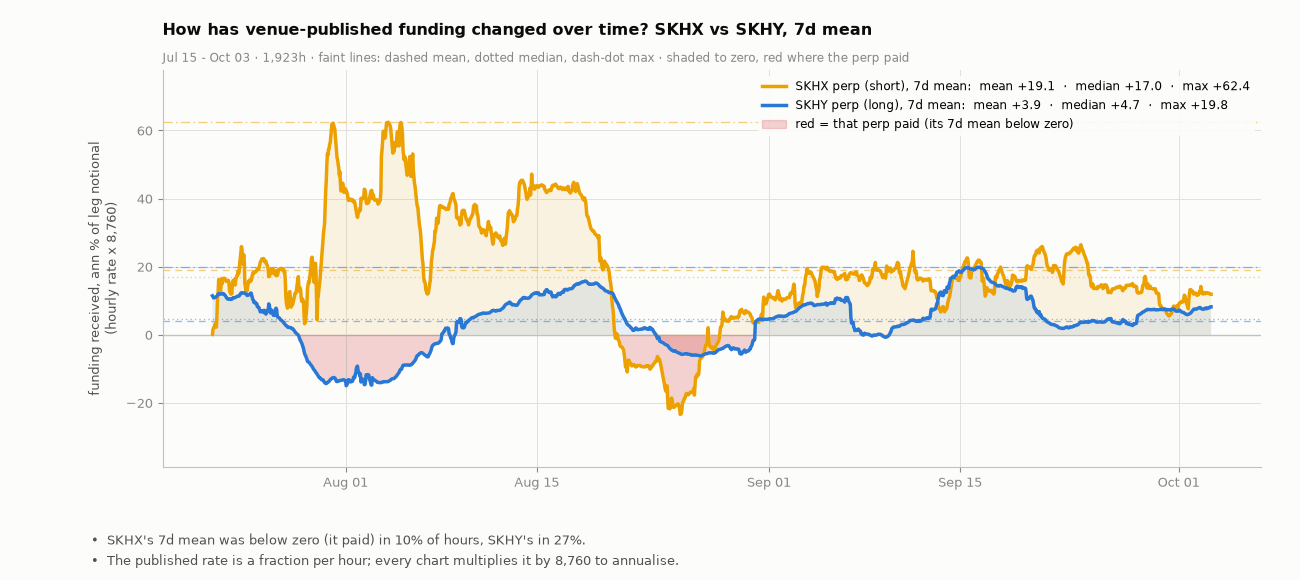

In [8]:
# ---- 1a. SKHX vs SKHY, 7d mean ----
a7, b7 = fA.rolling(168).mean(), fB.rolling(168).mean()
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.plot(a7.index, a7, color=C_A, linewidth=2.5, zorder=4); ax.plot(b7.index, b7, color=C_B, linewidth=2.5, zorder=4)
va, vb = stat3(ax, a7, C_A), stat3(ax, b7, C_B)
ax.plot([], [], color=C_A, linewidth=2.5, label=tag("SKHX perp (short), 7d mean", va)); ax.plot([], [], color=C_B, linewidth=2.5, label=tag("SKHY perp (long), 7d mean", vb))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
for s_, col_ in ((a7.dropna(), C_A), (b7.dropna(), C_B)):
    ax.fill_between(s_.index, s_, 0, where=(s_ >= 0), interpolate=True, color=col_, alpha=0.10, linewidth=0, zorder=1)
    ax.fill_between(s_.index, s_, 0, where=(s_ < 0), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=1)
paid_a, paid_b = float(a7.dropna().lt(0).mean() * 100), float(b7.dropna().lt(0).mean() * 100)
ax.fill_between([], [], color=CRIT, alpha=0.22, label="red = that perp paid (its 7d mean below zero)")
yfit(ax, [a7.dropna(), b7.dropna()], pad=0.18); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has venue-published funding changed over time? SKHX vs SKHY, 7d mean",f"{WS} · {KEY} · shaded to zero, red where the perp paid")
finish(fig, [f"SKHX's 7d mean was below zero (it paid) in {paid_a:.0f}% of hours, SKHY's in {paid_b:.0f}%.",
             "The published rate is a fraction per hour; every chart multiplies it by 8,760 to annualise."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-7d", FIGURES)
ST2["funding7"] = {"A": va, "B": vb, "paid_A_pct": paid_a, "paid_B_pct": paid_b}

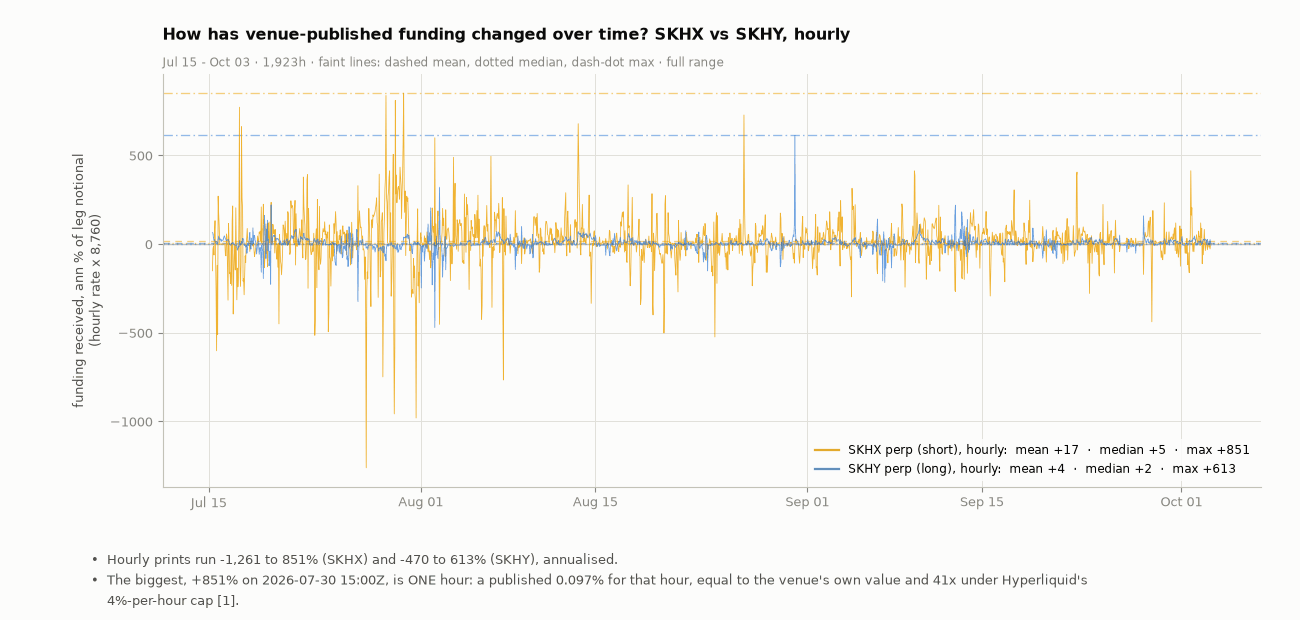

In [9]:
# ---- 1b. hourly ----
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.plot(fA.index, fA, color=C_A, linewidth=0.6, alpha=0.8, zorder=3); ax.plot(fB.index, fB, color=C_B, linewidth=0.6, alpha=0.7, zorder=3)
ha, hb = stat3(ax, fA.iloc[1:], C_A), stat3(ax, fB.iloc[1:], C_B)
ax.plot([], [], color=C_A, linewidth=1.6, label=tag("SKHX perp (short), hourly", ha, 0)); ax.plot([], [], color=C_B, linewidth=1.6, label=tag("SKHY perp (long), hourly", hb, 0))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
yfit(ax, [fA, fB], pad=0.05); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="lower right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has venue-published funding changed over time? SKHX vs SKHY, hourly",f"{WS} · {KEY} · full range")
finish(fig, [f"Hourly prints run {fA.min():,.0f} to {fA.max():,.0f}% (SKHX) and {fB.min():,.0f} to {fB.max():,.0f}% (SKHY), annualised.",
             f"The biggest, +{UC['annualised_pct']:,.0f}% on {UC['hour'][:16]}Z, is ONE hour: a published {UC['pct_per_hour']:.3f}% for that hour, equal to the venue's own value and {UC['times_under_cap']:.0f}x under Hyperliquid's 4%-per-hour cap [1]."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-hourly", FIGURES)
ST2["funding_hourly"] = {"A": ha, "B": hb}

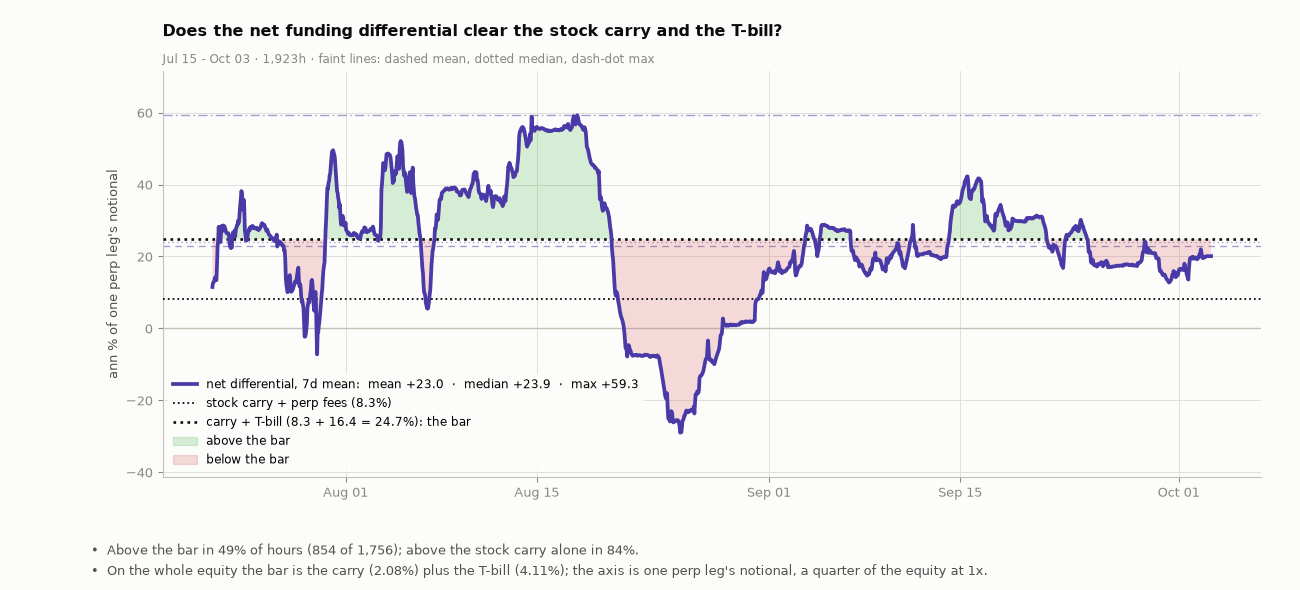

In [10]:
# ---- 2. Does the net differential clear the stock carry AND the T-bill? (7d mean) ----
fig, ax = plt.subplots(figsize=(13, 5.9))
d7c = d_7.dropna()
ax.plot(d7c.index, d7c, color=C_NET, linewidth=2.7, zorder=4)
vn = stat3(ax, d7c, C_NET)
ax.plot([], [], color=C_NET, linewidth=2.7, label=tag("net differential, 7d mean", vn))
ax.axhline(CARRY_LEG, color=INK, linestyle=":", linewidth=1.3, zorder=3, label=f"stock carry + perp fees ({CARRY_LEG:.1f}%)")
ax.axhline(BAR_LEG, color=INK, linestyle=":", linewidth=1.9, zorder=3, label=f"carry + T-bill ({CARRY_LEG:.1f} + {HURDLE_LEG:.1f} = {BAR_LEG:.1f}%): the bar")
ax.axhline(0, color=AXIS, linewidth=1, zorder=2)
ax.fill_between(d7c.index, d7c, BAR_LEG, where=(d7c >= BAR_LEG), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(d7c.index, d7c, BAR_LEG, where=(d7c < BAR_LEG), interpolate=True, color=CRIT, alpha=0.18, linewidth=0, zorder=2)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="above the bar"); ax.fill_between([], [], color=CRIT, alpha=0.18, label="below the bar")
yfit(ax, [d7c, pd.Series([BAR_LEG])], pad=0.14); ax.set_ylabel("ann % of one perp leg's notional")
ax.legend(loc="lower left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
n_up, n_all = int(d7c.gt(BAR_LEG).sum()), int(len(d7c)); n_carry = int(d7c.gt(CARRY_LEG).sum())
share = n_up / n_all * 100
ask(ax, "Does the net funding differential clear the stock carry and the T-bill?",f"{WS} · {KEY}")
finish(fig, [f"Above the bar in {share:.0f}% of hours ({n_up:,} of {n_all:,}); above the stock carry alone in {n_carry / n_all * 100:.0f}%.",
             f"On the whole equity the bar is the carry ({CARRY_LEG / LEGS_PER_EQ:.2f}%) plus the T-bill ({HURDLE_EQ:.2f}%); the axis is one perp leg's notional, a quarter of the equity at 1x."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-net-vs-bar", FIGURES)
ST2["net_vs_bar"] = {"share_above": share, "share_carry": n_carry / n_all * 100, "hours_above": n_up, "hours_all": n_all, "stats": vn}

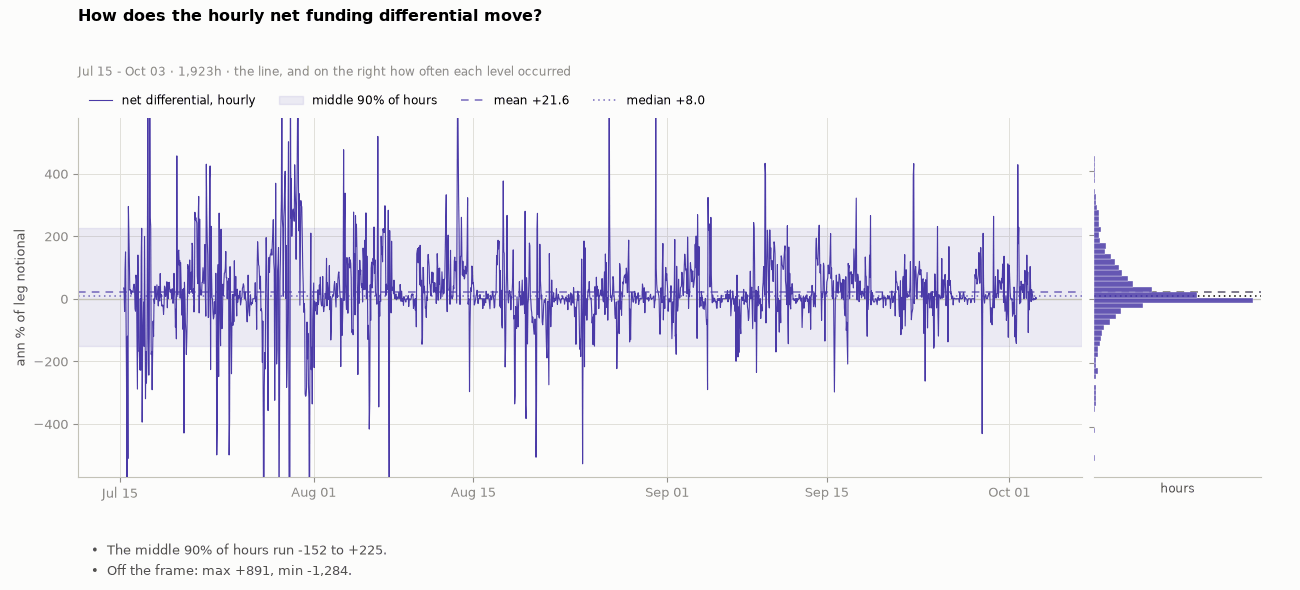

In [11]:
# ---- 3. hourly net differential and its distribution beside it ----
dn = d_h.iloc[1:]
lo_, hi_ = np.nanpercentile(dn, 0.5), np.nanpercentile(dn, 99.5); p5, p95 = np.nanpercentile(dn, 5), np.nanpercentile(dn, 95)
fig = plt.figure(figsize=(13, 5.9))
bm = figstyle.bullets(fig, [f"The middle 90% of hours run {p5:+.0f} to {p95:+.0f}.", f"Off the frame: max {dn.max():+,.0f}, min {dn.min():+,.0f}."])
gs = fig.add_gridspec(1, 2, width_ratios=[6, 1], wspace=0.02, left=0.06, right=0.97, top=0.80, bottom=bm + 0.5 / 5.9)
ax, axh = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax.plot(dn.index, dn, color=C_NET, linewidth=0.8, zorder=3, label="net differential, hourly")
ax.axhspan(p5, p95, color=C_NET, alpha=0.09, zorder=1, label="middle 90% of hours")
ax.axhline(dn.mean(), color=C_NET, linewidth=1.1, linestyle=LSf["mean"], alpha=0.75, zorder=2, label=f"mean {dn.mean():+.1f}")
ax.axhline(dn.median(), color=C_NET, linewidth=1.1, linestyle=LSf["median"], alpha=0.75, zorder=2, label=f"median {dn.median():+.1f}")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_ylim(lo_ - (hi_ - lo_) * 0.06, hi_ + (hi_ - lo_) * 0.06); ax.set_ylabel("ann % of leg notional")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4, fontsize=8.5, frameon=False)
axh.hist(dn[(dn >= lo_) & (dn <= hi_)], bins=60, orientation="horizontal", color=C_NET, alpha=0.85, edgecolor=SURF, linewidth=0.3, zorder=3)
axh.axhline(dn.mean(), color=INK2, linewidth=1.1, linestyle=LSf["mean"]); axh.axhline(dn.median(), color=INK, linewidth=1.1, linestyle=LSf["median"])
axh.axhline(0, color=AXIS, linewidth=1); axh.set_xticks([]); axh.tick_params(labelleft=False); axh.grid(False); axh.set_xlabel("hours", fontsize=8.5)
axh.spines["left"].set_visible(False)
figstyle_ask = figstyle.NAMES  # (kept for symmetry with the pair script)
fig_ask(fig, "How does the hourly net funding differential move?",f"{WS} · the line, and on the right how often each level occurred", 0.80)
figstyle.show(fig, "fig:s2-net-hourly", FIGURES)
ST2["net_hourly"] = {"min": float(dn.min()), "max": float(dn.max()), "mean": float(dn.mean()), "median": float(dn.median()), "p5": float(p5), "p95": float(p95)}

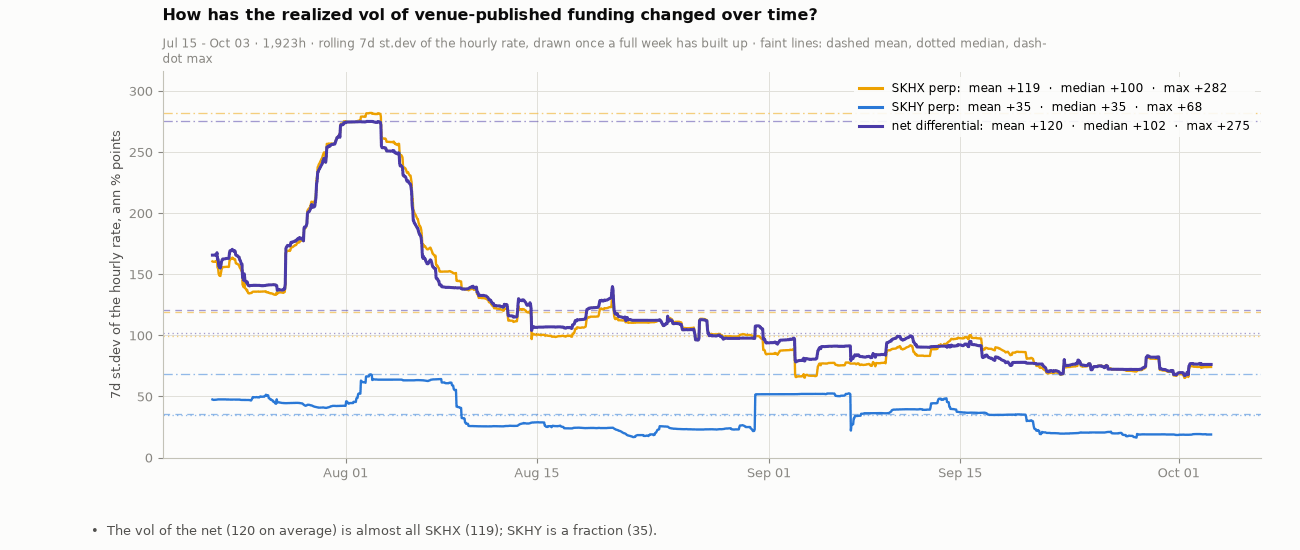

In [12]:
# ---- 4. realized vol of funding ----
fig, ax = plt.subplots(figsize=(13, 5.5))
V, VS = {}, {}
for s, col, lab in ((fA, C_A, "SKHX perp"), (fB, C_B, "SKHY perp"), (d_h, C_NET, "net differential")):
    v7 = s.rolling(168).std(); V[lab] = v7
    ax.plot(v7.index, v7, color=col, linewidth=2.2 if lab == "net differential" else 1.7, zorder=4 if lab == "net differential" else 3)
    VS[lab] = stat3(ax, v7, col); ax.plot([], [], color=col, linewidth=2.2, label=tag(lab, VS[lab], 0))
ax.set_ylabel("7d st.dev of the hourly rate, ann % points"); ax.set_ylim(0, float(max(v.max() for v in V.values())) * 1.12)
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has the realized vol of venue-published funding changed over time?",f"{WS} · rolling 7d st.dev of the hourly rate, drawn once a full week has built up · {KEY}")
finish(fig, [f"The vol of the net ({VS['net differential']['mean']:,.0f} on average) is almost all SKHX ({VS['SKHX perp']['mean']:,.0f}); SKHY is a fraction ({VS['SKHY perp']['mean']:,.0f})."], top=0.87, right=0.97)
figstyle.show(fig, "fig:s2-funding-vol", FIGURES)
ST2["funding_vol"] = VS

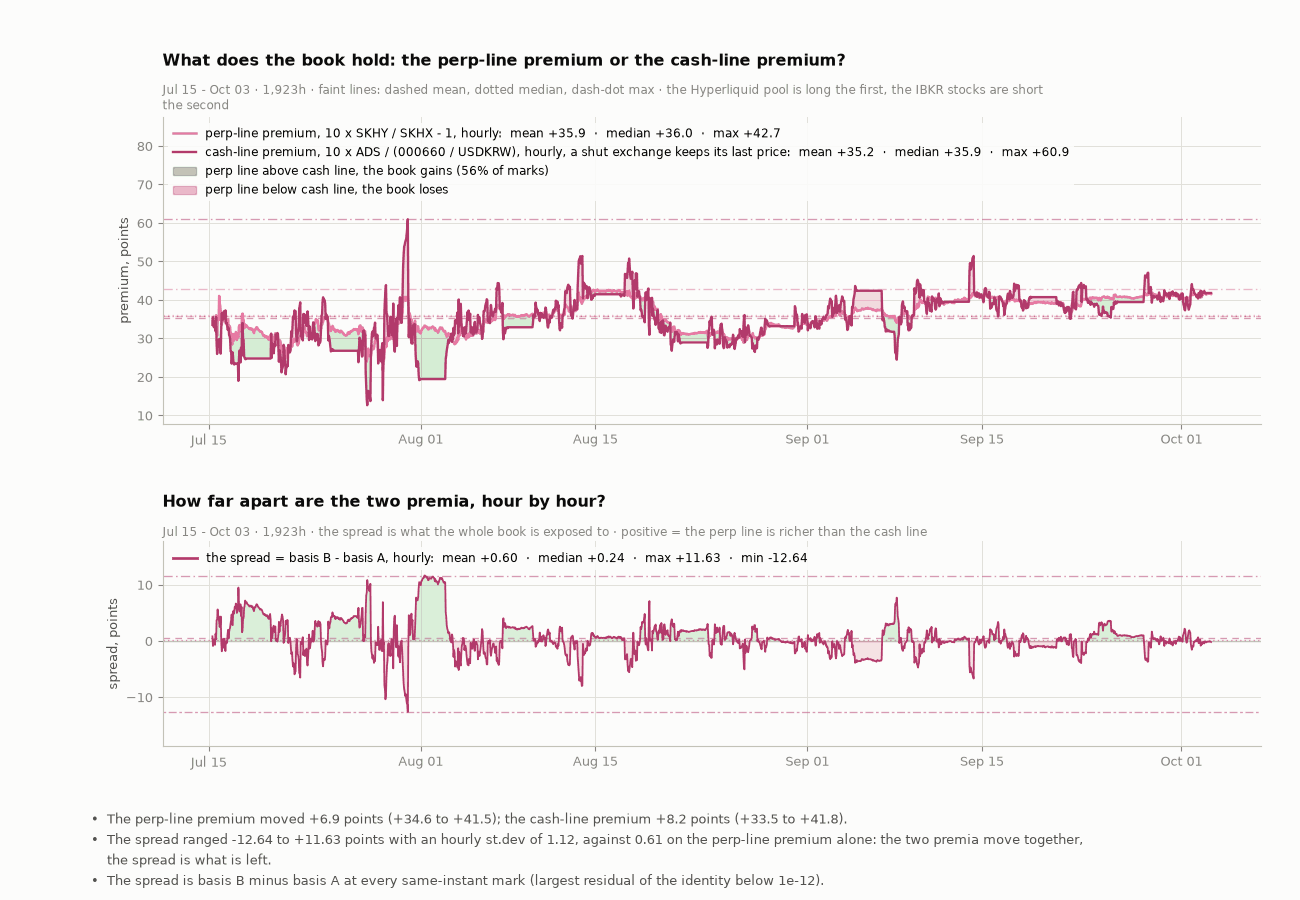

In [13]:
# ---- 5a. the two premia (perp line, cash line) and the spread the book holds ----
IDXT = {t: i for i, t in enumerate(res["series"]["time"])}
t0_, t1_ = res["series"]["time"][0], res["series"]["time"][-1]
hour_of = lambda s_: min((t for t in res["series"]["time"] if t - HOUR < s_ <= t), default=None)
CX, CY, PY, DY, RESID, BAL, BBL = [], [], [], [], [], [], []
RT_ = {r_["time"]: r_ for r_ in rows}
for i_, st in enumerate(res["series"]["time"]):
    kpx, a_, f_ = asof(MKH, st), asof(MAH, st), asof(MFH, st)          # the last hourly print of each cash line, kept constant while its exchange is shut
    rr_ = RT_[st]                                                       # the REAL perp prices: the engine series freezes the late perp before its hedge fills
    pa_, pb_ = rr_["A_perp"], rr_["B_perp"]
    if not (kpx and a_ and f_ and pa_ and pb_):
        continue
    kusd_ = kpx / f_
    cp_ = 10.0 * a_ / kusd_ * 100.0 - 100.0
    pp_ = 10.0 * pb_ / pa_ * 100.0 - 100.0
    bA_si, bB_si = pa_ / kusd_ * 100.0 - 100.0, pb_ / a_ * 100.0 - 100.0
    RESID.append(abs(((1 + bB_si / 100) / (1 + bA_si / 100) - (1 + pp_ / 100) / (1 + cp_ / 100)) * 100))
    CX.append(pd.Timestamp(st, unit="ms", tz="UTC")); CY.append(cp_); PY.append(pp_); DY.append(((1 + pp_ / 100) / (1 + cp_ / 100) - 1) * 100); BAL.append(bA_si); BBL.append(bB_si)
assert max(RESID) < 1e-12, max(RESID)          # the identity: spread = basis B vs basis A, exactly, at every hour
bA, bB = pd.Series(BAL, index=CX), pd.Series(BBL, index=CX)
nb_ = ((1 + bB / 100) / (1 + bA / 100) - 1) * 100
cp_s, pp_s, sp_s = pd.Series(CY, index=CX), pd.Series(PY, index=CX), pd.Series(DY, index=CX)
fig, (b0, b1) = plt.subplots(2, 1, figsize=(13, 9.0), sharex=False, gridspec_kw={"height_ratios": [3, 2]})
b0.fill_between(CX, PY, CY, where=(np.array(PY) >= np.array(CY)), color=GOOD, alpha=0.16, lw=0, zorder=1)
b0.fill_between(CX, PY, CY, where=(np.array(PY) < np.array(CY)), color=CRIT, alpha=0.16, lw=0, zorder=1)
b0.plot(prem.index, prem, color=C_PREM, linewidth=1.8, zorder=4, label=tag("perp-line premium, 10 x SKHY / SKHX - 1, hourly", {"mean": prem.mean(), "median": prem.median(), "max": prem.max()}, 1))
b0.plot(CX, CY, color=C_PREM_DK, linewidth=1.7, zorder=5, label=tag("cash-line premium, 10 x ADS / (000660 / USDKRW), hourly, a shut exchange keeps its last price", {"mean": cp_s.mean(), "median": cp_s.median(), "max": cp_s.max()}, 1))
stat3(b0, prem, C_PREM); stat3(b0, cp_s, C_PREM_DK)
b0.axhline(0, color=AXIS, linewidth=1); b0.set_ylabel("premium, points")
b0.fill_between([], [], color=GOOD, alpha=0.3, label=f"perp line above cash line, the book gains ({np.mean(np.array(DY) > 0) * 100:.0f}% of marks)")
b0.fill_between([], [], color=CRIT, alpha=0.3, label="perp line below cash line, the book loses")
lo_, hi_ = min(min(CY), float(prem.min())), max(max(CY), float(prem.max()))
b0.set_ylim(lo_ - (hi_ - lo_) * 0.10, hi_ + (hi_ - lo_) * 0.55); b0.legend(loc="upper left", fontsize=8.3, **LEG)
b0.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(b0, "What does the book hold: the perp-line premium or the cash-line premium?", f"{WS} · {KEY} · the Hyperliquid pool is long the first, the IBKR stocks are short the second")
sd = nb_
b1.plot(sd.index, sd, color=C_PREM_DK, linewidth=1.3, zorder=4)
vs_ = stat3(b1, sd, C_PREM_DK, with_min=True)
b1.plot([], [], color=C_PREM_DK, linewidth=2.0, label=tag("the spread = basis B - basis A, hourly", vs_, 2))
b1.axhline(0, color=AXIS, linewidth=1, zorder=1); b1.set_ylabel("spread, points")
b1.fill_between(sd.index, sd, 0, where=(sd >= 0), interpolate=True, color=GOOD, alpha=0.14, linewidth=0, zorder=1)
b1.fill_between(sd.index, sd, 0, where=(sd < 0), interpolate=True, color=CRIT, alpha=0.14, linewidth=0, zorder=1)
yfit(b1, [sd], pad=0.25); b1.legend(loc="upper left", fontsize=8.5, **LEG); b1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(b1, "How far apart are the two premia, hour by hour?", f"{WS} · the spread is what the whole book is exposed to · positive = the perp line is richer than the cash line")
dS, dP = sd.diff(), prem.diff()
finish(fig, [f"The perp-line premium moved {prem.iloc[-1] - P0:+.1f} points ({P0:+.1f} to {prem.iloc[-1]:+.1f}); the cash-line premium {CY[-1] - CY[0]:+.1f} points ({CY[0]:+.1f} to {CY[-1]:+.1f}).",
             f"The spread ranged {sd.min():+.2f} to {sd.max():+.2f} points with an hourly st.dev of {dS.std():.2f}, against {dP.std():.2f} on the perp-line premium alone: the two premia move together, the spread is what is left.",
             "The spread is basis B minus basis A at every same-instant mark (largest residual of the identity below 1e-12)."], top=0.87, hspace=0.46, right=0.97)
figstyle.show(fig, "fig:s2-premia", FIGURES)
ST2["premia"] = {"perp": {"start": float(P0), "end": float(prem.iloc[-1]), "mean": float(prem.mean())}, "cash": {"start": float(CY[0]), "end": float(CY[-1]), "mean": float(np.mean(CY))},
                   "spread": vs_, "spread_hourly_std": float(dS.std()), "perp_hourly_std": float(dP.std()), "share_with_book": float(np.mean(np.array(DY) > 0) * 100), "max_resid": float(max(RESID))}

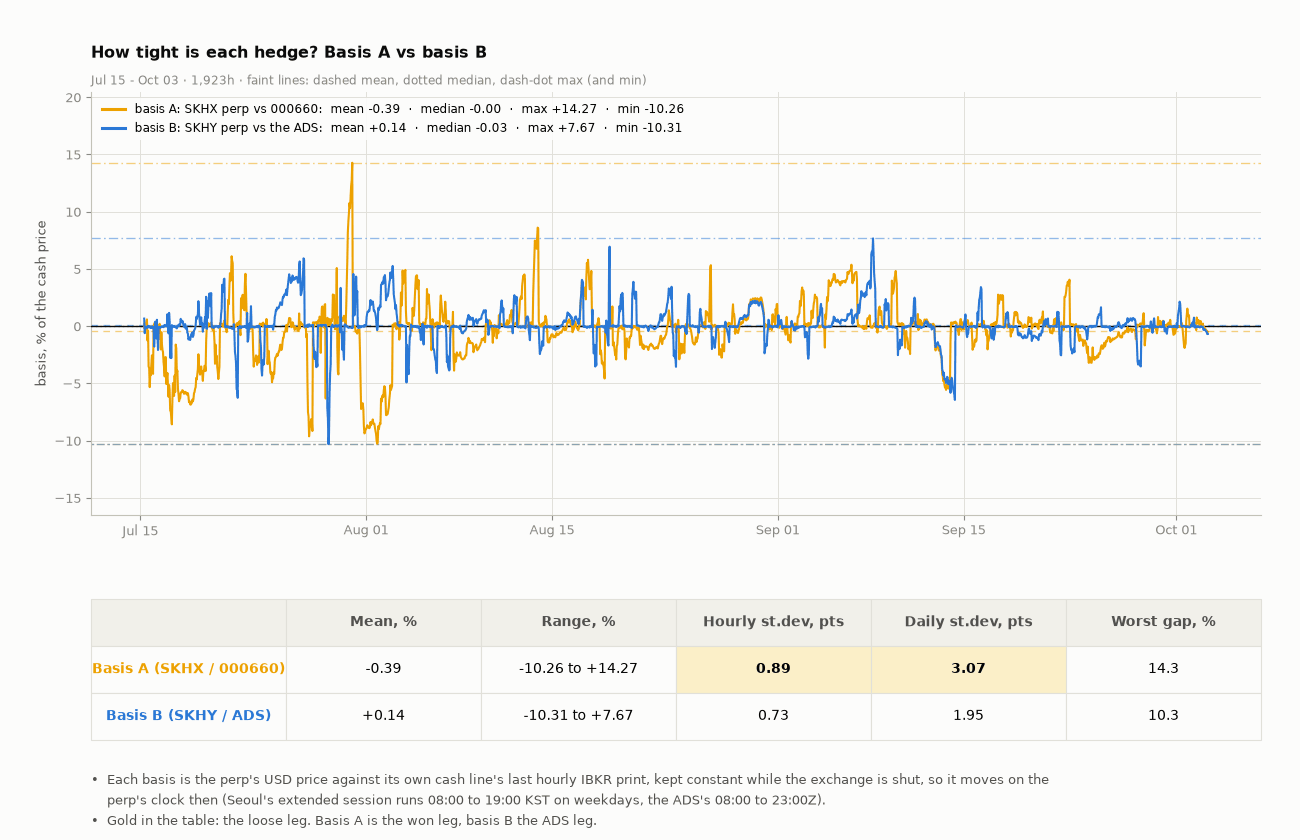

In [14]:
# ---- 5b. each hedge's own basis: SKHX perp vs 000660, SKHY perp vs the ADS ----
fig = plt.figure(figsize=(13, 8.4))
bm = figstyle.bullets(fig, ["Each basis is the perp's USD price against its own cash line's last hourly IBKR print, kept constant while the exchange is shut, so it moves on the perp's clock then (Seoul's extended session runs 08:00 to 19:00 KST on weekdays, the ADS's 08:00 to 23:00Z).",
                            "Gold in the table: the loose leg. Basis A is the won leg, basis B the ADS leg."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.0, 1.0], hspace=0.30, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
ax.plot(bA.index, bA, color=C_A, linewidth=1.5, zorder=4); ax.plot(bB.index, bB, color=C_B, linewidth=1.5, zorder=4)
va_, vb_ = stat3(ax, bA, C_A, with_min=True), stat3(ax, bB, C_B, with_min=True)
ax.plot([], [], color=C_A, linewidth=2.2, label=tag("basis A: SKHX perp vs 000660", va_, 2)); ax.plot([], [], color=C_B, linewidth=2.2, label=tag("basis B: SKHY perp vs the ADS", vb_, 2))
ax.axhline(0, color=INK, linewidth=1, zorder=3); ax.set_ylabel("basis, % of the cash price"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); yfit(ax, [bA, bB], pad=0.25)
ask(ax, "How tight is each hedge? Basis A vs basis B", f"{WS} · {KEY} (and min)")
dbA, dbB = bA.diff(), bB.diff()
cells = [["Basis A (SKHX / 000660)", f"{bA.mean():+.2f}", f"{bA.min():+.2f} to {bA.max():+.2f}", f"{dbA.std():.2f}", f"{bA.diff(24).std():.2f}", f"{bA.abs().max():.1f}"],
         ["Basis B (SKHY / ADS)", f"{bB.mean():+.2f}", f"{bB.min():+.2f} to {bB.max():+.2f}", f"{dbB.std():.2f}", f"{bB.diff(24).std():.2f}", f"{bB.abs().max():.1f}"]]
tb = axt.table(cellText=cells, colLabels=["", "Mean, %", "Range, %", "Hourly st.dev, pts", "Daily st.dev, pts", "Worst gap, %"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(10); figstyle.style_table(tb)
loose = 0 if bA.diff(24).std() >= bB.diff(24).std() else 1
for r_ in (1, 2):
    tb[(r_, 0)].set_text_props(weight="bold", color=(C_A if r_ == 1 else C_B)); tb[(r_, 0)]._loc = "left"
figstyle.gold(tb, loose + 1, 4); figstyle.gold(tb, loose + 1, 3)
figstyle.show(fig, "fig:s2-bases", FIGURES)
ST2["bases"] = {"A": {"mean": float(bA.mean()), "min": float(bA.min()), "max": float(bA.max()), "h_std": float(dbA.std()), "d_std": float(bA.diff(24).std())},
                  "B": {"mean": float(bB.mean()), "min": float(bB.min()), "max": float(bB.max()), "h_std": float(dbB.std()), "d_std": float(bB.diff(24).std())}}

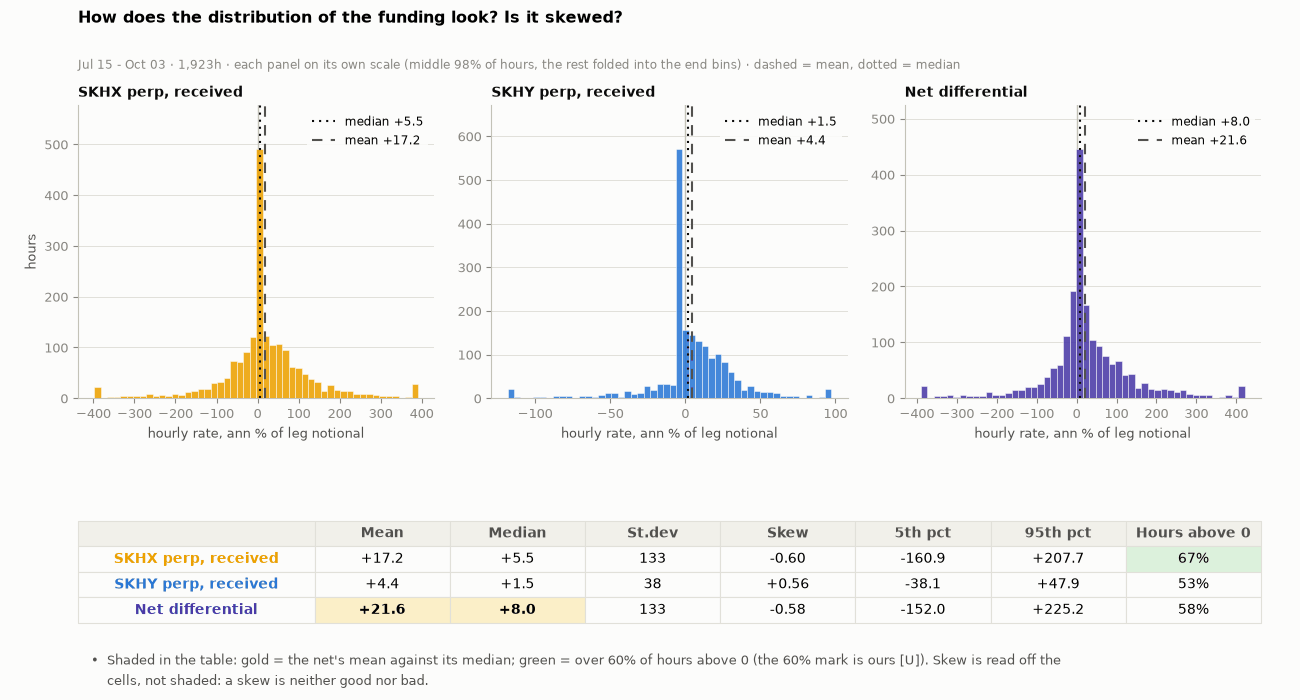

In [15]:
# ---- 6. distribution: three histograms, ONE table ----
from fundplat.quant.crypto.backtest import hip3_pair as HP
rows_pers = rows
PS = HP.funding_persistence(rows_pers, "short_a")
SER = ((fA.iloc[1:], C_A, "SKHX perp, received"), (fB.iloc[1:], C_B, "SKHY perp, received"), (dn, C_NET, "Net differential"))
fig = plt.figure(figsize=(13, 7.0))
bm = figstyle.bullets(fig, ["Shaded in the table: gold = the net's mean against its median; green = over 60% of hours above 0 (the 60% mark is ours [U]). Skew is read off the cells, not shaded: a skew is neither good nor bad."])
gs = fig.add_gridspec(2, 3, height_ratios=[3.3, 1.15], hspace=0.62, wspace=0.16, left=0.06, right=0.97, top=0.85, bottom=bm + 0.02)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
axt = fig.add_subplot(gs[1, :]); axt.axis("off")
D = {}
for a_, (s_, col, lab) in zip(axs, SER):
    lo_, hi_ = np.nanpercentile(s_, 1), np.nanpercentile(s_, 99)
    a_.hist(s_.clip(lo_, hi_), bins=np.linspace(lo_, hi_, 51), color=col, alpha=0.88, edgecolor=SURF, linewidth=0.4, zorder=3)
    a_.axvline(0, color=AXIS, linewidth=1, zorder=2)
    a_.axvline(s_.median(), color=INK, linestyle=LSf["median"], linewidth=1.5, zorder=5, label=f"median {s_.median():+.1f}")
    a_.axvline(s_.mean(), color=INK2, linestyle=LSf["mean"], linewidth=1.5, zorder=5, label=f"mean {s_.mean():+.1f}")
    a_.set_title(lab, fontsize=10, loc="left", pad=6); a_.set_xlabel("hourly rate, ann % of leg notional"); a_.legend(loc="upper right", fontsize=8.5, **LEG)
    a_.grid(axis="x", visible=False); a_.set_ylim(top=a_.get_ylim()[1] * 1.12)
    D[lab] = {"mean": s_.mean(), "median": s_.median(), "std": s_.std(), "skew": s_.skew(), "p5": np.nanpercentile(s_, 5), "p95": np.nanpercentile(s_, 95), "min": s_.min(), "max": s_.max(), "pos": float((s_ > 0).mean() * 100)}
axs[0].set_ylabel("hours")
cols = ["", "Mean", "Median", "St.dev", "Skew", "5th pct", "95th pct", "Hours above 0"]
cells = [[lab, f"{d['mean']:+.1f}", f"{d['median']:+.1f}", f"{d['std']:,.0f}", f"{d['skew']:+.2f}", f"{d['p5']:+.1f}", f"{d['p95']:+.1f}", f"{d['pos']:.0f}%"] for lab, d in D.items()]
tb = figstyle.put_table(axt, cells, cols, size=10, first=0.2)
for r_ in (1, 2, 3):
    d_ = list(D.values())[r_ - 1]
    tb[(r_, 0)].set_text_props(weight="bold", color=SER[r_ - 1][1]); tb[(r_, 0)]._loc = "left"
    if d_["pos"] > 60: figstyle.tint(tb, r_, 7, "green")
figstyle.gold(tb, 3, 1); figstyle.gold(tb, 3, 2)
fig_ask(fig, "How does the distribution of the funding look? Is it skewed?",f"{WS} · each panel on its own scale (middle 98% of hours, the rest folded into the end bins) · dashed = mean, dotted = median", 0.85)
figstyle.show(fig, "fig:s2-distribution", FIGURES)
ST2["dist"] = D
ST2["persist"] = {"half_life_h": float(PS["half_life_h"]), "acf24": float(PS["acf"][24])}

## S3 · Core result - Base test

Does the rule-hedged book pay at 1x, with nothing amplifying it? The book runs the hedge rule of S1, so every figure from here on is the re-hedged book's.

In [16]:
LSf = figstyle.LS

r_ = res
DAY = DAYS_[BOOK]
DB = DBAS[BOOK]
yrs = r_["days"] / 365.0
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h · 1x cross · always-hold · costs on"
COSTS_USD = r_["financing"] + r_["stock_costs"] + r_["perp_fees"] + r_["perp_liq_fees"] - r_["dividends"]      # everything the gate metric nets off the funding
CARRY_USD = carry_usd(r_)
assert abs(CARRY_USD - (r_["funding_net"] - COSTS_USD)) < 1e-6
# ONE mark for the book's totals: the FAIR-VALUE one (the clock-consistent mark). The two bases are the perp price P&L plus each stock leg re-struck every hour; they add to the total less the carry.
BASFV = {"A": float((num(df["cum_price_A"]) + num(df["cum_stock_A_fv"])).iloc[-1]), "B": float((num(df["cum_price_B"]) + num(df["cum_stock_B_fv"])).iloc[-1])}
assert abs(BASFV["A"] + BASFV["B"] - (r_["total_pnl_fv"] - CARRY_USD)) < 1e-4, (BASFV, r_["total_pnl_fv"], CARRY_USD)
ST3 = {"hours": int(r_["n_hours"]), "total": r_["total_pnl_fv"], "total_close": r_["total_pnl"], "funding": r_["funding_net"], "costs": COSTS_USD, "gate_usd": CARRY_USD, "gate_ann": carry_ann(r_),
         "basis": BASFV["A"] + BASFV["B"], "basis_close": r_["net_basis_pnl"], "basis_A": BASFV["A"], "basis_B": BASFV["B"], "basis_A_close": BAS[BOOK]["A"], "basis_B_close": BAS[BOOK]["B"],
         "financing": r_["financing"], "stock_costs": r_["stock_costs"], "perp_fees": r_["perp_fees"] + r_["perp_liq_fees"], "dividends": r_["dividends"],
         "ann_equity": eq_ann(r_), "ann_equity_close": eq_ann_close(r_), "days": r_["days"]}
DD_CUT = -1.0

eq = (EQUITY + num(df["total_pnl"])) / 1e6
uw = (eq / eq.cummax() - 1) * 100
assert abs(uw.min() / 100 - r_["max_drawdown_equity"]) < 1e-6, (uw.min(), r_["max_drawdown_equity"])
eq_fv = (EQUITY + num(df["total_pnl_fv"])) / 1e6
uw_fv = (eq_fv / eq_fv.cummax() - 1) * 100
_cap = (r_["capital"] + num(df["total_pnl_fv"])); assert abs((_cap / _cap.cummax() - 1).min() - r_["max_drawdown_fv"]) < 1e-6      # the engine's own figure is on `capital`; the chart is on the USD 1M of equity, as the close-marked one is
STATS_FV_ENGINE = float(r_["max_drawdown_fv"] * 100)
# the episodes are read on the FAIR-VALUE mark (the book); the close-marked line is what a statement prints, two clocks in one number
eps, i, idx, n_ = [], 0, eq_fv.index, len(eq_fv)
while i < n_:
    if uw_fv.iloc[i] < 0:
        j = i
        while j + 1 < n_ and uw_fv.iloc[j + 1] < 0:
            j += 1
        seg = uw_fv.iloc[i:j + 1]
        eps.append({"peak": idx[max(i - 1, 0)], "trough": seg.idxmin(), "end": idx[j], "recovered": j + 1 < n_, "depth": float(seg.min())})
        i = j + 1
    else:
        i += 1
eps.sort(key=lambda e: e["depth"])
EP = [e for e in eps if e["depth"] <= DD_CUT]
for k, e in enumerate(EP, 1):
    e["rank"] = k
    e["days_down"] = (e["trough"] - e["peak"]).total_seconds() / 86400
    e["days_recover"] = (e["end"] - e["trough"]).total_seconds() / 86400

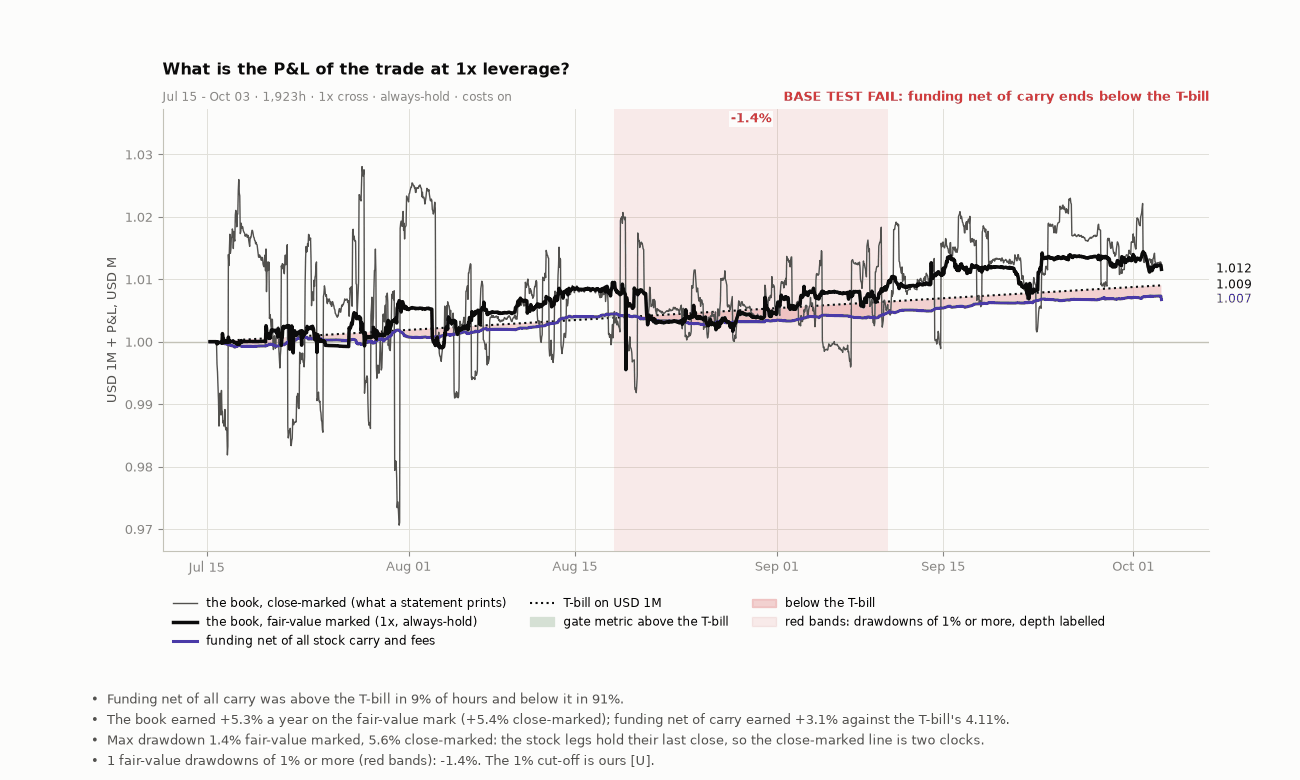

In [17]:
# ---- 1. What is the P&L of the trade at 1x leverage? the book, the gate metric (funding net of all carry), the T-bill ----
gate_line = (EQUITY + num(df["cum_funding_net"]) - num(df["cum_financing"]) - num(df["cum_stock_costs"]) - num(df["cum_perp_fees"]) + num(df["cum_dividends"])) / 1e6
tbill = pd.Series(EQUITY * (1 + p1.hurdle_ann * np.asarray((df.index - df.index[0]).total_seconds()) / (365 * 86400)) / 1e6, index=df.index)
share_up = float((gate_line >= tbill).mean() * 100)
G1a = bool(gate_line.iloc[-1] > tbill.iloc[-1])
H1 = 7.8
fig, ax = plt.subplots(figsize=(13, H1))
for e in EP:
    ax.axvspan(e["peak"], e["end"], color=CRIT, alpha=0.09, linewidth=0, zorder=1)
ax.plot(df.index, eq, color=INK2, linewidth=1.0, zorder=4, label="the book, close-marked (what a statement prints)")
ax.plot(df.index, eq_fv, color=INK, linewidth=2.5, zorder=5, label="the book, fair-value marked (1x, always-hold)")
ax.plot(df.index, gate_line, color=C_NET, linewidth=2.2, zorder=4, label="funding net of all stock carry and fees")
ax.plot(df.index, tbill, color=INK, linewidth=1.5, linestyle=":", zorder=3, label=f"T-bill on {usdm(EQUITY)}")
ax.fill_between(df.index, gate_line, tbill, where=(gate_line >= tbill), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(df.index, gate_line, tbill, where=(gate_line < tbill), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axhline(1.0, color=AXIS, linewidth=1, zorder=1)
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo - (yhi - ylo) * 0.02, yhi + (yhi - ylo) * 0.10)
for k, e in enumerate(EP):
    xm = e["peak"] + (e["end"] - e["peak"]) / 2
    ax.text(xm, yhi + (yhi - ylo) * (0.075 if k % 2 == 0 else 0.035), f"{e['depth']:.1f}%", ha="center", va="center", fontsize=9, color=CRIT, fontweight="bold", bbox=dict(facecolor=SURF, edgecolor="none", pad=1.2), zorder=7)
for s_, c_ in ((eq_fv, INK), (gate_line, C_NET), (tbill, INK)):
    ax.annotate(f" {s_.iloc[-1]:.3f}", xy=(1.003, s_.iloc[-1]), xycoords=("axes fraction", "data"), color=c_, fontsize=8.5, va="center", annotation_clip=False)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="gate metric above the T-bill"); ax.fill_between([], [], color=CRIT, alpha=0.22, label="below the T-bill")
ax.fill_between([], [], color=CRIT, alpha=0.09, label="red bands: drawdowns of 1% or more, depth labelled")
ax.text(1.0, 1.012, ("BASE TEST PASS: funding net of carry ends above the T-bill" if G1a else "BASE TEST FAIL: funding net of carry ends below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G1a else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("USD 1M + P&L, USD M"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=3, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "What is the P&L of the trade at 1x leverage?", WSH)
bm = figstyle.bullets(fig, [f"Funding net of all carry was above the T-bill in {share_up:.0f}% of hours and below it in {100 - share_up:.0f}%.",
                            f"The book earned {eq_ann(r_):+.1f}% a year on the fair-value mark ({eq_ann_close(r_):+.1f}% close-marked); funding net of carry earned {carry_ann(r_):+.1f}% against the T-bill's {HURDLE_PCT:.2f}%.",
                            f"Max drawdown {abs(uw_fv.min()):.1f}% fair-value marked, {abs(r_['max_drawdown_equity']) * 100:.1f}% close-marked: the stock legs hold their last close, so the close-marked line is two clocks.",
                            f"{len(EP)} fair-value drawdowns of 1% or more (red bands): " + (", ".join(f"{e['depth']:.1f}%" for e in EP) or "none") + ". The 1% cut-off is ours [U]."])
plt.subplots_adjust(top=0.86, right=0.93, bottom=bm + 1.25 / H1)
figstyle.show(fig, "fig:s3-equity", FIGURES)
ST3["equity"] = {"book_end": float(eq_fv.iloc[-1]), "close_end": float(eq.iloc[-1]), "maxdd_fv": float(uw_fv.min()), "gate_end": float(gate_line.iloc[-1]), "tbill_end": float(tbill.iloc[-1]), "share_up": share_up, "pass": G1a, "n_dd_eps": len(EP), "dd_depths": [round(e["depth"], 2) for e in EP], "maxdd": r_["max_drawdown_equity"] * 100}

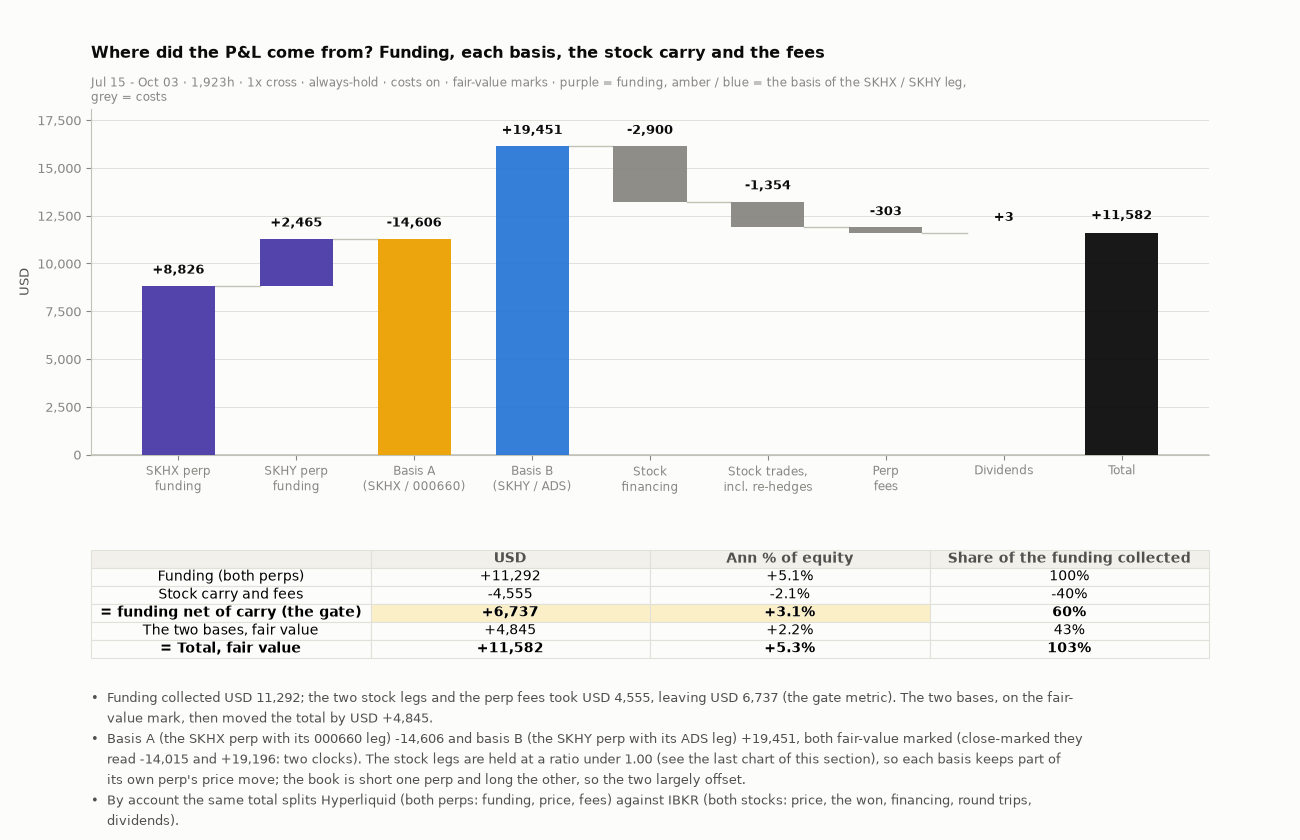

In [18]:
# ---- 2. Where did the P&L come from? a waterfall by source, then the same total by account ----
H2 = 8.4
fig = plt.figure(figsize=(13, H2))
parts = [("SKHX perp\nfunding", r_["funding_A"], C_NET), ("SKHY perp\nfunding", r_["funding_B"], C_NET), ("Basis A\n(SKHX / 000660)", BASFV["A"], C_A), ("Basis B\n(SKHY / ADS)", BASFV["B"], C_B),
         ("Stock\nfinancing", -r_["financing"], C_COST), ("Stock trades,\nincl. re-hedges", -r_["stock_costs"], C_COST), ("Perp\nfees", -(r_["perp_fees"] + r_["perp_liq_fees"]), C_COST), ("Dividends", r_["dividends"], C_COST)]
assert abs(sum(p[1] for p in parts) - r_["total_pnl_fv"]) < 1e-6          # the waterfall is on the FAIR-VALUE mark and adds to the fair-value total
bm = figstyle.bullets(fig, [f"Funding collected USD {r_['funding_net']:,.0f}; the two stock legs and the perp fees took USD {COSTS_USD:,.0f}, leaving USD {CARRY_USD:,.0f} (the gate metric). The two bases, on the fair-value mark, then moved the total by USD {ST3['basis']:+,.0f}.",
                            f"Basis A (the SKHX perp with its 000660 leg) {BASFV['A']:+,.0f} and basis B (the SKHY perp with its ADS leg) {BASFV['B']:+,.0f}, both fair-value marked (close-marked they read {BAS[BOOK]['A']:+,.0f} and {BAS[BOOK]['B']:+,.0f}: two clocks). The stock legs are held at a ratio under 1.00 (see the last chart of this section), so each basis keeps part of its own perp's price move; the book is short one perp and long the other, so the two largely offset.",
                            "By account the same total splits Hyperliquid (both perps: funding, price, fees) against IBKR (both stocks: price, the won, financing, round trips, dividends)."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.0], hspace=0.42, left=0.07, right=0.93, top=0.87, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
run = 0.0
for k, (nm, v, col) in enumerate(parts):
    lo_, hi_ = (run, run + v) if v >= 0 else (run + v, run)
    ax.bar(k, hi_ - lo_, bottom=lo_, color=col, alpha=0.95, width=0.62, zorder=3)
    ax.text(k, hi_ + (max(abs(p[1]) for p in parts)) * 0.025, f"{v:+,.0f}", ha="center", va="bottom", fontsize=9, color=INK, fontweight="bold")
    if k < len(parts) - 1:
        ax.plot([k + 0.31, k + 1 - 0.31], [run + v, run + v], color=AXIS, linewidth=1, zorder=2)
    run += v
ax.bar(len(parts), run, color=INK, width=0.62, zorder=3, alpha=0.95); ax.text(len(parts), max(run, 0) + max(abs(p[1]) for p in parts) * 0.03, f"{run:+,.0f}", ha="center", va="bottom", fontsize=9, color=INK, fontweight="bold")
ax.set_xticks(range(len(parts) + 1)); ax.set_xticklabels([p[0] for p in parts] + ["Total"], fontsize=8.8); ax.set_ylim(0, max(np.cumsum([p[1] for p in parts]).max(), 1) * 1.12)
ax.axhline(0, color=INK, linewidth=1, zorder=2); ax.set_ylabel("USD"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ask(ax, "Where did the P&L come from? Funding, each basis, the stock carry and the fees", f"{WSH} · fair-value marks · purple = funding, amber / blue = the basis of the SKHX / SKHY leg, grey = costs")
cols = ["", "USD", "Ann % of equity", "Share of the funding collected"]
rowsT = [["Funding (both perps)", r_["funding_net"], r_["funding_net"] / EQUITY / yrs * 100, 100.0],
         ["Stock carry and fees", -COSTS_USD, -COSTS_USD / EQUITY / yrs * 100, -COSTS_USD / r_["funding_net"] * 100],
         ["= funding net of carry (the gate)", CARRY_USD, CARRY_USD / EQUITY / yrs * 100, CARRY_USD / r_["funding_net"] * 100],
         ["The two bases, fair value", ST3["basis"], ST3["basis"] / EQUITY / yrs * 100, ST3["basis"] / r_["funding_net"] * 100],
         ["= Total, fair value", r_["total_pnl_fv"], r_["total_pnl_fv"] / EQUITY / yrs * 100, r_["total_pnl_fv"] / r_["funding_net"] * 100]]
cells = [[a, f"{b:+,.0f}", f"{c:+.1f}%", f"{d:.0f}%"] for a, b, c, d in rowsT]
tb = axt.table(cellText=cells, colLabels=cols, cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.auto_set_font_size(False); tb.set_fontsize(9.8); figstyle.style_table(tb)
for r_i in range(1, 6):
    tb[(r_i, 0)]._loc = "left"
for r_i in (3, 5):
    for c_i in range(4): tb[(r_i, c_i)].set_text_props(weight="bold")
figstyle.gold(tb, 3, 1); figstyle.gold(tb, 3, 2)
figstyle.show(fig, "fig:s3-pnl", FIGURES)
ST3["waterfall"] = [[p[0].replace("\n", " "), float(p[1])] for p in parts]
ST3["accounts"] = ACC[BOOK]

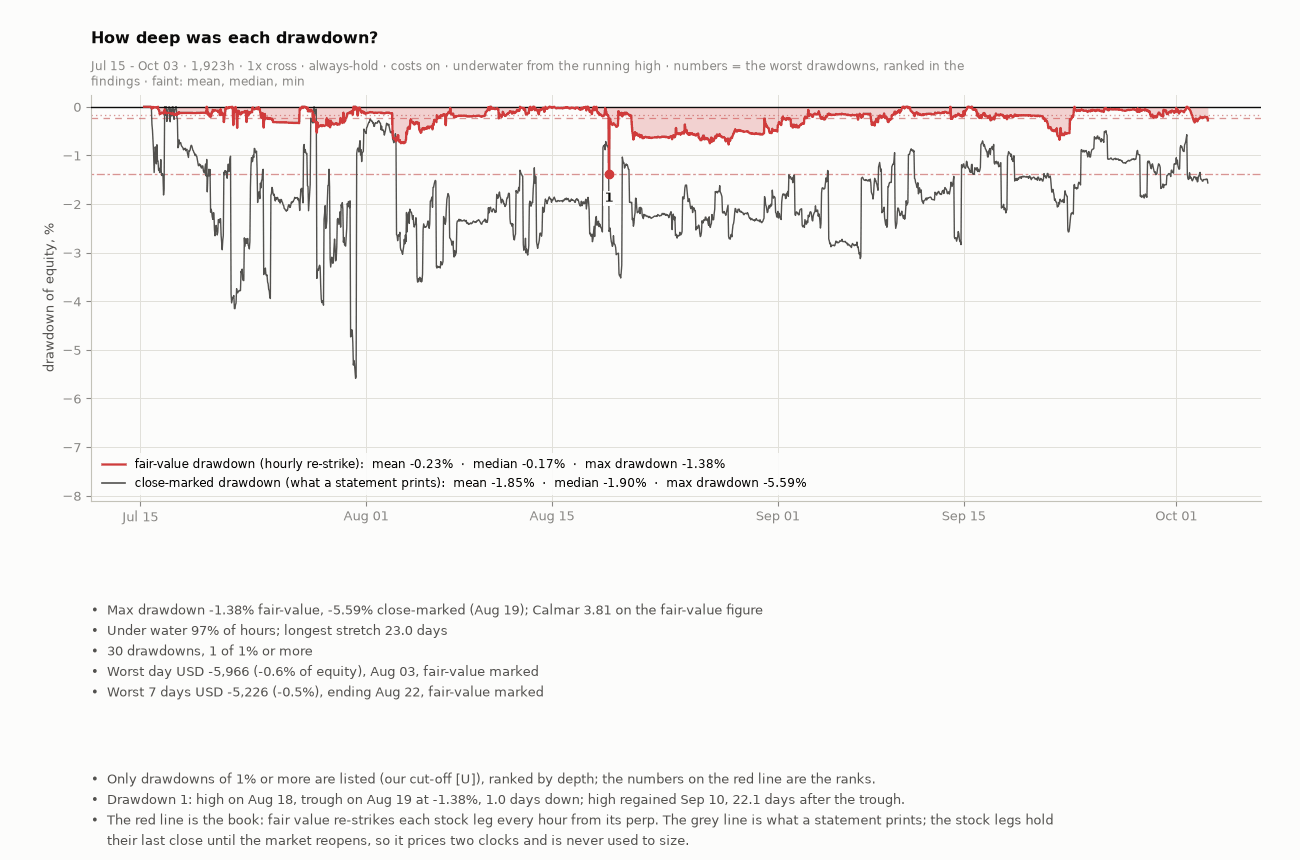

In [19]:
# ---- 3. How deep was each drawdown? close-marked vs fair-value; each drawdown of 1% or more is a line of the findings ----
under = uw_fv < -1e-9
run_ = (under != under.shift()).cumsum()
longest = int(under.groupby(run_).sum().max())
calmar = eq_ann(r_) / 100 / abs(uw_fv.min() / 100)                            # the fair-value return over the fair-value drawdown: one mark
FVD = daily_cum(num(df["total_pnl_fv"]))                                       # the daily P&L on the FAIR-VALUE mark, the same mark as the tails figure that follows
wd = FVD.min(); wd_day = FVD.idxmin()
w7 = FVD.rolling(7).sum(); w7min, w7day = w7.min(), w7.idxmin()
H3 = 8.6
fig = plt.figure(figsize=(13, H3))
EPL = [f"Drawdown {e['rank']}: high on {e['peak']:%b %d}, trough on {e['trough']:%b %d} at {e['depth']:.2f}%, {e['days_down']:.1f} days down; "
       + (f"high regained {e['end']:%b %d}, {e['days_recover']:.1f} days after the trough." if e["recovered"] else "high not regained by the last hour.") for e in EP]
bm = figstyle.bullets(fig, ["Only drawdowns of 1% or more are listed (our cut-off [U]), ranked by depth; the numbers on the red line are the ranks.", *EPL,
                            "The red line is the book: fair value re-strikes each stock leg every hour from its perp. The grey line is what a statement prints; the stock legs hold their last close until the market reopens, so it prices two clocks and is never used to size."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.0, 1.0], hspace=0.38, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax.fill_between(df.index, uw_fv, 0, color=CRIT, alpha=0.22, linewidth=0, zorder=2); ax.plot(df.index, uw_fv, color=CRIT, linewidth=1.7, zorder=4)
ax.plot(df.index, uw, color=INK2, linewidth=1.0, zorder=3)
for k, y in (("mean", uw_fv.mean()), ("median", uw_fv.median()), ("min", uw_fv.min())):
    ax.axhline(y, color=CRIT, linewidth=0.95, linestyle=LSf[k], alpha=0.55, zorder=2)
for e in EP:
    ax.plot([e["trough"]], [e["depth"]], "o", color=CRIT, markersize=6, zorder=6)
    ax.annotate(f"{e['rank']}", xy=(e["trough"], e["depth"]), xytext=(0, -13), textcoords="offset points", ha="center", va="top", fontsize=9, color=INK, fontweight="bold", bbox=dict(facecolor=SURF, edgecolor="none", pad=1.0), zorder=7)
ax.plot([], [], color=CRIT, linewidth=1.8, label=f"fair-value drawdown (hourly re-strike):  mean {uw_fv.mean():+.2f}%  ·  median {uw_fv.median():+.2f}%  ·  max drawdown {uw_fv.min():+.2f}%")
ax.plot([], [], color=INK2, linewidth=1.2, label=f"close-marked drawdown (what a statement prints):  mean {uw.mean():+.2f}%  ·  median {uw.median():+.2f}%  ·  max drawdown {uw.min():+.2f}%")
ax.axhline(0, color=INK, linewidth=1, zorder=3); ax.set_ylabel("drawdown of equity, %"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ax.set_ylim(min(uw.min(), uw_fv.min()) * 1.45, 0.25); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How deep was each drawdown?", f"{WSH} · underwater from the running high · numbers = the worst drawdowns, ranked in the findings · faint: mean, median, min")
figstyle.bullets_ax(axb, [f"Max drawdown {uw_fv.min():.2f}% fair-value, {uw.min():.2f}% close-marked ({uw_fv.idxmin():%b %d}); Calmar {calmar:.2f} on the fair-value figure",
                          f"Under water {under.mean() * 100:.0f}% of hours; longest stretch {longest / 24:.1f} days",
                          f"{len(eps)} drawdowns, {len(EP)} of 1% or more",
                          f"Worst day {usd(wd)} ({wd / EQUITY * 100:+.1f}% of equity), {wd_day:%b %d}, fair-value marked",
                          f"Worst 7 days {usd(w7min)} ({w7min / EQUITY * 100:+.1f}%), ending {w7day:%b %d}, fair-value marked"])
figstyle.show(fig, "fig:s3-drawdown", FIGURES)
ST3["drawdown"] = {"mean": float(uw_fv.mean()), "median": float(uw_fv.median()), "min": float(uw_fv.min()), "close_min": float(uw.min()), "when": f"{uw_fv.idxmin():%b %d}", "share_under": float(under.mean() * 100),
                     "longest_days": longest / 24, "calmar": float(calmar), "n_eps": len(eps), "n_cut": len(EP), "worst_day": float(wd), "worst_day_pct": float(wd / EQUITY * 100), "worst_7d": float(w7min), "worst_7d_pct": float(w7min / EQUITY * 100),
                     "eps": [{"rank": e["rank"], "peak": f"{e['peak']:%b %d}", "trough": f"{e['trough']:%b %d}", "end": f"{e['end']:%b %d}", "depth": e["depth"], "days_down": e["days_down"], "days_recover": e["days_recover"]} for e in EP]}

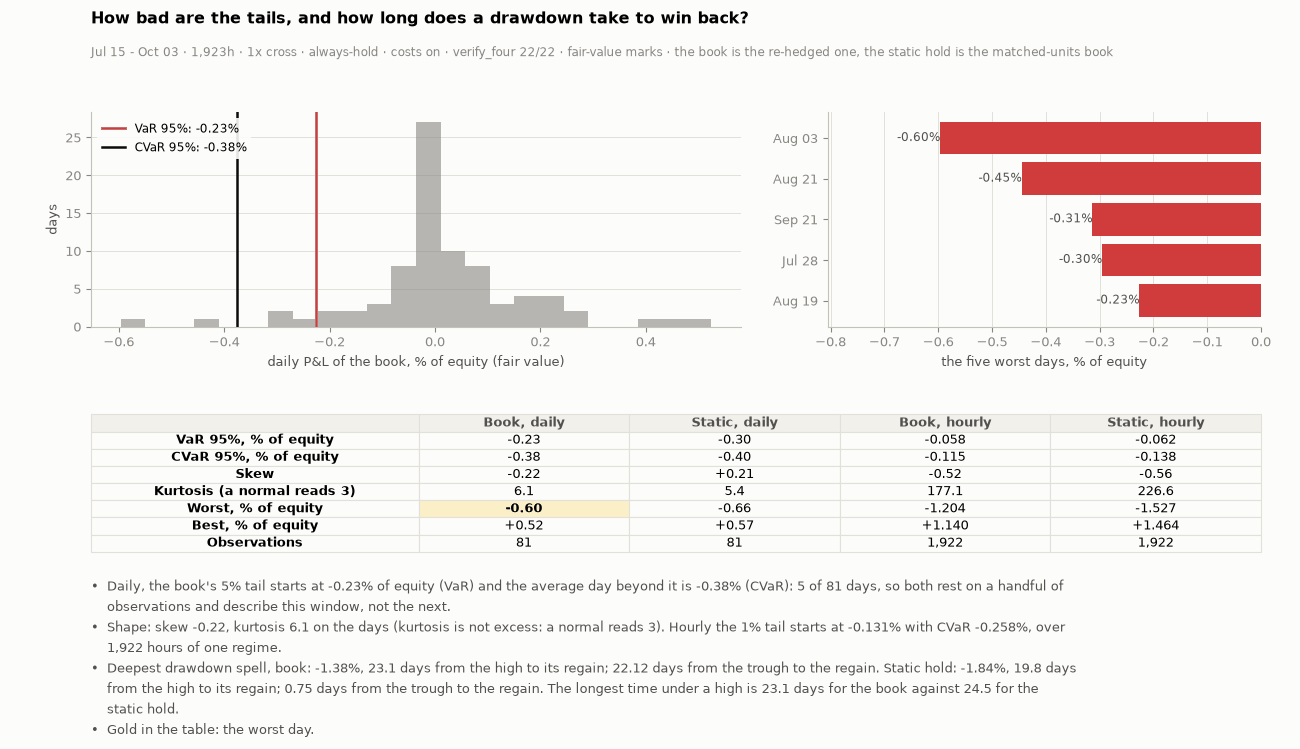

In [20]:
# ---- 3d. the tails and the time to win a drawdown back, next to the drawdown chart: the book and the static hold, on the fair-value mark ----
fvp = lambda r_: pd.Series(np.asarray(r_["series"]["total_pnl_fv"], float), index=df.index)
TAIL, SPELL = {}, {}
for nm_, r_x in (("the book", res), ("static hold", STATIC)):
    p_ = fvp(r_x); dly_ = daily_cum(p_) / EQUITY * 100.0; hr_ = p_.diff().dropna() / EQUITY * 100.0
    TAIL[nm_] = {"daily": ST.tail_stats(list(dly_.values)), "hourly": ST.tail_stats(list(hr_.values)), "hourly99": ST.tail_stats(list(hr_.values), 0.99), "days": dly_}
    e_ = EQUITY + p_
    SPELL[nm_] = ST.drawdown_spells(list(e_.values), list(e_.index.to_pydatetime()))
    TAIL[nm_]["max_dd_days"] = ST.max_dd_days(list(e_.values), list(e_.index.to_pydatetime())); TAIL[nm_]["recovery_days"] = ST.recovery_days(list(e_.values), list(e_.index.to_pydatetime()))
_deep = lambda sp_: min(sp_, key=lambda s_: s_["depth"])
assert abs(_deep(SPELL["the book"])["depth"] * 100 - uw_fv.min()) < 1e-9, (_deep(SPELL["the book"])["depth"], uw_fv.min())          # the spells' deepest IS the chart's
assert abs(_deep(SPELL["static hold"])["depth"] * 100 - uw_fv.min()) > 1e-6          # broken on purpose: the other book's spells must NOT match, so the check can fail
TB, TS = TAIL["the book"], TAIL["static hold"]
W5 = TB["days"].nsmallest(5)
KB = int((TB["days"] <= TB["daily"]["VaR 95%"]).sum())
dpB = _deep(SPELL["the book"]); dpS = _deep(SPELL["static hold"])
IDXD = df.index
spell_txt = lambda sp_: (f"{sp_['depth'] * 100:.2f}%, {sp_['days']:.1f} days from the high to its regain" if sp_["end_i"] is not None else f"{sp_['depth'] * 100:.2f}%, not regained by the last hour")
rec_txt = lambda sp_: (f"{sp_['recovery_days']:.2f} days from the trough to the regain" if sp_["recovery_days"] is not None else "not regained")
BUL = [f"Daily, the book's 5% tail starts at {TB['daily']['VaR 95%']:+.2f}% of equity (VaR) and the average day beyond it is {TB['daily']['CVaR 95%']:+.2f}% (CVaR): {KB} of {TB['daily']['n']} days, so both rest on a handful of observations and describe this window, not the next.",
       f"Shape: skew {TB['daily']['skew']:+.2f}, kurtosis {TB['daily']['kurtosis']:.1f} on the days (kurtosis is not excess: a normal reads 3). Hourly the 1% tail starts at {TB['hourly99']['VaR 99%']:+.3f}% with CVaR {TB['hourly99']['CVaR 99%']:+.3f}%, over {TB['hourly']['n']:,} hours of one regime.",
       f"Deepest drawdown spell, book: {spell_txt(dpB)}; {rec_txt(dpB)}. Static hold: {spell_txt(dpS)}; {rec_txt(dpS)}. The longest time under a high is {TB['max_dd_days']:.1f} days for the book against {TS['max_dd_days']:.1f} for the static hold.",
       "Gold in the table: the worst day."]
fig, gs, ax, axt = figstyle.fig_tab(5.6, (2.5, 1.6), top=0.80, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); sg3 = gs[0].subgridspec(1, 2, width_ratios=[1.5, 1], wspace=0.16); a1, a2 = fig.add_subplot(sg3[0]), fig.add_subplot(sg3[1])
a1.hist(TB["days"], bins=24, color=MUTED, alpha=0.6, zorder=3)
a1.axvline(TB["daily"]["VaR 95%"], color=CRIT, linewidth=1.8, zorder=5, label=f"VaR 95%: {TB['daily']['VaR 95%']:+.2f}%"); a1.axvline(TB["daily"]["CVaR 95%"], color=INK, linewidth=1.8, zorder=5, label=f"CVaR 95%: {TB['daily']['CVaR 95%']:+.2f}%")
a1.set_xlabel("daily P&L of the book, % of equity (fair value)"); a1.set_ylabel("days"); a1.legend(loc="upper left", fontsize=8.5, **LEG); a1.grid(axis="x", visible=False)
a2.barh([f"{d_:%b %d}" for d_ in W5.index][::-1], list(W5.values)[::-1], color=CRIT, zorder=3); a2.set_xlabel("the five worst days, % of equity"); a2.grid(axis="y", visible=False)
for y_, v_ in enumerate(list(W5.values)[::-1]):
    a2.text(v_, y_, f" {v_:+.2f}%", va="center", ha="right", fontsize=8.5, color=INK2)
a2.set_xlim(min(W5.values) * 1.35, 0)
fig.suptitle("How bad are the tails, and how long does a drawdown take to win back?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · verify_four {NCHK}/{NCHK} · fair-value marks · the book is the re-hedged one, the static hold is the matched-units book", color=MUTED, fontsize=8.5)
fm_t = lambda s_, k_, d_=2: f"{s_[k_]:+.{d_}f}"
cells = [["VaR 95%, % of equity"] + [fm_t(TB["daily"], "VaR 95%"), fm_t(TS["daily"], "VaR 95%"), fm_t(TB["hourly"], "VaR 95%", 3), fm_t(TS["hourly"], "VaR 95%", 3)],
         ["CVaR 95%, % of equity"] + [fm_t(TB["daily"], "CVaR 95%"), fm_t(TS["daily"], "CVaR 95%"), fm_t(TB["hourly"], "CVaR 95%", 3), fm_t(TS["hourly"], "CVaR 95%", 3)],
         ["Skew"] + [fm_t(s_[g_], "skew") for g_ in ("daily", "hourly") for s_ in (TB, TS)],
         ["Kurtosis (a normal reads 3)"] + [f"{s_[g_]['kurtosis']:.1f}" for g_ in ("daily", "hourly") for s_ in (TB, TS)],
         ["Worst, % of equity"] + [fm_t(s_[g_], "worst", 2 if g_ == "daily" else 3) for g_ in ("daily", "hourly") for s_ in (TB, TS)],
         ["Best, % of equity"] + [fm_t(s_[g_], "best", 2 if g_ == "daily" else 3) for g_ in ("daily", "hourly") for s_ in (TB, TS)],
         ["Observations"] + [f"{s_[g_]['n']:,}" for g_ in ("daily", "hourly") for s_ in (TB, TS)]]
tb = figstyle.put_table(axt, cells, ["", "Book, daily", "Static, daily", "Book, hourly", "Static, hourly"], size=9.5, first=0.28)
figstyle.gold(tb, 5, 1)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-tails", FIGURES)
ST3["tail"] = {"book": {k_: v_ for k_, v_ in TB.items() if k_ not in ("days",)}, "static": {k_: v_ for k_, v_ in TS.items() if k_ not in ("days",)},
               "worst5": {f"{d_:%Y-%m-%d}": float(v_) for d_, v_ in W5.items()}, "deepest_book": {"depth_pct": dpB["depth"] * 100, "days": dpB["days"], "recovery_days": dpB["recovery_days"]},
               "deepest_static": {"depth_pct": dpS["depth"] * 100, "days": dpS["days"], "recovery_days": dpS["recovery_days"]}, "n_spells_book": len(SPELL["the book"])}

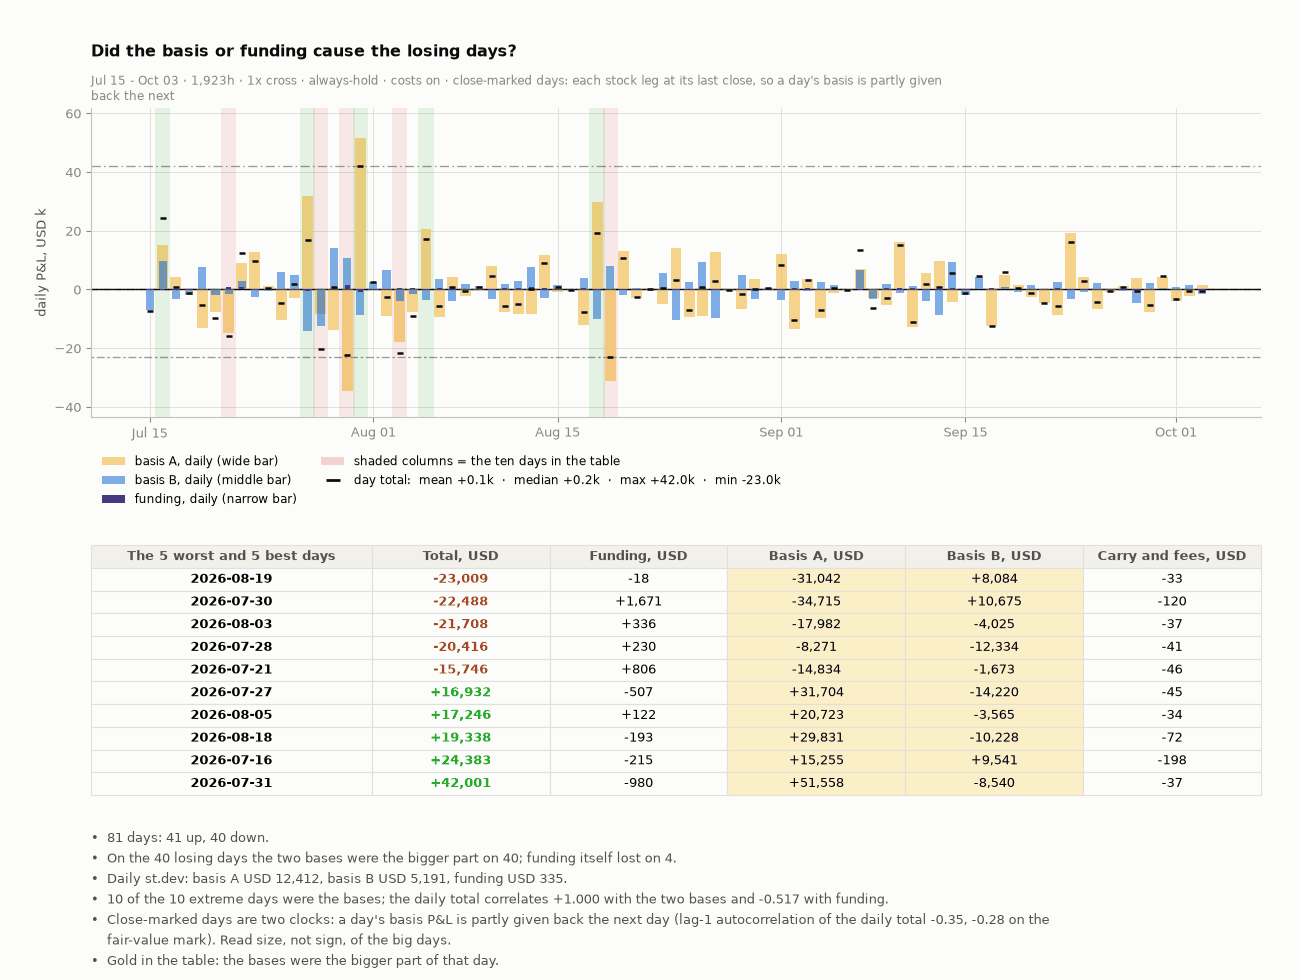

RISK {'vol': 3.1600890732252633, 'sharpe': 1.6515153022720557, 'sharpe_excess': 0.3509190517349677, 'sortino': 2.4635544844249475, 'calmar': 3.812054028836159, 'n_days': 81, 'lag1_autocorr': -0.34503322685757404, 'lag1_autocorr_fv': -0.2809861459106936}


In [21]:
# ---- 4. Did funding or the basis cause the losing days? the daily bars, each source on its own width, then the extreme days ----
D2 = DAY.copy(); D2["basis_A"], D2["basis_B"] = DB["basis_A"], DB["basis_B"]
D2["carry_all"] = D2["carry"]
assert float((D2["funding"] + D2["basis_A"] + D2["basis_B"] + D2["carry_all"] - D2["total"]).abs().max()) < 1e-6
EXT = pd.concat([D2.nsmallest(5, "total"), D2.nlargest(5, "total")]).sort_values("total")
loss = D2[D2["total"] < 0]
basis_big = int(((loss["basis_A"] + loss["basis_B"]).abs() > loss["funding"].abs()).sum())
basis_ext = int(((EXT["basis_A"] + EXT["basis_B"]).abs() > EXT["funding"].abs()).sum())
bs = D2["basis_A"] + D2["basis_B"]
H4 = 9.8
fig = plt.figure(figsize=(13, H4))
bm = figstyle.bullets(fig, [f"{len(D2)} days: {(D2['total'] > 0).sum()} up, {len(loss)} down.",
                            f"On the {len(loss)} losing days the two bases were the bigger part on {basis_big}; funding itself lost on {int((loss['funding'] < 0).sum())}.",
                            f"Daily st.dev: basis A USD {D2['basis_A'].std():,.0f}, basis B USD {D2['basis_B'].std():,.0f}, funding USD {D2['funding'].std():,.0f}.",
                            f"{basis_ext} of the {len(EXT)} extreme days were the bases; the daily total correlates {D2['total'].corr(bs):+.3f} with the two bases and {D2['total'].corr(D2['funding']):+.3f} with funding.",
                            f"Close-marked days are two clocks: a day's basis P&L is partly given back the next day (lag-1 autocorrelation of the daily total {r_['daily_lag1_autocorr']:+.2f}, {r_['daily_lag1_autocorr_fv']:+.2f} on the fair-value mark). Read size, not sign, of the big days.",
                            "Gold in the table: the bases were the bigger part of that day."])
gs = fig.add_gridspec(2, 1, height_ratios=[2.6, 2.1], hspace=0.46, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
x = D2.index
for d_, rr in EXT.iterrows():
    ax.axvspan(d_ - pd.Timedelta(hours=14), d_ + pd.Timedelta(hours=14), color=(CRIT if rr["total"] < 0 else GOOD), alpha=0.10, linewidth=0, zorder=1)
ax.bar(x, D2["basis_A"] / 1e3, width=pd.Timedelta(hours=20), color=C_A, alpha=0.45, zorder=3)
ax.bar(x, D2["basis_B"] / 1e3, width=pd.Timedelta(hours=15), color=C_B, alpha=0.6, zorder=4)
ax.bar(x, D2["funding"] / 1e3, width=pd.Timedelta(hours=9), color=C_NET, zorder=5)
ax.scatter(x, D2["total"] / 1e3, s=20, marker="_", color=INK, linewidths=1.8, zorder=6)
tt = D2["total"] / 1e3
for k, y in (("mean", tt.mean()), ("median", tt.median()), ("max", tt.max()), ("min", tt.min())):
    ax.axhline(y, color=INK, linewidth=0.95, linestyle=LSf[k], alpha=0.4, zorder=2)
ax.axhline(0, color=INK, linewidth=1, zorder=2)
_h = [Patch(facecolor=C_A, alpha=0.45, label="basis A, daily (wide bar)"), Patch(facecolor=C_B, alpha=0.6, label="basis B, daily (middle bar)"), Patch(facecolor=C_NET, label="funding, daily (narrow bar)"),
      Patch(facecolor=CRIT, alpha=0.2, label="shaded columns = the ten days in the table"),
      plt.Line2D([], [], color=INK, marker="_", markersize=10, markeredgewidth=2, linestyle="none", label=f"day total:  mean {tt.mean():+.1f}k  ·  median {tt.median():+.1f}k  ·  max {tt.max():+.1f}k  ·  min {tt.min():+.1f}k")]
ax.set_ylabel("daily P&L, USD k"); ax.legend(handles=_h, loc="upper left", bbox_to_anchor=(0.0, -0.09), ncol=2, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylim(min(tt.min(), (D2["basis_A"] / 1e3).min()) * 1.25, max(tt.max(), (D2["basis_A"] / 1e3).max()) * 1.2)
ask(ax, "Did the basis or funding cause the losing days?", f"{WSH} · close-marked days: each stock leg at its last close, so a day's basis is partly given back the next")
cells = [[f"{d:%Y-%m-%d}", f"{rr['total']:+,.0f}", f"{rr['funding']:+,.0f}", f"{rr['basis_A']:+,.0f}", f"{rr['basis_B']:+,.0f}", f"{rr['carry_all']:+,.0f}"] for d, rr in EXT.iterrows()]
tb = figstyle.put_table(axt, cells, ["The 5 worst and 5 best days", "Total, USD", "Funding, USD", "Basis A, USD", "Basis B, USD", "Carry and fees, USD"], size=9.5, first=0.24)
for r_i in range(1, len(EXT) + 1):
    row = EXT.iloc[r_i - 1]
    tb[(r_i, 1)].set_text_props(color=(GOOD if row["total"] > 0 else CRIT), weight="bold")
    if abs(row["basis_A"] + row["basis_B"]) > abs(row["funding"]):
        figstyle.tint(tb, r_i, 3, "gold"); figstyle.tint(tb, r_i, 4, "gold")
figstyle.show(fig, "fig:s3-daily", FIGURES)
ST3["daily"] = {"days": len(D2), "up": int((D2['total'] > 0).sum()), "down": len(loss), "basis_bigger_on_losing": basis_big, "n_ext": len(EXT), "basis_ext": basis_ext,
                  "corr_basis": float(D2['total'].corr(bs)), "corr_fund": float(D2['total'].corr(D2['funding'])), "std_A": float(D2['basis_A'].std()), "std_B": float(D2['basis_B'].std()), "std_fund": float(D2['funding'].std())}
from fundplat.quant.core import stats as ST
_dr = list((FVD / EQUITY).values)                    # the card's risk numbers (vol, Sharpe, Sortino): the daily total on the FAIR-VALUE mark, as the return and the drawdown are
ST3["risk"] = {"vol": float(np.std(_dr, ddof=1) * np.sqrt(365) * 100), "sharpe": float(ST.sharpe(_dr, 365)), "sharpe_excess": float(ST.sharpe([x_ - HURDLE_PCT / 100 / 365 for x_ in _dr], 365)), "sortino": float(ST.sortino(_dr, 365)), "calmar": float(calmar), "n_days": len(_dr),
                 "lag1_autocorr": float(r_["daily_lag1_autocorr"]), "lag1_autocorr_fv": float(r_["daily_lag1_autocorr_fv"])}
print("RISK", ST3["risk"], flush=True)

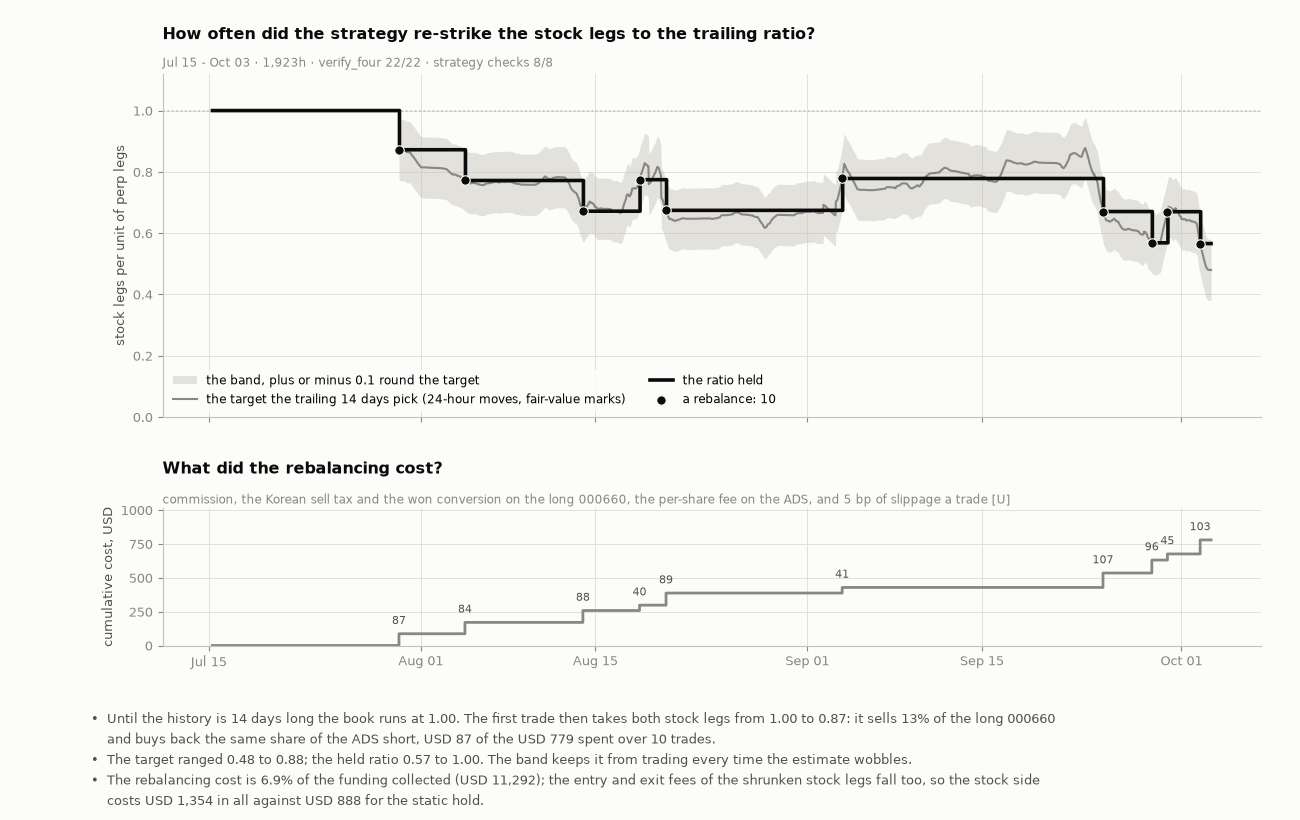

In [22]:
# ---- 3e. how the strategy re-hedged: the ratio held against the target, and what each trade cost ----
EV3 = res["rehedge"]["events"]
IDX3 = pd.to_datetime(res["series"]["time"], unit="ms", utc=True)
fig, (b0, b1) = plt.subplots(2, 1, figsize=(13, 8.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
tg_ = pd.Series(res["series"]["target_ratio"], IDX3); hd_ = pd.Series(res["series"]["held_ratio"], IDX3)
b0.fill_between(IDX3, tg_ - SYS_BAND, tg_ + SYS_BAND, color=AXIS, alpha=0.45, linewidth=0, zorder=1, label=f"the band, plus or minus {SYS_BAND:g} round the target")
b0.plot(IDX3, tg_, color=MUTED, linewidth=1.5, zorder=4, label=f"the target the trailing {SYS_W_D} days pick ({SYS_H_H}-hour moves, fair-value marks)")
b0.step(IDX3, hd_, where="post", color=INK, linewidth=2.6, zorder=5, label="the ratio held")
b0.scatter([IDX3[e_["i"]] for e_ in EV3], [e_["to"] for e_ in EV3], s=46, color=INK, zorder=6, edgecolors=SURF, linewidths=0.8, label=f"a rebalance: {len(EV3)}")
b0.axhline(1.0, color=AXIS, linewidth=1.2, linestyle=":", zorder=1)
b0.set_ylabel("stock legs per unit of perp legs"); b0.set_ylim(0, 1.12); b0.legend(loc="lower left", fontsize=8.5, ncol=2, **LEG)
ask(b0, "How often did the strategy re-strike the stock legs to the trailing ratio?", f"{WS} · verify_four {NCHK}/{NCHK} · strategy checks {SYS_NCHK}/{SYS_NCHK}")
cum_ = pd.Series(res["series"]["cum_rebalance_cost"], IDX3)
b1.step(IDX3, cum_, where="post", color=C_COST, linewidth=2.0)
for e_ in EV3:
    b1.annotate(f"{e_['cost']:,.0f}", (IDX3[e_["i"]], cum_.iloc[e_["i"]]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=INK2)
b1.set_ylabel("cumulative cost, USD"); b1.set_ylim(0, max(cum_.iloc[-1], 1.0) * 1.3); b1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(b1, "What did the rebalancing cost?", f"commission, the Korean sell tax and the won conversion on the long 000660, the per-share fee on the ADS, and {SYS_SLIP_BPS:g} bp of slippage a trade [U]")
cost_share = res["rehedge"]["rebal_cost"] / res["funding_net"] * 100
finish(fig, [f"Until the history is {SYS_W_D} days long the book runs at 1.00. The first trade then takes both stock legs from 1.00 to {EV3[0]['to']:.2f}: it sells {(1 - EV3[0]['to']) * 100:.0f}% of the long 000660 and buys back the same share of the ADS short, USD {EV3[0]['cost']:,.0f} of the USD {res['rehedge']['rebal_cost']:,.0f} spent over {len(EV3)} trades.",
             f"The target ranged {np.nanmin(tg_):.2f} to {np.nanmax(tg_):.2f}; the held ratio {res['rehedge']['rho_min']:.2f} to {res['rehedge']['rho_max']:.2f}. The band keeps it from trading every time the estimate wobbles.",
             f"The rebalancing cost is {cost_share:.1f}% of the funding collected (USD {res['funding_net']:,.0f}); the entry and exit fees of the shrunken stock legs fall too, so the stock side costs USD {res['stock_costs']:,.0f} in all against USD {STATIC['stock_costs']:,.0f} for the static hold."], top=0.91, hspace=0.38, right=0.97)
figstyle.show(fig, "fig:s3-ratio", FIGURES)
ST3["rehedge"] = {"n": len(EV3), "cost": res["rehedge"]["rebal_cost"], "cost_share_of_funding": cost_share, "first_to": EV3[0]["to"], "target_min": float(np.nanmin(tg_)), "target_max": float(np.nanmax(tg_)),
                  "rho_min": res["rehedge"]["rho_min"], "rho_max": res["rehedge"]["rho_max"], "stock_costs": res["stock_costs"], "stock_costs_static": STATIC["stock_costs"]}

## S4 · Robustness

Is it real: out of sample, statistically significant, after costs? Then: does an exit rule help, how much is the entry hour, and what does the hedge rule add over the static hold?

In [23]:
from matplotlib.patches import Patch
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
def foot(fig, *lines):
    figstyle.bullets(fig, [t for t in lines if t])

ST4 = {"hours": int(res["n_hours"])}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · 1x cross · reserve 0 · costs on"
DAY = DAYS_[BOOK]
G1a = bool(carry_ann(res) > HURDLE_PCT)
carry_cum = lambda d: (num(d["cum_funding_net"]) - num(d["cum_financing"]) - num(d["cum_stock_costs"]) - num(d["cum_perp_fees"]) + num(d["cum_dividends"])) / 1e3
tcum = lambda d: EQUITY * p1.hurdle_ann * np.asarray((d.index - d.index[0]).total_seconds()) / (365 * 86400) / 1e3

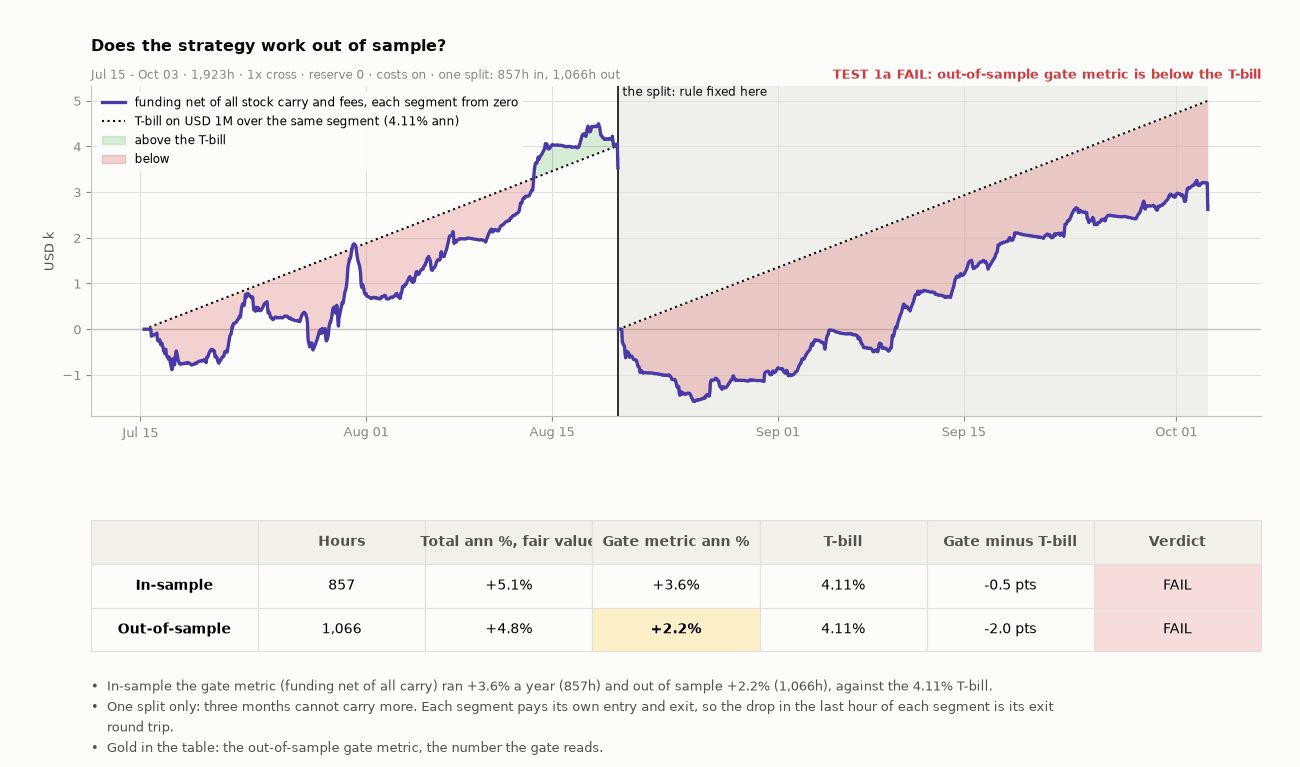

In [24]:
# ---- Test 1a: out of sample ----
rows_in = [r for r in rows if r["time"] < SPLIT]; rows_out = [r for r in rows if r["time"] >= SPLIT]
SEG = {}
for nm_, rw_ in (("in", rows_in), ("out", rows_out)):
    r_ = run4(rw_, PAR[BOOK]); vfour(r_, rw_, f"walk-forward {nm_}"); SEG[nm_] = r_
r_in, r_out = SEG["in"], SEG["out"]
G2a = bool(carry_ann(r_out) > HURDLE_PCT)
d_in, d_out = frame(r_in), frame(r_out)
BUL = [f"In-sample the gate metric (funding net of all carry) ran {carry_ann(r_in):+.1f}% a year ({r_in['n_hours']:,}h) and out of sample {carry_ann(r_out):+.1f}% ({r_out['n_hours']:,}h), against the {HURDLE_PCT:.2f}% T-bill.",
       "One split only: three months cannot carry more. Each segment pays its own entry and exit, so the drop in the last hour of each segment is its exit round trip.",
       "Gold in the table: the out-of-sample gate metric, the number the gate reads."]
fig, gs, ax, axt = fig_tab(6.6, (2.9, 1.15), nb=figstyle.nlines(BUL))
split_ts = pd.Timestamp(SPLIT, unit="ms", tz="UTC")
ax.axvspan(split_ts, d_out.index[-1], color=AXIS, alpha=0.22, linewidth=0, zorder=0)
for d in (d_in, d_out):
    f_, t_ = carry_cum(d), pd.Series(tcum(d), index=d.index)
    ax.plot(d.index, f_, color=C_NET, linewidth=2.4, zorder=4); ax.plot(d.index, t_, color=INK, linewidth=1.5, linestyle=":", zorder=3)
    ax.fill_between(d.index, f_, t_, where=(f_ >= t_), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
    ax.fill_between(d.index, f_, t_, where=(f_ < t_), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axvline(split_ts, color=INK, linewidth=1.2, zorder=3); ax.text(split_ts, ax.get_ylim()[1], " the split: rule fixed here", color=INK, fontsize=8.5, va="top")
ax.plot([], [], color=C_NET, linewidth=2.4, label="funding net of all stock carry and fees, each segment from zero")
ax.plot([], [], color=INK, linewidth=1.5, linestyle=":", label=f"T-bill on {usdm(EQUITY)} over the same segment ({HURDLE_PCT:.2f}% ann)")
ax.fill_between([], [], color=GOOD, alpha=0.16, label="above the T-bill"); ax.fill_between([], [], color=CRIT, alpha=0.22, label="below")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("USD k"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.text(1.0, 1.012, ("TEST 1a PASS: out-of-sample gate metric is above the T-bill" if G2a else "TEST 1a FAIL: out-of-sample gate metric is below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G2a else CRIT), fontsize=9.5, fontweight="bold")
ask(ax, "Does the strategy work out of sample?", f"{WSB} · one split: {r_in['n_hours']:,}h in, {r_out['n_hours']:,}h out")
cells = [[nm, f"{r_['n_hours']:,}", f"{eq_ann(r_):+.1f}%", f"{carry_ann(r_):+.1f}%", f"{HURDLE_PCT:.2f}%", f"{carry_ann(r_) - HURDLE_PCT:+.1f} pts", ("PASS" if carry_ann(r_) > HURDLE_PCT else "FAIL")]
         for nm, r_ in (("In-sample", r_in), ("Out-of-sample", r_out))]
tb = put_table(axt, cells, ["", "Hours", "Total ann %, fair value", "Gate metric ann %", "T-bill", "Gate minus T-bill", "Verdict"])
gold(tb, 2, 3)
for r_i in (1, 2): tint(tb, r_i, 6, "green" if cells[r_i - 1][6] == "PASS" else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-oos", FIGURES)
ST4["oos"] = {"in": {"hours": r_in["n_hours"], "ann": eq_ann(r_in), "gate": carry_ann(r_in)}, "out": {"hours": r_out["n_hours"], "ann": eq_ann(r_out), "gate": carry_ann(r_out)}, "pass": G2a}

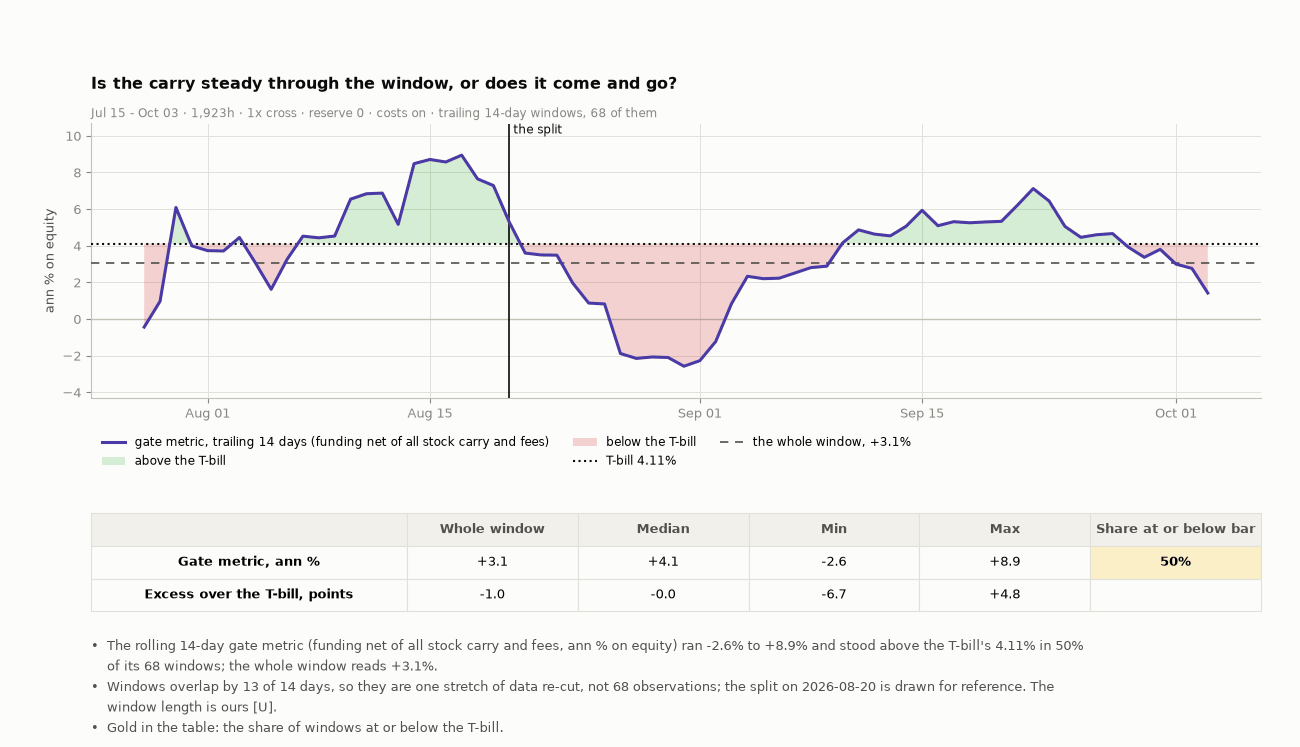

In [25]:
# ---- Test 1a, beside the split: is the carry steady through the window, or does it sit in one stretch? (the chart bank's rolling-statistics type, one panel: this notebook has no beta to roll) ----
GMD = DAY["funding_net_carry"]                                            # the gate metric, USD a day: the series Test 1b and the base test read
ROLL = (GMD.rolling(ROLL_D).sum() / ROLL_D * 365.0 / EQUITY * 100.0).dropna()      # funding net of all stock carry and fees, ann % on equity, over the trailing ROLL_D days
GFULL = carry_ann(res)
assert abs(GMD.sum() / EQUITY * 100.0 / res["days"] * 365.0 - GFULL) < 0.05, (GMD.sum(), GFULL)    # the daily series IS the gate metric the base test reads
n_roll = int(len(ROLL)); up_roll = float((ROLL > HURDLE_PCT).mean() * 100)
ROLLSTAT = {"median": float(ROLL.median()), "min": float(ROLL.min()), "max": float(ROLL.max()), "below": float((ROLL <= HURDLE_PCT).mean() * 100)}
BUL = [f"The rolling {ROLL_D}-day gate metric (funding net of all stock carry and fees, ann % on equity) ran {ROLLSTAT['min']:+.1f}% to {ROLLSTAT['max']:+.1f}% and stood above the T-bill's {HURDLE_PCT:.2f}% in {up_roll:.0f}% of its {n_roll} windows; the whole window reads {GFULL:+.1f}%.",
       f"Windows overlap by {ROLL_D - 1} of {ROLL_D} days, so they are one stretch of data re-cut, not {n_roll} observations; the split on {SPLIT_DATE} is drawn for reference. The window length is ours [U].",
       "Gold in the table: the share of windows at or below the T-bill."]
fig, gs, ax, axt = fig_tab(6.2, (2.8, 1.0), top=0.80, hspace=0.62, nb=figstyle.nlines(BUL))
ax.plot(ROLL.index, ROLL, color=C_NET, linewidth=2.2, zorder=4, label=f"gate metric, trailing {ROLL_D} days (funding net of all stock carry and fees)")
ax.fill_between(ROLL.index, ROLL, HURDLE_PCT, where=(ROLL >= HURDLE_PCT), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2, label="above the T-bill")
ax.fill_between(ROLL.index, ROLL, HURDLE_PCT, where=(ROLL < HURDLE_PCT), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2, label="below the T-bill")
ax.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=3, label=f"T-bill {HURDLE_PCT:.2f}%")
ax.axhline(GFULL, color=INK2, linestyle=LSf["mean"], linewidth=1.2, zorder=3, label=f"the whole window, {GFULL:+.1f}%")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
figstyle.yfit(ax, [ROLL, pd.Series([HURDLE_PCT, GFULL])], pad=0.15)
ax.axvline(split_ts, color=INK, linewidth=1.2, zorder=3); ax.text(split_ts, ax.get_ylim()[1], " the split", color=INK, fontsize=8.5, va="top")
ax.set_ylabel("ann % on equity"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=3, fontsize=8.5, frameon=False)
ask(ax, "Is the carry steady through the window, or does it come and go?", f"{WSB} · trailing {ROLL_D}-day windows, {n_roll} of them")
cells = [["Gate metric, ann %", f"{GFULL:+.1f}", f"{ROLLSTAT['median']:+.1f}", f"{ROLLSTAT['min']:+.1f}", f"{ROLLSTAT['max']:+.1f}", f"{ROLLSTAT['below']:.0f}%"],
         ["Excess over the T-bill, points", f"{GFULL - HURDLE_PCT:+.1f}", f"{ROLLSTAT['median'] - HURDLE_PCT:+.1f}", f"{ROLLSTAT['min'] - HURDLE_PCT:+.1f}", f"{ROLLSTAT['max'] - HURDLE_PCT:+.1f}", ""]]
tb = put_table(axt, cells, ["", "Whole window", "Median", "Min", "Max", "Share at or below bar"], size=9.5, first=0.27)
gold(tb, 1, 5)
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-rolling-carry", FIGURES)
ST4["rolling"] = {"window_d": ROLL_D, "n": n_roll, "full": GFULL, "median": ROLLSTAT["median"], "min": ROLLSTAT["min"], "max": ROLLSTAT["max"], "share_above_pct": up_roll, "share_at_or_below_pct": ROLLSTAT["below"]}

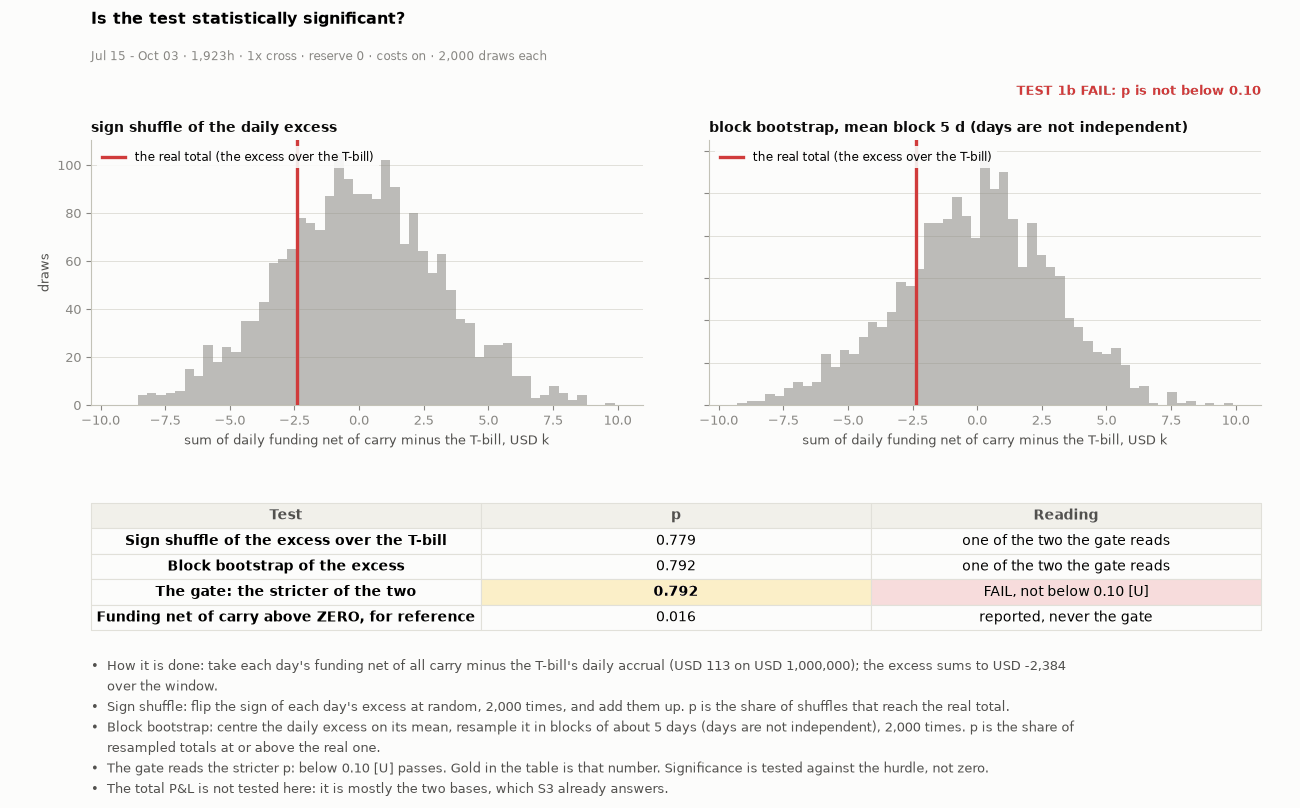

In [26]:
# ---- Test 1b: luck, against the hurdle ----
v = DAY["funding_net_carry"].values
HURDLE_DAY = p1.hurdle_ann * EQUITY / 365.0
ex_ = v - HURDLE_DAY
sh_ = (np.abs(ex_) * np.random.default_rng(SEED + 1).choice([-1.0, 1.0], size=(NSHUF, len(ex_)))).sum(axis=1)
p_sign = float((sh_ >= ex_.sum()).mean())
bt_ = ST.bootstrap_p_one_sided(ex_, BOOT_BLOCK_D, NSHUF, np.random.default_rng(SEED + 2))
sh0 = (np.abs(v) * np.random.default_rng(SEED).choice([-1.0, 1.0], size=(NSHUF, len(v)))).sum(axis=1)
p_zero = float((sh0 >= v.sum()).mean())
p_gate = max(p_sign, bt_["p"]); G2b = bool(p_gate < 0.10)
BUL = [f"How it is done: take each day's funding net of all carry minus the T-bill's daily accrual (USD {HURDLE_DAY:,.0f} on USD {EQUITY:,.0f}); the excess sums to USD {ex_.sum():+,.0f} over the window.",
       f"Sign shuffle: flip the sign of each day's excess at random, {NSHUF:,} times, and add them up. p is the share of shuffles that reach the real total.",
       f"Block bootstrap: centre the daily excess on its mean, resample it in blocks of about {BOOT_BLOCK_D} days (days are not independent), {NSHUF:,} times. p is the share of resampled totals at or above the real one.",
       "The gate reads the stricter p: below 0.10 [U] passes. Gold in the table is that number. Significance is tested against the hurdle, not zero.",
       "The total P&L is not tested here: it is mostly the two bases, which S3 already answers."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 1.3), top=0.78, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); a1, a2 = fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[0]), fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[1])
allv = np.r_[sh_, np.asarray(bt_["sums"]), ex_.sum()] / 1e3; lo_, hi_ = allv.min(), allv.max(); pad = (hi_ - lo_) * 0.06
for a_, null, ttl in ((a1, sh_ / 1e3, "sign shuffle of the daily excess"), (a2, np.asarray(bt_["sums"]) / 1e3, f"block bootstrap, mean block {BOOT_BLOCK_D} d (days are not independent)")):
    a_.hist(null, bins=np.linspace(lo_ - pad, hi_ + pad, 60), color=MUTED, alpha=0.55, zorder=3)
    a_.axvline(ex_.sum() / 1e3, color=GOOD if ex_.sum() > 0 else CRIT, linewidth=2.4, zorder=5, label="the real total (the excess over the T-bill)")
    a_.set_title(ttl, fontsize=10, loc="left", pad=6); a_.set_xlabel("sum of daily funding net of carry minus the T-bill, USD k"); a_.legend(loc="upper left", fontsize=8.5, **LEG); a_.grid(axis="x", visible=False)
    a_.set_xlim(lo_ - pad, hi_ + pad)
a1.set_ylabel("draws"); a2.tick_params(labelleft=False)
a1.text(1.0, 1.16, ("TEST 1b PASS: p below 0.10 on both" if G2b else "TEST 1b FAIL: p is not below 0.10"), transform=a2.transAxes, ha="right", va="bottom", color=(GOOD if G2b else CRIT), fontsize=9.5, fontweight="bold")
fig.suptitle("Is the test statistically significant?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB} · {NSHUF:,} draws each", color=MUTED, fontsize=8.5)
cells = [["Sign shuffle of the excess over the T-bill", f"{p_sign:.3f}", "one of the two the gate reads"], ["Block bootstrap of the excess", f"{bt_['p']:.3f}", "one of the two the gate reads"],
         ["The gate: the stricter of the two", f"{p_gate:.3f}", ("PASS, below 0.10 [U]" if G2b else "FAIL, not below 0.10 [U]")], ["Funding net of carry above ZERO, for reference", f"{p_zero:.3f}", "reported, never the gate"]]
tb = put_table(axt, cells, ["Test", "p", "Reading"])
gold(tb, 3, 1); tint(tb, 3, 2, "green" if G2b else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-significance", FIGURES)
ST4["luck"] = {"p_sign": p_sign, "p_block": float(bt_["p"]), "p_gate": p_gate, "p_zero": p_zero, "excess_usd": float(ex_.sum()), "pass": G2b}

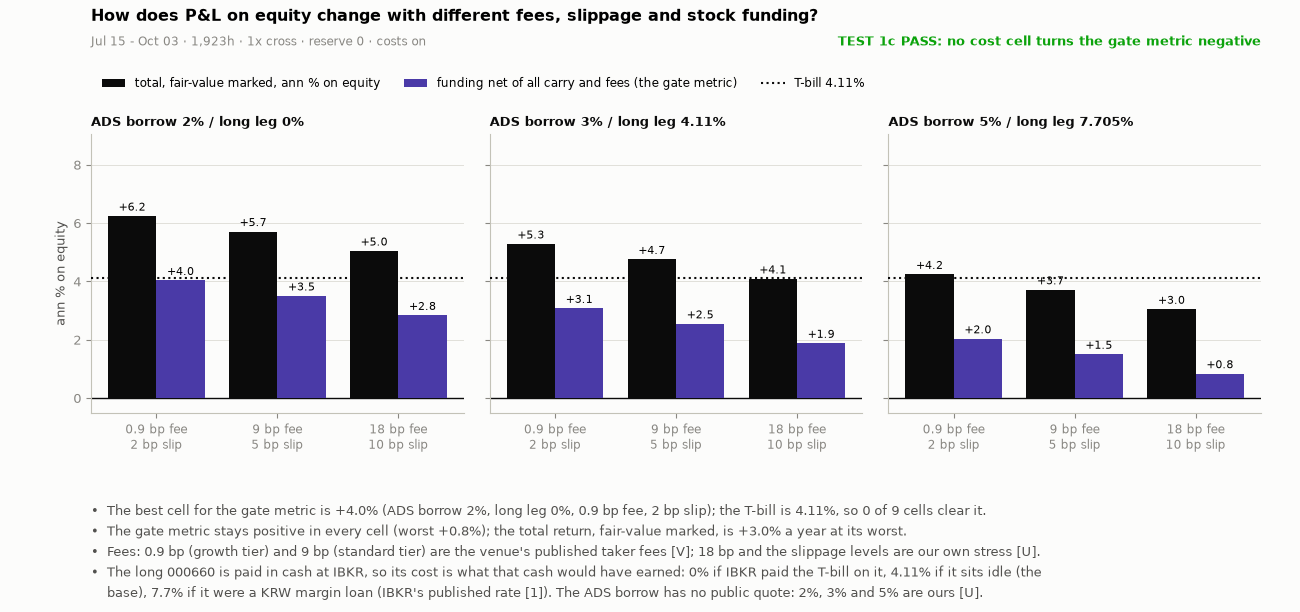

In [27]:
# ---- Test 1c: costs. Three stock-funding levels (ADS borrow / the long leg's cost) x three fee-and-slippage levels ----
FEES = ((refdata.XYZ_TAKER_BPS, 2.0, "growth-tier fee [V], 2 bp slip"), (refdata.XYZ_STANDARD_TAKER_BPS, 5.0, "standard fee [V], 5 bp slip"), (2 * refdata.XYZ_STANDARD_TAKER_BPS, 10.0, "2x standard fee, 10 bp slip [U]"))
FINS = ((0.02, 0.0), (0.03, refdata.HURDLE_ANN), (0.05, KRW_LOAN))      # cash earns the T-bill at IBKR | cash idle (the base) | a KRW margin loan at IBKR's published rate [1]
SW = {}
for b_, m_ in FINS:
    for f_, s_, _l in FEES:
        r_ = run4(rows, replace(PAR[BOOK], stock_fin_ann=m_, short_borrow_ann=b_, perp={"fee_taker_bps": f_, "exec_slippage_bps": s_}))
        vfour(r_, rows, f"cost sweep {f_:g}/{s_:g} {b_}/{m_}")
        assert (r_["fin_rates"]["short_borrow"], r_["fin_rates"]["long"]) == (b_, m_), r_["fin_rates"]
        SW[(b_, m_, f_, s_)] = r_
GATE = {k: carry_ann(r_) for k, r_ in SW.items()}; TOT = {k: eq_ann(r_) for k, r_ in SW.items()}
G2c = bool(min(GATE.values()) > 0)
n_clear = int(sum(v_ > HURDLE_PCT for v_ in GATE.values()))
kg = max(GATE, key=GATE.get); kw_ = min(TOT, key=TOT.get)
CB = [f"The best cell for the gate metric is {GATE[kg]:+.1f}% (ADS borrow {kg[0] * 100:g}%, long leg {kg[1] * 100:g}%, {kg[2]:g} bp fee, {kg[3]:g} bp slip); the T-bill is {HURDLE_PCT:.2f}%, so {n_clear} of {len(GATE)} cells clear it.",
      f"The gate metric stays " + ("positive" if G2c else "negative in at least one cell") + f" in every cell (worst {min(GATE.values()):+.1f}%); the total return, fair-value marked, is {TOT[kw_]:+.1f}% a year at its worst.",
      "Fees: 0.9 bp (growth tier) and 9 bp (standard tier) are the venue's published taker fees [V]; 18 bp and the slippage levels are our own stress [U].",
      "The long 000660 is paid in cash at IBKR, so its cost is what that cash would have earned: 0% if IBKR paid the T-bill on it, 4.11% if it sits idle (the base), 7.7% if it were a KRW margin loan (IBKR's published rate [1]). The ADS borrow has no public quote: 2%, 3% and 5% are ours [U]."]
H3x3 = 4.7 + figstyle.nlines(CB) * 0.205 + 0.4
fig, axs = plt.subplots(1, 3, figsize=(13, H3x3), sharey=True)
bm = figstyle.bullets(fig, CB)
for ax_, (b_, m_) in zip(axs, FINS):
    xs = np.arange(len(FEES)); vt = [TOT[(b_, m_, f_, s_)] for f_, s_, _ in FEES]; vg = [GATE[(b_, m_, f_, s_)] for f_, s_, _ in FEES]
    b1 = ax_.bar(xs - 0.2, vt, 0.4, color=INK, zorder=3); b2 = ax_.bar(xs + 0.2, vg, 0.4, color=C_NET, zorder=3)
    ax_.bar_label(b1, fmt="%+.1f", fontsize=8, padding=2); ax_.bar_label(b2, fmt="%+.1f", fontsize=8, padding=2)
    ax_.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=4); ax_.axhline(0, color=INK, linewidth=1)
    ax_.set_xticks(xs); ax_.set_xticklabels([f"{f_:g} bp fee\n{s_:g} bp slip" for f_, s_, _ in FEES], fontsize=8.5); ax_.grid(axis="x", visible=False)
    ax_.set_title(f"ADS borrow {b_ * 100:g}% / long leg {m_ * 100:g}%", fontsize=9.5, loc="left", pad=6)
axs[0].set_ylim(min(0, min(TOT.values()) * 1.4) - 0.5, max(max(GATE.values()), max(TOT.values()), HURDLE_PCT) * 1.45)
axs[0].set_ylabel("ann % on equity")
fig.legend(handles=[Patch(facecolor=INK, label="total, fair-value marked, ann % on equity"), Patch(facecolor=C_NET, label="funding net of all carry and fees (the gate metric)"), plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"T-bill {HURDLE_PCT:.2f}%")], loc="lower left", bbox_to_anchor=(0.07, 0.835), ncol=3, fontsize=8.5, frameon=False)
fig.suptitle("How does P&L on equity change with different fees, slippage and stock funding?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB}", color=MUTED, fontsize=8.5)
fig.text(0.97, 0.925, ("TEST 1c PASS: no cost cell turns the gate metric negative" if G2c else "TEST 1c FAIL: a cost cell turns the gate metric negative"), ha="right", color=(GOOD if G2c else CRIT), fontsize=9.5, fontweight="bold")
plt.subplots_adjust(top=0.78, bottom=bm + 0.75 / H3x3, left=0.07, right=0.97, wspace=0.07)
figstyle.show(fig, "fig:s4-costs", FIGURES)
# the borrow that WOULD clear the hurdle: the gate metric is linear in the borrow (asserted), then solved
BR = {}
for f_ in (0.005, 0.03, 0.30):
    r_ = run4(rows, replace(PAR[BOOK], short_borrow_ann=f_)); vfour(r_, rows, f"borrow {f_}"); BR[f_] = carry_ann(r_)
assert abs(BR[0.03] - carry_ann(res)) < 1e-9
k_brw = (BR[0.30] - BR[0.005]) / (0.30 - 0.005)
assert abs(BR[0.03] - (BR[0.005] + k_brw * (0.03 - 0.005))) < 1e-9          # linear in the borrow
f_star = 0.005 + (HURDLE_PCT - BR[0.005]) / k_brw
ST4["costs"] = {"best_gate": GATE[kg], "worst_total": TOT[kw_], "n_clear": n_clear, "n": len(GATE), "worst_gate": min(GATE.values()), "pass": G2c, "f_star_pct": f_star * 100, "borrow_slope_per_pct": k_brw / 100,
                  "cells": [{"borrow": b_, "margin": m_, "fee": f_, "slip": s_, "total": TOT[(b_, m_, f_, s_)], "gate": GATE[(b_, m_, f_, s_)]} for b_, m_ in FINS for f_, s_, _ in FEES]}

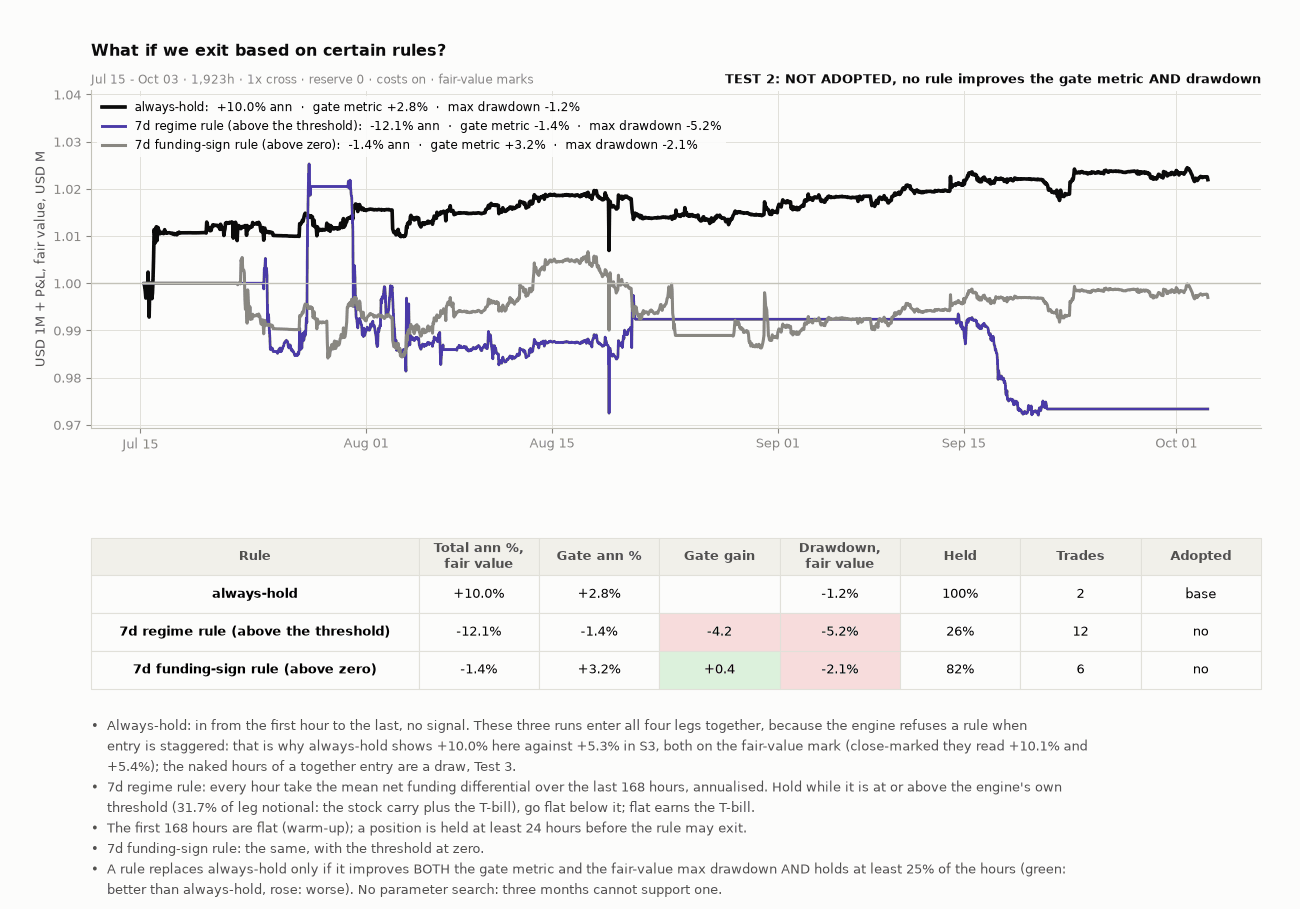

In [28]:
# ---- Test 2: a timing rule against always-hold (the engine refuses a rule when entry is staggered, so the three run together-entry) ----
RULES = {}
RULES["always-hold"] = run4(rows, replace(PAR[BOOK], entry_mode="together"))
for lab, kw in (("7d regime rule (above the threshold)", dict(regime=True)), ("7d funding-sign rule (above zero)", dict(regime=True, regime_threshold_ann=0.0))):
    r_ = run4(rows, replace(PAR[BOOK], entry_mode="together", **kw)); vfour(r_, rows, f"rule {lab}"); RULES[lab] = r_
base_ = RULES["always-hold"]
fvdd_of = lambda r_: float((lambda e_: (e_ / e_.cummax() - 1).min())(pd.Series(EQUITY + np.asarray(r_["series"]["total_pnl_fv"], float))))   # the FAIR-VALUE drawdown on the USD 1M of equity, a negative fraction: the mark of S3
ADOPT = [lab for lab, r_ in RULES.items() if lab != "always-hold" and carry_ann(r_) > carry_ann(base_) and fvdd_of(r_) > fvdd_of(base_) and r_["hold_share"] >= MIN_HOLD_SHARE]
THR = RULES["7d regime rule (above the threshold)"]["regime_threshold_ann_pct"]
BUL = [f"Always-hold: in from the first hour to the last, no signal. These three runs enter all four legs together, because the engine refuses a rule when entry is staggered: that is why always-hold shows {eq_ann(base_):+.1f}% here against {eq_ann(res):+.1f}% in S3, both on the fair-value mark (close-marked they read {eq_ann_close(base_):+.1f}% and {eq_ann_close(res):+.1f}%); the naked hours of a together entry are a draw, Test 3.",
       f"7d regime rule: every hour take the mean net funding differential over the last {p1.regime_warmup_h} hours, annualised. Hold while it is at or above the engine's own threshold ({THR:.1f}% of leg notional: the stock carry plus the T-bill), go flat below it; flat earns the T-bill.",
       f"The first {p1.regime_warmup_h} hours are flat (warm-up); a position is held at least {p1.min_hold_h} hours before the rule may exit.",
       "7d funding-sign rule: the same, with the threshold at zero.",
       f"A rule replaces always-hold only if it improves BOTH the gate metric and the fair-value max drawdown AND holds at least {MIN_HOLD_SHARE * 100:.0f}% of the hours (green: better than always-hold, rose: worse). No parameter search: three months cannot support one."]
fig, gs, ax, axt = fig_tab(7.0, (2.9, 1.3), nb=figstyle.nlines(BUL))
styles = {"always-hold": (INK, 2.6), "7d regime rule (above the threshold)": (C_NET, 2.0), "7d funding-sign rule (above zero)": (MUTED, 2.2)}      # ink, the funding colour (both rules read the funding differential), grey: three tell-apart colours
for lab, r_ in RULES.items():
    d_ = frame(r_); c_, lw_ = styles[lab]
    ax.plot(d_.index, (EQUITY + np.asarray(r_["series"]["total_pnl_fv"], float)) / 1e6, color=c_, linewidth=lw_, label=f"{lab}:  {eq_ann(r_):+.1f}% ann  ·  gate metric {carry_ann(r_):+.1f}%  ·  max drawdown {fvdd_of(r_) * 100:.1f}%")
ax.axhline(1.0, color=AXIS, linewidth=1); ax.set_ylabel("USD 1M + P&L, fair value, USD M"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo, yhi + (yhi - ylo) * 0.22)
ax.text(1.0, 1.012, ("TEST 2: a rule is ADOPTED" if ADOPT else "TEST 2: NOT ADOPTED, no rule improves the gate metric AND drawdown"), transform=ax.transAxes, ha="right", va="bottom", color=INK, fontsize=9.5, fontweight="bold")
ask(ax, "What if we exit based on certain rules?", f"{WSB} · fair-value marks")
cells = []
for lab, r_ in RULES.items():
    cells.append([lab, f"{eq_ann(r_):+.1f}%", f"{carry_ann(r_):+.1f}%", ("" if lab == "always-hold" else f"{carry_ann(r_) - carry_ann(base_):+.1f}"), f"{fvdd_of(r_) * 100:.1f}%",
                  f"{r_['hold_share'] * 100:.0f}%", f"{r_['trades']}", ("base" if lab == "always-hold" else ("yes" if lab in ADOPT else "no"))])
tb = put_table(axt, cells, ["Rule", "Total ann %,\nfair value", "Gate ann %", "Gate gain", "Drawdown,\nfair value", "Held", "Trades", "Adopted"], size=9.5, first=0.28)
for r_i, (lab, r_) in enumerate(RULES.items(), 1):
    if lab != "always-hold":
        tint(tb, r_i, 4, "rose" if fvdd_of(r_) <= fvdd_of(base_) else "green")
        tint(tb, r_i, 3, "green" if carry_ann(r_) > carry_ann(base_) else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-rules", FIGURES)
ST4["rules"] = {"adopt": ADOPT, "thr_leg_pct": THR, "rows": [{"rule": lab, "ann": eq_ann(r_), "ann_close": eq_ann_close(r_), "gate": carry_ann(r_), "dd": fvdd_of(r_) * 100, "dd_close": r_["max_drawdown_equity"] * 100, "held": r_["hold_share"] * 100, "trades": r_["trades"]} for lab, r_ in RULES.items()]}
ST4["gates"] = {"base": G1a, "oos": G2a, "luck": G2b, "costs": G2c, "rules_adopted": bool(ADOPT)}
ST4["n_runs"] = 2 + 9 + 3 + 3

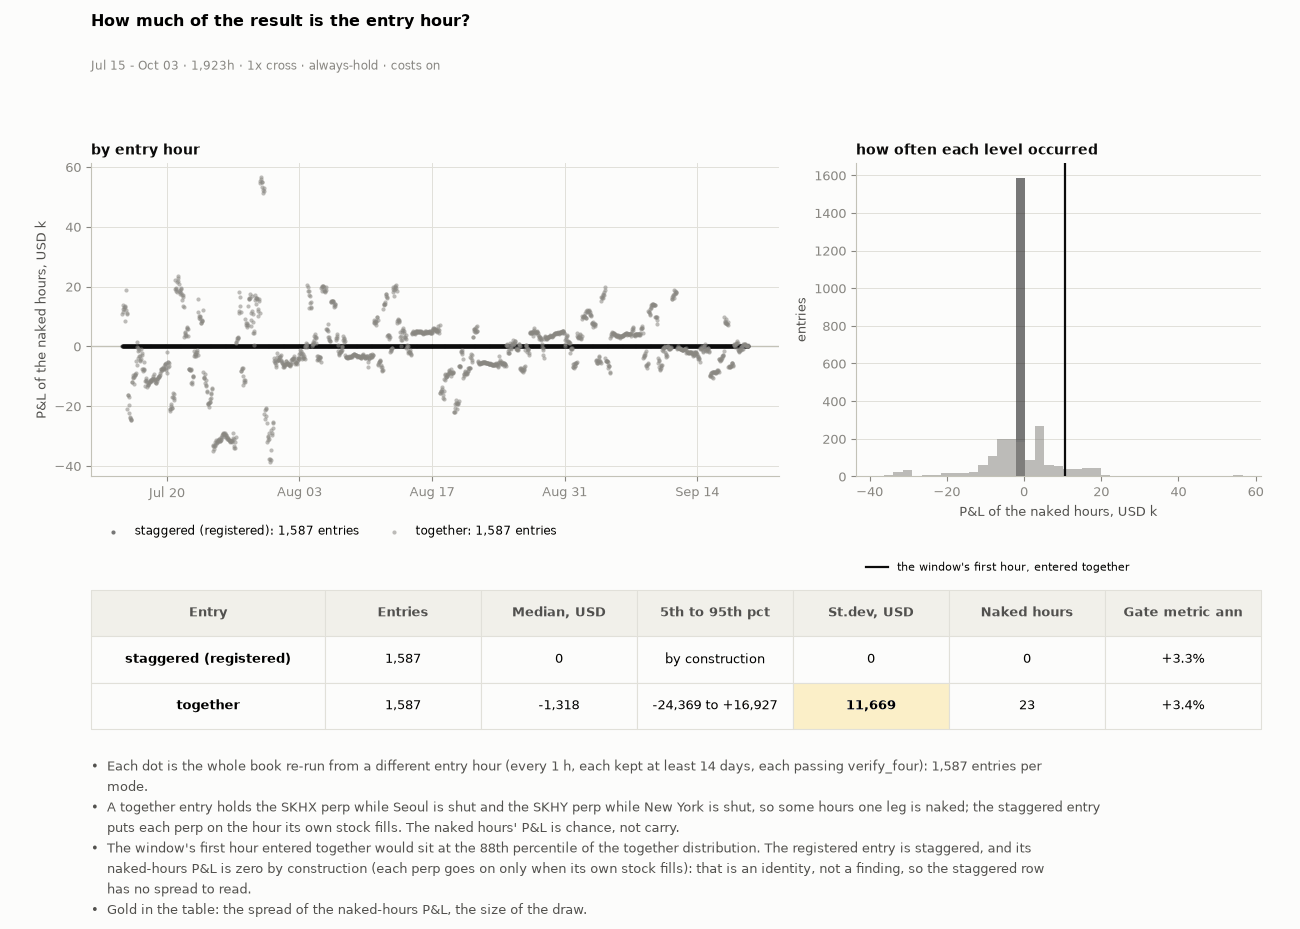

In [29]:
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
SWR, FAIL = [], []
for em_ in (ENTRY_MODE, "together"):
    for k_ in range(0, len(rows) - 24 * SWEEP_MIN_D, SWEEP_STEP_H):
        rw_ = rows[k_:]
        r_ = run4(rw_, fp(d=BOOK, entry_mode=em_))
        bad_ = sorted({k: v for k, v in F.verify_four(r_["_eng"], rw_).items() if not v[0]}.keys() - ENGINE_OPEN)
        t_ = pd.to_datetime(rw_[0]["time"], unit="ms", utc=True)
        if bad_:
            FAIL.append((em_, t_, bad_)); continue
        SWR.append({"mode": em_, "entry": t_, "hour": t_.hour, "unhedged": r_["unhedged_pnl"], "naked": max(r_["unhedged_hours_A"], r_["unhedged_hours_B"]), "gate": carry_ann(r_), "total": r_["total_pnl"]})
    SW_ = pd.DataFrame(SWR)
assert not FAIL, FAIL[:3]
reg = SW_[(SW_["mode"] == ENTRY_MODE)].iloc[0]; regT = SW_[(SW_["mode"] == "together")].iloc[0]
pct = lambda mode, v: float((SW_[SW_["mode"] == mode]["unhedged"] <= v).mean() * 100)
BUL = [f"Each dot is the whole book re-run from a different entry hour (every {SWEEP_STEP_H} h, each kept at least {SWEEP_MIN_D} days, each passing verify_four): {len(SW_[SW_['mode'] == ENTRY_MODE]):,} entries per mode.",
       f"A together entry holds the SKHX perp while Seoul is shut and the SKHY perp while New York is shut, so some hours one leg is naked; the staggered entry puts each perp on the hour its own stock fills. The naked hours' P&L is chance, not carry.",
       f"The window's first hour entered together would sit at the {pct('together', regT['unhedged']):.0f}th percentile of the together distribution. The registered entry is staggered, and its naked-hours P&L is zero by construction (each perp goes on only when its own stock fills): that is an identity, not a finding, so the staggered row has no spread to read.",
       "Gold in the table: the spread of the naked-hours P&L, the size of the draw."]
fig, gs, ax, axt = fig_tab(7.4, (2.7, 1.2), top=0.78, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off")
sg = gs[0].subgridspec(1, 2, width_ratios=[1.7, 1], wspace=0.14)
a1, a2 = fig.add_subplot(sg[0]), fig.add_subplot(sg[1])
for em_, col, lab in ((ENTRY_MODE, INK, "staggered (registered)"), ("together", MUTED, "together")):
    s_ = SW_[SW_["mode"] == em_]
    a1.scatter(s_["entry"], s_["unhedged"] / 1e3, s=9, color=col, alpha=0.55, linewidths=0, zorder=3, label=f"{lab}: {len(s_):,} entries")
a1.axhline(0, color=AXIS, linewidth=1); a1.set_ylabel("P&L of the naked hours, USD k"); a1.legend(loc="upper left", bbox_to_anchor=(0.0, -0.12), ncol=2, fontsize=8.5, frameon=False)
a1.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2)); a1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
a1.set_title("by entry hour", fontsize=10, loc="left", pad=6)
lo_, hi_ = SW_["unhedged"].min() / 1e3, SW_["unhedged"].max() / 1e3
for em_, col in ((ENTRY_MODE, INK), ("together", MUTED)):
    s_ = SW_[SW_["mode"] == em_]["unhedged"] / 1e3
    a2.hist(s_, bins=np.linspace(lo_, hi_, 40), color=col, alpha=0.55, zorder=3)
a2.axvline(regT["unhedged"] / 1e3, color=INK, linewidth=1.6, zorder=5, label="the window's first hour, entered together")
a2.set_xlabel("P&L of the naked hours, USD k"); a2.set_ylabel("entries"); a2.legend(loc="upper left", bbox_to_anchor=(0.0, -0.24), fontsize=8, frameon=False); a2.grid(axis="x", visible=False)
a2.set_title("how often each level occurred", fontsize=10, loc="left", pad=6)
fig.suptitle("How much of the result is the entry hour?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · 1x cross · always-hold · costs on", color=MUTED, fontsize=8.5)
rowsT = []
for em_ in (ENTRY_MODE, "together"):
    s_ = SW_[SW_["mode"] == em_]
    zero_ = bool(float(s_["unhedged"].abs().max()) == 0.0 and int(s_["naked"].max()) == 0)          # a staggered entry leaves no leg naked: its naked-hours P&L is zero by construction, not a finding
    rowsT.append([("staggered (registered)" if em_ == ENTRY_MODE else "together"), f"{len(s_):,}", ("0" if zero_ else f"{s_['unhedged'].median():+,.0f}"),
                  ("by construction" if zero_ else f"{s_['unhedged'].quantile(0.05):+,.0f} to {s_['unhedged'].quantile(0.95):+,.0f}"), ("0" if zero_ else f"{s_['unhedged'].std():,.0f}"),
                  f"{s_['naked'].median():.0f}", f"{s_['gate'].median():+.1f}%"])
tb = put_table(axt, rowsT, ["Entry", "Entries", "Median, USD", "5th to 95th pct", "St.dev, USD", "Naked hours", "Gate metric ann"], size=9.5, first=0.2)
gold(tb, 2, 4)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-entry", FIGURES)
S = {m: {"n": int(len(SW_[SW_["mode"] == m])), "median": float(SW_[SW_["mode"] == m]["unhedged"].median()), "p5": float(SW_[SW_["mode"] == m]["unhedged"].quantile(0.05)), "p95": float(SW_[SW_["mode"] == m]["unhedged"].quantile(0.95)),
         "sd": float(SW_[SW_["mode"] == m]["unhedged"].std()), "naked_med": float(SW_[SW_["mode"] == m]["naked"].median())} for m in (ENTRY_MODE, "together")}
S["registered_together_pct"] = pct("together", regT["unhedged"]); S["registered_together_value"] = float(regT["unhedged"]); S["n_runs"] = int(len(SW_))
ST4B = S

In [30]:
# ---- Test 3, read again: a staggered entry leaves no leg naked, so the naked-hours P&L is zero by construction; what the entry hour does move is the gate metric ----
SG_ = SW_[SW_["mode"] == ENTRY_MODE]; TG_ = SW_[SW_["mode"] == "together"]
STG = {"n": int(len(SG_)), "unhedged_min": float(SG_["unhedged"].min()), "unhedged_max": float(SG_["unhedged"].max()), "naked_max": int(SG_["naked"].max()),
       "gate_p5": float(SG_["gate"].quantile(0.05)), "gate_p95": float(SG_["gate"].quantile(0.95)), "gate_min": float(SG_["gate"].min()), "gate_max": float(SG_["gate"].max()), "gate_median": float(SG_["gate"].median()),
       "gate_p5_together": float(TG_["gate"].quantile(0.05)), "gate_p95_together": float(TG_["gate"].quantile(0.95))}
STG["zero"] = bool(STG["unhedged_min"] == 0.0 and STG["unhedged_max"] == 0.0 and STG["naked_max"] == 0)
ST4B.update({"staggered_gate": STG})
display(Markdown(f"**Test 3, read again.** Across {STG['n']:,} staggered entry hours the naked-hours P&L runs {STG['unhedged_min']:+,.4f} to {STG['unhedged_max']:+,.4f} USD with at most {STG['naked_max']} naked hours: "
                 + ("exactly zero, because each perp goes on only when its own stock can fill, so no leg is ever naked. That is the engine's own identity, not a finding, so no range is printed for it here, in the table above or in S7." if STG["zero"] else "not zero: see the table above.")
                 + f" What the entry hour does move is the gate metric: {STG['gate_p5']:+.1f}% to {STG['gate_p95']:+.1f}% a year (5th to 95th percentile; {STG['gate_min']:+.1f}% to {STG['gate_max']:+.1f}% across all of them, median {STG['gate_median']:+.1f}%) for a staggered entry, "
                 f"{STG['gate_p5_together']:+.1f}% to {STG['gate_p95_together']:+.1f}% for a together entry. The entries share the same end and most of the same hours, so they are one window re-sliced, not {STG['n']:,} observations."))

**Test 3, read again.** Across 1,587 staggered entry hours the naked-hours P&L runs +0.0000 to +0.0000 USD with at most 0 naked hours: exactly zero, because each perp goes on only when its own stock can fill, so no leg is ever naked. That is the engine's own identity, not a finding, so no range is printed for it here, in the table above or in S7. What the entry hour does move is the gate metric: +1.6% to +4.1% a year (5th to 95th percentile; +0.4% to +4.6% across all of them, median +3.3%) for a staggered entry, +1.7% to +4.1% for a together entry. The entries share the same end and most of the same hours, so they are one window re-sliced, not 1,587 observations.

### Test 4 · What does the rule add over the static hold, and how sensitive is it to its own settings?

The base book is the static hold with its basis hedged by rule. Test 4 sets it beside the static book (the stock legs matched one for one and never re-struck, the static book), asks which hedge ratio would have been neutral at each horizon, and runs the rule under other settings: the band, the history, the horizon of a move, the slippage and the way the ratio is read.

In [31]:
# ---- Test 4 setup: the static book beside the strategy, and the strategy under other settings ----
S4h = res["series"]; TT4 = S4h["time"]; N4 = len(TT4); IDX4 = pd.to_datetime(TT4, unit="ms", utc=True)
bh_f = lambda v: float(v) if v else np.nan
RT4 = {r_["time"]: r_ for r_ in rows}
PA4, PB4 = np.array([bh_f(RT4[t_]["A_perp"]) for t_ in TT4]), np.array([bh_f(RT4[t_]["B_perp"]) for t_ in TT4])
KU4 = np.array([bh_f(asof(MKH, t_)) / bh_f(asof(MFH, t_)) for t_ in TT4]); AD4 = np.array([bh_f(asof(MAH, t_)) for t_ in TT4])
PRICE4, STOCK4 = _PRICE0, _STOCK0                                       # the static book's perp price P&L and stock fair-value P&L: what the ratio is read on
ON4 = np.asarray(STATIC["series"]["on_A"], bool) & np.asarray(STATIC["series"]["on_B"], bool)
HG = res["rehedge"]


def sys_target_raw(W_h, H_h, clip):
    """The same ratio read off the raw hourly cash prints (a shut exchange keeps its last price): the slope of the perp spread's log move on the stock spread's."""
    y = (np.log(pd.Series(PB4, IDX4)) - np.log(pd.Series(PA4, IDX4))).diff(H_h)
    s = (np.log(pd.Series(AD4, IDX4)) - np.log(pd.Series(KU4, IDX4))).diff(H_h)
    return (y.rolling(W_h, min_periods=W_h).cov(s) / s.rolling(W_h, min_periods=W_h).var()).clip(*clip)


def sys_rho_star(h, lo=0, hi=None):
    dp, ds = PRICE4.diff(h).to_numpy(), STOCK4.diff(h).to_numpy()
    m_ = np.zeros(N4, bool); m_[h:] = ON4[h:] & ON4[:-h]
    sl_ = np.zeros(N4, bool); sl_[lo:hi] = True; m_ &= sl_
    rho = float(-np.cov(dp[m_], ds[m_])[0, 1] / np.var(ds[m_], ddof=1))
    return {"rho": rho, "r2": float(np.corrcoef(dp[m_], ds[m_])[0, 1] ** 2), "sd_book": float(np.std(dp[m_] + ds[m_], ddof=1)), "sd_rho": float(np.std(dp[m_] + rho * ds[m_], ddof=1)), "n": int(m_.sum())}


tgt_of = lambda ser_: dict(zip(TT4, ser_.to_numpy()))
_R_MID = sys_rho_star(24, 0, N4 // 2)["rho"]            # the neutral ratio over 24-hour moves on the FIRST half of the window only
SYS_ARMS = {"registered": {}, "band 0.05": {"band": 0.05}, "band 0.20": {"band": 0.20},
            "window 21 d": {"target": lambda pr_, st_: HDG.hedge_target(pr_, st_, 504, SYS_H_H, SYS_CLIP)}, "horizon 72 h": {"target": lambda pr_, st_: HDG.hedge_target(pr_, st_, SYS_W_H, 72, SYS_CLIP)},
            "slippage 0 bp": {"slip_bps": 0.0}, "slippage 20 bp": {"slip_bps": 20.0}, "raw prints": {"target": tgt_of(sys_target_raw(SYS_W_H, SYS_H_H, SYS_CLIP))},
            "fixed 0.75, no trades": {"fixed": 0.75},
            "estimate once at mid, hold": {"target": {t_: (1.0 if i_ < N4 // 2 else _R_MID) for i_, t_ in enumerate(TT4)}}}
ARM_R = {nm_: (res if nm_ == "registered" else rehedge(STATIC, **kw_)) for nm_, kw_ in SYS_ARMS.items()}
ARM_V = {nm_: HDG.verify_rehedge(r_) for nm_, r_ in ARM_R.items()}                # the module's checks on every arm; a mapping target (raw prints, the mid estimate) reads no_lookahead SKIPPED
assert not {nm_: k_ for nm_, c_ in ARM_V.items() for k_, v_ in c_.items() if check_status(v_) == "fail"}, ARM_V
print("arm checks (verify_rehedge): " + "; ".join(f"{nm_} {sum(check_status(v_) == 'pass' for v_ in c_.values())}/{len(c_)}" + (" (no_lookahead SKIPPED)" if check_status(c_["no_lookahead"]) == "skipped" else "") for nm_, c_ in ARM_V.items()))
FIRST4 = HG["events"][0]["i"]                                            # the swing is compared from the first rebalance on, both books over the same hours
mtm_of = lambda r_: np.asarray(r_["series"]["cum_perp_price"], float) + np.asarray(r_["series"]["cum_stock_A_fv"], float) + np.asarray(r_["series"]["cum_stock_B_fv"], float)
dd_of = lambda r_: float((lambda e_: (e_ / e_.cummax() - 1).min())(pd.Series(EQUITY + np.asarray(r_["series"]["total_pnl_fv"], float))) * 100)
swing_of = lambda r_, h_: float(pd.Series(mtm_of(r_)).diff(h_).iloc[FIRST4:].std())
SYS_DAYS = res["days"]


def sstat(r_):
    rh_ = r_.get("rehedge") or {"n": 0, "rebal_cost": 0.0, "rho_min": 1.0, "rho_max": 1.0}
    sw_ = {h_: swing_of(r_, h_) for h_ in SYS_HORIZONS}
    return {"total": r_["total_pnl"], "total_fv": r_["total_pnl_fv"], "carry": carry_usd(r_), "carry_ann": carry_ann(r_), "mtm": float(mtm_of(r_)[-1]), "funding": r_["funding_net"], "financing": r_["financing"], "dividends": r_["dividends"],
            "stock_fees": r_["stock_costs"] - rh_["rebal_cost"], "rebal_cost": rh_["rebal_cost"], "perp_fees": r_["perp_fees"] + r_["perp_liq_fees"], "n_reb": rh_["n"], "dd": dd_of(r_),
            "rho_min": rh_["rho_min"], "rho_max": rh_["rho_max"], "swing": sw_}


T4B = sstat(STATIC); T4R = {nm_: sstat(r_) for nm_, r_ in ARM_R.items()}; T4G = T4R["registered"]
for nm_ in T4R:
    T4R[nm_]["swing_ratio"] = {h_: T4R[nm_]["swing"][h_] / T4B["swing"][h_] for h_ in SYS_HORIZONS}
T4B["swing_ratio"] = {h_: 1.0 for h_ in SYS_HORIZONS}; T4G = T4R["registered"]
assert abs(T4B["total"] - STATIC["total_pnl"]) < 1e-9 and abs(T4G["total"] - res["total_pnl"]) < 1e-9
WSH4 = f"{WSB} · verify_four {NCHK}/{NCHK} · strategy checks {SYS_NCHK}/{SYS_NCHK} · fair-value marks"
print(f"Test 4: {len(SYS_ARMS)} arms run, none chosen on its result; the registered rule is the one in the parameters cell.")

arm checks (verify_rehedge): registered 8/8; band 0.05 8/8; band 0.20 8/8; window 21 d 8/8; horizon 72 h 8/8; slippage 0 bp 8/8; slippage 20 bp 8/8; raw prints 7/8 (no_lookahead SKIPPED); fixed 0.75, no trades 8/8; estimate once at mid, hold 7/8 (no_lookahead SKIPPED)
Test 4: 10 arms run, none chosen on its result; the registered rule is the one in the parameters cell.


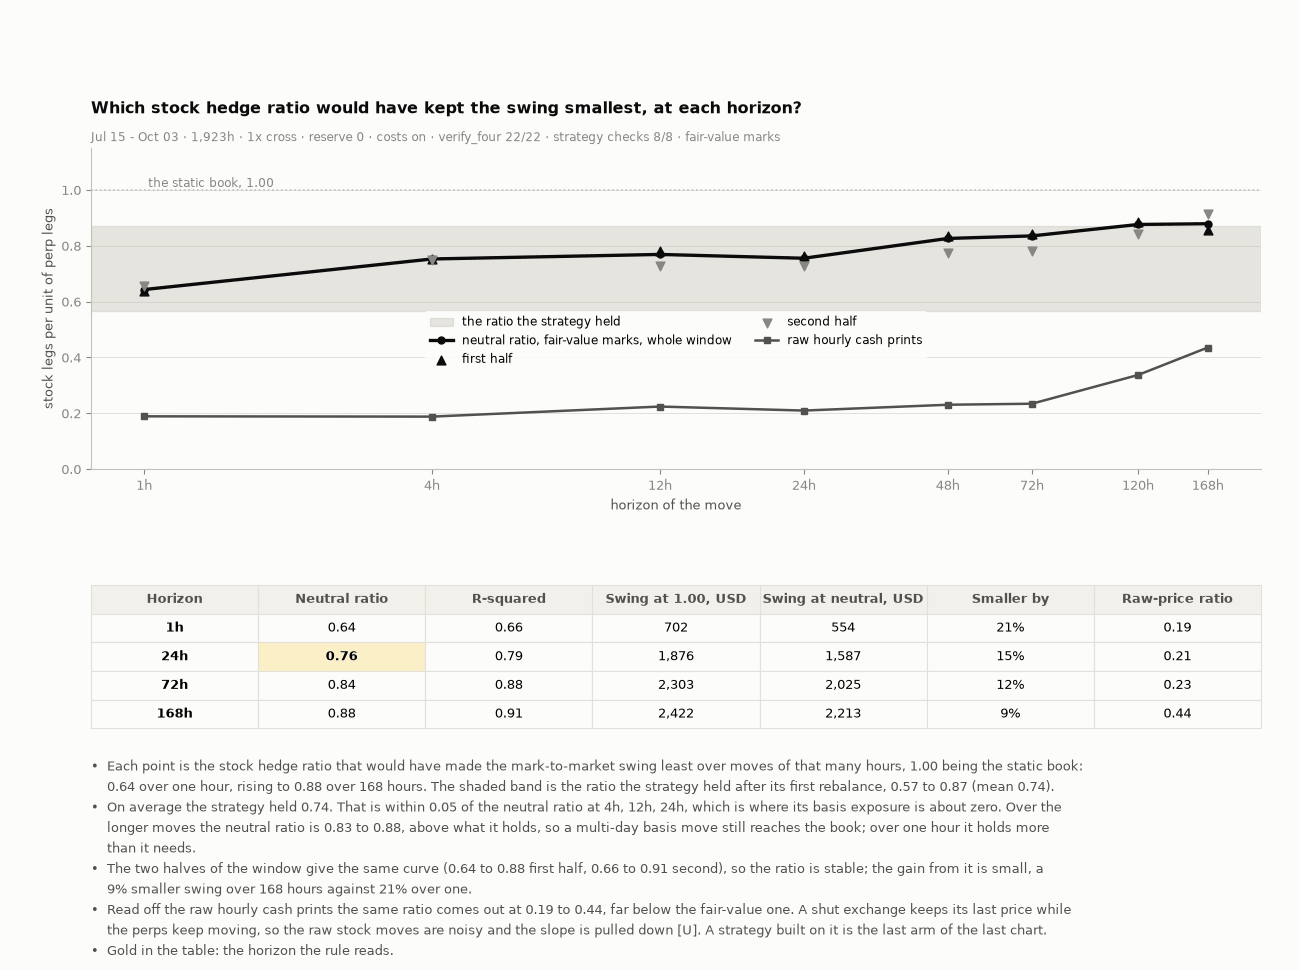

In [32]:
# ---- 4a. which stock hedge ratio keeps the swing smallest at each horizon, and where does the strategy sit ----
def sys_rho_raw(h):
    y = (np.log(pd.Series(PB4, IDX4)) - np.log(pd.Series(PA4, IDX4))).diff(h).to_numpy(); s = (np.log(pd.Series(AD4, IDX4)) - np.log(pd.Series(KU4, IDX4))).diff(h).to_numpy()
    m_ = np.zeros(N4, bool); m_[h:] = ON4[h:] & ON4[:-h]; m_ &= np.isfinite(y) & np.isfinite(s)
    return float(np.cov(y[m_], s[m_])[0, 1] / np.var(s[m_], ddof=1))


RHO_ALL = {h_: sys_rho_star(h_) for h_ in SYS_HORIZONS}
RHO_H1 = {h_: sys_rho_star(h_, 0, N4 // 2)["rho"] for h_ in SYS_HORIZONS}; RHO_H2 = {h_: sys_rho_star(h_, N4 // 2, None)["rho"] for h_ in SYS_HORIZONS}
RHO_RAW = {h_: sys_rho_raw(h_) for h_ in SYS_HORIZONS}
held_ = np.asarray(res["series"]["held_ratio"], float)[FIRST4 + 1:]          # after the first trade: the 1.00 of the history-building days is not the strategy
HOLD_LO, HOLD_HI, HOLD_MEAN = float(held_.min()), float(held_.max()), float(held_.mean())
NEUTRAL = [h_ for h_ in SYS_HORIZONS if abs(RHO_ALL[h_]["rho"] - HOLD_MEAN) <= 0.05]
BUL = [f"Each point is the stock hedge ratio that would have made the mark-to-market swing least over moves of that many hours, 1.00 being the static book: {RHO_ALL[1]['rho']:.2f} over one hour, rising to {RHO_ALL[SYS_HORIZONS[-1]]['rho']:.2f} over {SYS_HORIZONS[-1]} hours. The shaded band is the ratio the strategy held after its first rebalance, {HOLD_LO:.2f} to {HOLD_HI:.2f} (mean {HOLD_MEAN:.2f}).",
       f"On average the strategy held {HOLD_MEAN:.2f}. That is within 0.05 of the neutral ratio at {', '.join(f'{h_}h' for h_ in NEUTRAL) if NEUTRAL else 'no horizon'}, which is where its basis exposure is about zero. Over the longer moves the neutral ratio is {min(RHO_ALL[h_]['rho'] for h_ in SYS_HORIZONS if h_ >= 48):.2f} to {max(RHO_ALL[h_]['rho'] for h_ in SYS_HORIZONS if h_ >= 48):.2f}, above what it holds, so a multi-day basis move still reaches the book; over one hour it holds more than it needs.",
       f"The two halves of the window give the same curve ({min(RHO_H1.values()):.2f} to {max(RHO_H1.values()):.2f} first half, {min(RHO_H2.values()):.2f} to {max(RHO_H2.values()):.2f} second), so the ratio is stable; the gain from it is small, a {(1 - RHO_ALL[168]['sd_rho'] / RHO_ALL[168]['sd_book']) * 100:.0f}% smaller swing over {SYS_HORIZONS[-1]} hours against {(1 - RHO_ALL[1]['sd_rho'] / RHO_ALL[1]['sd_book']) * 100:.0f}% over one.",
       f"Read off the raw hourly cash prints the same ratio comes out at {min(RHO_RAW.values()):.2f} to {max(RHO_RAW.values()):.2f}, far below the fair-value one. A shut exchange keeps its last price while the perps keep moving, so the raw stock moves are noisy and the slope is pulled down [U]. A strategy built on it is the last arm of the last chart.",
       "Gold in the table: the horizon the rule reads."]
fig, gs, ax, axt = fig_tab(7.4, (2.8, 1.25), top=0.80, hspace=0.5, nb=figstyle.nlines(BUL))
hs_ = list(SYS_HORIZONS)
ax.axhspan(HOLD_LO, HOLD_HI, color=AXIS, alpha=0.4, zorder=1, label="the ratio the strategy held")
ax.plot(hs_, [RHO_ALL[h_]["rho"] for h_ in hs_], color=INK, linewidth=2.4, marker="o", markersize=5, zorder=5, label="neutral ratio, fair-value marks, whole window")
ax.scatter(hs_, [RHO_H1[h_] for h_ in hs_], marker="^", s=40, color=INK, zorder=6, label="first half")
ax.scatter(hs_, [RHO_H2[h_] for h_ in hs_], marker="v", s=40, color=MUTED, zorder=6, label="second half")
ax.plot(hs_, [RHO_RAW[h_] for h_ in hs_], color=INK2, linewidth=1.8, marker="s", markersize=4, zorder=3, label="raw hourly cash prints")        # not pink: pink is the basis and the premium
ax.axhline(1.0, color=AXIS, linewidth=1.2, linestyle=":", zorder=1); ax.text(hs_[0], 1.0, " the static book, 1.00", color=MUTED, fontsize=8.5, va="bottom")
ax.set_xscale("log"); ax.set_xticks(hs_); ax.set_xticklabels([f"{h_}h" for h_ in hs_]); ax.minorticks_off(); ax.grid(axis="x", visible=False)
ax.set_ylim(0, 1.15); ax.set_ylabel("stock legs per unit of perp legs"); ax.set_xlabel("horizon of the move")
ax.legend(loc="center", bbox_to_anchor=(0.5, 0.40), ncol=2, fontsize=8.3, **LEG)
ask(ax, "Which stock hedge ratio would have kept the swing smallest, at each horizon?", WSH4)
rowsH = [[f"{h_}h", f"{RHO_ALL[h_]['rho']:.2f}", f"{RHO_ALL[h_]['r2']:.2f}", f"{RHO_ALL[h_]['sd_book']:,.0f}", f"{RHO_ALL[h_]['sd_rho']:,.0f}", f"{(1 - RHO_ALL[h_]['sd_rho'] / RHO_ALL[h_]['sd_book']) * 100:.0f}%", f"{RHO_RAW[h_]:.2f}"] for h_ in (1, 24, 72, 168)]
tb = put_table(axt, rowsH, ["Horizon", "Neutral ratio", "R-squared", "Swing at 1.00, USD", "Swing at neutral, USD", "Smaller by", "Raw-price ratio"], size=9.5)
gold(tb, 2, 1)
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-hedge-ratio", FIGURES)
ST4["hedge_ratio"] = {"horizons": list(SYS_HORIZONS), "rho": {str(h_): RHO_ALL[h_] for h_ in SYS_HORIZONS}, "first_half": {str(h_): RHO_H1[h_] for h_ in SYS_HORIZONS}, "second_half": {str(h_): RHO_H2[h_] for h_ in SYS_HORIZONS},
                      "raw": {str(h_): RHO_RAW[h_] for h_ in SYS_HORIZONS}, "held_lo": HOLD_LO, "held_hi": HOLD_HI, "held_mean": HOLD_MEAN, "neutral_horizons": NEUTRAL}

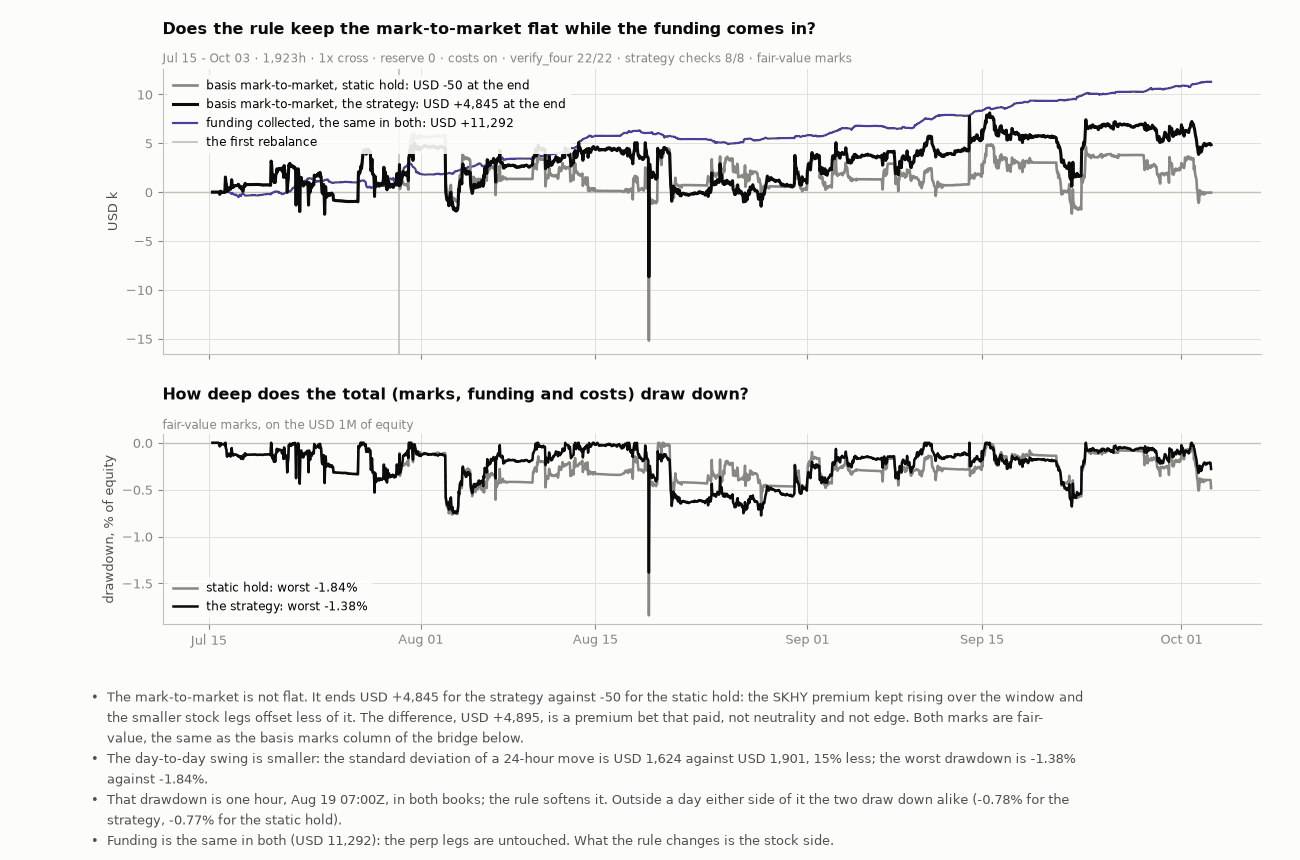

In [33]:
# ---- 4b. what does the rule add over the static hold: the mark-to-market and the drawdown ----
fig, (c0, c1) = plt.subplots(2, 1, figsize=(13, 8.6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
mS, mR = mtm_of(STATIC), mtm_of(res)
c0.plot(IDX4, mS / 1e3, color=MUTED, linewidth=1.9, zorder=4, label=f"basis mark-to-market, static hold: USD {mS[-1]:+,.0f} at the end")
c0.plot(IDX4, mR / 1e3, color=INK, linewidth=2.2, zorder=5, label=f"basis mark-to-market, the strategy: USD {mR[-1]:+,.0f} at the end")
c0.plot(IDX4, np.asarray(res["series"]["cum_funding_net"], float) / 1e3, color=C_NET, linewidth=1.6, zorder=3, label=f"funding collected, the same in both: USD {res['funding_net']:+,.0f}")
c0.axvline(IDX4[FIRST4], color=AXIS, linewidth=1.2, zorder=1, label="the first rebalance")
c0.axhline(0, color=AXIS, linewidth=1, zorder=1); c0.set_ylabel("USD k"); c0.legend(loc="upper left", fontsize=8.5, **LEG)
ask(c0, "Does the rule keep the mark-to-market flat while the funding comes in?", WSH4)
DDs = {}
for r_, col_, lab_ in ((STATIC, MUTED, "static hold"), (res, INK, "the strategy")):
    e_ = pd.Series(EQUITY + np.asarray(r_["series"]["total_pnl_fv"], float), IDX4); dd_ = (e_ / e_.cummax() - 1) * 100; DDs[lab_] = dd_
    c1.plot(IDX4, dd_, color=col_, linewidth=1.8, zorder=4, label=f"{lab_}: worst {dd_.min():.2f}%")
c1.axhline(0, color=AXIS, linewidth=1, zorder=1); c1.set_ylabel("drawdown, % of equity"); c1.legend(loc="lower left", fontsize=8.5, **LEG)
c1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(c1, "How deep does the total (marks, funding and costs) draw down?", "fair-value marks, on the USD 1M of equity")
sd1, sdr = swing_of(STATIC, 24), swing_of(res, 24)
SPIKE = DDs["static hold"].idxmin(); AWAY = (IDX4 < SPIKE - pd.Timedelta(hours=24)) | (IDX4 > SPIKE + pd.Timedelta(hours=24))
DD_AWAY_B, DD_AWAY_R = float(DDs["static hold"][AWAY].min()), float(DDs["the strategy"][AWAY].min())
finish(fig, [f"The mark-to-market is not flat. It ends USD {mR[-1]:+,.0f} for the strategy against {mS[-1]:+,.0f} for the static hold: the SKHY premium kept rising over the window and the smaller stock legs offset less of it. The difference, USD {mR[-1] - mS[-1]:+,.0f}, is a premium bet that paid, not neutrality and not edge. Both marks are fair-value, the same as the basis marks column of the bridge below.",
             f"The day-to-day swing is smaller: the standard deviation of a 24-hour move is USD {sdr:,.0f} against USD {sd1:,.0f}, {(1 - sdr / sd1) * 100:.0f}% less; the worst drawdown is {T4G['dd']:.2f}% against {T4B['dd']:.2f}%.",
             f"That drawdown is one hour, {SPIKE:%b %d %H:%M}Z, in both books; the rule softens it. Outside a day either side of it the two draw down alike ({DD_AWAY_R:.2f}% for the strategy, {DD_AWAY_B:.2f}% for the static hold).",
             f"Funding is the same in both (USD {res['funding_net']:,.0f}): the perp legs are untouched. What the rule changes is the stock side."], top=0.92, hspace=0.34, right=0.97)
figstyle.show(fig, "fig:s4-hedge-pnl", FIGURES)
ST4["hedge_pnl"] = {"spike": str(SPIKE), "dd_away_static": DD_AWAY_B, "dd_away_strategy": DD_AWAY_R, "mtm_static": T4B["mtm"], "mtm_strategy": T4G["mtm"], "dd_static": T4B["dd"], "dd_strategy": T4G["dd"], "swing24_static": sd1, "swing24_strategy": sdr}

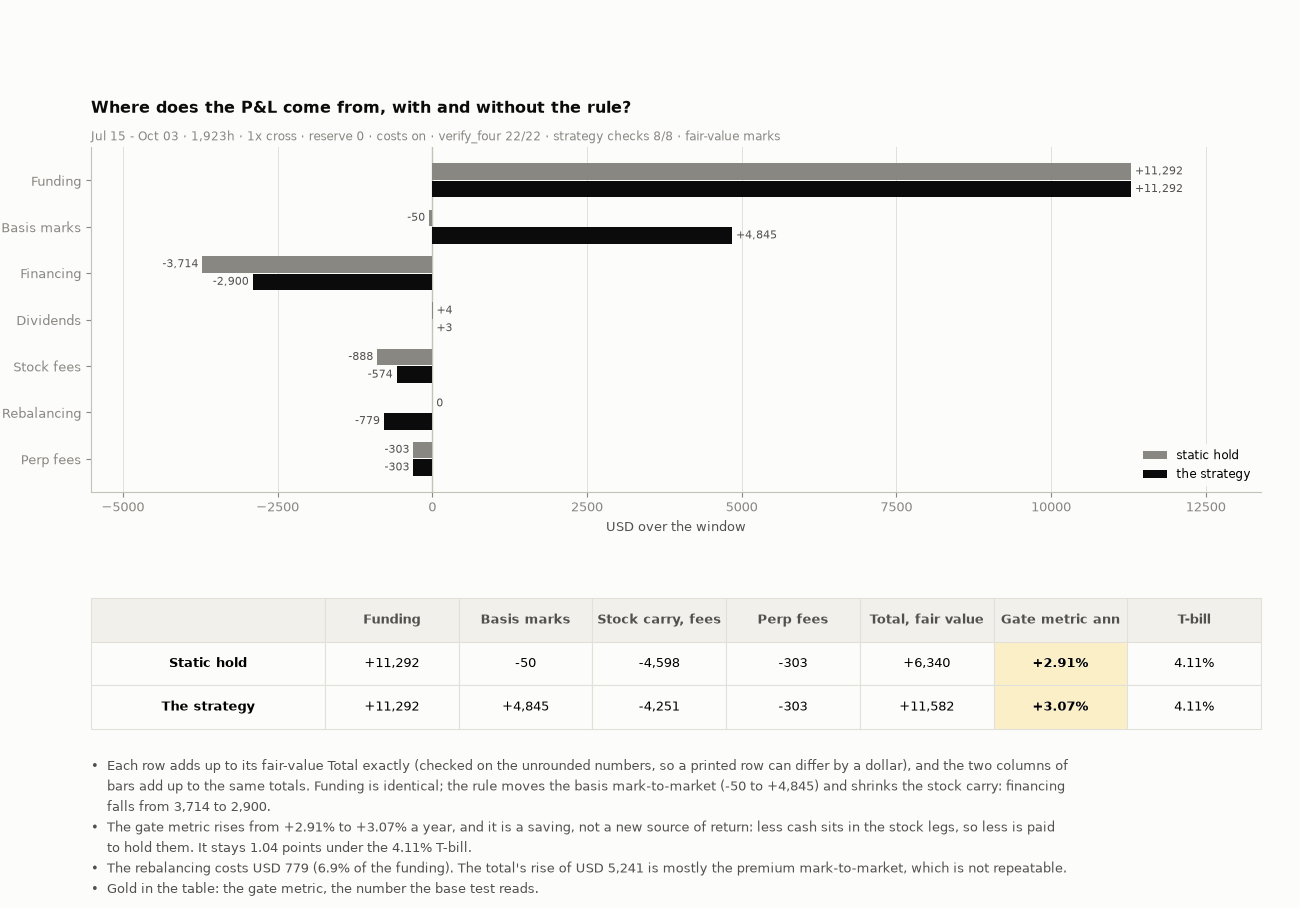

In [34]:
# ---- 4c. where the strategy's P&L comes from, against the static hold ----
COMP = [("Funding", "funding", 1), ("Basis marks", "mtm", 1), ("Financing", "financing", -1), ("Dividends", "dividends", 1), ("Stock fees", "stock_fees", -1), ("Rebalancing", "rebal_cost", -1), ("Perp fees", "perp_fees", -1)]
vb_ = [s_ * T4B[k_] for _n, k_, s_ in COMP]; vh_ = [s_ * T4G[k_] for _n, k_, s_ in COMP]
assert abs(sum(vb_) - STATIC["total_pnl_fv"]) < 1e-6 and abs(sum(vh_) - res["total_pnl_fv"]) < 1e-6, (sum(vb_), STATIC["total_pnl_fv"], sum(vh_), res["total_pnl_fv"])
ROWSUM = {k_: s_["funding"] + s_["mtm"] - (s_["financing"] - s_["dividends"] + s_["stock_fees"] + s_["rebal_cost"]) - s_["perp_fees"] for k_, s_ in (("static", T4B), ("strategy", T4G))}
assert all(abs(ROWSUM[k_] - s_["total_fv"]) < 1e-6 for k_, s_ in (("static", T4B), ("strategy", T4G))), (ROWSUM, T4B["total_fv"], T4G["total_fv"])      # each row of the table adds to its Total, before the figure draws
BUL = [f"Each row adds up to its fair-value Total exactly (checked on the unrounded numbers, so a printed row can differ by a dollar), and the two columns of bars add up to the same totals. Funding is identical; the rule moves the basis mark-to-market ({T4B['mtm']:+,.0f} to {T4G['mtm']:+,.0f}) and shrinks the stock carry: financing falls from {T4B['financing']:,.0f} to {T4G['financing']:,.0f}.",
       f"The gate metric rises from {T4B['carry_ann']:+.2f}% to {T4G['carry_ann']:+.2f}% a year, and it is a saving, not a new source of return: less cash sits in the stock legs, so less is paid to hold them. It stays {HURDLE_PCT - T4G['carry_ann']:.2f} points under the {HURDLE_PCT:.2f}% T-bill.",
       f"The rebalancing costs USD {T4G['rebal_cost']:,.0f} ({T4G['rebal_cost'] / T4G['funding'] * 100:.1f}% of the funding). The total's rise of USD {res['total_pnl_fv'] - STATIC['total_pnl_fv']:,.0f} is mostly the premium mark-to-market, which is not repeatable.",
       "Gold in the table: the gate metric, the number the base test reads."]
fig, gs, ax, axt = fig_tab(7.4, (2.9, 1.1), top=0.80, hspace=0.45, nb=figstyle.nlines(BUL))
yy_ = np.arange(len(COMP))[::-1]
ax.barh(yy_ + 0.19, vb_, height=0.36, color=MUTED, zorder=3, label="static hold"); ax.barh(yy_ - 0.19, vh_, height=0.36, color=INK, zorder=3, label="the strategy")
for y_, a_, b_ in zip(yy_, vb_, vh_):
    fm_ = lambda v: f"{v:+,.0f}" if abs(v) >= 0.5 else "0"
    ax.text(a_, y_ + 0.19, f" {fm_(a_)} ", va="center", ha="left" if a_ >= 0 else "right", fontsize=8, color=INK2); ax.text(b_, y_ - 0.19, f" {fm_(b_)} ", va="center", ha="left" if b_ >= 0 else "right", fontsize=8, color=INK2)
ax.set_yticks(yy_); ax.set_yticklabels([n_ for n_, _k, _s in COMP]); ax.axvline(0, color=AXIS, linewidth=1); ax.set_xlabel("USD over the window"); ax.grid(axis="y", visible=False)
lo_, hi_ = min(vb_ + vh_ + [0.0]), max(vb_ + vh_ + [0.0]); ax.set_xlim(lo_ - (hi_ - lo_) * 0.12, hi_ + (hi_ - lo_) * 0.14)
ax.legend(loc="lower right", fontsize=8.5, **LEG)
ask(ax, "Where does the P&L come from, with and without the rule?", WSH4)
cells = [[nm_, f"{s_['funding']:+,.0f}", f"{s_['mtm']:+,.0f}", f"{-(s_['financing'] - s_['dividends'] + s_['stock_fees'] + s_['rebal_cost']):+,.0f}", f"{-s_['perp_fees']:+,.0f}", f"{s_['total_fv']:+,.0f}", f"{s_['carry_ann']:+.2f}%", f"{HURDLE_PCT:.2f}%"]
         for nm_, s_ in (("Static hold", T4B), ("The strategy", T4G))]
tb = put_table(axt, cells, ["", "Funding", "Basis marks", "Stock carry, fees", "Perp fees", "Total, fair value", "Gate metric ann", "T-bill"], size=9.5, first=0.2)
gold(tb, 1, 6); gold(tb, 2, 6)
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-hedge-bridge", FIGURES)
ST4["hedge_bridge"] = {"static": {k_: T4B[k_] for k_ in ("funding", "mtm", "financing", "dividends", "stock_fees", "rebal_cost", "perp_fees", "total", "total_fv", "carry_ann")}, "strategy": {k_: T4G[k_] for k_ in ("funding", "mtm", "financing", "dividends", "stock_fees", "rebal_cost", "perp_fees", "total", "total_fv", "carry_ann")}}

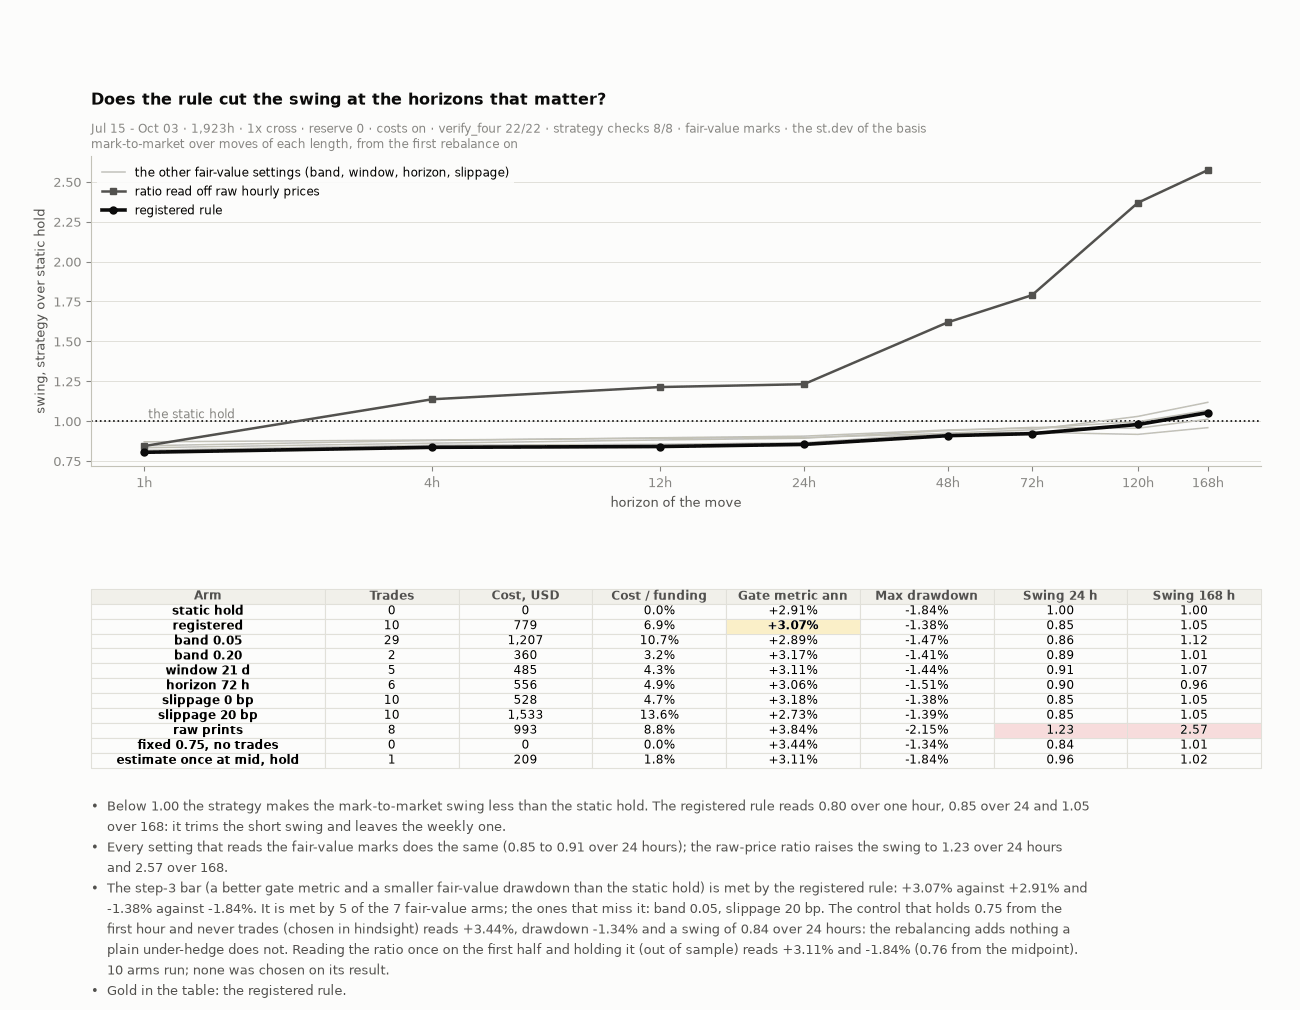

In [35]:
# ---- 4d. does the rule cut the swing at the horizons that matter, and how robust is it to its own settings ----
SYS_CTRL2 = "estimate once at mid, hold"       # a control that is out of sample: the ratio is read once on the first half, held at 1.00 until then, never re-struck
SYS_CTRL = "fixed 0.75, no trades"          # a control, chosen in hindsight from the neutral ratios of the last chart: the same under-hedge held from the first hour, never re-struck
SYS_FV = [n_ for n_ in SYS_ARMS if n_ not in ("raw prints", SYS_CTRL, SYS_CTRL2)]
SYS_MEET = [n_ for n_ in SYS_FV if T4R[n_]["carry_ann"] > T4B["carry_ann"] and T4R[n_]["dd"] > T4B["dd"]]
BUL = [f"Below 1.00 the strategy makes the mark-to-market swing less than the static hold. The registered rule reads {T4G['swing_ratio'][1]:.2f} over one hour, {T4G['swing_ratio'][24]:.2f} over 24 and {T4G['swing_ratio'][168]:.2f} over 168: it trims the short swing and leaves the weekly one.",
       f"Every setting that reads the fair-value marks does the same ({min(T4R[n_]['swing_ratio'][24] for n_ in SYS_FV):.2f} to {max(T4R[n_]['swing_ratio'][24] for n_ in SYS_FV):.2f} over 24 hours); the raw-price ratio raises the swing to {T4R['raw prints']['swing_ratio'][24]:.2f} over 24 hours and {T4R['raw prints']['swing_ratio'][168]:.2f} over 168.",
       f"The step-3 bar (a better gate metric and a smaller fair-value drawdown than the static hold) is met by the registered rule: {T4G['carry_ann']:+.2f}% against {T4B['carry_ann']:+.2f}% and {T4G['dd']:.2f}% against {T4B['dd']:.2f}%. It is met by {len(SYS_MEET)} of the {len(SYS_FV)} fair-value arms; the ones that miss it: {', '.join(n_ for n_ in SYS_FV if n_ not in SYS_MEET) or 'none'}. The control that holds 0.75 from the first hour and never trades (chosen in hindsight) reads {T4R[SYS_CTRL]['carry_ann']:+.2f}%, drawdown {T4R[SYS_CTRL]['dd']:.2f}% and a swing of {T4R[SYS_CTRL]['swing_ratio'][24]:.2f} over 24 hours: {'the rebalancing adds nothing a plain under-hedge does not' if T4R[SYS_CTRL]['carry_ann'] >= T4G['carry_ann'] and T4R[SYS_CTRL]['dd'] >= T4G['dd'] else 'the rebalancing is worth something over a plain under-hedge'}. Reading the ratio once on the first half and holding it (out of sample) reads {T4R[SYS_CTRL2]['carry_ann']:+.2f}% and {T4R[SYS_CTRL2]['dd']:.2f}% ({_R_MID:.2f} from the midpoint). {len(SYS_ARMS)} arms run; none was chosen on its result.",
       "Gold in the table: the registered rule."]
fig, gs, ax, axt = fig_tab(7.8, (2.6, 1.5), top=0.80, hspace=0.5, nb=figstyle.nlines(BUL))
for nm_ in SYS_ARMS:
    if nm_ in ("registered", "raw prints", SYS_CTRL, SYS_CTRL2): continue
    ax.plot(list(SYS_HORIZONS), [T4R[nm_]["swing_ratio"][h_] for h_ in SYS_HORIZONS], color=AXIS, linewidth=1.1, zorder=2)
ax.plot([], [], color=AXIS, linewidth=1.1, label="the other fair-value settings (band, window, horizon, slippage)")
ax.plot(list(SYS_HORIZONS), [T4R["raw prints"]["swing_ratio"][h_] for h_ in SYS_HORIZONS], color=INK2, linewidth=1.8, marker="s", markersize=4, zorder=3, label="ratio read off raw hourly prices")        # not pink: pink is the basis and the premium
ax.plot(list(SYS_HORIZONS), [T4G["swing_ratio"][h_] for h_ in SYS_HORIZONS], color=INK, linewidth=2.6, marker="o", markersize=5, zorder=5, label="registered rule")
ax.axhline(1.0, color=INK, linewidth=1.2, linestyle=":", zorder=1); ax.text(SYS_HORIZONS[0], 1.0, " the static hold", color=MUTED, fontsize=8.5, va="bottom")
ax.set_xscale("log"); ax.set_xticks(list(SYS_HORIZONS)); ax.set_xticklabels([f"{h_}h" for h_ in SYS_HORIZONS]); ax.minorticks_off(); ax.grid(axis="x", visible=False)
ax.set_ylabel("swing, strategy over static hold"); ax.set_xlabel("horizon of the move"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "Does the rule cut the swing at the horizons that matter?", f"{WSH4} · the st.dev of the basis mark-to-market over moves of each length, from the first rebalance on")
cells = [["static hold", "0", "0", "0.0%", f"{T4B['carry_ann']:+.2f}%", f"{T4B['dd']:.2f}%", "1.00", "1.00"]]
for nm_ in SYS_ARMS:
    s_ = T4R[nm_]
    cells.append([nm_, f"{s_['n_reb']}", f"{s_['rebal_cost']:,.0f}", f"{s_['rebal_cost'] / s_['funding'] * 100:.1f}%", f"{s_['carry_ann']:+.2f}%", f"{s_['dd']:.2f}%", f"{s_['swing_ratio'][24]:.2f}", f"{s_['swing_ratio'][168]:.2f}"])
tb = put_table(axt, cells, ["Arm", "Trades", "Cost, USD", "Cost / funding", "Gate metric ann", "Max drawdown", "Swing 24 h", "Swing 168 h"], size=8.8, first=0.2)
gold(tb, 2, 4)
for r_i, row_ in enumerate(cells[1:], 2):
    if row_[0] == "raw prints": tint(tb, r_i, 6, "rose"); tint(tb, r_i, 7, "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-hedge-swing", FIGURES)
SYS_ADOPT = bool(T4G["carry_ann"] > T4B["carry_ann"] and T4G["dd"] > T4B["dd"])
ST4["hedge"] = {"meet": SYS_MEET, "n_fv": len(SYS_FV), "pre": SYS_PRE, "n_arms": len(SYS_ARMS), "checks": SYS_NCHK, "adopt": SYS_ADOPT, "static": {k_: T4B[k_] for k_ in ("carry_ann", "dd", "mtm", "total")},
                "registered": {k_: T4G[k_] for k_ in ("carry_ann", "dd", "mtm", "total", "n_reb", "rebal_cost", "rho_min", "rho_max")},
                "swing_ratio": {str(h_): T4G["swing_ratio"][h_] for h_ in SYS_HORIZONS}, "raw_swing_ratio": {str(h_): T4R["raw prints"]["swing_ratio"][h_] for h_ in SYS_HORIZONS},
                "fv_swing24": [min(T4R[n_]["swing_ratio"][24] for n_ in SYS_FV), max(T4R[n_]["swing_ratio"][24] for n_ in SYS_FV)], "arms": {n_: {k_: v_ for k_, v_ in T4R[n_].items() if k_ not in ("swing",)} for n_ in T4R}}

### Inference · how much can a window this short say?

Test 4 set point estimates side by side. The cells below ask whether the rule's saving is distinguishable from zero, put block-bootstrap intervals on the gate metric and the Sharpe ratio, and say what a sample this short could have shown at all. Every bootstrap resamples days in stationary blocks (the block length is printed), because days are not independent, and the effective number of independent days sits next to each p.

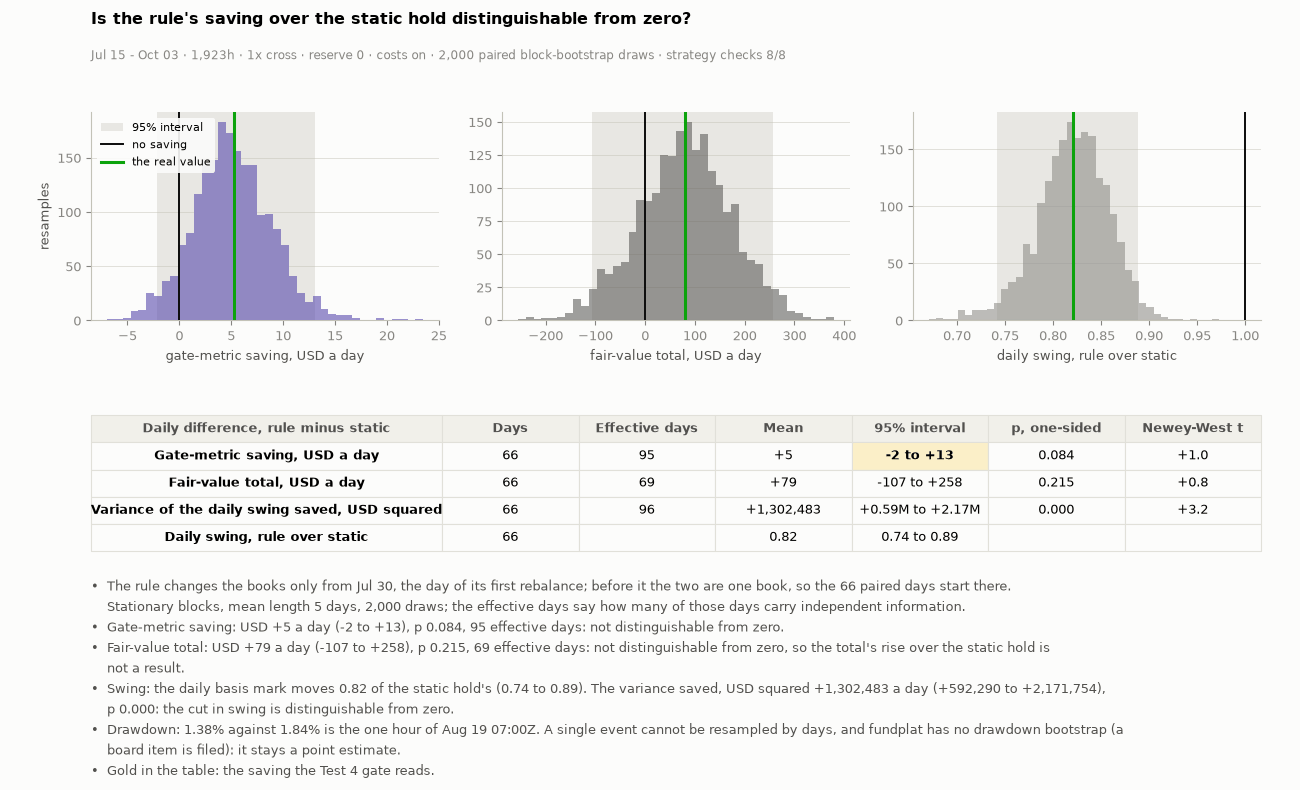

In [36]:
# ---- Inference 1: is the rule's saving over the static hold distinguishable from zero? A paired stationary bootstrap on the daily differences; the books are one book before the first rebalance ----
from statistics import NormalDist
NBOOT = NSHUF
pctl = lambda v, q: ST.percentile([float(u) for u in v], q)
ci_of = lambda sums, Tn: (pctl(np.asarray(sums) / Tn, (1 - CI_LEVEL) / 2 * 100), pctl(np.asarray(sums) / Tn, (1 + CI_LEVEL) / 2 * 100))


def same_seed_sums(arrs, seed):
    """Stationary-bootstrap sums of several equal-length series on IDENTICAL resampled days: the index path depends on the seed and the length, never the values, so one int seed gives each series the same draws."""
    return {k_: np.asarray(ST.stationary_bootstrap_sums([float(u) for u in a_], BOOT_BLOCK_D, NBOOT, seed)) for k_, a_ in arrs.items()}


def eff_days(x):
    """The days that carry the information: n x (the iid standard error / the Newey-West one)^2. Below n when days depend on each other."""
    x = np.asarray(x, float); nw_ = ST.newey_west(list(x)); se0 = x.std(ddof=1) / np.sqrt(len(x))
    return (len(x) * (se0 / nw_["se"]) ** 2 if nw_["se"] > 0 else float("nan")), nw_


_t1 = same_seed_sums({"x": np.arange(30.0), "x3": 3 * np.arange(30.0)}, SEED + 11)
assert np.allclose(_t1["x3"], 3 * _t1["x"]), "one seed must give every series the same resampled days"
assert not np.allclose(np.asarray(ST.stationary_bootstrap_sums([3.0 * u for u in range(30)], BOOT_BLOCK_D, NBOOT, SEED + 12)), 3 * _t1["x"]), "a different seed gave the same draws: the check cannot fail"
cc_usd = lambda d_: num(d_["cum_funding_net"]) - num(d_["cum_financing"]) - num(d_["cum_stock_costs"]) - num(d_["cum_perp_fees"]) + num(d_["cum_dividends"])
frS, frB = frame(res), frame(STATIC)
D0 = IDX4[FIRST4].normalize()
dl_ = lambda s_: (lambda q: q[q.index >= D0])(daily_cum(s_))
X1 = dl_(cc_usd(frS)) - dl_(cc_usd(frB))                                          # the gate-metric saving, USD a day
X2 = dl_(num(frS["total_pnl_fv"])) - dl_(num(frB["total_pnl_fv"]))                # the fair-value total P&L, USD a day
mS_, mB_ = dl_(pd.Series(mtm_of(res), index=frS.index)), dl_(pd.Series(mtm_of(STATIC), index=frS.index))
X3 = mB_ ** 2 - mS_ ** 2                                                          # the variance of the daily basis mark the rule saves, USD squared a day
PAIR = {}
for k_, (nm_, x_, unit_) in enumerate((("gate_saving", X1, "USD a day"), ("total_fv", X2, "USD a day"), ("variance_saved", X3, "USD squared a day"))):
    xv_ = np.asarray(x_, float); Tn = len(xv_)
    pb_ = ST.bootstrap_p_one_sided(list(xv_), BOOT_BLOCK_D, NBOOT, SEED + 30 + k_)
    sums_ = ST.stationary_bootstrap_sums(list(xv_), BOOT_BLOCK_D, NBOOT, SEED + 40 + k_)
    ne_, nw_ = eff_days(xv_); lo_, hi_ = ci_of(sums_, Tn)
    PAIR[nm_] = {"n": Tn, "n_eff": float(ne_), "mean": float(xv_.mean()), "ci_lo": float(lo_), "ci_hi": float(hi_), "p": float(pb_["p"]), "nw_t": float(nw_["t"]), "nw_p": float(nw_["p"]), "unit": unit_, "dist": bool(lo_ > 0 or hi_ < 0), "draws": np.asarray(sums_) / Tn}
bs3 = same_seed_sums({"s": np.asarray(mS_ ** 2), "b": np.asarray(mB_ ** 2)}, SEED + 50)
ratio_b = np.sqrt(bs3["s"] / bs3["b"])
RATIO = {"point": float(np.sqrt((mS_ ** 2).sum() / (mB_ ** 2).sum())), "lo": float(pctl(ratio_b, (1 - CI_LEVEL) / 2 * 100)), "hi": float(pctl(ratio_b, (1 + CI_LEVEL) / 2 * 100))}
g_, t_, v_ = PAIR["gate_saving"], PAIR["total_fv"], PAIR["variance_saved"]
BUL = [f"The rule changes the books only from {D0:%b %d}, the day of its first rebalance; before it the two are one book, so the {g_['n']} paired days start there. Stationary blocks, mean length {BOOT_BLOCK_D} days, {NBOOT:,} draws; the effective days say how many of those days carry independent information.",
       f"Gate-metric saving: USD {g_['mean']:+,.0f} a day ({g_['ci_lo']:+,.0f} to {g_['ci_hi']:+,.0f}), p {g_['p']:.3f}, {g_['n_eff']:.0f} effective days: "
       + ("distinguishable from zero, and mechanical: the rule holds fewer stock legs, so less cash is tied up and less is paid. It shows the saving is not noise, not that the rule has edge." if g_["dist"] else "not distinguishable from zero."),
       f"Fair-value total: USD {t_['mean']:+,.0f} a day ({t_['ci_lo']:+,.0f} to {t_['ci_hi']:+,.0f}), p {t_['p']:.3f}, {t_['n_eff']:.0f} effective days: "
       + ("distinguishable from zero, but it is the premium mark the smaller stock legs offset less of: a bet that paid, not a saving." if t_["dist"] else "not distinguishable from zero, so the total's rise over the static hold is not a result."),
       f"Swing: the daily basis mark moves {RATIO['point']:.2f} of the static hold's ({RATIO['lo']:.2f} to {RATIO['hi']:.2f}). The variance saved, USD squared {v_['mean']:+,.0f} a day ({v_['ci_lo']:+,.0f} to {v_['ci_hi']:+,.0f}), p {v_['p']:.3f}: "
       + ("the cut in swing is distinguishable from zero." if v_["dist"] else "the cut in swing is not distinguishable from zero."),
       f"Drawdown: {abs(T4G['dd']):.2f}% against {abs(T4B['dd']):.2f}% is the one hour of {SPIKE:%b %d %H:%M}Z. A single event cannot be resampled by days, and fundplat has no drawdown bootstrap (a board item is filed): it stays a point estimate.",
       "Gold in the table: the saving the Test 4 gate reads."]
fig, gs, ax, axt = figstyle.fig_tab(5.6, (2.3, 1.5), top=0.80, hspace=0.55, nb=figstyle.nlines(BUL))
ax.axis("off"); sg4 = gs[0].subgridspec(1, 3, wspace=0.18); aa = [fig.add_subplot(sg4[j]) for j in range(3)]
for j_, (a_, vb_, col_, xl_, ref_, pt_, lo_b, hi_b) in enumerate(zip(aa, (g_["draws"], t_["draws"], ratio_b), (C_NET, INK2, MUTED), ("gate-metric saving, USD a day", "fair-value total, USD a day", "daily swing, rule over static"),
                                                                    (0.0, 0.0, 1.0), (g_["mean"], t_["mean"], RATIO["point"]), (g_["ci_lo"], t_["ci_lo"], RATIO["lo"]), (g_["ci_hi"], t_["ci_hi"], RATIO["hi"]))):
    a_.hist(vb_, bins=40, color=col_, alpha=0.55, zorder=3)
    a_.axvspan(lo_b, hi_b, color=AXIS, alpha=0.35, linewidth=0, zorder=1, label=f"{CI_LEVEL * 100:.0f}% interval")
    a_.axvline(ref_, color=INK, linewidth=1.4, zorder=5, label="no saving")
    a_.axvline(pt_, color=GOOD if (pt_ > ref_) == (j_ < 2) else CRIT, linewidth=2.2, zorder=6, label="the real value")
    a_.set_xlabel(xl_); a_.grid(axis="x", visible=False)
    if j_ == 0: a_.legend(loc="upper left", fontsize=8, **LEG)
aa[0].set_ylabel("resamples")
fig.suptitle("Is the rule's saving over the static hold distinguishable from zero?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB} · {NBOOT:,} paired block-bootstrap draws · strategy checks {SYS_NCHK}/{SYS_NCHK}", color=MUTED, fontsize=8.5)
cells = [["Gate-metric saving, USD a day", f"{g_['n']}", f"{g_['n_eff']:.0f}", f"{g_['mean']:+,.0f}", f"{g_['ci_lo']:+,.0f} to {g_['ci_hi']:+,.0f}", f"{g_['p']:.3f}", f"{g_['nw_t']:+.1f}"],
         ["Fair-value total, USD a day", f"{t_['n']}", f"{t_['n_eff']:.0f}", f"{t_['mean']:+,.0f}", f"{t_['ci_lo']:+,.0f} to {t_['ci_hi']:+,.0f}", f"{t_['p']:.3f}", f"{t_['nw_t']:+.1f}"],
         ["Variance of the daily swing saved, USD squared", f"{v_['n']}", f"{v_['n_eff']:.0f}", f"{v_['mean']:+,.0f}", f"{v_['ci_lo'] / 1e6:+.2f}M to {v_['ci_hi'] / 1e6:+.2f}M", f"{v_['p']:.3f}", f"{v_['nw_t']:+.1f}"],
         ["Daily swing, rule over static", f"{v_['n']}", "", f"{RATIO['point']:.2f}", f"{RATIO['lo']:.2f} to {RATIO['hi']:.2f}", "", ""]]
tb = figstyle.put_table(axt, cells, ["Daily difference, rule minus static", "Days", "Effective days", "Mean", f"{CI_LEVEL * 100:.0f}% interval", "p, one-sided", "Newey-West t"], size=9.2, first=0.3)
figstyle.gold(tb, 1, 4)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-paired", FIGURES)
ST4["paired"] = {"d0": str(D0), "block": BOOT_BLOCK_D, "draws": NBOOT, "gate_saving": {k_: v for k_, v in g_.items() if k_ != "draws"}, "total_fv": {k_: v for k_, v in t_.items() if k_ != "draws"},
                 "variance_saved": {k_: v for k_, v in v_.items() if k_ != "draws"}, "ratio": RATIO}

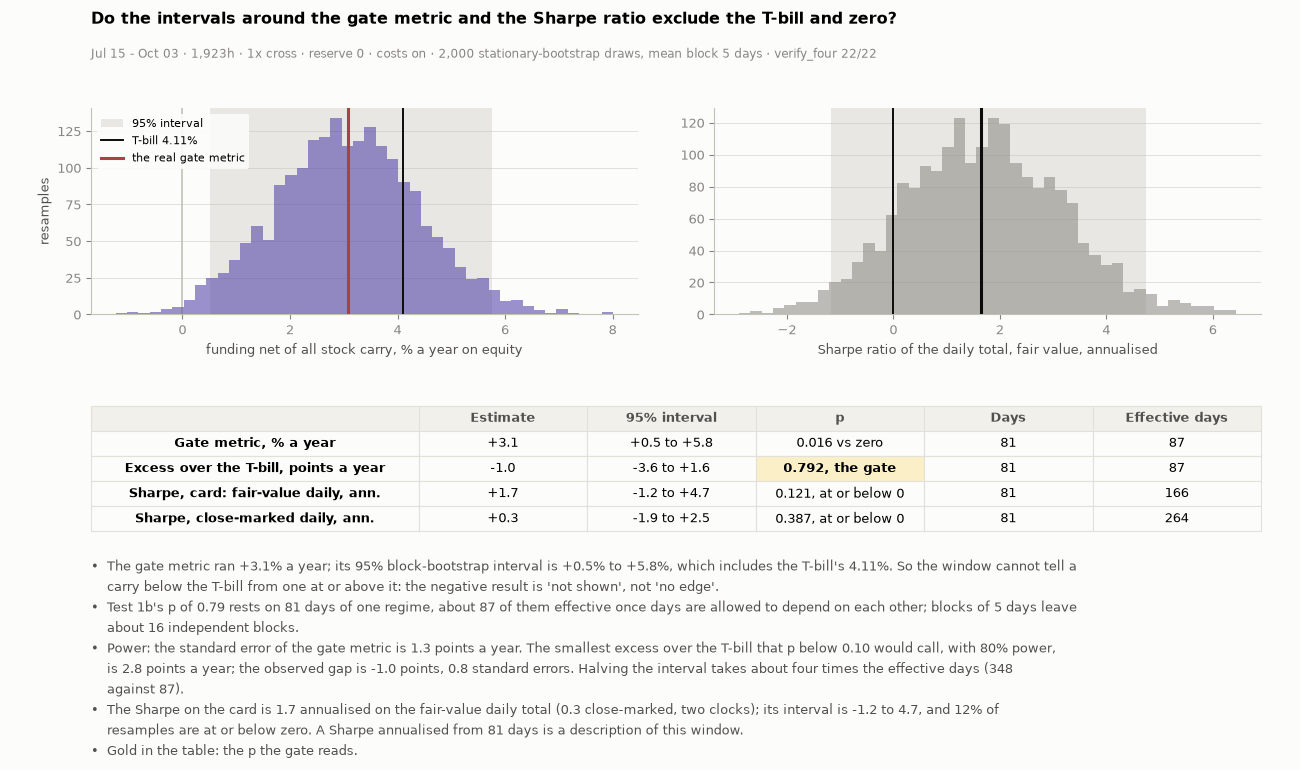

**What a sample this short could have shown.** The probabilistic Sharpe ratio (`stats.psr_from`, benchmark zero, this window's skew and kurtosis) of a sample that showed exactly the annualised Sharpe in the first column, over this window's days and over longer ones. A PSR near 0.95 is what it takes to call an edge; the observed Sharpe on the card is 1.7, PSR 0.78.

| True annualised Sharpe | 81 days (this window) | 162 days | 324 days |
|---|---|---|---|
| 0.5 | 0.59 | 0.63 | 0.68 |
| 1.0 | 0.68 | 0.75 | 0.82 |
| 2.0 | 0.82 | 0.90 | 0.97 |
| 3.0 | 0.91 | 0.97 | 1.00 |

**Sample-size disclosure.** 81 daily returns (1,923 hours, 80.1 days) in one regime, 857 hours before the 2026-08-20 split and 1,066 after it; about 16 independent 5-day blocks and 87 effective days of the excess over the T-bill. No minimum track-record length is computed: fundplat has no such function (board item filed), so the table above is the stand-in.

In [37]:
# ---- Inference 2: block-bootstrap intervals on the gate metric and the Sharpe ratio, the effective days, and what a sample this short could have shown ----
GM = np.asarray(DAY["funding_net_carry"].values, float)                      # the gate metric, USD a day: the series Test 1b reads
HURDLE_DAY2 = p1.hurdle_ann * EQUITY / 365.0
ann_sum = lambda S_: S_ / EQUITY * 100.0 * 365.0 / res["days"]                # a sum of daily USD over the window -> % a year on equity
Tm = len(GM)
bsG = np.asarray(ST.stationary_bootstrap_sums(list(GM), BOOT_BLOCK_D, NBOOT, SEED + 21))
gm_pt, gm_lo, gm_hi = ann_sum(GM.sum()), ann_sum(pctl(bsG, (1 - CI_LEVEL) / 2 * 100)), ann_sum(pctl(bsG, (1 + CI_LEVEL) / 2 * 100))
assert abs(gm_pt - carry_ann(res)) < 0.05, (gm_pt, carry_ann(res))
EX2 = GM - HURDLE_DAY2
ne_g, _ = eff_days(GM); ne_x, _ = eff_days(EX2)


def boot_sharpe(x, seed):
    """Annualised Sharpe on each stationary-bootstrap resample: the sums of x and of x squared on identical draws give each resample's mean and variance."""
    x = np.asarray(x, float); Tn = len(x); s_ = same_seed_sums({"x": x, "x2": x ** 2}, seed)
    m_ = s_["x"] / Tn; var_ = (s_["x2"] - Tn * m_ ** 2) / (Tn - 1)
    assert (var_ > 0).all(), "a resample with no variance"
    return m_ / np.sqrt(var_) * np.sqrt(365.0)


DR2 = np.asarray(list((DAY["total"] / EQUITY).values), float)                # the daily total, close-marked (two clocks): shown beside the card's Sharpe, never the card's
FVR2 = np.asarray(list((daily_cum(pd.Series(res["series"]["total_pnl_fv"], index=df.index, dtype=float)) / EQUITY).values), float)
SRS = {}
for k_, (nm_, x_) in enumerate((("Sharpe, card: fair-value daily", FVR2), ("Sharpe, close-marked daily", DR2))):
    assert abs(ST.sharpe(list(x_), 365) - x_.mean() / x_.std(ddof=1) * np.sqrt(365.0)) < 1e-9
    b_ = boot_sharpe(x_, SEED + 22 + k_); ne_, _ = eff_days(x_)
    SRS[nm_] = {"point": float(ST.sharpe(list(x_), 365)), "lo": float(pctl(b_, (1 - CI_LEVEL) / 2 * 100)), "hi": float(pctl(b_, (1 + CI_LEVEL) / 2 * 100)), "p_le0": float((b_ <= 0).mean()), "n": len(x_), "n_eff": float(ne_), "draws": b_}
SC = SRS["Sharpe, card: fair-value daily"]                                    # the card's Sharpe: the daily total on the fair-value mark, as the return and the drawdown are
LK = ST4["luck"]
se_gm = ann_sum(float(np.std(bsG)))                                         # the standard error of the gate metric, points a year
z_a, z_b = NormalDist().inv_cdf(1 - P_CUT), NormalDist().inv_cdf(0.80)
MDE = (z_a + z_b) * se_gm                                                   # the excess over the T-bill that p below P_CUT would call, with 80% power
gap = gm_pt - HURDLE_PCT
incl_h = bool(gm_lo <= HURDLE_PCT <= gm_hi)
BUL = [f"The gate metric ran {gm_pt:+.1f}% a year; its {CI_LEVEL * 100:.0f}% block-bootstrap interval is {gm_lo:+.1f}% to {gm_hi:+.1f}%, which {'includes' if incl_h else 'excludes'} the T-bill's {HURDLE_PCT:.2f}%. "
       + ("So the window cannot tell a carry below the T-bill from one at or above it: the negative result is 'not shown', not 'no edge'." if incl_h else "So the carry is below the T-bill beyond sampling noise on these days."),
       f"Test 1b's p of {LK['p_gate']:.2f} rests on {Tm} days of one regime, about {ne_x:.0f} of them effective once days are allowed to depend on each other; blocks of {BOOT_BLOCK_D} days leave about {Tm / BOOT_BLOCK_D:.0f} independent blocks.",
       f"Power: the standard error of the gate metric is {se_gm:.1f} points a year. The smallest excess over the T-bill that p below {P_CUT:.2f} would call, with 80% power, is {MDE:.1f} points a year; the observed gap is {gap:+.1f} points, {abs(gap) / se_gm:.1f} standard errors. Halving the interval takes about four times the effective days ({4 * ne_x:.0f} against {ne_x:.0f}).",
       f"The Sharpe on the card is {SC['point']:.1f} annualised on the fair-value daily total ({SRS['Sharpe, close-marked daily']['point']:.1f} close-marked, two clocks); its interval is {SC['lo']:.1f} to {SC['hi']:.1f}, and {SC['p_le0'] * 100:.0f}% of resamples are at or below zero. A Sharpe annualised from {SC['n']} days is a description of this window.",
       "Gold in the table: the p the gate reads."]
fig, gs, ax, axt = figstyle.fig_tab(5.4, (2.3, 1.4), top=0.80, hspace=0.55, nb=figstyle.nlines(BUL))
ax.axis("off"); sg5 = gs[0].subgridspec(1, 2, wspace=0.14); a1, a2 = fig.add_subplot(sg5[0]), fig.add_subplot(sg5[1])
a1.hist(ann_sum(bsG), bins=44, color=C_NET, alpha=0.55, zorder=3); a1.axvspan(gm_lo, gm_hi, color=AXIS, alpha=0.35, linewidth=0, zorder=1, label=f"{CI_LEVEL * 100:.0f}% interval")
a1.axvline(HURDLE_PCT, color=INK, linewidth=1.4, zorder=5, label=f"T-bill {HURDLE_PCT:.2f}%"); a1.axvline(0.0, color=AXIS, linewidth=1.2, zorder=2); a1.axvline(gm_pt, color=CRIT if gap < 0 else GOOD, linewidth=2.2, zorder=6, label="the real gate metric")
a1.set_xlabel("funding net of all stock carry, % a year on equity"); a1.set_ylabel("resamples"); a1.legend(loc="upper left", fontsize=8, **LEG); a1.grid(axis="x", visible=False)
a2.hist(SC["draws"], bins=44, color=MUTED, alpha=0.55, zorder=3); a2.axvspan(SC["lo"], SC["hi"], color=AXIS, alpha=0.35, linewidth=0, zorder=1); a2.axvline(0.0, color=INK, linewidth=1.4, zorder=5)
a2.axvline(SC["point"], color=INK, linewidth=2.2, zorder=6); a2.set_xlabel("Sharpe ratio of the daily total, fair value, annualised"); a2.grid(axis="x", visible=False)
fig.suptitle("Do the intervals around the gate metric and the Sharpe ratio exclude the T-bill and zero?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB} · {NBOOT:,} stationary-bootstrap draws, mean block {BOOT_BLOCK_D} days · verify_four {NCHK}/{NCHK}", color=MUTED, fontsize=8.5)
cells = [["Gate metric, % a year", f"{gm_pt:+.1f}", f"{gm_lo:+.1f} to {gm_hi:+.1f}", f"{LK['p_zero']:.3f} vs zero", f"{Tm}", f"{ne_g:.0f}"],
         ["Excess over the T-bill, points a year", f"{gap:+.1f}", f"{gm_lo - HURDLE_PCT:+.1f} to {gm_hi - HURDLE_PCT:+.1f}", f"{LK['p_gate']:.3f}, the gate", f"{Tm}", f"{ne_x:.0f}"]]
for nm_, s_ in SRS.items():
    cells.append([nm_ + ", ann.", f"{s_['point']:+.1f}", f"{s_['lo']:+.1f} to {s_['hi']:+.1f}", f"{s_['p_le0']:.3f}, at or below 0", f"{s_['n']}", f"{s_['n_eff']:.0f}"])
tb = figstyle.put_table(axt, cells, ["", "Estimate", f"{CI_LEVEL * 100:.0f}% interval", "p", "Days", "Effective days"], size=9.2, first=0.28)
figstyle.gold(tb, 2, 3)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-intervals", FIGURES)
# ---- the power statement, from psr_from: the PSR a sample of this length (and longer) would give if it showed exactly the Sharpe a true edge would have ----
tk = ST.tail_stats(list(FVR2))
SR_GRID, MULT = (0.5, 1.0, 2.0, 3.0), (1, 2, 4)                              # [U] hypothetical true annualised Sharpe ratios; multiples of this window's days


def psr_at(s_ann, mult):
    try:
        return float(ST.psr_from(s_ann / np.sqrt(365.0), SC["n"] * mult, tk["skew"], tk["kurtosis"], 0.0))
    except ValueError:
        return float("nan")


POWER = {f"{s_}": {f"{m_}": psr_at(s_, m_) for m_ in MULT} for s_ in SR_GRID}
display(Markdown("**What a sample this short could have shown.** The probabilistic Sharpe ratio (`stats.psr_from`, benchmark zero, this window's skew and kurtosis) of a sample that showed exactly the annualised Sharpe in the first column, over this window's days and over longer ones. A PSR near 0.95 is what it takes to call an edge; the observed Sharpe on the card is "
                 + f"{SC['point']:.1f}, PSR {float(ST.psr(list(FVR2))):.2f}.\n\n| True annualised Sharpe | {SC['n']} days (this window) | {2 * SC['n']} days | {4 * SC['n']} days |\n|---|---|---|---|\n"
                 + "\n".join(f"| {s_} | " + " | ".join(f"{POWER[f'{s_}'][f'{m_}']:.2f}" for m_ in MULT) + " |" for s_ in SR_GRID)
                 + f"\n\n**Sample-size disclosure.** {SC['n']} daily returns ({res['n_hours']:,} hours, {res['days']:.1f} days) in one regime, {SEG['in']['n_hours']:,} hours before the {SPLIT_DATE} split and {SEG['out']['n_hours']:,} after it; about {Tm / BOOT_BLOCK_D:.0f} independent {BOOT_BLOCK_D}-day blocks and {ne_x:.0f} effective days of the excess over the T-bill. "
                 f"No minimum track-record length is computed: fundplat has no such function (board item filed), so the table above is the stand-in."))
ST4["inference"] = {"gate": {"point": gm_pt, "lo": gm_lo, "hi": gm_hi, "se": se_gm, "mde80": MDE, "gap": gap, "includes_hurdle": incl_h, "n": Tm, "n_eff": float(ne_g), "n_eff_excess": float(ne_x), "p_gate": LK["p_gate"], "p_zero": LK["p_zero"]},
                    "sharpe": {nm_: {k_: v for k_, v in s_.items() if k_ != "draws"} for nm_, s_ in SRS.items()}, "power": POWER, "block": BOOT_BLOCK_D, "draws": NBOOT, "blocks": Tm / BOOT_BLOCK_D}

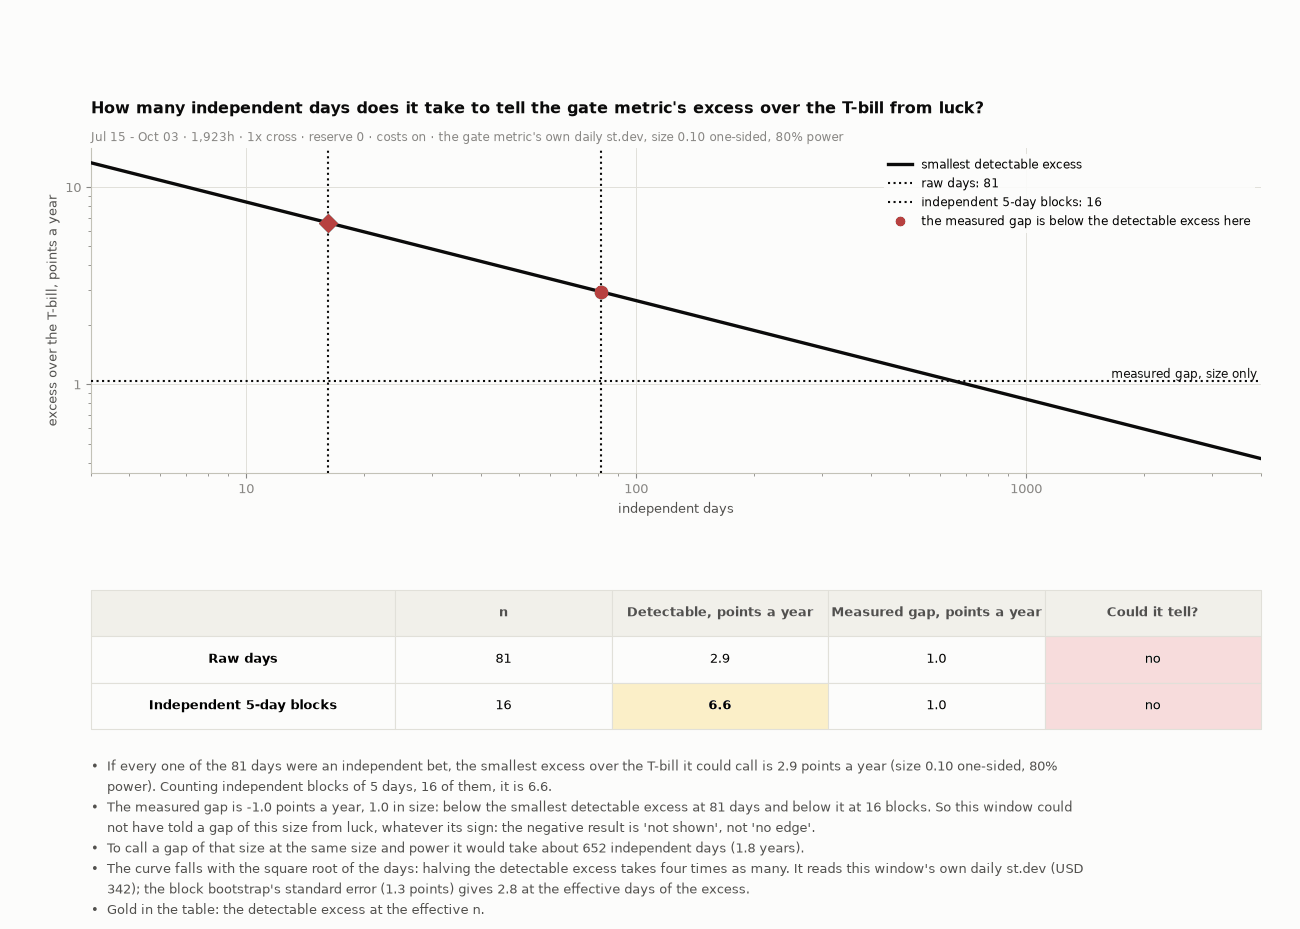

In [38]:
# ---- Sample size and power: how many independent days would the gate metric need to tell an excess over the T-bill from luck? (the chart bank's sample-size-and-power type; no new metric: the daily st.dev and the two z values above) ----
ANN_D = 365.0 * 100.0 / EQUITY                                       # a mean of the daily gate metric, USD -> ann % on equity
SD_D = float(np.std(GM, ddof=1))                                     # the st.dev of the daily gate metric, USD: the series Test 1b reads
Z_SUM = z_a + z_b                                                    # size P_CUT one-sided and 80% power: the same two z values as the power line above
N_RAW_D, N_EFF_D = float(Tm), Tm / BOOT_BLOCK_D                      # raw days, and independent blocks of BOOT_BLOCK_D days (the chart's effective n)
mde_at = lambda n_: Z_SUM * ANN_D * SD_D / np.sqrt(n_)               # the smallest excess over the T-bill, points a year, that n independent days detect
N_GRID = np.geomspace(4.0, 4000.0, 80)
EFFECT_ABS = abs(gap)                                                # the measured gap to the T-bill, size only: its sign is in the findings
N_NEED = (Z_SUM * ANN_D * SD_D / EFFECT_ABS) ** 2 if EFFECT_ABS > 0 else float("inf")
can_raw, can_eff = bool(EFFECT_ABS >= mde_at(N_RAW_D)), bool(EFFECT_ABS >= mde_at(N_EFF_D))
BUL = [f"If every one of the {Tm} days were an independent bet, the smallest excess over the T-bill it could call is {mde_at(N_RAW_D):.1f} points a year (size {P_CUT:.2f} one-sided, 80% power). Counting independent blocks of {BOOT_BLOCK_D} days, {N_EFF_D:.0f} of them, it is {mde_at(N_EFF_D):.1f}.",
       f"The measured gap is {gap:+.1f} points a year, {EFFECT_ABS:.1f} in size: {'above' if can_raw else 'below'} the smallest detectable excess at {Tm} days and {'above' if can_eff else 'below'} it at {N_EFF_D:.0f} blocks. "
       + ("The window could tell a gap of this size from luck." if can_eff else "So this window could not have told a gap of this size from luck, whatever its sign: the negative result is 'not shown', not 'no edge'."),
       f"To call a gap of that size at the same size and power it would take about {N_NEED:,.0f} independent days ({N_NEED / 365:.1f} years).",
       f"The curve falls with the square root of the days: halving the detectable excess takes four times as many. It reads this window's own daily st.dev (USD {SD_D:,.0f}); the block bootstrap's standard error ({se_gm:.1f} points) gives {MDE:.1f} at the effective days of the excess.",
       "Gold in the table: the detectable excess at the effective n."]
fig, gs, ax, axt = figstyle.fig_tab(7.4, (2.8, 1.2), top=0.80, hspace=0.5, nb=figstyle.nlines(BUL))
ax.plot(N_GRID, mde_at(N_GRID), color=INK, linewidth=2.4, zorder=4, label="smallest detectable excess")
ax.axhline(EFFECT_ABS, color=INK, linestyle=":", linewidth=1.5, zorder=3)
ax.text(N_GRID[-1], EFFECT_ABS, "measured gap, size only ", ha="right", va="bottom", color=INK, fontsize=8.5)
for k_, nm_, mk_ in ((N_RAW_D, f"raw days: {N_RAW_D:.0f}", "o"), (N_EFF_D, f"independent {BOOT_BLOCK_D}-day blocks: {N_EFF_D:.0f}", "D")):
    ax.axvline(k_, color=INK, linestyle=":", linewidth=1.5, zorder=3, label=nm_)
    ax.plot([k_], [mde_at(k_)], mk_, color=(GOOD if EFFECT_ABS >= mde_at(k_) else CRIT), markersize=9, zorder=6, linestyle="none")
ax.plot([], [], "o", color=CRIT, linestyle="none", label="the measured gap is below the detectable excess here")
if can_raw or can_eff:
    ax.plot([], [], "o", color=GOOD, linestyle="none", label="the measured gap clears the detectable excess here")
ax.set_xscale("log"); ax.set_yscale("log")
for a_ in (ax.xaxis, ax.yaxis):
    a_.set_major_formatter(plt.FuncFormatter(lambda v_, p_: f"{v_:g}")); a_.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(N_GRID[0], N_GRID[-1]); ax.set_xlabel("independent days"); ax.set_ylabel("excess over the T-bill, points a year")
ax.legend(loc="upper right", fontsize=8.5, **LEG)
ask(ax, "How many independent days does it take to tell the gate metric's excess over the T-bill from luck?", f"{WSB} · the gate metric's own daily st.dev, size {P_CUT:.2f} one-sided, 80% power")
cells = [["Raw days", f"{N_RAW_D:.0f}", f"{mde_at(N_RAW_D):.1f}", f"{EFFECT_ABS:.1f}", ("yes" if can_raw else "no")],
         [f"Independent {BOOT_BLOCK_D}-day blocks", f"{N_EFF_D:.0f}", f"{mde_at(N_EFF_D):.1f}", f"{EFFECT_ABS:.1f}", ("yes" if can_eff else "no")]]
tb = figstyle.put_table(axt, cells, ["", "n", "Detectable, points a year", "Measured gap, points a year", "Could it tell?"], size=9.5, first=0.26)
figstyle.gold(tb, 2, 2)
for r_i, ok_ in ((1, can_raw), (2, can_eff)):
    figstyle.tint(tb, r_i, 4, "green" if ok_ else "rose")
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-power", FIGURES)
ST4["power"] = {"sd_daily_usd": SD_D, "z_sum": float(Z_SUM), "n_raw": N_RAW_D, "n_eff": float(N_EFF_D), "mde_raw": float(mde_at(N_RAW_D)), "mde_eff": float(mde_at(N_EFF_D)), "gap": gap, "n_need_days": float(N_NEED), "can_raw": can_raw, "can_eff": can_eff}

## S5 · Risk and diagnostics

How does each hedge behave, does the spread revert, and where does the P&L print twice?

In [39]:
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
ST5 = {}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · 1x cross · reserve 0 · costs on"
S_ = res["series"]; TT = S_["time"]
t0_, t1_ = TT[0], TT[-1]
hour_of = lambda s_: min((t for t in TT if t - HOUR < s_ <= t), default=None)
IDX = {t: i for i, t in enumerate(TT)}

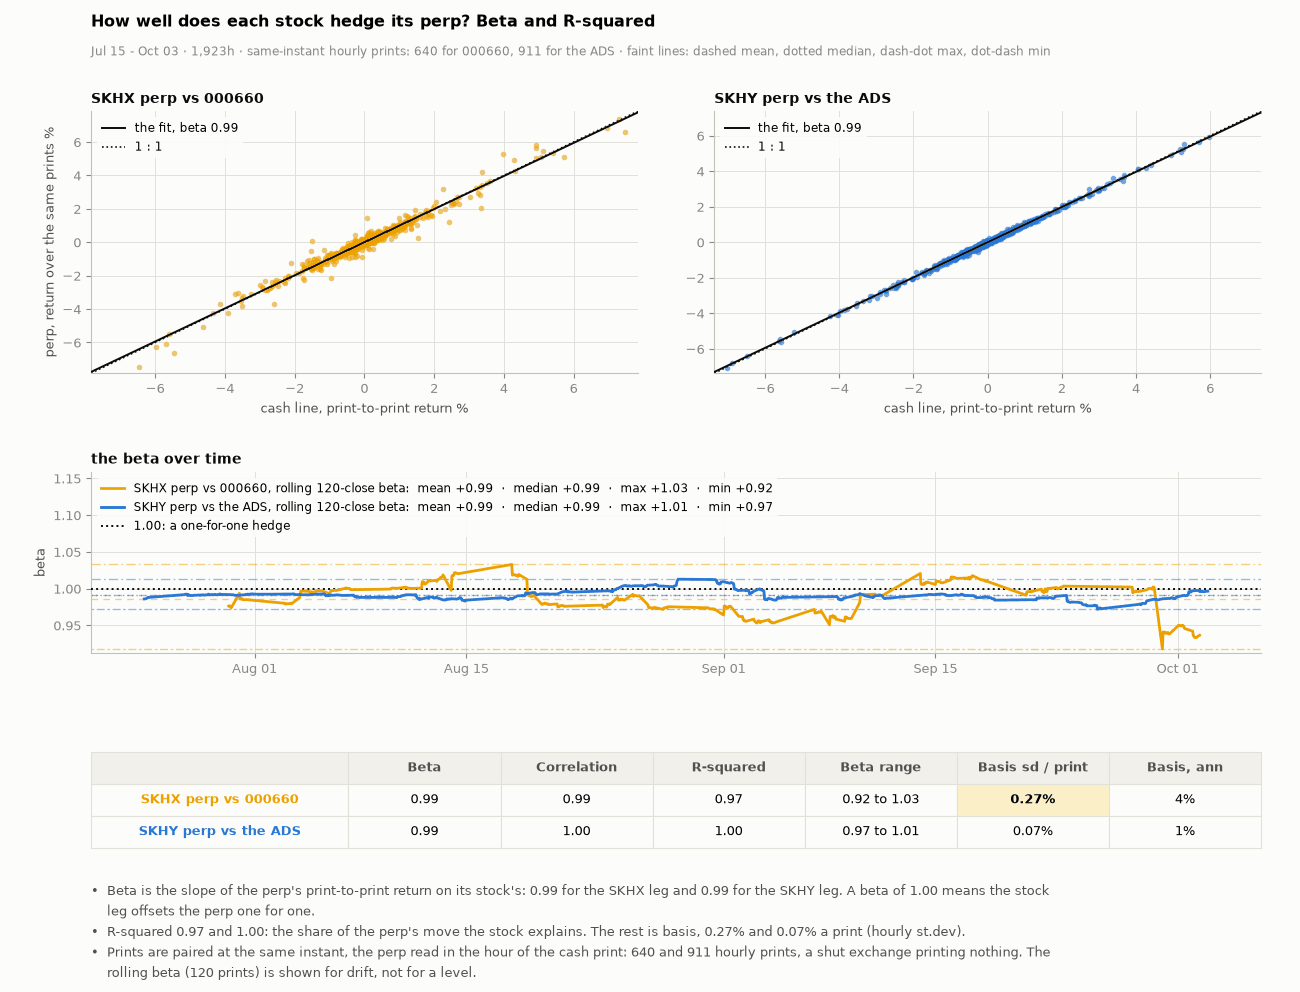

In [40]:
# ---- the same-instant pairs: at each cash close, the perp's USD price at that hour and the cash line's own close in USD ----
def pairs(marks, perp_key, fx_marks=None):
    out = []
    for st, px in marks:
        if not (t0_ <= st <= t1_):
            continue
        h_ = hour_of(st)
        if h_ is None:
            continue
        cash_ = px / asof(fx_marks, st) if fx_marks else px
        out.append((pd.Timestamp(st, unit="ms", tz="UTC"), cash_, S_[perp_key][IDX[h_]]))
    return pd.DataFrame(out, columns=["t", "cash", "perp"]).set_index("t")

PA, PB = pairs(MKH, "A_perp", MFH), pairs(MAH, "B_perp")
LEGS = (("A", "SKHX perp vs 000660", C_A, PA), ("B", "SKHY perp vs the ADS", C_B, PB))
HW = 120                                                                       # prints in the rolling window [U]
H = {}
for k, nm, col, P in LEGS:
    rc, rp = np.log(P["cash"]).diff().dropna(), np.log(P["perp"]).diff().dropna()
    beta, a0 = np.polyfit(rc, rp, 1)
    resid = rp - (a0 + beta * rc)
    r2 = float(1 - resid.var() / rp.var())
    rb = pd.Series(ST.rolling_slope(list(rp), list(rc), HW), index=rc.index).dropna()
    H[k] = {"rc": rc, "rp": rp, "beta": float(beta), "r2": r2, "corr": float(rc.corr(rp)), "resid_sd": float(resid.std() * 100), "n": int(len(rc)), "rb": rb, "te_ann": float(resid.std() * np.sqrt(252) * 100)}
bul = [f"Beta is the slope of the perp's print-to-print return on its stock's: {H['A']['beta']:.2f} for the SKHX leg and {H['B']['beta']:.2f} for the SKHY leg. A beta of 1.00 means the stock leg offsets the perp one for one.",
       f"R-squared {H['A']['r2']:.2f} and {H['B']['r2']:.2f}: the share of the perp's move the stock explains. The rest is basis, {H['A']['resid_sd']:.2f}% and {H['B']['resid_sd']:.2f}% a print (hourly st.dev).",
       f"Prints are paired at the same instant, the perp read in the hour of the cash print: {H['A']['n']} and {H['B']['n']} hourly prints, a shut exchange printing nothing. The rolling beta ({HW} prints) is shown for drift, not for a level."]
HH = 8.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig = plt.figure(figsize=(13, HH))
bm = figstyle.bullets(fig, bul)
gs = fig.add_gridspec(3, 2, height_ratios=[2.6, 1.8, 0.95], hspace=0.55, wspace=0.14, left=0.07, right=0.97, top=1 - 0.13 * 8.6 / HH, bottom=bm + 0.02)
s0, s1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); rb_ax = fig.add_subplot(gs[1, :]); axt = fig.add_subplot(gs[2, :]); axt.axis("off")
for a_, (k, nm, col, P) in zip((s0, s1), LEGS):
    h = H[k]; lim = float(np.nanpercentile(np.abs(np.r_[h["rc"], h["rp"]]) * 100, 99.5)) * 1.05; xx = np.array([-lim, lim])
    a_.scatter(h["rc"] * 100, h["rp"] * 100, s=16, color=col, alpha=0.6, linewidths=0, zorder=3)
    a_.plot(xx, h["beta"] * xx, color=INK, linewidth=1.4, zorder=4, label=f"the fit, beta {h['beta']:.2f}"); a_.plot(xx, xx, color=INK, linewidth=1.2, linestyle=":", zorder=2, label="1 : 1")
    a_.set_xlim(-lim, lim); a_.set_ylim(-lim, lim); a_.set_xlabel("cash line, print-to-print return %"); a_.legend(loc="upper left", fontsize=8.5, **LEG)
    a_.set_title(nm, fontsize=10, loc="left", pad=6)
s0.set_ylabel("perp, return over the same prints %")
for k, nm, col, P in LEGS:
    rb = H[k]["rb"]; rb_ax.plot(rb.index, rb, color=col, linewidth=2.0, zorder=4)
    v_ = figstyle.stat_lines(rb_ax, rb, col, with_min=True); rb_ax.plot([], [], color=col, linewidth=2.0, label=figstyle.tag(f"{nm}, rolling {HW}-close beta", v_, 2))
rb_ax.axhline(1.0, color=INK, linestyle=":", linewidth=1.4, zorder=3); rb_ax.plot([], [], color=INK, linestyle=":", linewidth=1.4, label="1.00: a one-for-one hedge")
rb_ax.set_ylabel("beta"); rb_ax.legend(loc="upper left", fontsize=8.3, ncol=1, **LEG); rb_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
yl = rb_ax.get_ylim(); rb_ax.set_ylim(yl[0], yl[1] + (yl[1] - yl[0]) * 0.95)       # head-room for the three-line legend: no line runs into it
rb_ax.set_title("the beta over time", fontsize=10, loc="left", pad=6)
fig.suptitle("How well does each stock hedge its perp? Beta and R-squared", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 1 - 0.065 * 8.6 / HH, f"{WSH} · same-instant hourly prints: {H['A']['n']} for 000660, {H['B']['n']} for the ADS · faint lines: dashed mean, dotted median, dash-dot max, dot-dash min", color=MUTED, fontsize=8.5)
cells = [[nm, f"{H[k]['beta']:.2f}", f"{H[k]['corr']:.2f}", f"{H[k]['r2']:.2f}", f"{H[k]['rb'].min():.2f} to {H[k]['rb'].max():.2f}", f"{H[k]['resid_sd']:.2f}%", f"{H[k]['te_ann']:.0f}%"] for k, nm, col, P in LEGS]
tb = put_table(axt, cells, ["", "Beta", "Correlation", "R-squared", "Beta range", "Basis sd / print", "Basis, ann"], size=9.5, first=0.22)
for r_i, (k, nm, col, P) in enumerate(LEGS, 1):
    tb[(r_i, 0)].set_text_props(color=col, weight="bold")
loose = 0 if H["A"]["resid_sd"] >= H["B"]["resid_sd"] else 1
gold(tb, loose + 1, 5)
figstyle.show(fig, "fig:s5-hedge", FIGURES)
ST5["hedge"] = {k: {kk: (float(vv) if not hasattr(vv, "index") else None) for kk, vv in H[k].items() if kk not in ("rc", "rp", "rb")} | {"rb_min": float(H[k]["rb"].min()), "rb_max": float(H[k]["rb"].max()), "rb_median": float(H[k]["rb"].median())} for k in H}

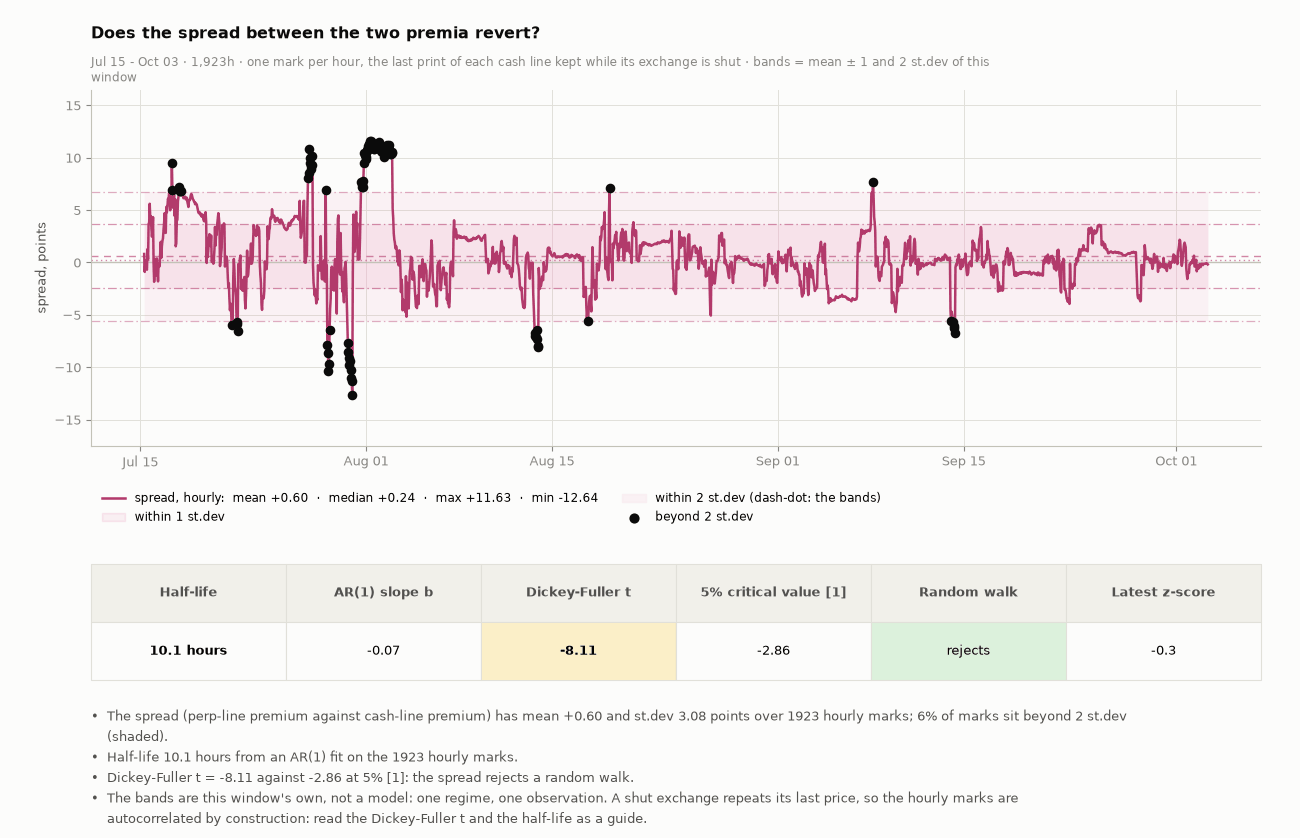

In [41]:
# ---- the spread at the same-instant marks, its z-score bands, half-life and Dickey-Fuller t ----
CX, DY, PYv, CYv = [], [], [], []
RT_ = {r_["time"]: r_ for r_ in rows}
for i_, st in enumerate(TT):
    kpx, a_, f_ = asof(MKH, st), asof(MAH, st), asof(MFH, st)          # hourly, a shut exchange keeps its last price
    if not (kpx and a_ and f_):
        continue
    kusd_ = kpx / f_
    cp_ = 10.0 * a_ / kusd_ * 100.0 - 100.0; pp_ = 10.0 * RT_[st]["B_perp"] / RT_[st]["A_perp"] * 100.0 - 100.0
    CX.append(pd.Timestamp(st, unit="ms", tz="UTC")); DY.append(((1 + pp_ / 100) / (1 + cp_ / 100) - 1) * 100); PYv.append(pp_); CYv.append(cp_)
SPD = pd.Series(DY, index=CX)
mu, sd = float(SPD.mean()), float(SPD.std())
y, x = SPD.diff().dropna().values, SPD.shift(1).dropna().values
X = np.c_[np.ones(len(x)), x]; coef, *_ = np.linalg.lstsq(X, y, rcond=None); resid = y - X @ coef
se_b = float(np.sqrt(resid.var(ddof=2) * np.linalg.inv(X.T @ X)[1, 1])); b_ = float(coef[1]); t_df = b_ / se_b
HL = float(-np.log(2) / np.log(1 + b_)) if -1 < b_ < 0 else (0.0 if b_ <= -1 else float("inf"))      # b below -1: the spread overshoots, it is gone within one mark
DF_CRIT = -2.86                                      # Dickey-Fuller 5% critical value with a constant, large sample [1] (MacKinnon table)
z = (SPD - mu) / sd
bul = [f"The spread (perp-line premium against cash-line premium) has mean {mu:+.2f} and st.dev {sd:.2f} points over {len(SPD)} hourly marks; {float((z.abs() > 2).mean() * 100):.0f}% of marks sit beyond 2 st.dev (shaded).",
       (f"Half-life {HL:.1f} hours from an AR(1) fit on the {len(SPD)} hourly marks." if 0 < HL < 1e6 else ("The AR(1) slope is below -1: the spread overshoots, so it is gone within one mark. It behaves like noise around zero, not like a slow reversion." if HL == 0.0 else "The AR(1) fit shows no mean reversion in this window.")),
       f"Dickey-Fuller t = {t_df:.2f} against {DF_CRIT} at 5% [1]: " + ("the spread rejects a random walk." if t_df < DF_CRIT else "it does NOT reject a random walk, so reversion is not established on this window."),
       "The bands are this window's own, not a model: one regime, one observation. A shut exchange repeats its last price, so the hourly marks are autocorrelated by construction: read the Dickey-Fuller t and the half-life as a guide."]
HS5 = 6.9 + figstyle.nlines(bul) * 0.205 + 0.3
fig, gs, ax, axt = fig_tab(6.9, (2.9, 0.95), hspace=0.5, nb=figstyle.nlines(bul))
ax.fill_between(SPD.index, mu - 2 * sd, mu + 2 * sd, color=C_PREM, alpha=0.08, linewidth=0, zorder=1); ax.fill_between(SPD.index, mu - sd, mu + sd, color=C_PREM, alpha=0.12, linewidth=0, zorder=1)
ax.plot(SPD.index, SPD, color=C_PREM_DK, linewidth=1.8, zorder=4)
for k_, yv in (("mean", mu), ("median", float(SPD.median()))):
    ax.axhline(yv, color=C_PREM_DK, linewidth=1.0, linestyle=figstyle.LS[k_], alpha=0.6, zorder=2)
for m_, a_ in ((1, 0.55), (2, 0.4)):
    for sg in (-1, 1):
        ax.axhline(mu + sg * m_ * sd, color=C_PREM_DK, linewidth=0.9, linestyle=figstyle.LS["max"], alpha=a_, zorder=2)
ob = SPD[z.abs() > 2]
ax.scatter(ob.index, ob, s=48, color=INK, zorder=6, linewidths=0)         # ink, not red: an outlier is not a loss
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("spread, points")
ax.plot([], [], color=C_PREM_DK, linewidth=1.8, label=figstyle.tag("spread, hourly", {"mean": mu, "median": float(SPD.median()), "max": float(SPD.max()), "min": float(SPD.min())}, 2))
ax.fill_between([], [], color=C_PREM, alpha=0.12, label="within 1 st.dev"); ax.fill_between([], [], color=C_PREM, alpha=0.08, label="within 2 st.dev (dash-dot: the bands)")
ax.scatter([], [], s=40, color=INK, label="beyond 2 st.dev"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=2, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
yf = figstyle.yfit; yf(ax, [SPD], pad=0.2)
ask(ax, "Does the spread between the two premia revert?", f"{WSH} · one mark per hour, the last print of each cash line kept while its exchange is shut · bands = mean ± 1 and 2 st.dev of this window")
cells = [[(f"{HL:.1f} hours" if 0 < HL < 1e6 else ("under 1 mark" if HL == 0.0 else "none")), f"{b_:+.2f}", f"{t_df:.2f}", f"{DF_CRIT}", ("rejects" if t_df < DF_CRIT else "does not reject"), f"{float(z.iloc[-1]):+.1f}"]]
tb = put_table(axt, cells, ["Half-life", "AR(1) slope b", "Dickey-Fuller t", "5% critical value [1]", "Random walk", "Latest z-score"], size=9.5)
gold(tb, 1, 2); tint(tb, 1, 4, "green" if t_df < DF_CRIT else "rose")
figstyle.bullets(fig, bul)
figstyle.show(fig, "fig:s5-spread", FIGURES)
ST5["spread"] = {"n": int(len(SPD)), "mean": mu, "sd": sd, "half_life_d": HL, "b": b_, "t_df": t_df, "df_crit": DF_CRIT, "reject": bool(t_df < DF_CRIT), "share_beyond_2sd": float((z.abs() > 2).mean() * 100), "z_last": float(z.iloc[-1]),
                   "min": float(SPD.min()), "max": float(SPD.max())}

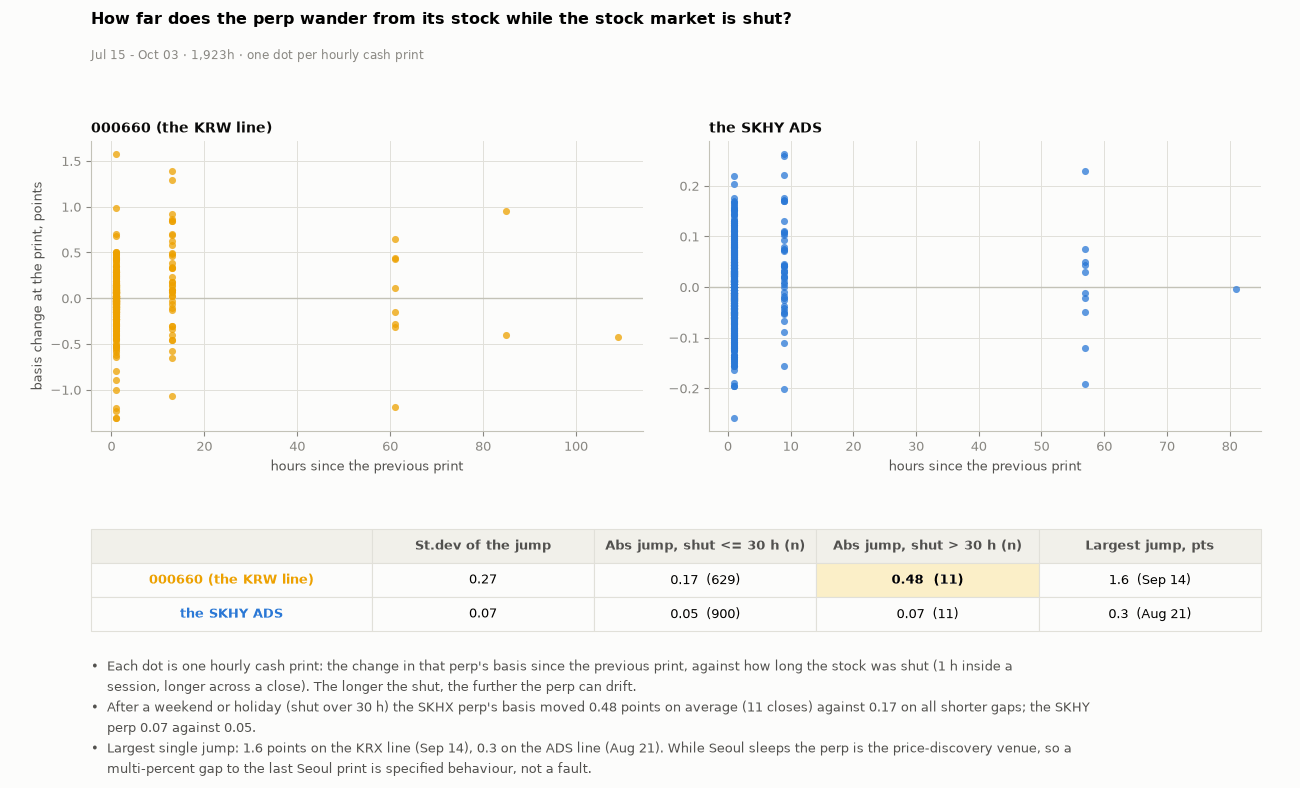

In [42]:
# ---- while a cash market is shut: how far the perp wanders from it, and the jump at the reopen ----
def reopen_jumps(marks, perp_key, fx_marks=None):
    out, prev = [], None
    for st, px in marks:
        if not (t0_ <= st <= t1_):
            continue
        h_ = hour_of(st)
        if h_ is None:
            continue
        cash_ = px / asof(fx_marks, st) if fx_marks else px
        b_ = (S_[perp_key][IDX[h_]] / cash_ - 1) * 100
        if prev is not None:
            out.append({"close": pd.Timestamp(st, unit="ms", tz="UTC"), "shut_h": (st - prev[0]) / HOUR, "jump": b_ - prev[1]})
        prev = (st, b_)
    return pd.DataFrame(out)

RJ = {"A": reopen_jumps(MKH, "A_perp", MFH), "B": reopen_jumps(MAH, "B_perp")}
NAMES2 = {"A": "000660 (the KRW line)", "B": "the SKHY ADS"}
COL2 = {"A": C_A, "B": C_B}
SH = {}
for k, d in RJ.items():
    lng = d[d["shut_h"] > 30]["jump"].abs(); sht = d[d["shut_h"] <= 30]["jump"].abs()
    SH[k] = {"sd": float(d["jump"].std()), "long_mean": float(lng.mean()) if len(lng) else float("nan"), "short_mean": float(sht.mean()), "n_long": int(len(lng)), "n_short": int(len(sht)), "worst": float(d["jump"].abs().max()), "worst_day": f"{d.loc[d['jump'].abs().idxmax(), 'close']:%b %d}"}
bul = [f"Each dot is one hourly cash print: the change in that perp's basis since the previous print, against how long the stock was shut (1 h inside a session, longer across a close). The longer the shut, the further the perp can drift.",
       f"After a weekend or holiday (shut over 30 h) the SKHX perp's basis moved {SH['A']['long_mean']:.2f} points on average ({SH['A']['n_long']} closes) against {SH['A']['short_mean']:.2f} on all shorter gaps; the SKHY perp {SH['B']['long_mean']:.2f} against {SH['B']['short_mean']:.2f}.",
       f"Largest single jump: {SH['A']['worst']:.1f} points on the KRX line ({SH['A']['worst_day']}), {SH['B']['worst']:.1f} on the ADS line ({SH['B']['worst_day']}). While Seoul sleeps the perp is the price-discovery venue, so a multi-percent gap to the last Seoul print is specified behaviour, not a fault."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 0.95), top=0.78, hspace=0.5, nb=figstyle.nlines(bul))
ax.axis("off"); sg = gs[0].subgridspec(1, 2, wspace=0.12); a0, a1 = fig.add_subplot(sg[0]), fig.add_subplot(sg[1])
for a_, k in ((a0, "A"), (a1, "B")):
    d = RJ[k]; a_.scatter(d["shut_h"], d["jump"], s=26, color=COL2[k], alpha=0.75, linewidths=0, zorder=3); a_.axhline(0, color=AXIS, linewidth=1)
    a_.set_xlabel("hours since the previous print"); a_.set_title(NAMES2[k], fontsize=10, loc="left", pad=6); a_.grid(True)
a0.set_ylabel("basis change at the print, points")
fig.suptitle("How far does the perp wander from its stock while the stock market is shut?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · one dot per hourly cash print", color=MUTED, fontsize=8.5)
cells = [[NAMES2[k], f"{SH[k]['sd']:.2f}", f"{SH[k]['short_mean']:.2f}  ({SH[k]['n_short']})", f"{SH[k]['long_mean']:.2f}  ({SH[k]['n_long']})", f"{SH[k]['worst']:.1f}  ({SH[k]['worst_day']})"] for k in ("A", "B")]
tb = put_table(axt, cells, ["", "St.dev of the jump", "Abs jump, shut <= 30 h (n)", "Abs jump, shut > 30 h (n)", "Largest jump, pts"], size=9.2, first=0.24)
for r_i, k in enumerate(("A", "B"), 1): tb[(r_i, 0)].set_text_props(color=COL2[k], weight="bold")
gold(tb, 1 if SH["A"]["long_mean"] >= SH["B"]["long_mean"] else 2, 3)
figstyle.bullets(fig, bul)
figstyle.show(fig, "fig:s5-shut", FIGURES)
ST5["shut"] = SH

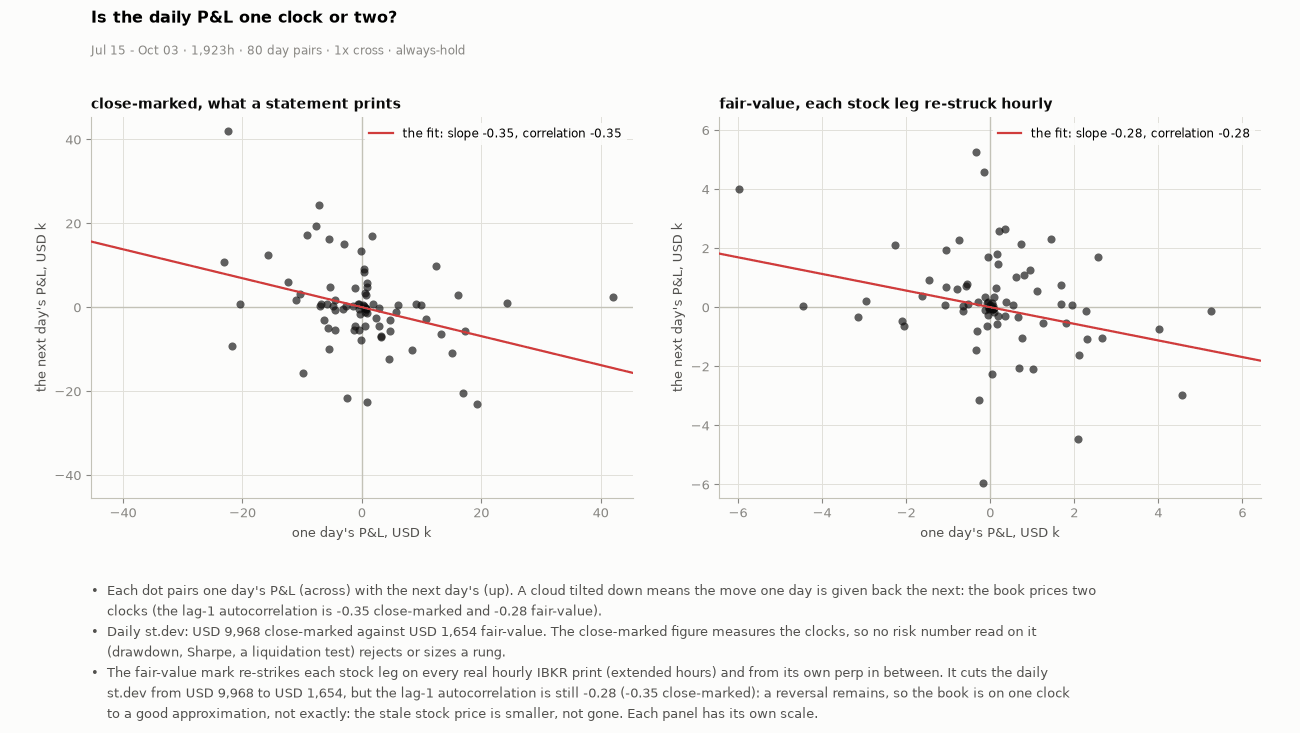

In [43]:
# ---- one clock or two: today's daily P&L against tomorrow's, close-marked and fair-value ----
FVs = pd.Series(S_["total_pnl_fv"], index=df.index, dtype=float)
dcl, dfv = DAYS_[BOOK]["total"], daily_cum(FVs)
bul_stats = {}
for nm, s in (("close-marked", dcl), ("fair-value", dfv)):
    a_, b_ = s.iloc[:-1].values, s.iloc[1:].values
    bul_stats[nm] = {"ac": float(np.corrcoef(a_, b_)[0, 1]), "slope": float(np.polyfit(a_, b_, 1)[0]), "sd": float(s.std()), "n": int(len(a_))}
wk = pd.DataFrame({"s": dcl, "dow": dcl.index.dayofweek})
wk_sd = {"weekday": float(wk[wk["dow"] < 5]["s"].std()), "weekend": float(wk[wk["dow"] >= 5]["s"].std())}
bul = [f"Each dot pairs one day's P&L (across) with the next day's (up). A cloud tilted down means the move one day is given back the next: the book prices two clocks (the lag-1 autocorrelation is {bul_stats['close-marked']['ac']:+.2f} close-marked and {bul_stats['fair-value']['ac']:+.2f} fair-value).",
       f"Daily st.dev: USD {bul_stats['close-marked']['sd']:,.0f} close-marked against USD {bul_stats['fair-value']['sd']:,.0f} fair-value. The close-marked figure measures the clocks, so no risk number read on it (drawdown, Sharpe, a liquidation test) rejects or sizes a rung.",
       f"The fair-value mark re-strikes each stock leg on every real hourly IBKR print (extended hours) and from its own perp in between. It cuts the daily st.dev from USD {bul_stats['close-marked']['sd']:,.0f} to USD {bul_stats['fair-value']['sd']:,.0f}, but the lag-1 autocorrelation is still {bul_stats['fair-value']['ac']:+.2f} ({bul_stats['close-marked']['ac']:+.2f} close-marked): "
       + ("a reversal remains, so the book is on one clock to a good approximation, not exactly: the stale stock price is smaller, not gone. Each panel has its own scale." if bul_stats['fair-value']['ac'] < -0.1 else "little reversal remains, so the fair-value mark is on one clock to a good approximation. Each panel has its own scale.")]
HP5 = 5.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig, axs = plt.subplots(1, 2, figsize=(13, HP5))
bm = figstyle.bullets(fig, bul)
for a_, (nm, s) in zip(axs, (("close-marked, what a statement prints", dcl), ("fair-value, each stock leg re-struck hourly", dfv))):
    key = "close-marked" if nm.startswith("close") else "fair-value"
    lim = float(s.abs().max() / 1e3) * 1.08                                   # each panel on its own scale: the fair-value days are a fraction of the close-marked ones
    a_.scatter(s.iloc[:-1] / 1e3, s.iloc[1:] / 1e3, s=34, color=INK, alpha=0.65, linewidths=0, zorder=3)
    xx = np.array([-lim, lim]); a_.plot(xx, bul_stats[key]["slope"] * xx, color=CRIT, linewidth=1.6, zorder=4, label=f"the fit: slope {bul_stats[key]['slope']:+.2f}, correlation {bul_stats[key]['ac']:+.2f}")
    a_.axhline(0, color=AXIS, linewidth=1); a_.axvline(0, color=AXIS, linewidth=1)
    a_.set_xlim(-lim, lim); a_.set_ylim(-lim, lim); a_.set_xlabel("one day's P&L, USD k"); a_.legend(loc="upper right", fontsize=8.5, **LEG); a_.set_title(nm, fontsize=10, loc="left", pad=6)
for a_ in axs: a_.set_ylabel("the next day's P&L, USD k")
fig.suptitle("Is the daily P&L one clock or two?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · {bul_stats['close-marked']['n']} day pairs · 1x cross · always-hold", color=MUTED, fontsize=8.5)
plt.subplots_adjust(top=0.84, bottom=bm + 0.7 / HP5, left=0.07, right=0.97, wspace=0.16)
figstyle.show(fig, "fig:s5-clocks", FIGURES)
ST5["clocks"] = {**bul_stats, "wk": wk_sd}

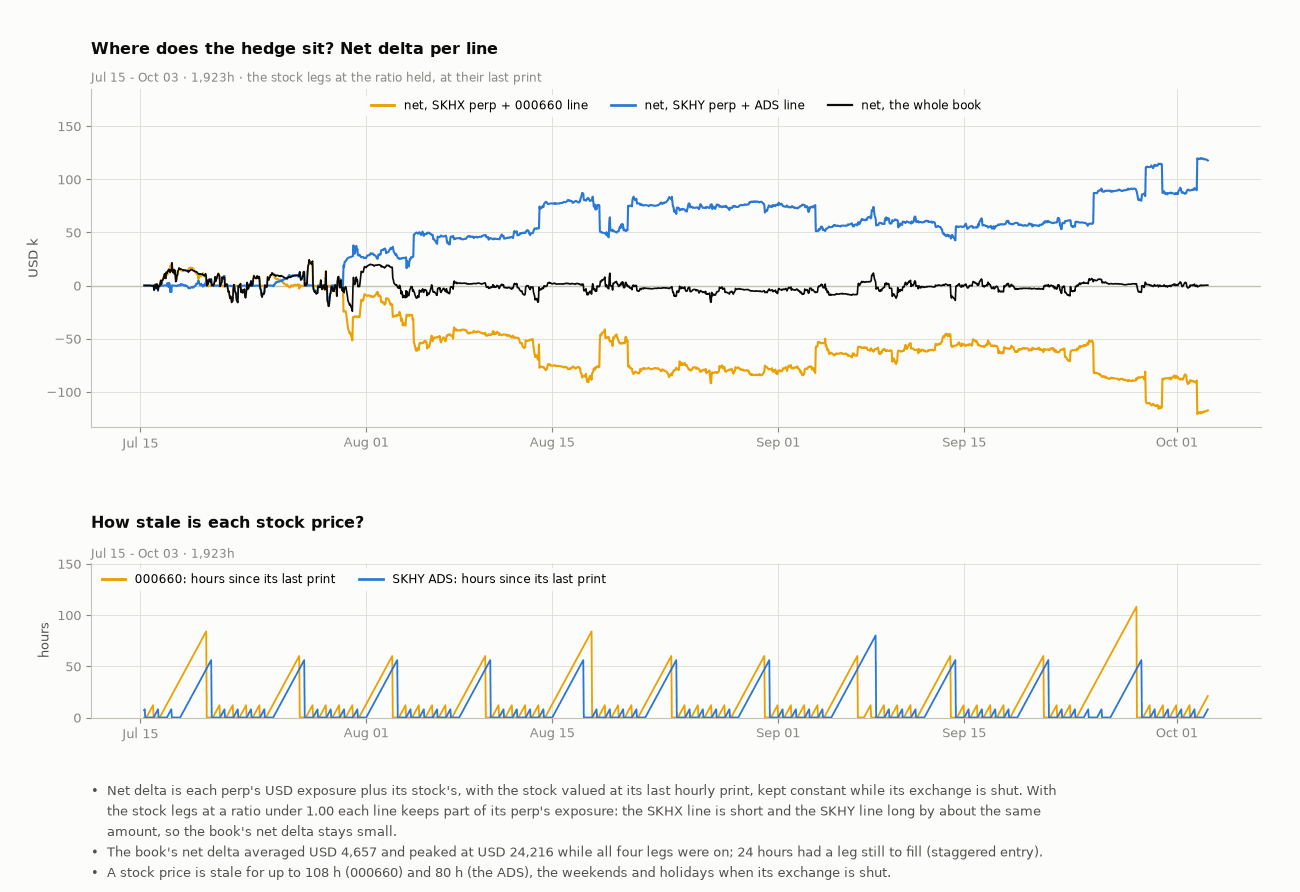

In [44]:
# ---- where the hedge sits: net delta per line (the perp against its own stock at its last close) and how stale each stock price is ----
sgn_ = SIDE[BOOK]
EXPO = pd.DataFrame({
    "SKHX perp": [sgn_ * q * a for q, a in zip(S_["target_units_A"], S_["A_perp"])],
    "000660 shares": [-sgn_ * q * (asof(MKH, t) or 0.0) / (asof(MFH, t) or 1.0) for q, t in zip(S_["qty_krx"], TT)],
    "SKHY perp": [-sgn_ * q * b for q, b in zip(S_["target_units_B"], S_["B_perp"])],
    "SKHY ADS": [sgn_ * q * (asof(MAH, t) or 0.0) for q, t in zip(S_["qty_ads"], TT)]}, index=df.index)
EXPO["net_A"] = EXPO["SKHX perp"] + EXPO["000660 shares"]; EXPO["net_B"] = EXPO["SKHY perp"] + EXPO["SKHY ADS"]; EXPO["net"] = EXPO["net_A"] + EXPO["net_B"]
EXPO = EXPO.iloc[:-1]                      # the last hour is the forced exit: the stock quantities are already zero while the perp targets are not
def last_stamp(marks, t):
    v = None
    for s_, _ in marks:
        if s_ <= t: v = s_
        else: break
    return v
STALE = pd.DataFrame({"A": [(t - (last_stamp(MKH, t) or t)) / HOUR for t in TT], "B": [(t - (last_stamp(MAH, t) or t)) / HOUR for t in TT]}, index=df.index)
both_on = ((num(df["on_A"]) > 0) & (num(df["on_B"]) > 0)).iloc[:-1]
STALE = STALE.iloc[:-1]
naked_h = int((~both_on).sum())
bul = [f"Net delta is each perp's USD exposure plus its stock's, with the stock valued at its last hourly print, kept constant while its exchange is shut. With the stock legs at a ratio under 1.00 each line keeps part of its perp's exposure: the SKHX line is short and the SKHY line long by about the same amount, so the book's net delta stays small.",
       f"The book's net delta averaged USD {EXPO['net'].where(both_on).abs().mean():,.0f} and peaked at USD {EXPO['net'].where(both_on).abs().max():,.0f} while all four legs were on; {naked_h} hours had a leg still to fill (staggered entry).",
       f"A stock price is stale for up to {STALE['A'].max():.0f} h (000660) and {STALE['B'].max():.0f} h (the ADS), the weekends and holidays when its exchange is shut."]
HX = 7.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig, (x1, x2) = plt.subplots(2, 1, figsize=(13, HX), gridspec_kw={"height_ratios": [2.4, 1.1]})
bm = figstyle.bullets(fig, bul)
for k_, col, lw_ in (("net_A", C_A, 1.5), ("net_B", C_B, 1.5), ("net", INK, 1.2)):
    x1.plot(EXPO.index, EXPO[k_] / 1e3, color=col, linewidth=lw_, zorder=4 if k_ == "net" else 3)
x1.plot([], [], color=C_A, linewidth=2.0, label="net, SKHX perp + 000660 line"); x1.plot([], [], color=C_B, linewidth=2.0, label="net, SKHY perp + ADS line"); x1.plot([], [], color=INK, linewidth=1.6, label="net, the whole book")
x1.axhline(0, color=AXIS, linewidth=1); x1.set_ylabel("USD k"); x1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
_y0, _y1 = x1.get_ylim(); x1.set_ylim(_y0, _y1 + (_y1 - _y0) * 0.2); x1.legend(loc="upper center", ncol=3, fontsize=8.5, **LEG)        # head-room: the legend sits above every line
ask(x1, "Where does the hedge sit? Net delta per line", f"{WSH} · the stock legs at the ratio held, at their last print")
x2.plot(STALE.index, STALE["A"], color=C_A, linewidth=1.3); x2.plot(STALE.index, STALE["B"], color=C_B, linewidth=1.3)
x2.plot([], [], color=C_A, linewidth=2.0, label="000660: hours since its last print"); x2.plot([], [], color=C_B, linewidth=2.0, label="SKHY ADS: hours since its last print")
x2.set_ylabel("hours"); x2.legend(loc="upper left", fontsize=8.5, ncol=2, **LEG); x2.set_ylim(0, float(STALE.max().max()) * 1.4); x2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(x2, "How stale is each stock price?", f"{WSH}")
plt.subplots_adjust(top=0.90, bottom=bm + 0.5 / HX, hspace=0.55, left=0.07, right=0.97)
figstyle.show(fig, "fig:s5-sits", FIGURES)
ST5["sits"] = {"net_abs_mean": float(EXPO["net"].where(both_on).abs().mean()), "net_abs_max": float(EXPO["net"].where(both_on).abs().max()), "naked_h": naked_h, "stale_A": float(STALE["A"].max()), "stale_B": float(STALE["B"].max()),
                 "netA_sd": float(EXPO["net_A"].std()), "netB_sd": float(EXPO["net_B"].std())}

## S6 · Decision

What size, which account binds, can it be filled? Information only if S3 and S4 failed.

In [45]:
GATES_IN = ST4["gates"]

from matplotlib.patches import Patch
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
def foot(fig, *lines):
    figstyle.bullets(fig, [t for t in lines if t])

ST6 = {}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · cross · reserve 0 · costs on"
PASSED = bool(all(GATES_IN[k] for k in ("base", "oos", "luck", "costs")))          # the gates before sizing: the unlevered base, out of sample, luck, costs
SIZED_NOTE = "SIZED" if PASSED else "INFORMATION ONLY: a gate before sizing failed"

In [46]:
# ---- the rungs: one engine run per leverage, reserve 0, every one verified ----
GR = {}
for L in LEVS:
    for R in RESV:
        r_ = run4(rows, fp(L, R, BOOK)); c_ = vfour(r_, rows, f"grid {L}x reserve {R:g}x")
        assert len(c_) == NCHK, (L, R)
        assert abs(r_["perp_capital"] - (EQUITY - ib_cash(r_["notional_usd"]))) < 1e-6 and abs(4 * r_["notional_usd"] - L * EQUITY) < 1e-6
        GR[(L, R)] = r_
LAD = {L: (GR[(L, 0.0)], frame(GR[(L, 0.0)])) for L in LEVS}
FVDD = {}
for L in LEVS:
    fv_ = pd.Series(LAD[L][0]["series"]["total_pnl_fv"], index=LAD[L][1].index, dtype=float); e_ = EQUITY + fv_
    FVDD[L] = float((e_ / e_.cummax() - 1.0).min()) * 100                     # the FAIR-VALUE drawdown: close-marked risk numbers never reject or size a rung
WICKPT = {L: wick_room(LAD[L][0], BOOK)[0] for L in LEVS}
ROOM_ENTRY = {L: room_and_level(BOOK, x_liq(L, 0.0), P0)[0] for L in LEVS}
def close_room(r_):
    S_ = r_["series"]; v = [1e18 if x is None else float(x) for x in S_["dist_book_pct"]]; k_ = int(np.argmin(v))
    return room_and_level(BOOK, v[k_], float(S_["implied_premium_pct"][k_]))[0]
CLOSEPT = {L: close_room(LAD[L][0]) for L in LEVS}
aA = np.array([rows[i]["A_hi"] / rows[i - 1]["A_perp"] - 1.0 for i in range(1, len(rows))]) * 100       # the book is SHORT SKHX: adverse = up
aB = np.array([1.0 - rows[i]["B_lo"] / rows[i - 1]["B_perp"] for i in range(1, len(rows))]) * 100       # and LONG SKHY: adverse = down
jt = 0.5 * (aA + aB); kJ = int(jt.argmax()); WJ = float(jt[kJ])
WJ_PTS = room_and_level(BOOK, WJ, P0)[0] or 0.0
REQ_PTS = STOP_PTS + WJ_PTS
prem_ = num(df["implied_premium_pct"]); WORST_WIDEN = float((prem_ - P0).max()); WORST_NARROW = float(-(prem_ - P0).min())
VF = {(L, R): GR[(L, R)]["venue_feasible"] for L in LEVS for R in RESV}
PLACEABLE = {k: bool(v["book_feasible"]) and (ib_cash(GR[k]["notional_usd"]) + 2 * GR[k]["notional_usd"] / MAXLEV <= EQUITY + 1e-6) for k, v in VF.items()}        # the venue accepts it AND the equity funds both accounts
SPLIT_MAX = VF[(LEVS[0], RESV[0])]["max_placeable_leverage"]
L_MAX_PLACEABLE = max(L for L in LEVS if PLACEABLE[(L, 0.0)])
OKR = [L for L in LEVS if (ROOM_ENTRY[L] is None or ROOM_ENTRY[L] > REQ_PTS) and FVDD[L] > -DD_LIMIT_PCT and LAD[L][0]["liquidations"] == 0 and (WICKPT[L] is None or WICKPT[L] > STOP_PTS) and PLACEABLE[(L, 0.0)]]
L_PICK = max(OKR) if OKR else None
SIZED = bool(PASSED and L_PICK); SHOWN = L_PICK                       # the rung printed as information when not SIZED
NLIQ = int(sum(r_["liquidations"] for r_ in GR.values()))
gate_ann = {L: carry_ann(LAD[L][0]) for L in LEVS}; tot_ann = {L: eq_ann(LAD[L][0]) for L in LEVS}
liqL = [L for L in LEVS if LAD[L][0]["liquidations"]]

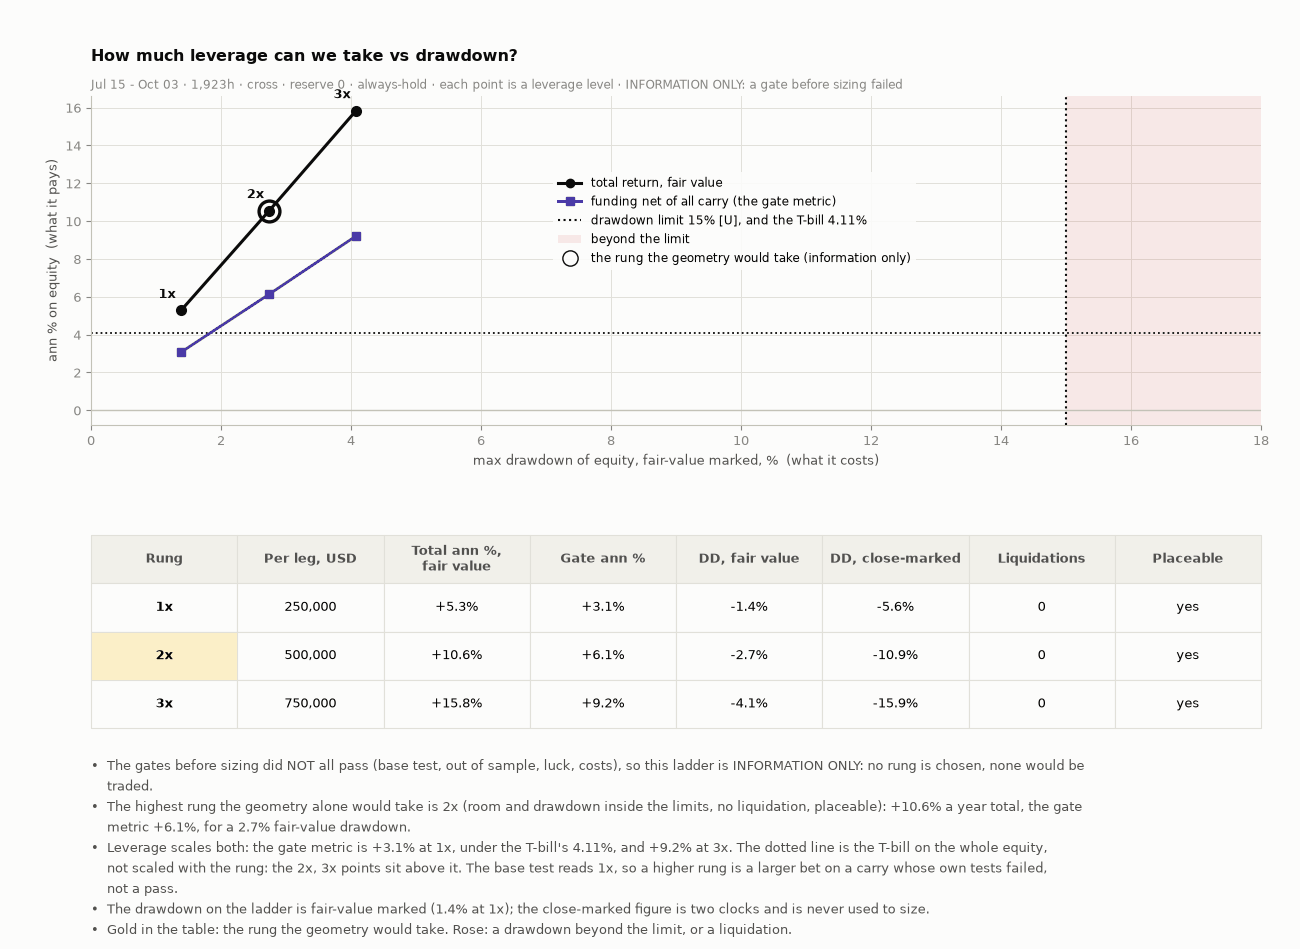

In [47]:
# ---- 6.1 the ladder: what each rung pays against the fair-value drawdown it costs ----
LAD_SHOW = [L for L in LEVS if PLACEABLE[(L, 0.0)] and not LAD[L][0]["liquidations"]]
ABOVE_BAR = [L for L in LAD_SHOW if gate_ann[L] > HURDLE_PCT]                  # the rungs whose gate metric sits above the (unscaled) T-bill line of this picture
LB = [f"The gates before sizing {'passed' if PASSED else 'did NOT all pass'} (base test, out of sample, luck, costs), so this ladder is " + ("the sized book." if PASSED else "INFORMATION ONLY: no rung is chosen, none would be traded."),
      f"The highest rung the geometry alone would take is {SHOWN}x (room and drawdown inside the limits, no liquidation, placeable): {tot_ann[SHOWN]:+.1f}% a year total, the gate metric {gate_ann[SHOWN]:+.1f}%, for a {abs(FVDD[SHOWN]):.1f}% fair-value drawdown." if SHOWN else "No rung clears the geometry.",
      f"Leverage scales both: the gate metric is {gate_ann[LEVS[0]]:+.1f}% at {LEVS[0]}x, {'under' if gate_ann[LEVS[0]] <= HURDLE_PCT else 'above'} the T-bill's {HURDLE_PCT:.2f}%, and {gate_ann[L_MAX_PLACEABLE]:+.1f}% at {L_MAX_PLACEABLE}x. The dotted line is the T-bill on the whole equity, not scaled with the rung: "
      + (f"the {', '.join(f'{L}x' for L in ABOVE_BAR)} points sit above it. " if ABOVE_BAR else "no point sits above it. ")
      + "The base test reads 1x, so a higher rung is a larger bet on a carry whose own tests failed, not a pass.",
      f"The drawdown on the ladder is fair-value marked ({abs(FVDD[LEVS[0]]):.1f}% at {LEVS[0]}x); the close-marked figure is two clocks and is never used to size. " + (f"Rung(s) {', '.join(f'{L}x' for L in liqL)} liquidate and are off the lines." if liqL else ""),
      "Gold in the table: the rung the geometry would take. Rose: a drawdown beyond the limit, or a liquidation."]
fig, gs, ax, axt = fig_tab(7.4, (2.9, 1.7), hspace=0.42, nb=figstyle.nlines(LB))
xv = [abs(FVDD[L]) for L in LAD_SHOW]
ax.axvspan(DD_LIMIT_PCT, max(max(xv) * 1.1, DD_LIMIT_PCT * 1.2), color=CRIT, alpha=0.10, linewidth=0, zorder=1); ax.axvline(DD_LIMIT_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=3)
ax.plot(xv, [tot_ann[L] for L in LAD_SHOW], "o-", color=INK, linewidth=2.2, markersize=7, zorder=4); ax.plot(xv, [gate_ann[L] for L in LAD_SHOW], "s-", color=C_NET, linewidth=2.0, markersize=6, zorder=4)
ax.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.3, zorder=2)
for L, a_, b_ in zip(LAD_SHOW, xv, [tot_ann[L] for L in LAD_SHOW]):
    ax.annotate(f"{L}x", xy=(a_, b_), xytext=(-4, 9), textcoords="offset points", fontsize=9, fontweight="bold", color=INK, ha="right", zorder=6)
if SHOWN:
    ax.plot([abs(FVDD[SHOWN])], [tot_ann[SHOWN]], "o", color=GOOD if SIZED else INK, markersize=15, markerfacecolor="none", markeredgecolor=GOOD if SIZED else INK, markeredgewidth=2.4, zorder=5)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_xlim(0, max(max(xv) * 1.1, DD_LIMIT_PCT * 1.2)); ax.set_xlabel("max drawdown of equity, fair-value marked, %  (what it costs)"); ax.set_ylabel("ann % on equity  (what it pays)")
ax.legend(handles=[plt.Line2D([], [], color=INK, marker="o", linewidth=2.2, label="total return, fair value"), plt.Line2D([], [], color=C_NET, marker="s", linewidth=2.0, label="funding net of all carry (the gate metric)"),
                   plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"drawdown limit {DD_LIMIT_PCT:.0f}% [U], and the T-bill {HURDLE_PCT:.2f}%"), Patch(facecolor=CRIT, alpha=0.10, label="beyond the limit"),
                   plt.Line2D([], [], color=INK, marker="o", markerfacecolor="none", markersize=11, linestyle="none", label="the rung the geometry would take (information only)" if not SIZED else "the rung the rule picks")], loc="center", bbox_to_anchor=(0.55, 0.62), fontsize=8.5, **LEG)
ask(ax, "How much leverage can we take vs drawdown?", f"{WSH} · cross · reserve 0 · always-hold · each point is a leverage level · {SIZED_NOTE}")
cells = [[f"{L}x" + (" LIQ" if L in liqL else ""), f"{LAD[L][0]['notional_usd']:,.0f}", f"{tot_ann[L]:+.1f}%", f"{gate_ann[L]:+.1f}%", f"{FVDD[L]:.1f}%", f"{LAD[L][0]['max_drawdown_equity'] * 100:.1f}%", f"{LAD[L][0]['liquidations']}", ("yes" if PLACEABLE[(L, 0.0)] else "NO")] for L in LEVS]
tb = put_table(axt, cells, ["Rung", "Per leg, USD", "Total ann %,\nfair value", "Gate ann %", "DD, fair value", "DD, close-marked", "Liquidations", "Placeable"], size=9.2)
for i_, L in enumerate(LEVS, 1):
    if FVDD[L] <= -DD_LIMIT_PCT or L in liqL: tint(tb, i_, 4, "rose")
    if L == SHOWN: gold(tb, i_, 0)
foot(fig, *LB)
figstyle.show(fig, "fig:s6-ladder", FIGURES)
ST6["ladder"] = {str(L): {"per_leg": LAD[L][0]["notional_usd"], "ann": tot_ann[L], "gate": gate_ann[L], "dd_fv": FVDD[L], "dd_close": LAD[L][0]["max_drawdown_equity"] * 100, "liq": LAD[L][0]["liquidations"], "placeable": bool(PLACEABLE[(L, 0.0)])} for L in LEVS}

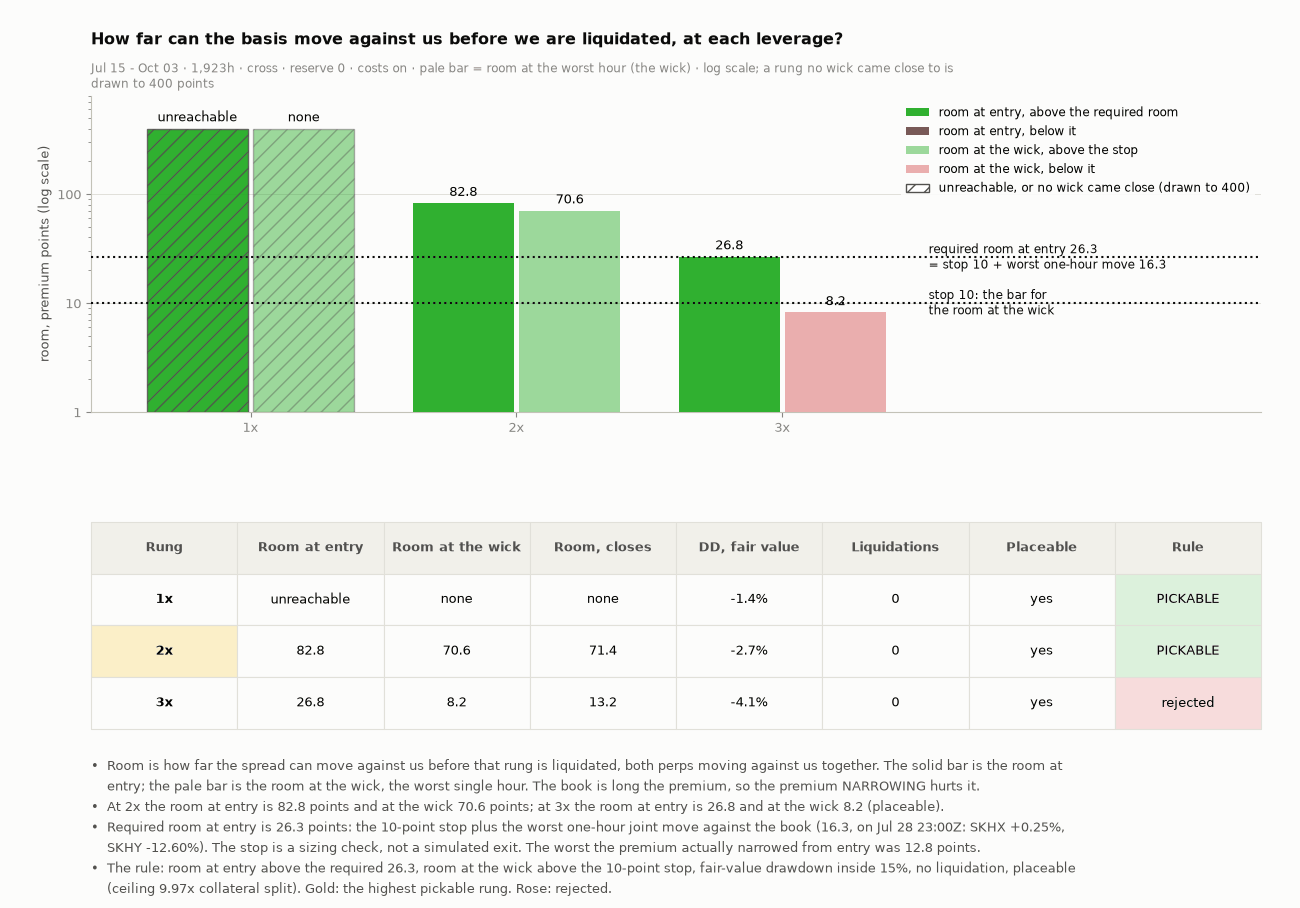

In [48]:
# ---- 6.2 room against the stop ----
RB = [f"Room is how far the spread can move against us before that rung is liquidated, both perps moving against us together. The solid bar is the room at entry; the pale bar is the room at the wick, the worst single hour. The book is long the premium, so the premium NARROWING hurts it.",
      (f"At {SHOWN}x the room at entry is {fpt(ROOM_ENTRY[SHOWN])} points and at the wick {'none came close to liquidation' if WICKPT[SHOWN] is None else format(WICKPT[SHOWN], '.1f') + ' points'}" if SHOWN else "No rung clears") + f"; at {LEVS[-1]}x the room at entry is {fpt(ROOM_ENTRY[LEVS[-1]])} and at the wick {fpt(WICKPT[LEVS[-1]])} ({'refused by the venue' if not PLACEABLE[(LEVS[-1], 0.0)] else 'placeable'}).",
      f"Required room at entry is {REQ_PTS:.1f} points: the {STOP_PTS:.0f}-point stop plus the worst one-hour joint move against the book ({WJ_PTS:.1f}, on {pd.Timestamp(rows[kJ + 1]['time'], unit='ms', tz='UTC'):%b %d %H:%MZ}: SKHX +{aA[kJ]:.2f}%, SKHY -{aB[kJ]:.2f}%). The stop is a sizing check, not a simulated exit. The worst the premium actually narrowed from entry was {WORST_NARROW:.1f} points.",
      f"The rule: room at entry above the required {REQ_PTS:.1f}, room at the wick above the {STOP_PTS:.0f}-point stop, fair-value drawdown inside {DD_LIMIT_PCT:.0f}%, no liquidation, placeable (ceiling {SPLIT_MAX:.2f}x collateral split). Gold: the highest pickable rung. Rose: rejected."]
fig, gs, ax, axt = fig_tab(7.4, (2.6, 1.7), hspace=0.42, nb=figstyle.nlines(RB))
xs = np.arange(len(LEVS)); CAP = 400.0
BOT = 1.0                                                                          # a log axis: the bars stand on 1 point, so a rung with 8 points of room is not a sliver beside one with 400
cap_ = lambda v_: CAP if v_ is None else min(CAP, v_)
entry_ok = [ROOM_ENTRY[L] is None or ROOM_ENTRY[L] > REQ_PTS for L in LEVS]; wick_ok = [WICKPT[L] is None or WICKPT[L] > STOP_PTS for L in LEVS]
b_e = ax.bar(xs - 0.2, [max(cap_(ROOM_ENTRY[L]) - BOT, 0.0) for L in LEVS], 0.38, bottom=BOT, color=[GOOD if ok_ else CRIT for ok_ in entry_ok], alpha=0.85, zorder=3)
b_w = ax.bar(xs + 0.2, [max(cap_(WICKPT[L]) - BOT, 0.0) for L in LEVS], 0.38, bottom=BOT, color=[GOOD if ok_ else CRIT for ok_ in wick_ok], alpha=0.40, zorder=3)
for bars_, vals_, none_ in ((b_e, [ROOM_ENTRY[L] for L in LEVS], "unreachable"), (b_w, [WICKPT[L] for L in LEVS], "none")):
    for b_, v_ in zip(bars_, vals_):
        if v_ is None:
            b_.set_hatch("//"); b_.set_edgecolor(INK2)                              # unreachable, or no wick came close: hatched, drawn to the cap, not a measured room
    for t_ in ax.bar_label(bars_, labels=[(none_ if v_ is None else (f"{v_:.1f}" if v_ < CAP else "off scale")) for v_ in vals_], fontsize=9, padding=3):
        t_.set_clip_on(False)
ax.axhline(REQ_PTS, color=INK, linestyle=":", linewidth=1.5, zorder=4); ax.axhline(STOP_PTS, color=INK, linestyle=":", linewidth=1.5, zorder=4)
ax.text(len(LEVS) - 0.45, REQ_PTS, f"required room at entry {REQ_PTS:.1f}" + chr(10) + f"= stop {STOP_PTS:.0f} + worst one-hour move {WJ_PTS:.1f}", ha="left", va="center", fontsize=8.5, color=INK)
ax.text(len(LEVS) - 0.45, STOP_PTS, f"stop {STOP_PTS:.0f}: the bar for" + chr(10) + "the room at the wick", ha="left", va="center", fontsize=8.5, color=INK)
ax.set_xlim(-0.6, len(LEVS) + 0.8)
ax.set_yscale("log"); ax.set_ylim(BOT, CAP * 2.0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v_, p_: f"{v_:g}")); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(xs); ax.set_xticklabels([f"{L}x" for L in LEVS]); ax.set_ylabel("room, premium points (log scale)"); ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=GOOD, alpha=0.85, label="room at entry, above the required room"), Patch(facecolor=CRIT, alpha=0.85, label="room at entry, below it"),
                   Patch(facecolor=GOOD, alpha=0.40, label="room at the wick, above the stop"), Patch(facecolor=CRIT, alpha=0.40, label="room at the wick, below it"),
                   Patch(facecolor="white", hatch="//", edgecolor=INK2, label=f"unreachable, or no wick came close (drawn to {CAP:.0f})")], loc="upper right", fontsize=8.5, **LEG)
ask(ax, "How far can the basis move against us before we are liquidated, at each leverage?", f"{WSB} · pale bar = room at the worst hour (the wick) · log scale; a rung no wick came close to is drawn to {CAP:.0f} points")
cells = [[f"{L}x", ("unreachable" if ROOM_ENTRY[L] is None else f"{ROOM_ENTRY[L]:.1f}"), ("none" if WICKPT[L] is None else f"{WICKPT[L]:.1f}"), ("none" if CLOSEPT[L] is None else f"{CLOSEPT[L]:.1f}"), f"{FVDD[L]:.1f}%", f"{LAD[L][0]['liquidations']}", ("yes" if PLACEABLE[(L, 0.0)] else "NO"), ("PICKABLE" if L in OKR else "rejected")] for L in LEVS]
tb = put_table(axt, cells, ["Rung", "Room at entry", "Room at the wick", "Room, closes", "DD, fair value", "Liquidations", "Placeable", "Rule"], size=9.2)
for i_, L in enumerate(LEVS, 1):
    tint(tb, i_, 7, "green" if L in OKR else "rose")
    if L == SHOWN: gold(tb, i_, 0)
foot(fig, *RB)
figstyle.show(fig, "fig:s6-room", FIGURES)
ST6["room"] = {"req": REQ_PTS, "wick_req": WJ_PTS, "p0": float(P0), "worst_narrow": WORST_NARROW, "worst_widen": WORST_WIDEN, "shown": SHOWN, "sized": SIZED, "passed": PASSED, "ceiling_split": SPLIT_MAX, "l_max_placeable": L_MAX_PLACEABLE,
                 "wj_pct": WJ, "wj_when": f"{pd.Timestamp(rows[kJ + 1]['time'], unit='ms', tz='UTC'):%Y-%m-%d %H:%MZ}",
                 "rungs": {str(L): {"entry": ROOM_ENTRY[L], "wick": WICKPT[L], "closes": CLOSEPT[L], "placeable": bool(PLACEABLE[(L, 0.0)]), "ok": L in OKR} for L in LEVS}, "nliq": NLIQ}

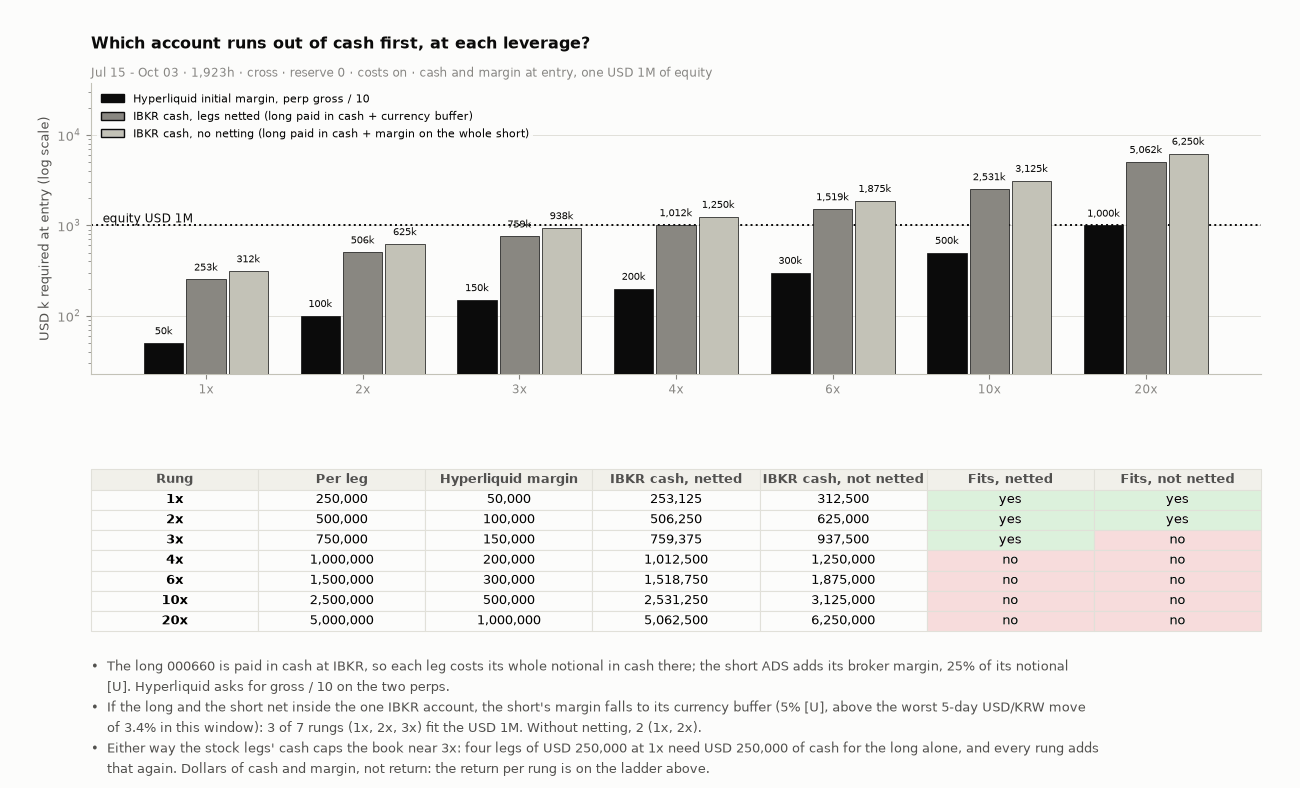

In [49]:
# ---- 6.3 which account runs out of cash first at each leverage: IBKR (the stock legs' cash and margin) or Hyperliquid (the perps' initial margin) ----
NN_ = {L: L * EQUITY / 4.0 for L in RUNGS_ALL}
hl_im = {L: 2 * NN_[L] / MAXLEV for L in RUNGS_ALL}                                    # the venue's initial margin on the two perps, gross / the leverage setting
ib_net = {L: ib_cash(NN_[L], True, IB_MARGIN) for L in RUNGS_ALL}; ib_not = {L: ib_cash(NN_[L], False, IB_MARGIN) for L in RUNGS_ALL}
fit_net = [L for L in RUNGS_ALL if ib_net[L] + hl_im[L] <= EQUITY]; fit_not = [L for L in RUNGS_ALL if ib_not[L] + hl_im[L] <= EQUITY]
AB = [f"The long 000660 is paid in cash at IBKR, so each leg costs its whole notional in cash there; the short ADS adds its broker margin, {IB_MARGIN * 100:g}% of its notional [U]. Hyperliquid asks for gross / {MAXLEV} on the two perps.",
      f"If the long and the short net inside the one IBKR account, the short's margin falls to its currency buffer ({FX_BUF * 100:g}% [U], above the worst 5-day USD/KRW move of {FX_MOVE5 * 100:.1f}% in this window): {len(fit_net)} of {len(RUNGS_ALL)} rungs ({', '.join(f'{L}x' for L in fit_net) or 'none'}) fit the {usdm(EQUITY)}. Without netting, {len(fit_not)} ({', '.join(f'{L}x' for L in fit_not) or 'none'}).",
      "Either way the stock legs' cash caps the book near 3x: four legs of USD 250,000 at 1x need USD 250,000 of cash for the long alone, and every rung adds that again. Dollars of cash and margin, not return: the return per rung is on the ladder above."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 1.5), hspace=0.42, nb=figstyle.nlines(AB))
xs = np.arange(len(RUNGS_ALL))
ax.set_yscale("log"); ax.set_ylim(min(min(hl_im.values()), min(ib_net.values())) / 1e3 * 0.45, max(max(ib_not.values()), EQUITY) / 1e3 * 6.0)
for off_, vals_, col_ in ((-0.27, hl_im, INK), (0.0, ib_net, MUTED), (0.27, ib_not, AXIS)):
    ax.bar(xs + off_, [vals_[L] / 1e3 for L in RUNGS_ALL], 0.25, color=col_, zorder=3, edgecolor=INK, linewidth=0.5)
    for x_, L in zip(xs, RUNGS_ALL): ax.text(x_ + off_, vals_[L] / 1e3 * 1.25, f"{vals_[L] / 1e3:,.0f}k", ha="center", fontsize=7.2, color=INK)
ax.axhline(EQUITY / 1e3, color=INK, linewidth=1.4, linestyle=":"); ax.annotate(f"equity {usdm(EQUITY)}", xy=(0.01, EQUITY / 1e3), xycoords=("axes fraction", "data"), color=INK, fontsize=8.4, va="bottom", ha="left")
ax.set_xticks(xs); ax.set_xticklabels([f"{L}x" for L in RUNGS_ALL], fontsize=8.8); ax.set_ylabel("USD k required at entry (log scale)"); ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=INK, edgecolor=INK, label=f"Hyperliquid initial margin, perp gross / {MAXLEV}"), Patch(facecolor=MUTED, edgecolor=INK, label="IBKR cash, legs netted (long paid in cash + currency buffer)"), Patch(facecolor=AXIS, edgecolor=INK, label="IBKR cash, no netting (long paid in cash + margin on the whole short)")], loc="upper left", fontsize=8.2, **LEG)
ask(ax, "Which account runs out of cash first, at each leverage?", f"{WSB} · cash and margin at entry, one {usdm(EQUITY)} of equity")
cells = [[f"{L}x", f"{NN_[L]:,.0f}", f"{hl_im[L]:,.0f}", f"{ib_net[L]:,.0f}", f"{ib_not[L]:,.0f}", ("yes" if L in fit_net else "no"), ("yes" if L in fit_not else "no")] for L in RUNGS_ALL]
tb = put_table(axt, cells, ["Rung", "Per leg", "Hyperliquid margin", "IBKR cash, netted", "IBKR cash, not netted", "Fits, netted", "Fits, not netted"], size=9.0)
for i_, L in enumerate(RUNGS_ALL, 1):
    tint(tb, i_, 5, "green" if L in fit_net else "rose"); tint(tb, i_, 6, "green" if L in fit_not else "rose")
foot(fig, *AB)
figstyle.show(fig, "fig:s6-margin", FIGURES)
ST6["margin"] = {"fit_net": fit_net, "fit_not": fit_not, "n": len(RUNGS_ALL), "maxlev": MAXLEV, "fx_buf": FX_BUF, "fx_move5": FX_MOVE5, "frac": IB_MARGIN}

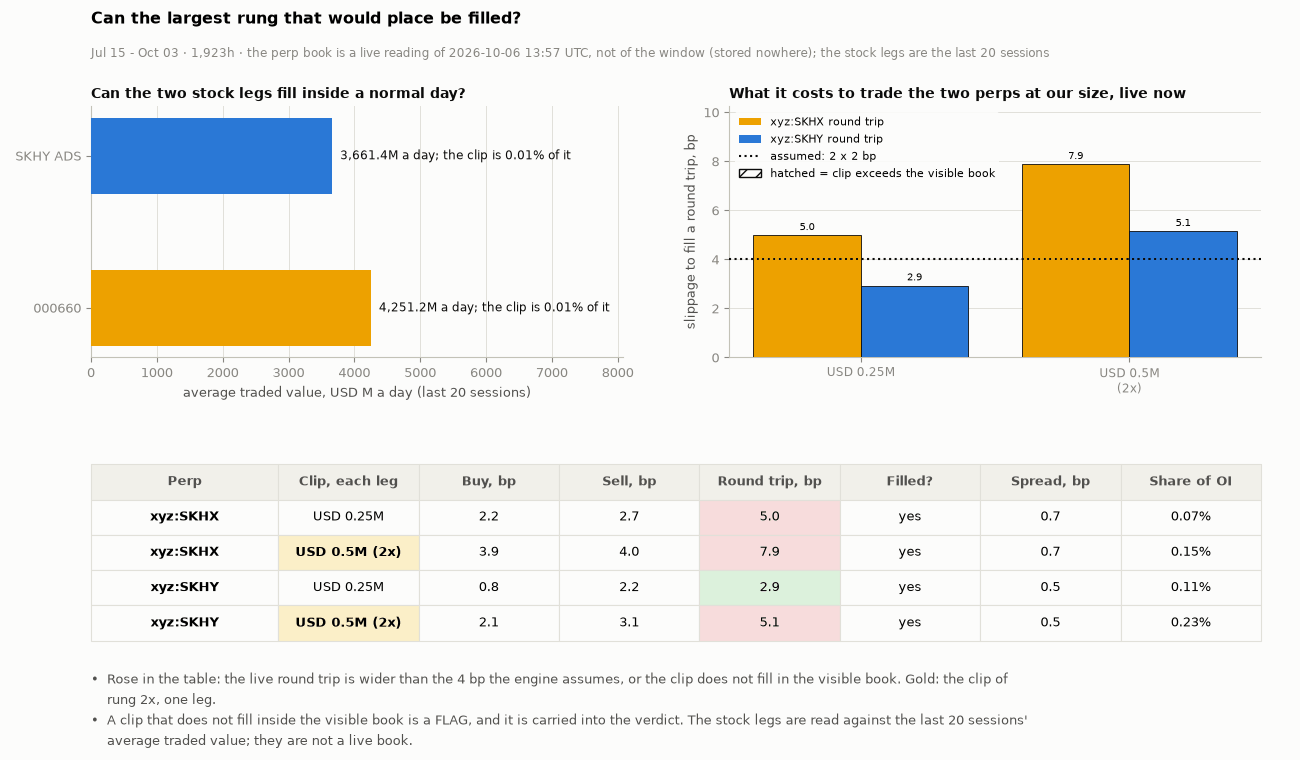

In [50]:
# ---- 6.4 can it be filled? the live perp book at the clip of the highest placeable rung, and the stock legs' day ----
L_FILL = SHOWN or LEVS[0]
CLIP = round(LAD[L_FILL][0]["notional_usd"])                          # one leg, each of the four
SIZES = tuple(sorted({round(LAD[L][0]["notional_usd"]) for L in (1, L_FILL, 6) if L in LAD}))
try:
    BD = HP.book_depth((COIN_A, COIN_B), sizes=SIZES); SNAP = DATA.hl_dex_bulk_funding("xyz")
except Exception as e:
    BD, SNAP = {}, {}; print("live read unavailable:", repr(e))
EX = []
for c_, x_ in (BD or {}).items():
    if x_:
        for sz in SIZES:
            f_ = x_["fills"][sz]
            EX.append({"coin": c_, "clip": sz, "buy": f_["buy"]["slippage_bps"], "sell": f_["sell"]["slippage_bps"], "filled": bool(f_["buy"]["filled"] and f_["sell"]["filled"]), "rt": f_["buy"]["slippage_bps"] + f_["sell"]["slippage_bps"], "spread": x_["spread_bps"] or 0})
# the two stock legs against their own average daily value: a clip that is a sliver of a normal day fills inside it
adv = {}
for nm, bars_, key in (("000660", krx, "A"), ("SKHY ADS", ads, "B")):
    last = [b for b in bars_][-20:]
    vol_usd = [float(b.get("volume") or 0) * float(b.get("close") or 0) / (float(fx[-1]["close"]) if key == "A" else 1.0) for b in last]
    adv[nm] = float(np.mean(vol_usd)) if vol_usd else float("nan")
fig = plt.figure(figsize=(13, 7.6))
bm = figstyle.bullets(fig, [f"Rose in the table: the live round trip is wider than the {2 * _pp.exec_slippage_bps:g} bp the engine assumes, or the clip does not fill in the visible book. Gold: the clip of rung {L_FILL}x, one leg.",
                            "A clip that does not fill inside the visible book is a FLAG, and it is carried into the verdict. The stock legs are read against the last 20 sessions' average traded value; they are not a live book."])
gs = fig.add_gridspec(2, 2, height_ratios=[2.7, 1.9], hspace=0.5, wspace=0.2, left=0.07, right=0.97, top=0.86, bottom=bm + 0.02)
s0, s1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); axt = fig.add_subplot(gs[1, :]); axt.axis("off")
names = list(adv); vals = [adv[n] for n in names]
s0.barh(range(len(names)), [v / 1e6 for v in vals], height=0.5, color=[C_A, C_B], zorder=3)
for i_, v in enumerate(vals):
    s0.text(v / 1e6, i_, f"  {v / 1e6:,.1f}M a day; the clip is {CLIP / v * 100:.2f}% of it", va="center", fontsize=8.8, color=INK)
s0.set_yticks(range(len(names))); s0.set_yticklabels(names, fontsize=9); s0.set_xlabel("average traded value, USD M a day (last 20 sessions)"); s0.grid(axis="y", visible=False)
s0.set_xlim(0, max(vals) / 1e6 * 1.9); s0.set_title("Can the two stock legs fill inside a normal day?", fontsize=10, loc="left", pad=6)
if EX:
    EXd = pd.DataFrame(EX)
    for j, c_ in enumerate((COIN_A, COIN_B)):
        sub = EXd[EXd["coin"] == c_]; okf = sub["filled"].tolist()
        b = s1.bar(np.arange(len(sub)) + (j - 0.5) * 0.4, sub["rt"], 0.4, color=[C_A, C_B][j], hatch=["" if f else "//" for f in okf], edgecolor=INK, linewidth=0.6, zorder=3)
        s1.bar_label(b, labels=[(f"{v:.1f}" if f else f">= {v:.1f}") for v, f in zip(sub["rt"], okf)], fontsize=7.5, padding=2)
    s1.axhline(2 * _pp.exec_slippage_bps, color=INK, linestyle=":", linewidth=1.5, zorder=4)
    s1.set_xticks(np.arange(len(SIZES))); s1.set_xticklabels([usdm(s) + (f"\n({L_FILL}x)" if s == CLIP else "") for s in SIZES], fontsize=8.5)
    s1.set_ylabel("slippage to fill a round trip, bp"); s1.set_ylim(top=EXd["rt"].max() * 1.3); s1.grid(axis="x", visible=False)
    s1.legend(handles=[Patch(facecolor=C_A, label="xyz:SKHX round trip"), Patch(facecolor=C_B, label="xyz:SKHY round trip"), plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"assumed: 2 x {_pp.exec_slippage_bps:g} bp"),
                       Patch(facecolor=SURF, hatch="//", edgecolor=INK, label="hatched = clip exceeds the visible book")], loc="upper left", fontsize=8, **LEG)
    s1.set_title("What it costs to trade the two perps at our size, live now", fontsize=10, loc="left", pad=6)
    cells = [[r["coin"], usdm(r["clip"]) + (f" ({L_FILL}x)" if r["clip"] == CLIP else ""), f"{r['buy']:.1f}", f"{r['sell']:.1f}", f"{r['rt']:.1f}", ("yes" if r["filled"] else "NO"), f"{r['spread']:.1f}", (f"{r['clip'] / SNAP[r['coin']]['oi_usd'] * 100:.2f}%" if SNAP else "")] for r in EX]
    tb = put_table(axt, cells, ["Perp", "Clip, each leg", "Buy, bp", "Sell, bp", "Round trip, bp", "Filled?", "Spread, bp", "Share of OI"], size=9, first=0.16)
    for i_, r in enumerate(EX, 1):
        tint(tb, i_, 4, "rose" if r["rt"] > 2 * _pp.exec_slippage_bps else "green")
        if not r["filled"]: tint(tb, i_, 5, "rose")
        if r["clip"] == CLIP: gold(tb, i_, 1)
else:
    s1.axis("off"); axt.text(0.5, 0.5, "live book read unavailable at this run", ha="center")
fig.suptitle("Can the largest rung that would place be filled?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · the perp book is a live reading of {dt.datetime.now(dt.timezone.utc):%Y-%m-%d %H:%M} UTC, not of the window (stored nowhere); the stock legs are the last 20 sessions", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-fill", FIGURES)
filled_ok = bool(EX) and all(r["filled"] for r in EX if r["clip"] == CLIP)
worst_rt = max((r["rt"] for r in EX if r["clip"] == CLIP), default=None)
ST6["fill"] = {"clip_per_leg": CLIP, "rung": L_FILL, "filled_ok": filled_ok, "worst_rt": worst_rt, "assumed": 2 * _pp.exec_slippage_bps, "rows": EX, "adv": adv, "clip_share_of_adv": {n: CLIP / v for n, v in adv.items()}}

In [51]:
# ---- the grid runs: leverage x the broker-margin regime, each verified (information; one window re-sliced) ----
REGS = (("netted, 25%", True, 0.25), ("netted, 50%", True, 0.50), ("not netted, 25%", False, 0.25), ("not netted, 50%", False, 0.50))
GRM, NOFIT = {}, {}
for L in LEVS:
    for nm_, nt_, fr_ in REGS:
        need_ = ib_cash(L * EQUITY / 4.0, nt_, fr_) + 2 * (L * EQUITY / 4.0) / MAXLEV         # IBKR cash and margin, plus the perps' initial margin
        if need_ >= EQUITY:
            NOFIT[(L, nm_)] = need_                                                          # the equity cannot fund both accounts: not run
            continue
        r_ = run4(rows, fp(L, 0.0, BOOK, netting=nt_, frac=fr_)); c_ = vfour(r_, rows, f"grid {L}x {nm_}")
        assert len(c_) == NCHK, (L, nm_)
        GRM[(L, nm_)] = r_
def fvdd(r_):
    e_ = EQUITY + pd.Series(r_["series"]["total_pnl_fv"], dtype=float); return float((e_ / e_.cummax() - 1).min()) * 100
WRM = {k_: wick_room(r_, BOOK)[0] for k_, r_ in GRM.items()}
LIQM = {k_: bool(r_["liquidations"]) or (WRM[k_] is not None and WRM[k_] <= 0) for k_, r_ in GRM.items()}
IBC = {(L, nm_): ib_cash(GRM[(L, nm_)]["notional_usd"], nt_, fr_) for L in LEVS for nm_, nt_, fr_ in REGS if (L, nm_) in GRM}
ST6["grid"] = {"n": len(GRM), "n_nofit": len(NOFIT), "nliq": int(sum(r_["liquidations"] for r_ in GRM.values())), "liquidated_cells": int(sum(LIQM.values()))}

In [52]:
# ---- PSR / DSR on the book's fair-value daily returns, the trials being this grid (reported, never a gate) ----
from fundplat.quant.crypto.backtest import util as BU
FVR = list((daily_cum(pd.Series(res["series"]["total_pnl_fv"], index=df.index, dtype=float)) / EQUITY).values)
SRc = []
for (L, nm_), r_ in GRM.items():
    cell_ = {"engine": "hip3_four", "study": "four-thesis", "direction": "short_a", "margin_mode": "cross", "lev": float(L), "reserve": 0.0, "regime": nm_, "stock_sizing": STOCK_SIZING, "mark": "fair_value"}
    ln_, why_ = BU.trial_line(cell_, r_["series"]["time"], r_["series"]["total_pnl_fv"], r_["capital"])
    if ln_: SRc.append(np.mean(ln_["returns"]) / np.std(ln_["returns"], ddof=1))
SRc = np.array(SRc)
ST6["psr"] = {"psr": float(ST.psr(FVR)), "dsr": float(ST.dsr(FVR, len(GRM), float(SRc.var(ddof=1)))), "n_trials": len(GRM), "n_with_sharpe": int(len(SRc))}
NBOOKS = int(ST4["n_runs"]) + int(ST6["grid"]["n"]) + 1 + int(ST4B["n_runs"])      # the base, cost, rule and hedge runs, the grid, and every entry the sweep kept: each passed every check or the build stopped
ST6["facts"] = {"window_from": f"{df.index[0]:%Y-%m-%d %H:%M}Z", "window_to": f"{df.index[-1]:%Y-%m-%d %H:%M}Z", "days": res["days"], "hours": int(res["n_hours"]), "verify": f"verify_four {NCHK} checks on each of {NBOOKS} books", "n_chk": NCHK, "n_books": NBOOKS,
                  "hurdle": HURDLE_PCT, "equity": EQUITY, "stop": STOP_PTS, "dd_limit": DD_LIMIT_PCT, "maxlev": MAXLEV, "entry_bps": float(ENTRY_BPS), "carry_stock_real": STOCK_CARRY_REAL[BOOK],
                  "funding_ann_leg": D7, "funding_mean_leg": DMEAN, "entry_premium": float(P0), "regime": "one window, one regime"}

In [53]:
# ---- the honest deflation: every variant this notebook scored is a trial, and their Sharpes have a real variance (the grid alone had none: leverage and the margin regime do not move the Sharpe) ----
from pathlib import Path
from collections import Counter
TRIAL_RUNS = {}
for (L, nm_), r_ in GRM.items(): TRIAL_RUNS[f"grid {L}x {nm_}"] = (r_, {"family": "grid", "lev": float(L), "regime": nm_})
for (L, R), r_ in GR.items(): TRIAL_RUNS[f"ladder {L}x reserve {R:g}"] = (r_, {"family": "ladder", "lev": float(L), "reserve": float(R)})
for k_, r_ in SW.items(): TRIAL_RUNS[f"cost {k_}"] = (r_, {"family": "cost", "borrow": k_[0], "stock_fin": k_[1], "fee_bp": k_[2], "slip_bp": k_[3]})
for lab_, r_ in RULES.items(): TRIAL_RUNS[f"rule {lab_}"] = (r_, {"family": "rule", "rule": lab_})
for nm_, r_ in ARM_R.items(): TRIAL_RUNS[f"hedge arm {nm_}"] = (r_, {"family": "hedge arm", "arm": nm_})
TRIAL_RUNS["hedge arm static hold"] = (STATIC, {"family": "hedge arm", "arm": "static hold"})
LINES, DROPPED, SRT = [], [], {}
for nm_, (r_, cell_) in TRIAL_RUNS.items():
    cell_ = {**cell_, "engine": "hip3_four", "study": "four-leg", "mark": "fair_value", "window_hours": int(r_["n_hours"])}       # `study` is a ledger name, kept on purpose (see TRIAL_RUN below)
    ln_, why_ = BU.trial_line(cell_, r_["series"]["time"], r_["series"]["total_pnl_fv"], r_["capital"])
    if ln_ is None:
        DROPPED.append((nm_, why_)); continue
    LINES.append(ln_); SRT[nm_] = float(np.mean(ln_["returns"]) / np.std(ln_["returns"], ddof=1))
N_EXTRA, N_EXTRA_DIST = len(BR) + len(SEG), (len(BR) - 1) + len(SEG)      # the borrow sweep and the two split segments were scored too but their daily paths are not kept here; the 0.03 borrow is the base
N_RAW = len(TRIAL_RUNS) + N_EXTRA                                         # every engine configuration scored, duplicates included, none dropped
sr_all = np.array(list(SRT.values())); sr_dist = np.array(sorted({round(float(v), 6) for v in sr_all}))
N_DIST = len(sr_dist) + N_EXTRA_DIST
sr_var = float(sr_dist.var(ddof=1))
sr_var_grid = float(np.var([v for k, v in SRT.items() if k.startswith("grid")], ddof=1))
FVR_ = [float(v) for v in FVR]
SR_REG = float(np.mean(FVR_) / np.std(FVR_, ddof=1))
assert abs(ST.dsr(FVR_, N_RAW, 0.0) - ST.psr(FVR_)) < 1e-12          # what the printed DSR was: no variance between the trials, no deflation. The check holds, which is the defect
OLD_DSR = float(ST6["psr"]["dsr"])
DSR_RAW, DSR_DIST = float(ST.dsr(FVR_, N_RAW, sr_var)), float(ST.dsr(FVR_, N_DIST, sr_var))
N_ENTRY = int(ST4B["n_runs"])                                            # the entry-hour sweep of Test 3: the entry is registered, not chosen on it, so these are not trials; this is the sensitivity if they were
DSR_ENTRY = float(ST.dsr(FVR_, N_RAW + N_ENTRY, sr_var))
PSR_H = float(ST.psr([v - p1.hurdle_ann / 365.0 for v in FVR_]))        # the probability the true Sharpe of the EXCESS over the T-bill is above zero
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab" / "research").is_dir()), None)
try:
    LED = BU.read_trial_cells(_root / "lab" / "research" / "data" / "grids" / "four-thesis.jsonl", RUN_ID) if _root else []
except Exception:
    LED = []
# the old names (four-leg, four-thesis, and the `study` field of the trial cells) are kept on purpose: ledger rows are never rewritten, so this study still writes under the names its earlier lines carry
TRIAL_RUN, TRIAL_GRID = "four-leg-1923h-2026-10-05", "four-thesis"      # the sweep_run stamp of THIS window's cells and the file under lab/research/data/grids; research-005's lines are the earlier 1,801 h window and stay as written
import os
GRID_PATH = (_root / "lab" / "research" / "data" / "grids" / f"{TRIAL_GRID}.jsonl") if _root else None
if GRID_PATH is None:
    LEDGER_MSG = "trial cells: lab/research not found from this folder, nothing written"
elif BU.read_trial_cells(GRID_PATH, TRIAL_RUN):
    LEDGER_MSG = f"trial cells: {TRIAL_RUN} is already in {GRID_PATH.name}, not appended again (a run is written once)"
elif os.environ.get("FUND_WRITE_TRIALS") != "1":
    LEDGER_MSG = f"trial cells: {len(LINES)} not written to {GRID_PATH.name} (FUND_WRITE_TRIALS is not 1: a development build)"
else:
    LEDGER_MSG = BU.write_trial_cells(GRID_PATH, LINES, DROPPED, run=TRIAL_RUN)
print(LEDGER_MSG, flush=True)
FAM = Counter(c_["cell"]["family"] for c_ in LINES)
ST6["psr"].update({"dsr_grid_only": OLD_DSR, "dsr": DSR_RAW, "dsr_distinct": DSR_DIST, "dsr_entry_hours": DSR_ENTRY, "n_trials": N_RAW, "n_distinct": N_DIST, "n_entry_runs": N_ENTRY, "sr_var": sr_var, "sr_var_grid": sr_var_grid,
                   "sr0_ann": float(ST.expected_max_sr(N_RAW, sr_var) * np.sqrt(365.0)), "sr_ann": SR_REG * float(np.sqrt(365.0)), "psr_vs_tbill": PSR_H, "n_with_sharpe": len(SRT), "n_dropped": len(DROPPED),
                   "ledger_prior_cells": len(LED), "families": dict(FAM)})
P6 = ST6["psr"]
display(Markdown("**Trials and the deflated Sharpe ratio.** Every engine configuration this notebook scored counts as a trial (`" + "`, `".join(f"{k_} {v_}" for k_, v_ in FAM.items()) + f"`, plus {N_EXTRA} runs whose daily paths are not kept: the borrow sweep and the two split segments). "
                 f"The variance of the trials' per-day Sharpe ratios is {sr_var:.2e} over {len(sr_dist)} distinct values; the grid alone had {sr_var_grid:.1e}, which is why its DSR equalled the PSR.\n\n"
                 f"| Reading | Trials | Expected best Sharpe, annualised | DSR |\n|---|---|---|---|\n| The grid cells only, as printed before | {len(GRM)} | {ST.expected_max_sr(len(GRM), sr_var_grid) * np.sqrt(365.0):.2f} | {OLD_DSR:.2f} |\n"
                 f"| **All variants run (the reading we use)** | {N_RAW} | {P6['sr0_ann']:.2f} | **{DSR_RAW:.2f}** |\n| Distinct Sharpe values only | {N_DIST} | {ST.expected_max_sr(N_DIST, sr_var) * np.sqrt(365.0):.2f} | {DSR_DIST:.2f} |\n"
                 f"| Plus every entry hour of Test 3, had the entry been chosen on them [U] | {N_RAW + N_ENTRY:,} | {ST.expected_max_sr(N_RAW + N_ENTRY, sr_var) * np.sqrt(365.0):.2f} | {DSR_ENTRY:.2f} |\n\n"
                 f"The book's own Sharpe is {P6['sr_ann']:.2f} annualised on fair-value daily returns: PSR {P6['psr']:.2f} against zero and {PSR_H:.2f} against the T-bill. {len(LINES)} ledger lines were built with `util.trial_line` ({len(DROPPED)} dropped" + (": " + "; ".join(f"{a_} ({b_})" for a_, b_ in DROPPED[:3]) if DROPPED else "") + "). "
                 f"{LEDGER_MSG}; `{RUN_ID}` in the same file holds {len(LED)} lines from the earlier, shorter window and is not counted here. The ledger holds the {len(LINES)} configurations whose daily paths are kept; the {N_EXTRA} that are not kept count in N above, so N is {N_RAW} and the ledger {len(LINES)}. The variants are one window re-sliced, so N counts what was tried, not independent bets."))

trial cells: four-leg-1923h-2026-10-05 is already in four-thesis.jsonl, not appended again (a run is written once)


**Trials and the deflated Sharpe ratio.** Every engine configuration this notebook scored counts as a trial (`grid 10`, `ladder 3`, `cost 9`, `rule 3`, `hedge arm 11`, plus 5 runs whose daily paths are not kept: the borrow sweep and the two split segments). The variance of the trials' per-day Sharpe ratios is 1.54e-03 over 23 distinct values; the grid alone had 9.2e-11, which is why its DSR equalled the PSR.

| Reading | Trials | Expected best Sharpe, annualised | DSR |
|---|---|---|---|
| The grid cells only, as printed before | 10 | 0.00 | 0.78 |
| **All variants run (the reading we use)** | 41 | 1.65 | **0.50** |
| Distinct Sharpe values only | 27 | 1.52 | 0.52 |
| Plus every entry hour of Test 3, had the entry been chosen on them [U] | 3,215 | 2.68 | 0.32 |

The book's own Sharpe is 1.65 annualised on fair-value daily returns: PSR 0.78 against zero and 0.57 against the T-bill. 36 ledger lines were built with `util.trial_line` (0 dropped). trial cells: four-leg-1923h-2026-10-05 is already in four-thesis.jsonl, not appended again (a run is written once); `research-005` in the same file holds 56 lines from the earlier, shorter window and is not counted here. The ledger holds the 36 configurations whose daily paths are kept; the 5 that are not kept count in N above, so N is 41 and the ledger 36. The variants are one window re-sliced, so N counts what was tried, not independent bets.

## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [54]:
Z2, Z3, Z4, Z5, Z6 = ST2, ST3, ST4, ST5, ST6
from fundplat.quant.core import stats as ST_
F6 = Z6["facts"]
pct = lambda x, sign=True, d=1: f"{x:+.{d}f}%" if sign else f"{x:.{d}f}%"
PF = lambda b: "PASS" if b else "FAIL"
HURDLE = F6["hurdle"]
yrs = F6["days"] / 365.0
EQ = F6["equity"]
WIN = f"{F6['window_from'][:10]} to {F6['window_to'][:10]}, {F6['hours']:,} hours ({F6['days']:.1f} days)"
N2 = Z2["net_vs_bar"]
P2 = Z2["premia"]
B2 = Z2["bases"]
E3 = Z3["equity"]; D3 = Z3["drawdown"]; DY = Z3["daily"]
O4, L4, C4, R4 = Z4["oos"], Z4["luck"], Z4["costs"], Z4["rules"]
HG4 = Z4["hedge"]
CTRL1, CTRL2 = HG4["arms"]["fixed 0.75, no trades"], HG4["arms"]["estimate once at mid, hold"]
CTRL_SAYS = ("continuous re-striking earns no more than a one-time under-hedge" if max(CTRL1["carry_ann"], CTRL2["carry_ann"]) >= HG4["registered"]["carry_ann"] - 0.05 else "continuous re-striking earns more than a one-time under-hedge")
PD4, IN4 = Z4["paired"], Z4["inference"]
SB = ST4B
H5, SP5, SH5, CL5, SI5 = Z5["hedge"], Z5["spread"], Z5["shut"], Z5["clocks"], Z5["sits"]
RM6, LAD6, FL6, MG6 = Z6["room"], Z6["ladder"], Z6["fill"], Z6["margin"]
sh = str(RM6["shown"])
rt_1x = [r for r in FL6["rows"] if r["clip"] == round(Z6["ladder"]["1"]["per_leg"])]
rules_ok = bool(R4["adopt"])
fill_flag = not (FL6["filled_ok"] and FL6["worst_rt"] is not None and FL6["worst_rt"] <= FL6["assumed"])
rt1 = max((r["rt"] for r in rt_1x), default=None); fill1 = all(r["filled"] for r in rt_1x) if rt_1x else False
fill_flag1 = not (fill1 and rt1 is not None and rt1 <= FL6["assumed"])
Q_TEXT = "Can re-hedging the stock legs by rule make the SKHY / SKHX funding book neutral to the basis, and does the funding then beat a T-bill?"
GATES = [
    ("Base test", "Does the re-hedged carry beat a T-bill once the stock legs and the re-hedging are paid?", f"Funding net of the stock carry, the re-hedging and the fees earned {pct(Z3['gate_ann'])} a year against {pct(HURDLE, False, 2)}", PF(E3["pass"]), "a period where the differential averages above the bar"),
    ("Test 1a", "Does it still work after the split?", f"No: {pct(O4['out']['gate'])} a year on the later data ({pct(O4['in']['gate'])} before it)", PF(O4["pass"]), "a later window above the T-bill"),
    ("Test 1b", "Is the excess over the T-bill statistically significant?", f"{'Yes' if L4['pass'] else 'No'}: p = {L4['p_gate']:.3f}, the cut is 0.10", PF(L4["pass"]), "an excess that holds up against shuffling"),
    ("Test 1c", "Do costs eat it?", f"The gate metric stays positive in all {C4['n']} cost cells (best {pct(C4['best_gate'])}) but none reaches the T-bill", PF(C4["pass"]), "a cheaper borrow and cheaper fills than we tested"),
    ("Test 2", "Does exiting on a rule help?", "No rule improves the gate metric and the drawdown together" if not rules_ok else f"Yes: {R4['adopt'][0]}", "INFO" if not rules_ok else "PASS", "a longer window in which a rule stops sitting out the carry"),
    ("Test 3", "How much is the entry hour?", f"A together entry's naked hours ran {SB['together']['p5']:+,.0f} to {SB['together']['p95']:+,.0f} USD. A staggered entry's " + ("naked-hours P&L is exactly zero by construction (each perp goes on only when its own stock fills), which is an identity, not a finding; " if SB["staggered_gate"]["zero"] else f"naked-hours P&L ran {SB['staggered']['p5']:+,.2f} to {SB['staggered']['p95']:+,.2f} USD; ")
     + f"what the entry hour moves is the gate metric, {SB['staggered_gate']['gate_p5']:+.1f}% to {SB['staggered_gate']['gate_p95']:+.1f}% a year across {SB['staggered_gate']['n']:,} staggered entry hours of one window", "INFO", "another window"),
    ("Test 4", "What does the rule add over the static hold?", f"It trims the short swing and one bad hour, not the week-long one: the ratio held ({HG4['registered']['rho_min']:.2f} to {HG4['registered']['rho_max']:.2f} of the matched book) gave a swing of {HG4['swing_ratio']['24']:.2f} of the static hold's over 24 hours and {HG4['swing_ratio']['168']:.2f} over 168, and a fair-value drawdown of {abs(HG4['registered']['dd']):.2f}% against {abs(HG4['static']['dd']):.2f}%; the gate metric is {pct(HG4['registered']['carry_ann'])} against {pct(HG4['static']['carry_ann'])}, a saving on stock carry. Paired block bootstrap over {PD4['gate_saving']['n']} days from the first rebalance: the carry saving is USD {PD4['gate_saving']['mean']:+,.0f} a day ({PD4['gate_saving']['ci_lo']:+,.0f} to {PD4['gate_saving']['ci_hi']:+,.0f}), {'distinguishable from zero but mechanical (fewer stock legs, less cash tied up)' if PD4['gate_saving']['dist'] else 'not distinguishable from zero'}; the fair-value total gain is {'distinguishable from zero' if PD4['total_fv']['dist'] else 'not distinguishable from zero'}; the cut in daily swing ({PD4['ratio']['point']:.2f} of the static hold's, {PD4['ratio']['lo']:.2f} to {PD4['ratio']['hi']:.2f}) is {'distinguishable from zero' if PD4['variance_saved']['dist'] else 'not distinguishable from zero'}; the drawdown gap is one hour and cannot be tested. Two controls that never re-strike read {CTRL1['carry_ann']:+.2f}% (a fixed 0.75 from the first hour, chosen in hindsight) and {CTRL2['carry_ann']:+.2f}% (the ratio read once on the first half and held, out of sample) against the rule's {HG4['registered']['carry_ann']:+.2f}%: {CTRL_SAYS}", "INFO", "a window in which the premium does not trend with the book"),
    ("Sizing", "Is there room before liquidation, and does the drawdown fit?", f"Information only: the geometry would take {RM6['shown']}x ({fpt(RM6['rungs'][sh]['entry'])} points of room at entry against {RM6['req']:.1f} required; {fpt(RM6['rungs'][sh]['wick'])} at the worst hour against the {F6['stop']:.0f}-point stop; {abs(LAD6[sh]['dd_fv']):.1f}% fair-value drawdown against {F6['dd_limit']:.0f}%)", "INFO", "all of S3 and S4 passing"),
    ("Fill", "Can we trade this size at the cost we assumed?", "The two stock legs yes (a sliver of a day's value); the perps no: " + "; ".join(f"{r['coin']} {r['rt']:.1f} bp vs {FL6['assumed']:g} assumed, {'fills' if r['filled'] else 'does not fill'}" for r in rt_1x) + " at the 1x clip", "FLAG" if fill_flag1 else "PASS", "more depth in the SKHY book"),
]
_g = ["| Test | The question | What we found | Result | What would change our mind |", "|---|---|---|---|---|"] + [f"| {a} | {b} | {c} | {d} | {e} |" for a, b, c, d, e in GATES]
PSR = Z6["psr"]
ABOVE7 = [k_ for k_, v_ in LAD6.items() if v_["placeable"] and not v_["liq"] and v_["gate"] > HURDLE]       # the rungs whose gate metric sits above the T-bill (the T-bill is not scaled with the rung)
VERDICT_MD = "\n".join([
    "**In short.** We tested a rule-hedged four-leg version of the SK Hynix carry: short SKHX against long 000660 and long SKHY against short ADS, with the stock legs re-struck by rule to a trailing hedge ratio so the basis is neutral at the horizon the ratio is read on. The funding it collects does not pay for the stock legs and the re-hedging and still beat a T-bill.", "",
    f"**What we found.** Over {F6['days']:.0f} days at 1x the book earned {pct(Z3['ann_equity'])} a year on the fair-value mark ({pct(Z3['ann_equity_close'])} close-marked, two clocks). Funding gross was {pct(Z3['funding'] / EQ / yrs * 100)}, the two stock legs and the perp fees took {pct(Z3['costs'] / EQ / yrs * 100, False)}, leaving {pct(Z3['gate_ann'])} against the T-bill's {pct(HURDLE, False, 2)}. "
    f"That did not hold out of sample ({pct(O4['out']['gate'])}), is not statistically significant against the T-bill (p {L4['p_gate']:.2f}) and no cost cell lifts it to the bar. The two bases then moved the fair-value total by USD {Z3['basis']:+,.0f} (basis A, USD {Z3['basis_A']:+,.0f}; basis B, USD {Z3['basis_B']:+,.0f}): with the stock legs held under a one-for-one ratio each basis keeps part of its own perp's price move, and they offset because the book is short one perp and long the other. That mark-to-market is a bet on the premium, not part of the gate metric.", "",
    f"**What size.** None. A gate before sizing failed, so the ladder in S6 is information. Its geometry would take {RM6['shown']}x ({pct(LAD6[sh]['ann'])} a year and a {abs(LAD6[sh]['dd_fv']):.1f}% drawdown, both fair-value marked), but leverage scales the {pct(Z3['gate_ann'])}: it is {'under' if Z3['gate_ann'] <= HURDLE else 'above'} the bar at 1x and {('above it at ' + ', '.join(k_ + 'x' for k_ in ABOVE7)) if ABOVE7 else 'under it at every rung'}, and the gates read 1x. With the stock legs paid in cash only {max(MG6['fit_net'])}x fits inside the USD {EQ / 1e6:.0f}M, so IBKR's cash, not the perp venue, caps the size.", "",
    f"**The hedge rule.** The stock legs were held at a ratio of the perp legs read on the trailing {SYS_W_D} days and re-struck whenever it drifted {SYS_BAND:g}: {HG4['registered']['n_reb']} trades, USD {HG4['registered']['rebal_cost']:,.0f}. Against the static hold it trims the short-horizon swing and softens one bad hour, and leaves the week-long swing and every other drawdown as they were, so the book is not neutral to a basis move of the length we hold for. Two controls that never re-strike (a fixed 0.75 from the first hour, chosen in hindsight, and the ratio read once on the first half and held) read {CTRL1['carry_ann']:+.2f}% and {CTRL2['carry_ann']:+.2f}% against the rule's {HG4['registered']['carry_ann']:+.2f}%: {CTRL_SAYS}. The gate metric reads {pct(HG4['registered']['carry_ann'])} against {pct(HG4['static']['carry_ann'])} for the static hold, a saving on stock carry, still under the {pct(HURDLE, False, 2)} T-bill.", "",
    f"**The catch.** The bar is {Z2['bar_leg']:.1f}% of one perp leg's notional (the stock carry {Z2['carry_leg']:.1f}% plus the T-bill {Z2['hurdle_leg']:.1f}%). The differential averaged {F6['funding_mean_leg']:.1f}% over the window and {F6['funding_ann_leg']:.1f}% over the last 7 days. The live SKHY book also cannot take even the 1x clip at the cost we assumed.", "",
    f"**How much the data can say.** The gate metric's {CI_LEVEL * 100:.0f}% block-bootstrap interval is {IN4['gate']['lo']:+.1f}% to {IN4['gate']['hi']:+.1f}% a year (blocks of {IN4['block']} days, {IN4['draws']:,} draws), which {'includes' if IN4['gate']['includes_hurdle'] else 'excludes'} the T-bill's {pct(HURDLE, False, 2)}. "
    f"The p of {L4['p_gate']:.2f} rests on {IN4['gate']['n']} days of one regime, about {IN4['gate']['n_eff_excess']:.0f} of them effective. With a standard error of {IN4['gate']['se']:.1f} points a year the sample could call an excess over the T-bill only if it were about {IN4['gate']['mde80']:.1f} points (p below {P_CUT:.2f}, 80% power); the observed gap is {IN4['gate']['gap']:+.1f}. "
    + ("So the window cannot separate 'no edge' from 'too short': the negative result is 'not shown', and a minimum track-record length is not computed (fundplat has no such function: board item filed)." if IN4["gate"]["includes_hurdle"] else "So the negative result on the gate metric is not an artefact of a short sample, though the window is still one regime."), "",
    f"**Trials.** The deflated Sharpe ratio is {PSR['dsr']:.2f} over {PSR['n_trials']} trials (every variant run: grid, ladder, cost, exit-rule and hedge-setting cells), against a PSR of {PSR['psr']:.2f}. The grid-only DSR printed before ({PSR['dsr_grid_only']:.2f}) equalled the PSR because those cells share one Sharpe, so nothing was deflated; the variance used now is {PSR['sr_var']:.1e} over the distinct values. If the {PSR['n_entry_runs']:,} entry-hour runs of Test 3 counted as trials the DSR would be {PSR['dsr_entry_hours']:.2f} [U]. The ledger lines are built but not appended (S6).", "",
    f"**One result.** `2026-09-22-equities-skhynix-perp-pair`, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` (this study) and `2026-10-04-xasset-skhynix-four-leg-static-hold` read the same pinned window ({WIN}) and the same legs. They share the hours, the regime and the engine, so they are ONE result, not three that agree (`app/library/law/how-we-know.md#a-shared-window-is-one-result`). This notebook on the pinned window is a determinism check of the others, not a replication.", "",
    f"Window: {WIN}: one window, one regime, one observation. {F6['verify']}, ALL PASS. PSR {PSR['psr']:.2f} against zero and {PSR['psr_vs_tbill']:.2f} against the T-bill, DSR {PSR['dsr']:.2f} over {PSR['n_trials']} trials (reported, never a gate).", "",
] + _g + ["",
    f"**What we do next.** Nothing is registered for this window. The falsifier in S1 is printed, not pre-registered: the ledger tool refuses a run that already has a result, so a forward run is the first one it can bind. The one thing that would change the call is a differential that holds above {Z2['bar_leg']:.1f}% (7-day mean, one perp leg's notional) for long enough to test. This page prints that bar; the desk decides whether to register a forecast against it.", "",
    "**What could mislead us**", "",
    f"- One window, one regime. The leverage-by-reserve table in the Appendix re-slices the same {F6['hours']:,} hours, so it is not {Z6['grid']['n']} separate results.",
    f"- The ADS borrow is [U]: IBKR publishes no quote for it, and the gate metric moves {C4['borrow_slope_per_pct']:+.2f} points for each point of borrow.",
    "- The stock legs are paid in cash, so the long 000660 costs the T-bill that cash forgoes (4.11%), not a loan rate; IBKR's KRW margin loan would cost 7.7% [1] (Test 1c). Whether IBKR credits interest on that cash is not counted.",
    f"- The broker's margin rule is an assumption [U]: whether IBKR nets the Korean share against the ADS inside one account, and the currency buffer, decide how much cash the stock legs tie up. The S6 margin table shows both; the cash caps the book at about {max(Z6['margin']['fit_net'])}x.",
    "- The engine still fills and close-marks the stock legs on the daily official close (EODHD); the hourly IBKR prints feed the fair-value mark and every cash-line chart. Hourly fills and marks need an engine change (board item B-0451).",
    f"- The rule is an overlay on the engine's own hourly fair-value marks: every run in this notebook is the engine's matched-units run with the stock legs scaled by the ratio held each hour, the ratio is read on the same marks, and a rebalance costs the published schedule plus an assumed {SYS_SLIP_BPS:g} bp [U]. The premium rose over the window, which flatters any hedge that leaves premium exposure; the same {F6['hours']:,} hours, one regime.",
    f"- The Sharpe and Sortino are over a zero rate and read the total return, not the gate's funding carry; over the T-bill the Sharpe reads {Z3['risk']['sharpe_excess']:.2f}. Daily returns reverse the next day (lag-1 autocorrelation {Z3['risk']['lag1_autocorr_fv']:+.2f}), so a ratio annualised from them by the square root of time is understated.",
    "- Close-marked risk numbers price two clocks; the verdict reads the fair-value mark for drawdown, and funding is unaffected.",
    "- Not modelled: converting won and wiring it to Hyperliquid (cost and delay), intraday stock fills, a 105% collateral requirement on a Korean short, borrow availability, ADL, tax on won gains, sub-hour wicks.",
])
display(Markdown(VERDICT_MD))

**In short.** We tested a rule-hedged four-leg version of the SK Hynix carry: short SKHX against long 000660 and long SKHY against short ADS, with the stock legs re-struck by rule to a trailing hedge ratio so the basis is neutral at the horizon the ratio is read on. The funding it collects does not pay for the stock legs and the re-hedging and still beat a T-bill.

**What we found.** Over 80 days at 1x the book earned +5.3% a year on the fair-value mark (+5.4% close-marked, two clocks). Funding gross was +5.1%, the two stock legs and the perp fees took 2.1%, leaving +3.1% against the T-bill's 4.11%. That did not hold out of sample (+2.2%), is not statistically significant against the T-bill (p 0.79) and no cost cell lifts it to the bar. The two bases then moved the fair-value total by USD +4,845 (basis A, USD -14,606; basis B, USD +19,451): with the stock legs held under a one-for-one ratio each basis keeps part of its own perp's price move, and they offset because the book is short one perp and long the other. That mark-to-market is a bet on the premium, not part of the gate metric.

**What size.** None. A gate before sizing failed, so the ladder in S6 is information. Its geometry would take 2x (+10.6% a year and a 2.7% drawdown, both fair-value marked), but leverage scales the +3.1%: it is under the bar at 1x and above it at 2x, 3x, and the gates read 1x. With the stock legs paid in cash only 3x fits inside the USD 1M, so IBKR's cash, not the perp venue, caps the size.

**The hedge rule.** The stock legs were held at a ratio of the perp legs read on the trailing 14 days and re-struck whenever it drifted 0.1: 10 trades, USD 779. Against the static hold it trims the short-horizon swing and softens one bad hour, and leaves the week-long swing and every other drawdown as they were, so the book is not neutral to a basis move of the length we hold for. Two controls that never re-strike (a fixed 0.75 from the first hour, chosen in hindsight, and the ratio read once on the first half and held) read +3.44% and +3.11% against the rule's +3.07%: continuous re-striking earns no more than a one-time under-hedge. The gate metric reads +3.1% against +2.9% for the static hold, a saving on stock carry, still under the 4.11% T-bill.

**The catch.** The bar is 24.7% of one perp leg's notional (the stock carry 8.3% plus the T-bill 16.4%). The differential averaged 21.9% over the window and 20.1% over the last 7 days. The live SKHY book also cannot take even the 1x clip at the cost we assumed.

**How much the data can say.** The gate metric's 95% block-bootstrap interval is +0.5% to +5.8% a year (blocks of 5 days, 2,000 draws), which includes the T-bill's 4.11%. The p of 0.79 rests on 81 days of one regime, about 87 of them effective. With a standard error of 1.3 points a year the sample could call an excess over the T-bill only if it were about 2.8 points (p below 0.10, 80% power); the observed gap is -1.0. So the window cannot separate 'no edge' from 'too short': the negative result is 'not shown', and a minimum track-record length is not computed (fundplat has no such function: board item filed).

**Trials.** The deflated Sharpe ratio is 0.50 over 41 trials (every variant run: grid, ladder, cost, exit-rule and hedge-setting cells), against a PSR of 0.78. The grid-only DSR printed before (0.78) equalled the PSR because those cells share one Sharpe, so nothing was deflated; the variance used now is 1.5e-03 over the distinct values. If the 3,174 entry-hour runs of Test 3 counted as trials the DSR would be 0.32 [U]. The ledger lines are built but not appended (S6).

**One result.** `2026-09-22-equities-skhynix-perp-pair`, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` (this study) and `2026-10-04-xasset-skhynix-four-leg-static-hold` read the same pinned window (2026-07-15 to 2026-10-03, 1,923 hours (80.1 days)) and the same legs. They share the hours, the regime and the engine, so they are ONE result, not three that agree (`app/library/law/how-we-know.md#a-shared-window-is-one-result`). This notebook on the pinned window is a determinism check of the others, not a replication.

Window: 2026-07-15 to 2026-10-03, 1,923 hours (80.1 days): one window, one regime, one observation. verify_four 22 checks on each of 3202 books, ALL PASS. PSR 0.78 against zero and 0.57 against the T-bill, DSR 0.50 over 41 trials (reported, never a gate).

| Test | The question | What we found | Result | What would change our mind |
|---|---|---|---|---|
| Base test | Does the re-hedged carry beat a T-bill once the stock legs and the re-hedging are paid? | Funding net of the stock carry, the re-hedging and the fees earned +3.1% a year against 4.11% | FAIL | a period where the differential averages above the bar |
| Test 1a | Does it still work after the split? | No: +2.2% a year on the later data (+3.6% before it) | FAIL | a later window above the T-bill |
| Test 1b | Is the excess over the T-bill statistically significant? | No: p = 0.792, the cut is 0.10 | FAIL | an excess that holds up against shuffling |
| Test 1c | Do costs eat it? | The gate metric stays positive in all 9 cost cells (best +4.0%) but none reaches the T-bill | PASS | a cheaper borrow and cheaper fills than we tested |
| Test 2 | Does exiting on a rule help? | No rule improves the gate metric and the drawdown together | INFO | a longer window in which a rule stops sitting out the carry |
| Test 3 | How much is the entry hour? | A together entry's naked hours ran -24,369 to +16,927 USD. A staggered entry's naked-hours P&L is exactly zero by construction (each perp goes on only when its own stock fills), which is an identity, not a finding; what the entry hour moves is the gate metric, +1.6% to +4.1% a year across 1,587 staggered entry hours of one window | INFO | another window |
| Test 4 | What does the rule add over the static hold? | It trims the short swing and one bad hour, not the week-long one: the ratio held (0.57 to 1.00 of the matched book) gave a swing of 0.85 of the static hold's over 24 hours and 1.05 over 168, and a fair-value drawdown of 1.38% against 1.84%; the gate metric is +3.1% against +2.9%, a saving on stock carry. Paired block bootstrap over 66 days from the first rebalance: the carry saving is USD +5 a day (-2 to +13), not distinguishable from zero; the fair-value total gain is not distinguishable from zero; the cut in daily swing (0.82 of the static hold's, 0.74 to 0.89) is distinguishable from zero; the drawdown gap is one hour and cannot be tested. Two controls that never re-strike read +3.44% (a fixed 0.75 from the first hour, chosen in hindsight) and +3.11% (the ratio read once on the first half and held, out of sample) against the rule's +3.07%: continuous re-striking earns no more than a one-time under-hedge | INFO | a window in which the premium does not trend with the book |
| Sizing | Is there room before liquidation, and does the drawdown fit? | Information only: the geometry would take 2x (82.8 points of room at entry against 26.3 required; 70.6 at the worst hour against the 10-point stop; 2.7% fair-value drawdown against 15%) | INFO | all of S3 and S4 passing |
| Fill | Can we trade this size at the cost we assumed? | The two stock legs yes (a sliver of a day's value); the perps no: xyz:SKHX 5.0 bp vs 4 assumed, fills; xyz:SKHY 2.9 bp vs 4 assumed, fills at the 1x clip | FLAG | more depth in the SKHY book |

**What we do next.** Nothing is registered for this window. The falsifier in S1 is printed, not pre-registered: the ledger tool refuses a run that already has a result, so a forward run is the first one it can bind. The one thing that would change the call is a differential that holds above 24.7% (7-day mean, one perp leg's notional) for long enough to test. This page prints that bar; the desk decides whether to register a forecast against it.

**What could mislead us**

- One window, one regime. The leverage-by-reserve table in the Appendix re-slices the same 1,923 hours, so it is not 10 separate results.
- The ADS borrow is [U]: IBKR publishes no quote for it, and the gate metric moves -0.18 points for each point of borrow.
- The stock legs are paid in cash, so the long 000660 costs the T-bill that cash forgoes (4.11%), not a loan rate; IBKR's KRW margin loan would cost 7.7% [1] (Test 1c). Whether IBKR credits interest on that cash is not counted.
- The broker's margin rule is an assumption [U]: whether IBKR nets the Korean share against the ADS inside one account, and the currency buffer, decide how much cash the stock legs tie up. The S6 margin table shows both; the cash caps the book at about 3x.
- The engine still fills and close-marks the stock legs on the daily official close (EODHD); the hourly IBKR prints feed the fair-value mark and every cash-line chart. Hourly fills and marks need an engine change (board item B-0451).
- The rule is an overlay on the engine's own hourly fair-value marks: every run in this notebook is the engine's matched-units run with the stock legs scaled by the ratio held each hour, the ratio is read on the same marks, and a rebalance costs the published schedule plus an assumed 5 bp [U]. The premium rose over the window, which flatters any hedge that leaves premium exposure; the same 1,923 hours, one regime.
- The Sharpe and Sortino are over a zero rate and read the total return, not the gate's funding carry; over the T-bill the Sharpe reads 0.35. Daily returns reverse the next day (lag-1 autocorrelation -0.28), so a ratio annualised from them by the square root of time is understated.
- Close-marked risk numbers price two clocks; the verdict reads the fair-value mark for drawdown, and funding is unaffected.
- Not modelled: converting won and wiring it to Hyperliquid (cost and delay), intraday stock fills, a 105% collateral requirement on a Korean short, borrow availability, ADL, tax on won gains, sub-hour wicks.

In [55]:
# ---- the research summary card (fundplat.quant.core.summary_card): the fixed carry card, every value read from the run's own objects above; the manifest carries it and the last cell draws it ----
yrsq = F6["days"] / 365.0
fund_eq = Z3["funding"] / EQ / yrsq * 100
costs_eq = -Z3["costs"] / EQ / yrsq * 100
basis_eq = Z3["basis"] / EQ / yrsq * 100
RK = Z3["risk"]
BAR_TXT = f"T-bill {HURDLE:.1f}%"
ANSWER = (f"NO SIZE. With the basis re-hedged by rule and the stock legs paid, funding earned {pct(Z3['gate_ann'])} a year at 1x against a {HURDLE:.1f}% T-bill; it did not hold out of sample or reach statistical significance.")
IMPL = [("Trade", "SKHX short vs 000660 long, SKHY long vs ADS short, basis re-hedged"), ("Venue", "Hyperliquid xyz (perps), Interactive Brokers (stocks)"), ("Capital", f"USD {EQ / 1e6:.1f}M, four legs of USD {Z6['ladder']['1']['per_leg'] / 1e3:,.0f}k at 1x"),
        ("Costs", "0.9 bp fee [V], 2 bp slippage [U], cash-paid stock, ADS borrow 3% [U]"), ("Limits", f"stop {F6['stop']:.0f} premium points [U], drawdown {F6['dd_limit']:.0f}% [U]"), ("Window", f"{F6['window_from'][:10]} to {F6['window_to'][:10]}, {F6['hours']:,} h, 1 regime")]
BIG = [("1x", "Net carry after stock costs, ann.", pct(Z3["gate_ann"]), BAR_TXT, PF(E3["pass"])), ("1x", "Return, ann., fair value", pct(Z3["ann_equity"]), "", ""), ("1x", "Maximum drawdown, fair value", pct(-abs(D3["min"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(D3["min"]) < F6["dd_limit"])),
       ("1x", "Round-trip slippage, live book", f"{rt1:.1f} bp", f"assumed {FL6['assumed']:.0f} bp", "FLAG" if fill_flag1 else "PASS")]
_wk = RM6["rungs"][str(RM6["shown"])]["wick"]          # the room left to liquidation at the worst hour, in premium points, on the rung S6 shows
BLOCKS = [
    ("Return, 1x, a year", [("Funding carry", pct(fund_eq), "", ""), ("Stock carry and transaction costs", pct(costs_eq), "", ""), ("Net carry after stock costs", pct(Z3["gate_ann"]), BAR_TXT, PF(E3["pass"])), ("Basis P&L", pct(basis_eq), "", ""), ("Total return, fair value", pct(Z3["ann_equity"]), "", ""), ("Net P&L, USD", f"{Z3['total']:+,.0f}", "", "")]),
    ("Risk, 1x", [("Volatility, ann., fair value", pct(RK["vol"], False), "", ""), ("Sharpe ratio, over zero", f"{RK['sharpe']:.2f}", "", ""), ("Sharpe ratio, over the T-bill", f"{RK['sharpe_excess']:.2f}", "", ""), ("Sortino ratio, over zero", f"{RK['sortino']:.2f}", "", ""), ("Calmar ratio, fair value", f"{RK['calmar']:.2f}", "", ""),
                  ("Maximum drawdown, fair value", pct(-abs(D3["min"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(D3["min"]) < F6["dd_limit"])), ("Maximum drawdown, close-marked", pct(-abs(D3["close_min"]), False), "two clocks", "INFO"), ("Drawdown duration, longest", f"{D3['longest_days']:.0f} days", "", ""), ("Daily lag-1 autocorrelation", f"{RK['lag1_autocorr_fv']:+.2f}", "", "INFO")]),
    ("Tests", [("Out-of-sample net carry", pct(O4["out"]["gate"]), BAR_TXT, PF(O4["pass"])), ("p-value, excess over hurdle", f"{L4['p_gate']:.3f}", "below 0.10", PF(L4["pass"])), ("Cost-stress net carry, worst of 9", pct(C4["worst_gate"]), "above 0.0%", PF(C4["pass"])), ("Cost cells at or above the T-bill", f"{C4['n_clear']} of {C4['n']}", BAR_TXT, "INFO"),
               ("Timing overlay", "none" if not rules_ok else "a rule adopted", "", "INFO" if not rules_ok else "PASS"), ("Swing vs static hold, 24 h / 168 h", f"{HG4['swing_ratio']['24']:.2f} / {HG4['swing_ratio']['168']:.2f}", "below 1.00", "INFO"), ("Entry-hour P&L, together, 5th-95th pct", f"{SB['together']['p5']:+,.0f} to {SB['together']['p95']:+,.0f} USD", "", "INFO")]),
    ("Bases and hedge", [("Premium spread, range", f"{SP5['min']:+.1f} to {SP5['max']:+.1f} pts", "", ""), ("Perp basis A, daily st.dev", f"{B2['A']['d_std']:.2f} pts", "", ""), ("Perp basis B, daily st.dev", f"{B2['B']['d_std']:.2f} pts", "", ""),
                        (f"Room left at the worst hour, {RM6['shown']}x", "none" if _wk is None else f"{_wk:.1f} pts", f"stop {F6['stop']:.0f} pts", "INFO" if not RM6["sized"] else PF(_wk is None or _wk > F6["stop"])), ("Maximum adverse basis move", f"{RM6['worst_narrow']:.1f} pts", "", ""), ("Hedge beta, SKHX / SKHY perp", f"{H5['A']['beta']:.2f} / {H5['B']['beta']:.2f}", "", "")]),
    ("Size (information only)", [("Highest leverage the geometry takes", f"{RM6['shown']}x", "", "INFO"), (f"Return, ann. at {RM6['shown']}x", pct(LAD6[sh]["ann"]), "", ""), (f"Maximum drawdown at {RM6['shown']}x", pct(-abs(LAD6[sh]["dd_fv"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(LAD6[sh]["dd_fv"]) < F6["dd_limit"])),
                                 ("Account that binds", "IBKR cash", "stock legs paid in cash", "INFO")]),
]
SIZE_ROWS = [(f"{x}x", pct(LAD6[str(x)]["ann"]), pct(-abs(LAD6[str(x)]["dd_fv"]), False), ("none" if RM6["rungs"][str(x)]["wick"] is None else f"{RM6['rungs'][str(x)]['wick']:.1f} pts"), ("PASS" if RM6["sized"] else "INFO") if RM6["rungs"][str(x)]["ok"] else "FAIL", x == RM6["shown"] and RM6["sized"]) for x in sorted({1, RM6["shown"], max(int(k_) for k_ in RM6["rungs"])})]
FOOT = [f"Next test: a 7-day differential above {Z2['bar_leg']:.1f}% of one perp leg's notional (the carry plus the T-bill); the last 7 days read {F6['funding_ann_leg']:.1f}%.",
        f"Falsifier printed in S1, not pre-registered · verify_four {F6['n_chk']} checks on {F6['n_books']:,} books · {F6['hours']:,} h, one regime, one result with the pair and static-hold study (S7)."]


mk = lambda metric, value, bar="", verdict="": {"metric": metric, "value": value, "bar": bar, "verdict": verdict}
_chosen = next((k_ for k_, r_ in enumerate(SIZE_ROWS) if r_[0] == f"{RM6['shown']}x"), 0)
CARD = {"question": Q_TEXT, "answer": ANSWER, "implementation": IMPL,
        "big": [dict(mk(m_, v_, b_, vd_), scope=g_) for g_, m_, v_, b_, vd_ in BIG],
        "blocks": [{"title": t_, "rows": [mk(*r_) for r_ in rows_]} for t_, rows_ in BLOCKS],
        "sizes": {"cols": ["Leverage", "Return", "Max DD", "Liq buffer", "Verdict"], "chosen": _chosen,
                  "rows": [[r_[0], r_[1], r_[2], r_[3], r_[4]] for r_ in SIZE_ROWS]},
        "footer": FOOT}
TIES = {("Funding carry", "key"): "funding_ann_pct", ("Return, ann., fair value", "key"): "ann_return_pct", ("Volatility, ann., fair value", "key"): "ann_vol_pct",
        ("Sharpe ratio, over zero", "key"): "sharpe", ("Sortino ratio, over zero", "key"): "sortino", ("Calmar ratio, fair value", "key"): "calmar",
        ("Net carry after stock costs", "gate"): "G1", ("Out-of-sample net carry", "gate"): "G2", ("p-value, excess over hurdle", "gate"): "G3",
        ("Cost-stress net carry, worst of 9", "gate"): "G4", ("Timing overlay", "gate"): "G5", ("Swing vs static hold, 24 h / 168 h", "gate"): "G7"}
_seen = set()
for _r in [*CARD["big"], *[r_ for b_ in CARD["blocks"] for r_ in b_["rows"]]]:
    for (_nm, _k), _v in TIES.items():
        if _r["metric"] == _nm:
            _r[_k] = _v; _seen.add((_nm, _k))
assert _seen == set(TIES), set(TIES) - _seen

In [56]:
# ---- S7: the gates as DATA and the study manifest fund.study/1 (carry format), built and validated by fundplat.quant.core.report, emitted as ONE display output ----
import datetime as _dt
STUDY_ID = "2026-09-22-xasset-skhynix-four-leg-ratio-hedge"
GATE_LABELS = ["Beats T-bill", "Out of sample", "Significant", "Survives costs", "Timing rule", "Entry hour", "Rule vs static", "Size and room", "Fills at size"]
GATE_SECTION = ["S3", "S4", "S4", "S4", "S4", "S4", "S4", "S6", "S6"]
assert len(GATES) == len(GATE_LABELS) == len(GATE_SECTION), len(GATES)
STUDY_GATES = [{"id": f"G{n_}", "section": GATE_SECTION[n_ - 1], "name": g_[1], "label": GATE_LABELS[n_ - 1], "reading": g_[2], "verdict": g_[3], "would_change": g_[4]}
               for n_, g_ in enumerate(GATES, 1)]
assert all(g_["verdict"] in REPORT.GATE_VERDICTS for g_ in STUDY_GATES), [g_["verdict"] for g_ in STUDY_GATES]
WORD = f"{Z6['room']['shown']}x" if Z6["room"]["sized"] else "NO SIZE"
PPY = 365
dys_ = res["days"]
ann_ = lambda usd_: usd_ / EQUITY * 365.0 / dys_ * 100.0
RK = Z3["risk"]
METRICS = {"ann_return_pct": Z3["ann_equity"], "excess_vs_hurdle_pct": Z3["ann_equity"] - HURDLE_PCT,
           "ann_vol_pct": RK["vol"], "sharpe": RK["sharpe"], "sortino": RK["sortino"], "calmar": RK["calmar"],
           "psr": Z6["psr"]["psr"], "dsr": Z6["psr"]["dsr"],
           "max_dd_pct": Z3["drawdown"]["min"], "max_dd_days": Z3["drawdown"]["longest_days"], "n_periods": RK["n_days"], "periods_per_year": PPY,
           "funding_ann_pct": ann_(res["funding_net"]), "basis_ann_pct": ann_(Z3["basis"]), "price_ann_pct": ann_(res["unhedged_pnl"]),
           "fees_ann_pct": ann_(-(res["perp_fees"] + res["perp_liq_fees"] + res["stock_costs"])), "financing_ann_pct": ann_(-res["financing"]),
           "mirror_ann_pct": None, "funding_pos_share_pct": float((d_h.iloc[1:] > 0).mean() * 100), "time_in_market_pct": res["hold_share"] * 100,
           "min_liq_distance_pct": res["min_dist_wick_pct"], "turnover_ann": 2 * 4 * res["notional_usd"] / EQUITY * 365.0 / dys_}
METRICS = {k_: (round(float(v_), 4) if isinstance(v_, (int, float)) and np.isfinite(v_) and not isinstance(v_, bool) else v_) for k_, v_ in METRICS.items()}
METRICS["n_periods"], METRICS["periods_per_year"] = RK["n_days"], PPY
NA = {"mirror_ann_pct": "the reverse trade is not run: the owner dropped the concept (2026-10-03)"}
for k_ in ("calmar", "psr", "dsr"):
    if METRICS[k_] is None or not np.isfinite(METRICS[k_]):
        METRICS[k_] = None
        NA[k_] = "not defined on this window"
COMPS = [{"name": "funding", "usd": round(float(Z3["funding"]), 2)}, {"name": "basis A (SKHX perp vs 000660)", "usd": round(float(Z3["basis_A"]), 2)},
         {"name": "basis B (SKHY perp vs ADS)", "usd": round(float(Z3["basis_B"]), 2)}, {"name": "stock financing", "usd": -round(float(Z3["financing"]), 2)},
         {"name": "stock round trips", "usd": -round(float(Z3["stock_costs"]), 2)}, {"name": "perp fees", "usd": -round(float(Z3["perp_fees"]), 2)},
         {"name": "dividends", "usd": round(float(Z3["dividends"]), 2)}]
assert abs(sum(c_["usd"] for c_ in COMPS) - Z3["total"]) < 0.01 * len(COMPS), (sum(c_["usd"] for c_ in COMPS), Z3["total"])          # Z3["total"] is the fair-value total, and the two bases are fair-value marked
STEP_ = int(pd.Series(np.diff([r_["time"] for r_ in rows])).mode()[0])
PROFILE = {"market": "equities", "markets": ["equities", "crypto"], "venues": ["hyperliquid:xyz", "eodhd", "ibkr"],
           "instruments": [COIN_A, COIN_B, "000660 (KRX)", "SKHY ADS (Nasdaq)"], "bar": {HOUR: "1h", 24 * HOUR: "1d"}[STEP_]}
assert p1.direction == F.BOOK_DIRECTION == "short_a"
ENTER_ = {leg_: next(e_ for e_ in res["stock_events"] if e_["leg"] == leg_ and e_["kind"] == "enter") for leg_ in ("A", "B")}
BOOKCARD = {"at": f"{LEV:g}x", "legs": [
    {"side": "SHORT", "instrument": COIN_A, "account": "hyperliquid:xyz", "usd": round(res["notional_usd"], 2)},
    {"side": "LONG", "instrument": COIN_B, "account": "hyperliquid:xyz", "usd": round(res["notional_usd"], 2)},
    {"side": "LONG", "instrument": "000660 (KRX)", "account": "ibkr", "usd": round(ENTER_["A"]["qty"] * ENTER_["A"]["px_usd"], 2), "qty": round(ENTER_["A"]["qty"], 4), "unit": "shares"},
    {"side": "SHORT", "instrument": "SKHY ADS (Nasdaq)", "account": "ibkr", "usd": round(ENTER_["B"]["qty"] * ENTER_["B"]["px_usd"], 2), "qty": round(ENTER_["B"]["qty"], 4), "unit": "ADS"}]}
FR1 = F.stock_fin_rates(p1)
RULES_CARD = {"entry": f"{ENTRY_MODE}: each perp with its own hedge", "exit": "forced at the window end, stocks at their last close",
              "sizing": f"{LEV:g}x = four legs of USD {EQUITY * LEV / 4:,.0f}", "rebalance": f"stock legs re-struck to a trailing ratio, band {SYS_BAND:g}", "hedge": "trailing ratio of the perp legs; 1.00 until 14 d of history",
              "hold": "always" if not Z4["rules"]["adopt"] else str(Z4["rules"]["adopt"][0])[:40], "stop": f"{STOP_PTS:g} premium pts of room [U]",
              "cost": f"{_pp.fee_taker_bps:g}+{_pp.exec_slippage_bps:g} bp a fill; fin {FR1['long'] * 100:g}%, borrow {FR1['short_net'] * 100:g}% net [U]"}
assert all(v_ is None or len(v_) <= 60 for v_ in RULES_CARD.values()), {k_: len(v_) for k_, v_ in RULES_CARD.items() if v_}
VERDICT = {"word": WORD, "why": [GATES[0][2], GATES[1][2], GATES[7][2]], "next_bet": f"a 7-day differential above {Z2['bar_leg']:.1f}% of one perp leg's notional would change the call; the falsifier is printed in S1, not pre-registered"}
CAVEATS = ["one window, one regime, one observation", "2026-09-22-equities-skhynix-perp-pair, 2026-09-22-xasset-skhynix-four-leg-ratio-hedge and 2026-10-04-xasset-skhynix-four-leg-static-hold share the window and legs: one result, not three", "the deflated Sharpe counts every variant run; its ledger lines are built, not appended", "risk numbers on the engine's fair-value mark; the hourly cash prints are IBKR Gateway bars [1] and mark a leg, never fill it",
           "ADS borrow and rebate [U] until an IBKR quote", "the ratios are on FAIR-VALUE daily returns on equity, periods_per_year 365", "the fill reading is live and stored nowhere"]
FIGURES.append({"id": "fig:s6-grid", "section": "S6", "title": "What do leverage and reserve do to the return and the drawdown?"})
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"study:{STUDY_ID}")
INPUTS["unpinned"] += [
    {"what": "hyperliquid xyz SKHX / SKHY funding, candles and premium (HP.load_pair_rows)", "why": "read through the pair loader, not a handle; re-pulled every run"},
    {"what": "hyperliquid live order book and open interest (the fill reading)", "why": "class none: a live reading, stored nowhere"}]
FIG_KINDS = {
    "fig:s2-funding-7d": "series-and-distribution", "fig:s2-funding-hourly": "series-and-distribution", "fig:s2-net-vs-bar": "series-and-distribution",
    "fig:s2-net-hourly": "series-and-distribution", "fig:s2-funding-vol": "series-and-distribution", "fig:s2-premia": "series-and-distribution",
    "fig:s2-bases": "hedge-and-basis", "fig:s2-distribution": "series-and-distribution",
    "fig:s3-equity": "equity-curve", "fig:s3-pnl": "profit-and-loss-attribution", "fig:s3-drawdown": "drawdown-and-tail", "fig:s3-tails": "drawdown-and-tail",
    "fig:s3-daily": "equity-curve", "fig:s3-ratio": "hedge-and-basis",
    "fig:s4-oos": "out-of-sample-test", "fig:s4-rolling-carry": "rolling-statistics", "fig:s4-significance": "significance-test", "fig:s4-costs": "cost-sensitivity", "fig:s4-rules": "rule-comparison",
    "fig:s4-entry": "rule-comparison", "fig:s4-hedge-ratio": "hedge-and-basis", "fig:s4-hedge-pnl": "hedge-and-basis", "fig:s4-hedge-bridge": "profit-and-loss-attribution",
    "fig:s4-hedge-swing": "hedge-and-basis", "fig:s4-paired": "significance-test", "fig:s4-intervals": "significance-test", "fig:s4-power": "sample-size-and-power",
    "fig:s5-hedge": "hedge-and-basis", "fig:s5-spread": "series-and-distribution", "fig:s5-shut": "hedge-and-basis", "fig:s5-sits": "exposure-over-time", "fig:s5-clocks": "clock-and-staleness",
    "fig:s6-ladder": "sizing-and-fill", "fig:s6-room": "sizing-and-fill", "fig:s6-margin": "sizing-and-fill", "fig:s6-fill": "sizing-and-fill", "fig:s6-grid": "sizing-and-fill"}
NO_KIND = set()
assert set(FIG_KINDS) | NO_KIND == {f_["id"] for f_ in FIGURES} and not set(FIG_KINDS) & NO_KIND, set(f_["id"] for f_ in FIGURES) ^ (set(FIG_KINDS) | NO_KIND)
for f_ in FIGURES:
    if f_["id"] in FIG_KINDS:
        f_["kind"] = FIG_KINDS[f_["id"]]
HEADLINE_GATE = next(g_["id"] for g_ in STUDY_GATES if g_["label"] == "Beats T-bill")        # the gate that judges the headline (net carry against the T-bill); the room tones the list headline by its verdict
assert HEADLINE_GATE in {g_["id"] for g_ in STUDY_GATES}, HEADLINE_GATE
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk="lab/research", title="SK Hynix four-leg book, re-hedged by rule",
    question="Can re-hedging the stock legs by rule make the SKHY / SKHX funding book neutral to the basis, and does the funding then beat a T-bill?",
    status="run", run={"executed": _dt.datetime.now(_dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": Z6["facts"]["window_from"].replace(" ", "T"), "to": Z6["facts"]["window_to"].replace(" ", "T"), "hours": int(res["n_hours"]), "regimes": 1},
    verify={"suite": "verify_four", "passed": Z6["facts"]["n_chk"], "total": Z6["facts"]["n_chk"], "books": Z6["facts"]["n_books"]},
    gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline={"metric": "funding net of all stock carry, ann % on equity", "label": "Net carry", "value": round(Z3["gate_ann"], 4), "unit": "pct_ann", "hurdle": HURDLE_PCT, "gate": HEADLINE_GATE},
    components=COMPS, format="carry", metrics=METRICS, na=NA,
    strategy={"name": "SK Hynix four-leg book, two accounts", "thesis": "receive the xyz:SKHX / xyz:SKHY funding differential, each perp hedged by its own cash listing",
              "market": "equity perps + cash equities", "instruments": [COIN_A, COIN_B, "000660 (KRX)", "SKHY ADS (Nasdaq)"], "venues": ["hyperliquid:xyz", "ibkr"], "style": "systematic"},
    rules=RULES_CARD,
    params={"equity": {"value": EQUITY, "unit": "usd", "source": "owner"}, "leverage": {"value": LEV, "unit": "x", "source": "owner"},
            "entry_mode": {"value": ENTRY_MODE, "source": "owner"}, "stock_sizing": {"value": STOCK_SIZING, "source": "owner 2026-09-27 (F2, B-0246)"},
            "long_stock_financing": {"value": FR1["long"], "unit": "ann", "source": "[U]"}, "short_borrow": {"value": FR1["short_borrow"], "unit": "ann", "source": "[U]"},
            "short_rebate": {"value": FR1["short_rebate"], "unit": "ann", "source": "[U]"}, "hurdle": {"value": refdata.HURDLE_ANN, "unit": "ann", "source": "[V] Treasury par 3 Mo, 2026-09-14"},
            "stop_pts": {"value": STOP_PTS, "unit": "pts", "source": "[U] pre-registered"}, "dd_limit_pct": {"value": DD_LIMIT_PCT, "unit": "%", "source": "[U] pre-registered"}},
    equity=[(t_.to_pydatetime(), round(float(v_) * 1e6, 2)) for t_, v_ in eq_fv.items()], profile=PROFILE, book=BOOKCARD, summary=CARD, style="systematic")
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 9 gates, 37 figures, verdict NO SIZE

## A · Appendix

The leverage by reserve grid: the same hours re-sliced, so one observation and not twenty-eight.

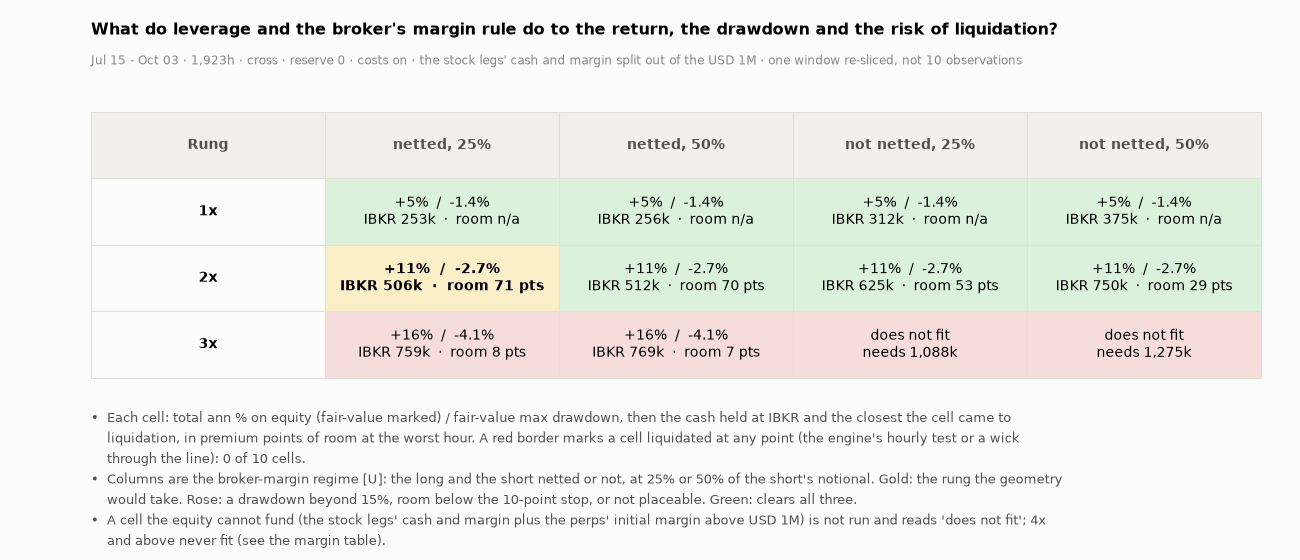

In [57]:
# ---- A: the grid, drawn (information; one window re-sliced, not 12 observations) ----
fig = plt.figure(figsize=(13, 5.6))
bm = figstyle.bullets(fig, [f"Each cell: total ann % on equity (fair-value marked) / fair-value max drawdown, then the cash held at IBKR and the closest the cell came to liquidation, in premium points of room at the worst hour. A red border marks a cell liquidated at any point (the engine's hourly test or a wick through the line): {ST6['grid']['liquidated_cells']} of {len(GRM)} cells.",
                            f"Columns are the broker-margin regime [U]: the long and the short netted or not, at 25% or 50% of the short's notional. Gold: the rung the geometry would take. Rose: a drawdown beyond {DD_LIMIT_PCT:.0f}%, room below the {STOP_PTS:.0f}-point stop, or not placeable. Green: clears all three.",
                            "A cell the equity cannot fund (the stock legs' cash and margin plus the perps' initial margin above USD 1M) is not run and reads 'does not fit'; 4x and above never fit (see the margin table)."])
gs = fig.add_gridspec(1, 1, left=0.07, right=0.97, top=0.80, bottom=bm + 0.03); axt = fig.add_subplot(gs[0]); axt.axis("off")
cells = [[f"{L}x"] + [(f"does not fit" + chr(10) + f"needs {NOFIT[(L, nm_)] / 1e3:,.0f}k") if (L, nm_) in NOFIT else
                      (f"{eq_ann(GRM[(L, nm_)]):+.0f}%  /  {fvdd(GRM[(L, nm_)]):.1f}%" + chr(10) + f"IBKR {IBC[(L, nm_)] / 1e3:,.0f}k  ·  " + ("LIQUIDATED" if LIQM[(L, nm_)] else ("room n/a" if WRM[(L, nm_)] is None else f"room {WRM[(L, nm_)]:.0f} pts"))) for nm_, _n, _f in REGS] for L in LEVS]
tb = axt.table(cellText=cells, colLabels=["Rung"] + [nm_ for nm_, _n, _f in REGS], cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.auto_set_font_size(False); tb.set_fontsize(10); figstyle.style_table(tb)
for i_, L in enumerate(LEVS, 1):
    tb[(i_, 0)].set_text_props(weight="bold")
    for j_, (nm_, _n, _f) in enumerate(REGS, 1):
        if (L, nm_) in NOFIT:
            tint(tb, i_, j_, "rose"); continue
        r_ = GRM[(L, nm_)]
        bad = (fvdd(r_) <= -DD_LIMIT_PCT) or (not r_["venue_feasible"]["book_feasible"]) or (WRM[(L, nm_)] is not None and WRM[(L, nm_)] < STOP_PTS)
        tint(tb, i_, j_, "rose" if bad else "green")
        if L == SHOWN and nm_ == REGS[0][0]: gold(tb, i_, j_)
        if LIQM[(L, nm_)]:
            tb[(i_, j_)].set_edgecolor(CRIT); tb[(i_, j_)].set_linewidth(3.2); tb[(i_, j_)].set_zorder(6); tb[(i_, j_)].set_text_props(color=CRIT, weight="bold")
fig.suptitle("What do leverage and the broker's margin rule do to the return, the drawdown and the risk of liquidation?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.96)
fig.text(0.07, 0.885, f"{WSB} · the stock legs' cash and margin split out of the {usdm(EQUITY)} · one window re-sliced, not {len(GRM)} observations", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-grid", []); assert any(f["id"] == "fig:s6-grid" for f in FIGURES)

## Research summary

The card the Research room will show, as a separate part at the bottom: the question, the answer, the numbers that matter.

In [58]:
# ---- the research summary: the card was built in S7 and rides in the manifest's summary; this is the same card, drawn ----
display(HTML(summary_card.render(CARD)))

Leverage,Return,Max DD,Liq buffer,Verdict
1x,+5.3%,-1.4%,none,INFO
2x,+10.6%,-2.7%,70.6 pts,INFO
3x,+15.8%,-4.1%,8.2 pts,FAIL
